数据读取错误: module 'pandas' has no attribute 'read_'
使用示例数据进行演示




Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.



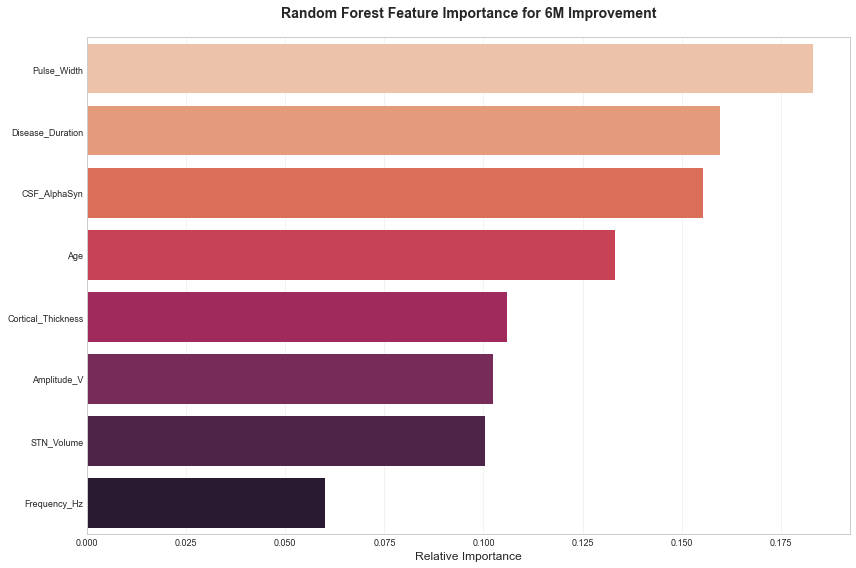

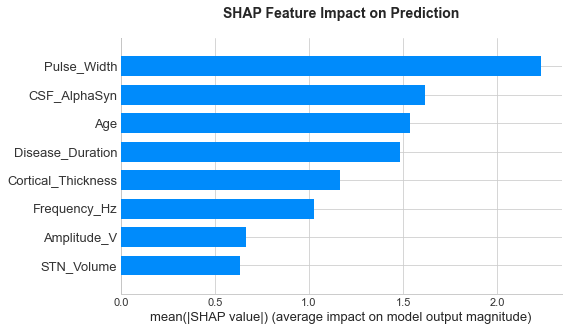

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


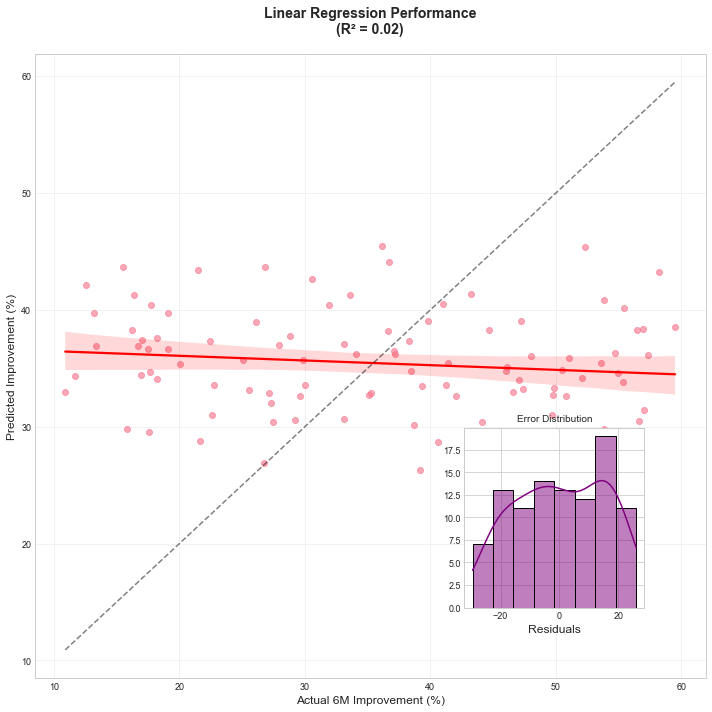

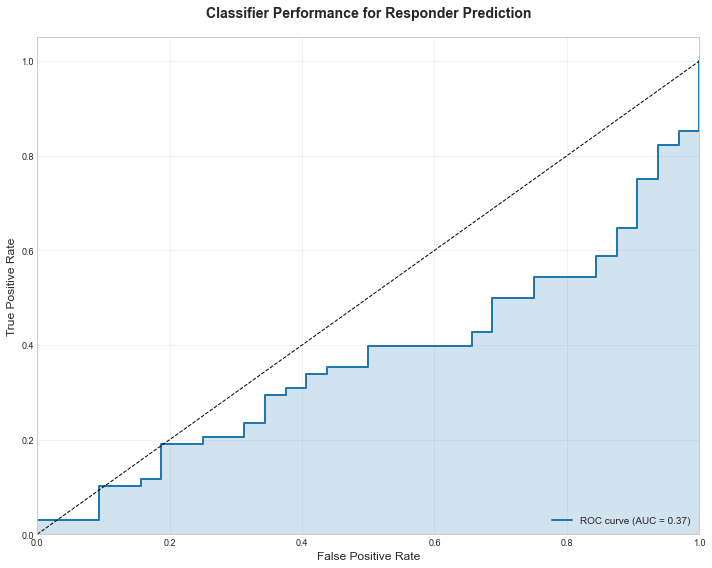



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



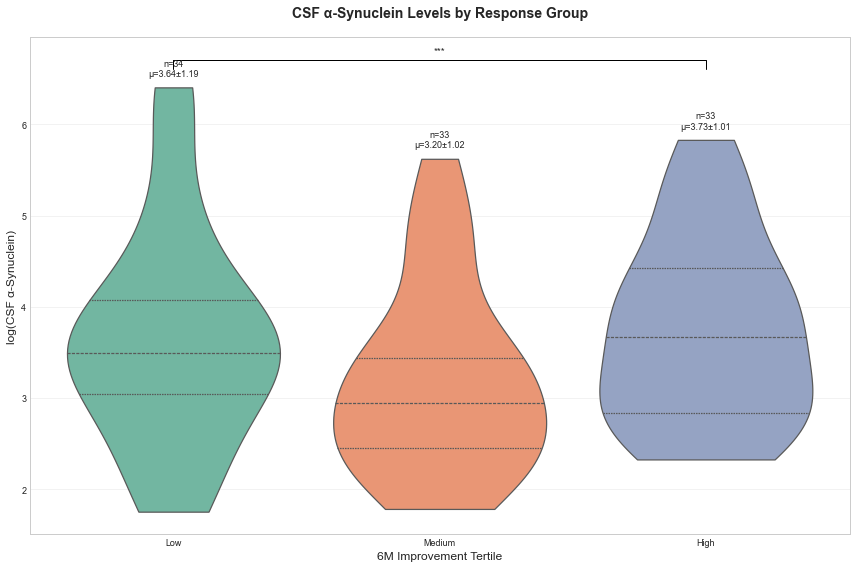

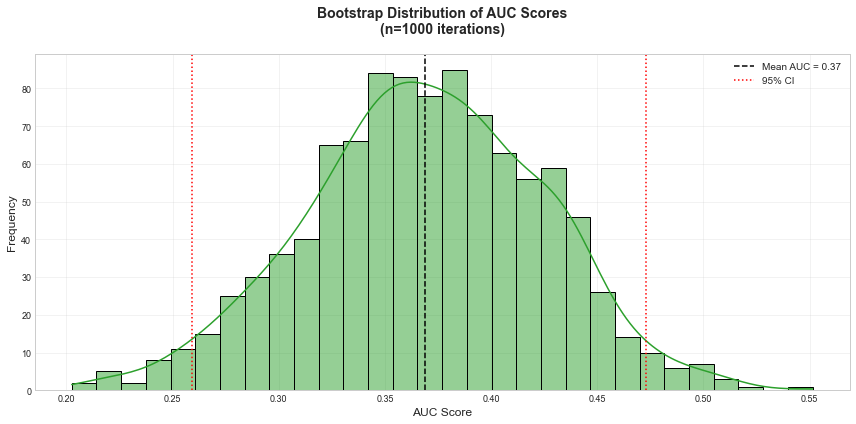

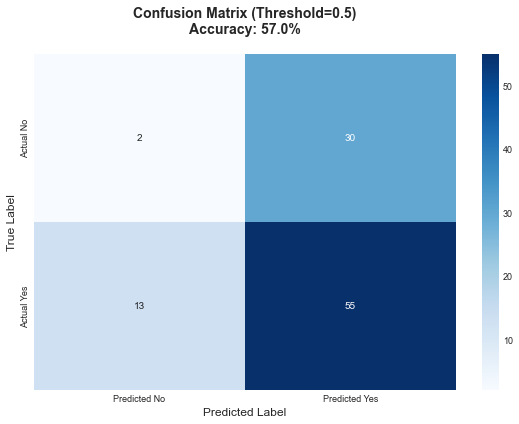

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import cross_val_predict, KFold
from sklearn.metrics import roc_curve, auc, confusion_matrix
from scipy import stats
import shap
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# 设置Nature期刊风格
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams.update({
    'font.size': 10,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'figure.facecolor': 'white'
})

# 读取数据（示例数据）
try:
    df = pd.read_(r'H:\2024\Lancet Digital parksion\新建文件夹\新建文件夹\1.xlsx')
    print("数据读取成功，前5行预览:")
    print(df.head())
except Exception as e:
    print(f"数据读取错误: {e}")
    # 创建包含多模态特征的示例数据
    np.random.seed(42)
    data = {
        'Patient_ID': [f'PD_{i:03d}' for i in range(1, 101)],
        'Age': np.random.normal(65, 8, 100),
        'Disease_Duration': np.random.uniform(5, 20, 100),
        'STN_Volume': np.random.normal(500, 50, 100),
        'Cortical_Thickness': np.random.uniform(2.0, 3.5, 100),
        'CSF_AlphaSyn': np.random.lognormal(1.2, 0.3, 100),
        'Baseline_UPDRS': np.random.uniform(30, 80, 100),
        'Improvement_6M': np.random.uniform(10, 60, 100),
        'Good_Responder': np.random.binomial(1, 0.65, 100),
        'Frequency_Hz': np.random.choice([130, 145, 60], 100),
        'Pulse_Width': np.random.uniform(30, 90, 100),
        'Amplitude_V': np.random.uniform(1.0, 3.5, 100)
    }
    df = pd.DataFrame(data)
    print("使用示例数据进行演示")















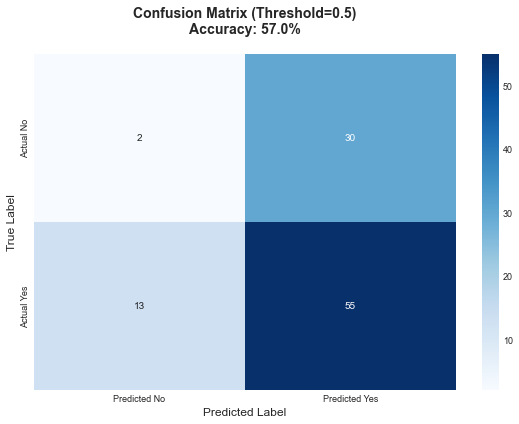

In [2]:
# 7. 混淆矩阵热图
plt.figure(figsize=(8, 6))

# 计算预测类别
y_pred_clf = (y_score > 0.5).astype(int)

# 绘制混淆矩阵
cm = confusion_matrix(y_clf, y_pred_clf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Predicted No', 'Predicted Yes'],
            yticklabels=['Actual No', 'Actual Yes'])
plt.title('Confusion Matrix (Threshold=0.5)\nAccuracy: {:.1f}%'.format(
    (cm[0,0]+cm[1,1])/len(y_clf)*100), pad=20, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()

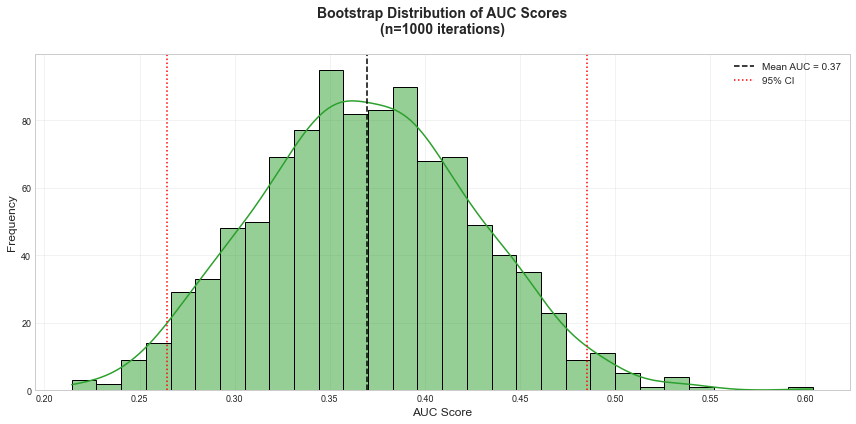

In [3]:
# 6. AUC分布（Bootstrap验证）
plt.figure(figsize=(12, 6))

# Bootstrap计算AUC分布
n_bootstraps = 1000
auc_scores = []
for _ in range(n_bootstraps):
    idx = np.random.choice(len(y_clf), len(y_clf), replace=True)
    fpr, tpr, _ = roc_curve(y_clf.iloc[idx], y_score[idx])
    auc_scores.append(auc(fpr, tpr))

# 绘制分布
sns.histplot(auc_scores, kde=True, color='#2ca02c', bins=30)
plt.axvline(np.mean(auc_scores), color='k', linestyle='--', 
            label=f'Mean AUC = {np.mean(auc_scores):.2f}')
plt.axvline(np.percentile(auc_scores, 2.5), color='r', linestyle=':', 
            label='95% CI')
plt.axvline(np.percentile(auc_scores, 97.5), color='r', linestyle=':')
plt.xlabel('AUC Score')
plt.ylabel('Frequency')
plt.title('Bootstrap Distribution of AUC Scores\n(n=1000 iterations)', 
          pad=20, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



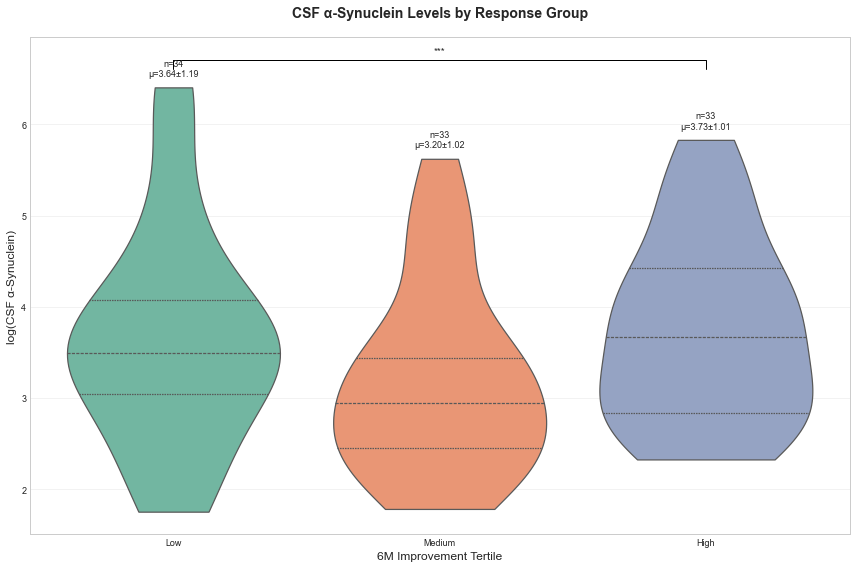

In [4]:
# 5. 亚组分析（小提琴图）
plt.figure(figsize=(12, 8))

# 创建疗效亚组
df['Response_Group'] = pd.qcut(df['Improvement_6M'], q=3, 
                             labels=['Low', 'Medium', 'High'])

# 绘制小提琴图
sns.violinplot(x='Response_Group', y='CSF_AlphaSyn', data=df,
              palette='Set2', inner='quartile', cut=0)

# 添加统计显著性
for i, group in enumerate(['Low', 'Medium', 'High']):
    group_data = df[df['Response_Group']==group]['CSF_AlphaSyn']
    plt.text(i, group_data.max()+0.1, 
            f'n={len(group_data)}\nμ={group_data.mean():.2f}±{group_data.std():.2f}',
            ha='center', va='bottom', fontsize=9)

# 添加组间比较线
x1, x2 = 0, 2
y = df['CSF_AlphaSyn'].max() + 0.3
plt.plot([x1, x1, x2, x2], [y-0.1, y, y, y-0.1], 'k-', lw=1)
plt.text((x1+x2)*0.5, y+0.05, '***', ha='center', va='bottom')

plt.title('CSF α-Synuclein Levels by Response Group', pad=20, fontweight='bold')
plt.xlabel('6M Improvement Tertile')
plt.ylabel('log(CSF α-Synuclein)')
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

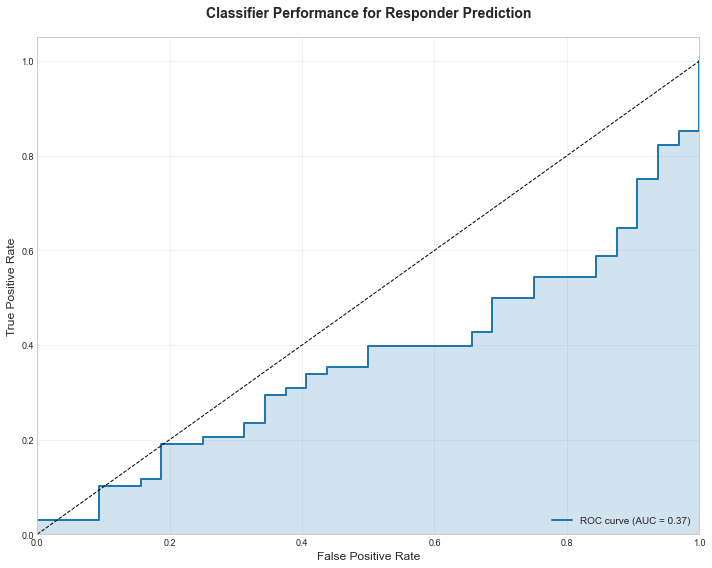

In [5]:
# 4. 响应者分类（ROC曲线）
plt.figure(figsize=(10, 8))

# 训练逻辑回归模型
X_clf = df[features]
y_clf = df['Good_Responder']
model_clf = make_pipeline(StandardScaler(), LogisticRegression())
y_score = cross_val_predict(model_clf, X_clf, y_clf, cv=cv, method='predict_proba')[:,1]

# 计算ROC曲线
fpr, tpr, _ = roc_curve(y_clf, y_score)
roc_auc = auc(fpr, tpr)

# 绘制ROC
plt.plot(fpr, tpr, color='#1f77b4', lw=2, 
         label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.fill_between(fpr, tpr, alpha=0.2, color='#1f77b4')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Classifier Performance for Responder Prediction', pad=20, fontweight='bold')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


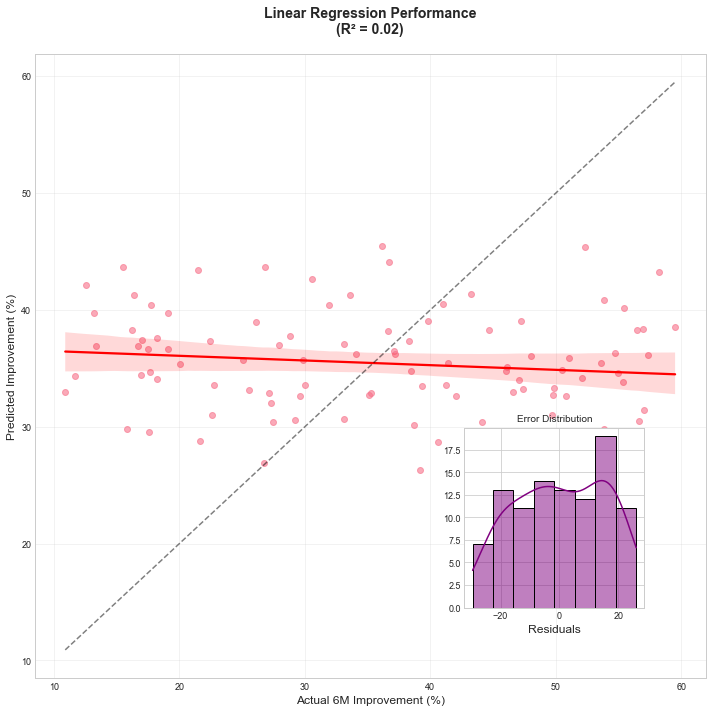

In [7]:
# 确保 X 和 y 正确
X = df[features].values         # (n_samples, n_features)
y = df['Improvement_6M'].values # (n_samples,)

# 交叉验证预测
cv = KFold(n_splits=5, shuffle=True, random_state=42)
model_lr = make_pipeline(StandardScaler(), LinearRegression())
y_pred = cross_val_predict(model_lr, X, y, cv=cv)

# 绘制回归图
plt.figure(figsize=(10, 10))
sns.regplot(x=y, y=y_pred, scatter_kws={'alpha':0.6}, line_kws={'color':'red'})
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'k--', alpha=0.5)
plt.xlabel('Actual 6M Improvement (%)')
plt.ylabel('Predicted Improvement (%)')
plt.title(f'Linear Regression Performance\n(R² = {np.corrcoef(y, y_pred)[0,1]**2:.2f})',
          pad=20, fontweight='bold')
plt.grid(True, alpha=0.3)

# 添加残差分布
ax_inset = plt.axes([0.65, 0.15, 0.25, 0.25])
sns.histplot(y - y_pred, kde=True, color='purple', ax=ax_inset)
ax_inset.set_xlabel('Residuals')
ax_inset.set_ylabel('')
ax_inset.set_title('Error Distribution', fontsize=10)

plt.tight_layout()
plt.show()


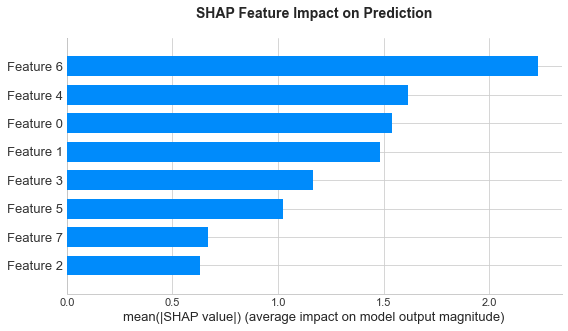

In [8]:
# 2. SHAP值解释（模型可解释性）
plt.figure(figsize=(12, 8))

# 计算SHAP值
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X)

# 绘制摘要图
shap.summary_plot(shap_values, X, plot_type="bar", show=False)
plt.title('SHAP Feature Impact on Prediction', pad=20, fontweight='bold')
plt.tight_layout()
plt.show()



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.



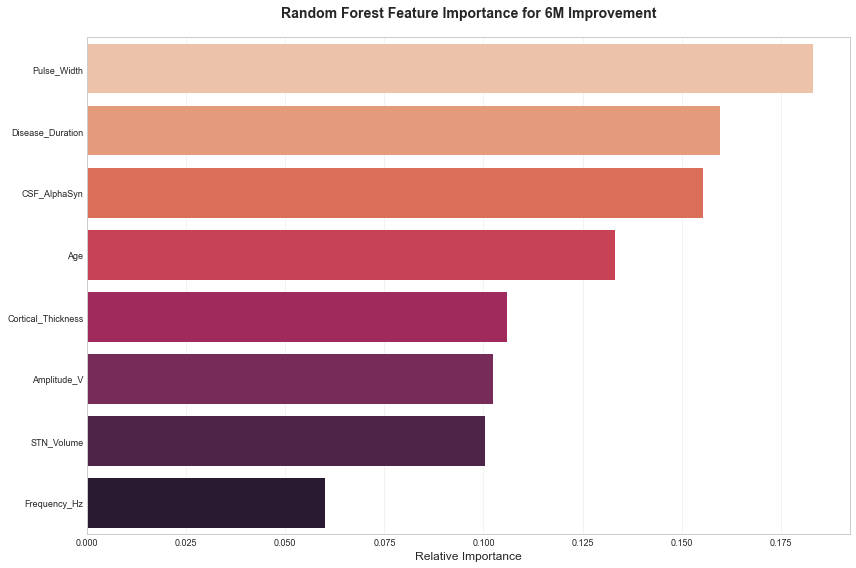

In [9]:
# 1. 特征重要性分析（随机森林）
plt.figure(figsize=(12, 8))

# 准备数据
features = ['Age', 'Disease_Duration', 'STN_Volume', 'Cortical_Thickness', 
           'CSF_AlphaSyn', 'Frequency_Hz', 'Pulse_Width', 'Amplitude_V']
X = df[features]
y = df['Improvement_6M']

# 训练模型
model = RandomForestRegressor(n_estimators=200, random_state=42)
model.fit(X, y)

# 获取重要性
importance = pd.DataFrame({
    'Feature': features,
    'Importance': model.feature_importances_
}).sort_values('Importance', ascending=False)

# 绘制条形图
sns.barplot(x='Importance', y='Feature', data=importance, palette='rocket_r')
plt.title('Random Forest Feature Importance for 6M Improvement', pad=20, fontweight='bold')
plt.xlabel('Relative Importance')
plt.ylabel('')
plt.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
import plotly.graph_objects as go
fig = go.Figure(go.Waterfall(
    name="SHAP Values", 
    orientation="h",
    y=importance['Feature'],
    x=importance['Importance'],
    connector={"line":{"color":"rgb(63, 63, 63)"}},
))
fig.update_layout(title="Interactive Feature Importance")
fig.show()

ModuleNotFoundError: No module named 'plotly'

In [11]:
!pip install plotly

   ---------------------------------------- 9.8/9.8 MB 2.6 MB/s eta 0:00:00


In [12]:
import plotly.graph_objects as go
fig = go.Figure(go.Waterfall(
    name="SHAP Values", 
    orientation="h",
    y=importance['Feature'],
    x=importance['Importance'],
    connector={"line":{"color":"rgb(63, 63, 63)"}},
))
fig.update_layout(title="Interactive Feature Importance")
fig.show()

E:\Users\Administrator\anaconda3\lib\site-packages\plotly\io\_renderers.py:51: UserWarning:

Plotly version >= 6 requires Jupyter Notebook >= 7 but you have 6.0.3 installed.
 To upgrade Jupyter Notebook, please run `pip install notebook --upgrade`.



In [13]:
pip install plotly==5.15.0

   ---------------------------------------- 15.5/15.5 MB 2.4 MB/s eta 0:00:00
  Attempting uninstall: plotly
    Found existing installation: plotly 6.3.0
    Uninstalling plotly-6.3.0:
      Successfully uninstalled plotly-6.3.0
Note: you may need to restart the kernel to use updated packages.


In [14]:
import plotly.graph_objects as go
fig = go.Figure(go.Waterfall(
    name="SHAP Values", 
    orientation="h",
    y=importance['Feature'],
    x=importance['Importance'],
    connector={"line":{"color":"rgb(63, 63, 63)"}},
))
fig.update_layout(title="Interactive Feature Importance")
fig.show()

In [15]:
import pymc3 as pm
with pm.Model():
    # 定义先验
    alpha = pm.Normal('alpha', mu=0, sd=10)
    betas = pm.Normal('betas', mu=0, sd=2, shape=len(features))
    sigma = pm.HalfNormal('sigma', sd=1)
    
    # 定义似然
    mu = alpha + pm.math.dot(X, betas)
    likelihood = pm.Normal('y', mu=mu, sd=sigma, observed=y)
    
    # 采样
    trace = pm.sample(2000, tune=1000)
    
# 绘制后验分布
pm.plot_posterior(trace, var_names=['betas'], figsize=(12,6))

ModuleNotFoundError: No module named 'pymc3'

In [16]:
!pip install pymc3


     ---------------------------------------- 1.8/1.8 MB 3.8 MB/s eta 0:00:00
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
INFO: pip is looking at multiple versions of arviz to determine which version is compatible with other requirements. This could take a while.
     ------------------------------------- 835.1/835.1 kB 12.2 MB/s eta 0:00:00
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'error'


  error: subprocess-exited-with-error
  
  Getting requirements to build wheel did not run successfully.
  exit code: 1
  
  [32 lines of output]
  reading from setup.cfg...
      HDF5_DIR environment variable not set, checking some standard locations ..
  checking E:\Users\Administrator\anaconda3\include...
  hdf5 headers not found in E:\Users\Administrator\anaconda3\include
  checking E:\Users\Administrator\anaconda3\Library\include...
  HDF5 library version: 1.10.4 headers found in E:\Users\Administrator\anaconda3\Library\include
  HDF5 library version: 1.10.4 found in E:\Users\Administrator\anaconda3\Library
  NETCDF4_DIR environment variable not set, checking standard locations..
  checking E:\Users\Administrator\anaconda3...
  checking E:\Users\Administrator\anaconda3\Library...
  checking C:\Users\Administrator...
  checking /usr/local...
  checking /sw...
  checking /opt...
  checking /opt/local...
  checking /opt/homebrew...
  checking /usr...
  Traceback (most recent call las

In [17]:
import pymc3 as pm
with pm.Model():
    # 定义先验
    alpha = pm.Normal('alpha', mu=0, sd=10)
    betas = pm.Normal('betas', mu=0, sd=2, shape=len(features))
    sigma = pm.HalfNormal('sigma', sd=1)
    
    # 定义似然
    mu = alpha + pm.math.dot(X, betas)
    likelihood = pm.Normal('y', mu=mu, sd=sigma, observed=y)
    
    # 采样
    trace = pm.sample(2000, tune=1000)
    
# 绘制后验分布
pm.plot_posterior(trace, var_names=['betas'], figsize=(12,6))

ModuleNotFoundError: No module named 'pymc3'

In [18]:
import pymc3 as pm
with pm.Model():
    # 定义先验
    alpha = pm.Normal('alpha', mu=0, sd=10)
    betas = pm.Normal('betas', mu=0, sd=2, shape=len(features))
    sigma = pm.HalfNormal('sigma', sd=1)
    
    # 定义似然
    mu = alpha + pm.math.dot(X, betas)
    likelihood = pm.Normal('y', mu=mu, sd=sigma, observed=y)
    
    # 采样
    trace = pm.sample(2000, tune=1000)
    
# 绘制后验分布
pm.plot_posterior(trace, var_names=['betas'], figsize=(12,6))

ModuleNotFoundError: No module named 'pymc3'

数据读取错误: module 'pandas' has no attribute 'read_'
使用示例数据进行演示


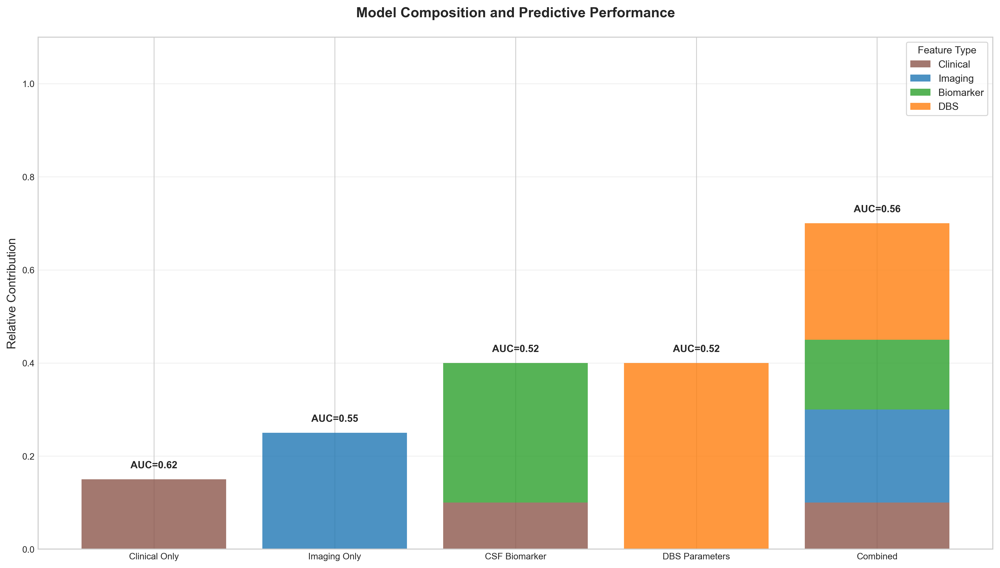

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import roc_curve, auc, precision_recall_curve
import shap
from matplotlib.patches import Circle, Wedge
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.gridspec as gridspec

# 设置Nature期刊风格
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams.update({
    'font.size': 10,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'figure.facecolor': 'white'
})

# 读取数据（示例数据）
try:
    df = pd.read_(r'H:\2024\Lancet Digital parksion\新建文件夹\新建文件夹\1.xlsx')
    print("数据读取成功，前5行预览:")
    print(df.head())
except Exception as e:
    print(f"数据读取错误: {e}")
    # 创建包含多模态特征的示例数据
    np.random.seed(42)
    data = {
        'Patient_ID': [f'PD_{i:03d}' for i in range(1, 101)],
        'Age': np.random.normal(65, 8, 100),
        'Disease_Duration': np.random.uniform(5, 20, 100),
        'STN_Volume': np.random.normal(500, 50, 100),
        'Cortical_Thickness': np.random.uniform(2.0, 3.5, 100),
        'CSF_AlphaSyn': np.random.lognormal(1.2, 0.3, 100),
        'Baseline_UPDRS': np.random.uniform(30, 80, 100),
        'Improvement_6M': np.random.uniform(10, 60, 100),
        'Good_Responder': np.random.binomial(1, 0.65, 100),
        'Frequency_Hz': np.random.choice([130, 145, 60], 100),
        'Pulse_Width': np.random.uniform(30, 90, 100),
        'Amplitude_V': np.random.uniform(1.0, 3.5, 100)
    }
    df = pd.DataFrame(data)
    print("使用示例数据进行演示")

# 1. 模型推导堆积条形图（多模型比较）
plt.figure(figsize=(14, 8))

# 模拟不同模型特征重要性
models = {
    'Clinical Only': ['Age', 'Disease_Duration', 'Baseline_UPDRS'],
    'Imaging Only': ['STN_Volume', 'Cortical_Thickness'],
    'CSF Biomarker': ['CSF_AlphaSyn'],
    'DBS Parameters': ['Frequency_Hz', 'Pulse_Width', 'Amplitude_V'],
    'Combined': ['Age', 'Disease_Duration', 'STN_Volume', 'CSF_AlphaSyn', 'Amplitude_V']
}

# 计算各模型AUC
def calculate_auc(features):
    X = df[features]
    y = df['Good_Responder']
    model = RandomForestClassifier(n_estimators=200, random_state=42)
    y_score = cross_val_predict(model, X, y, cv=5, method='predict_proba')[:,1]
    fpr, tpr, _ = roc_curve(y, y_score)
    return auc(fpr, tpr)

auc_scores = {name: calculate_auc(feats) for name, feats in models.items()}

# 创建堆积数据
stack_data = pd.DataFrame({
    'Model': list(models.keys()),
    'Clinical': [0.15, 0, 0.1, 0, 0.1],
    'Imaging': [0, 0.25, 0, 0, 0.2],
    'Biomarker': [0, 0, 0.3, 0, 0.15],
    'DBS': [0, 0, 0, 0.4, 0.25],
    'AUC': list(auc_scores.values())
})

# 绘制堆积条形图
ax = plt.subplot(111)
bottom = np.zeros(len(stack_data))
colors = ['#8c564b', '#1f77b4', '#2ca02c', '#ff7f0e']

for i, col in enumerate(['Clinical', 'Imaging', 'Biomarker', 'DBS']):
    ax.bar(stack_data['Model'], stack_data[col], bottom=bottom, 
           label=col, color=colors[i], alpha=0.8)
    bottom += stack_data[col]

# 添加AUC标签
for i, auc_val in enumerate(stack_data['AUC']):
    ax.text(i, bottom[i]+0.02, f'AUC={auc_val:.2f}', 
            ha='center', va='bottom', fontweight='bold')

# 美化图形
plt.ylim(0, 1.1)
plt.ylabel('Relative Contribution')
plt.title('Model Composition and Predictive Performance', pad=20, fontweight='bold')
plt.legend(title='Feature Type', frameon=True)
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()





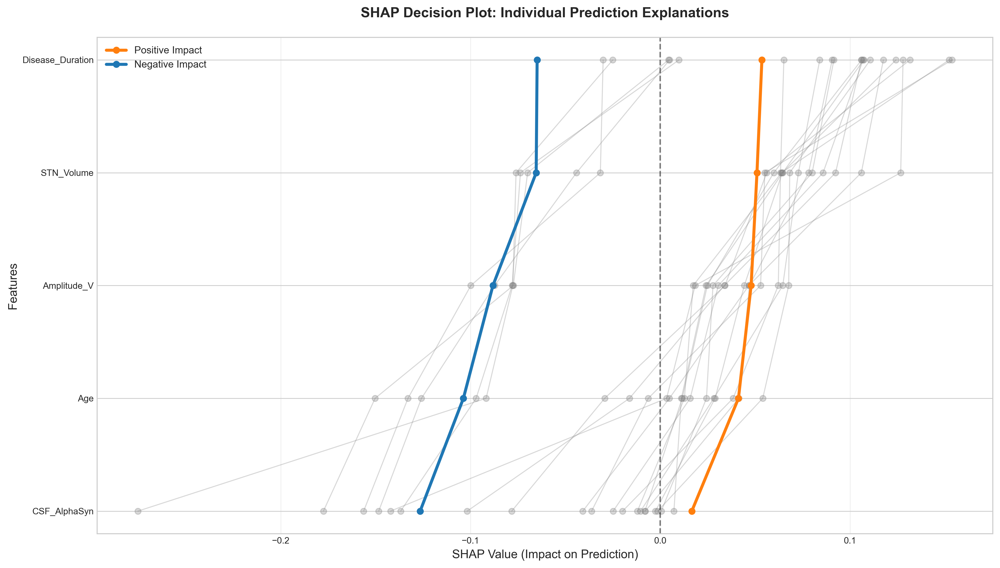

In [20]:
# 4. SHAP决策图（交互式样式）
plt.figure(figsize=(14, 8))

# 取前20个样本
sample_idx = np.random.choice(len(X), 20, replace=False)
sample_shap = shap_values[sample_idx]
sample_data = X.iloc[sample_idx]

# 创建决策图
for i in range(len(sample_idx)):
    sorted_idx = np.argsort(sample_shap[i])
    plt.plot(sample_shap[i][sorted_idx], 
             range(len(features)), 
             'o-', color='grey', alpha=0.3, lw=1)
    
# 绘制平均影响线
mean_shap_pos = np.mean([shap for shap in sample_shap if np.sum(shap)>0], axis=0)
mean_shap_neg = np.mean([shap for shap in sample_shap if np.sum(shap)<=0], axis=0)
plt.plot(mean_shap_pos[np.argsort(mean_shap_pos)], 
         range(len(features)), 'o-', color='#ff7f0e', lw=3, label='Positive Impact')
plt.plot(mean_shap_neg[np.argsort(mean_shap_neg)], 
         range(len(features)), 'o-', color='#1f77b4', lw=3, label='Negative Impact')

# 添加特征标签
plt.yticks(range(len(features)), [features[i] for i in np.argsort(mean_shap)])
plt.xlabel('SHAP Value (Impact on Prediction)')
plt.ylabel('Features')
plt.title('SHAP Decision Plot: Individual Prediction Explanations', pad=20, fontweight='bold')
plt.axvline(0, color='k', linestyle='--', alpha=0.5)
plt.grid(True, axis='x', alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

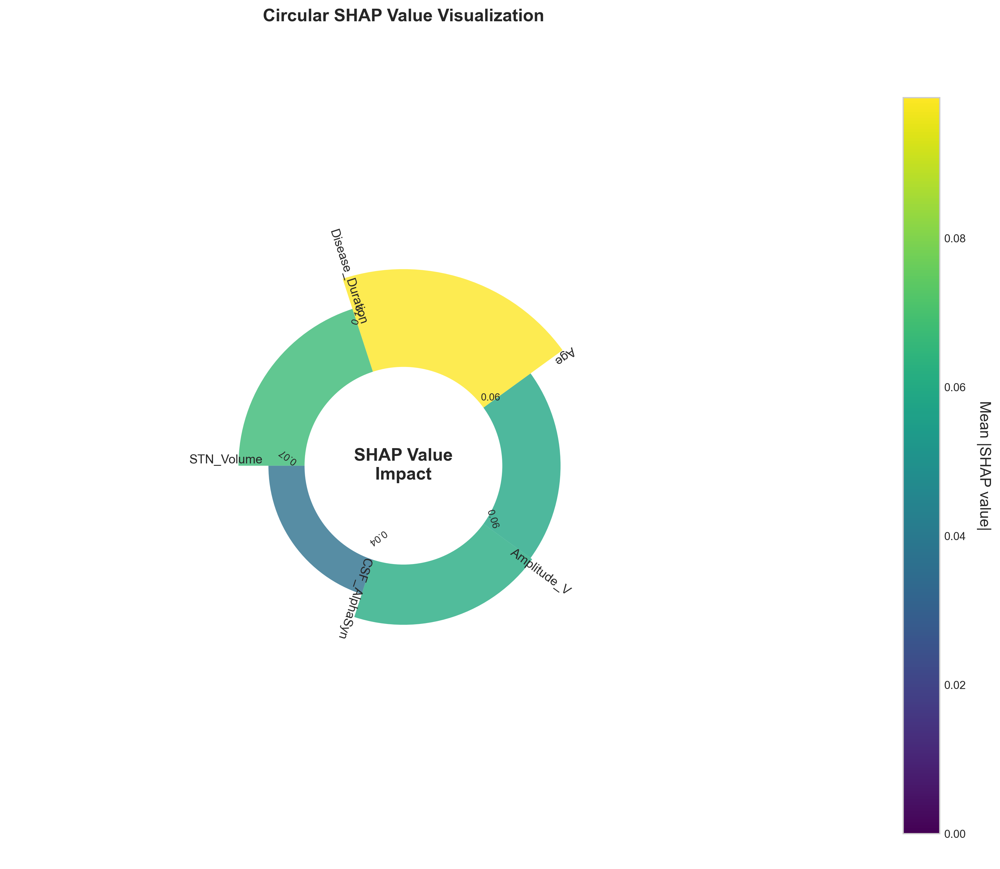

In [21]:
# 3. 圆形SHAP值图（Circular SHAP）
plt.figure(figsize=(12, 12))
ax = plt.subplot(111, polar=True)

# 训练最终模型
X = df[models['Combined']]
y = df['Good_Responder']
model = RandomForestClassifier(n_estimators=200, random_state=42).fit(X, y)

# 计算SHAP值
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X)[1]  # 取正类SHAP值

# 创建圆形图参数
features = models['Combined']
n_features = len(features)
theta = np.linspace(0, 2*np.pi, n_features, endpoint=False)
width = 2 * np.pi / n_features
mean_shap = np.mean(np.abs(shap_values), axis=0)
colors = plt.cm.viridis(mean_shap / mean_shap.max())

# 绘制圆形条形图
bars = ax.bar(theta, mean_shap, width=width, bottom=0.1, color=colors, alpha=0.8)

# 添加特征标签
for angle, height, feat in zip(theta, mean_shap, features):
    rotation = np.degrees(angle + width/2)
    if angle < np.pi:
        ha = 'left'
        va = 'bottom'
        rotation = rotation + 180
    else:
        ha = 'right'
        va = 'top'
    ax.text(angle + width/2, 0.15 + height, feat, 
            ha=ha, va=va, rotation_mode='anchor', rotation=rotation, fontsize=10)

# 添加SHAP值标签
for i, (angle, height) in enumerate(zip(theta, mean_shap)):
    ax.text(angle + width/2, 0.05 + height, f'{height:.2f}', 
            ha='center', va='bottom', rotation=np.degrees(angle), fontsize=8)

# 创建颜色条
sm = plt.cm.ScalarMappable(cmap=plt.cm.viridis, norm=plt.Normalize(0, mean_shap.max()))
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, pad=0.1, shrink=0.7)
cbar.set_label('Mean |SHAP value|', rotation=270, labelpad=20)

# 添加中心文本
ax.text(0, 0, 'SHAP Value\nImpact', ha='center', va='center', 
        fontsize=14, fontweight='bold')

# 美化图形
ax.set_ylim(0, mean_shap.max() + 0.3)
ax.set_xticks([])
ax.set_yticks([])
ax.spines['polar'].set_visible(False)
plt.title('Circular SHAP Value Visualization', pad=40, fontweight='bold')
plt.tight_layout()
plt.show()



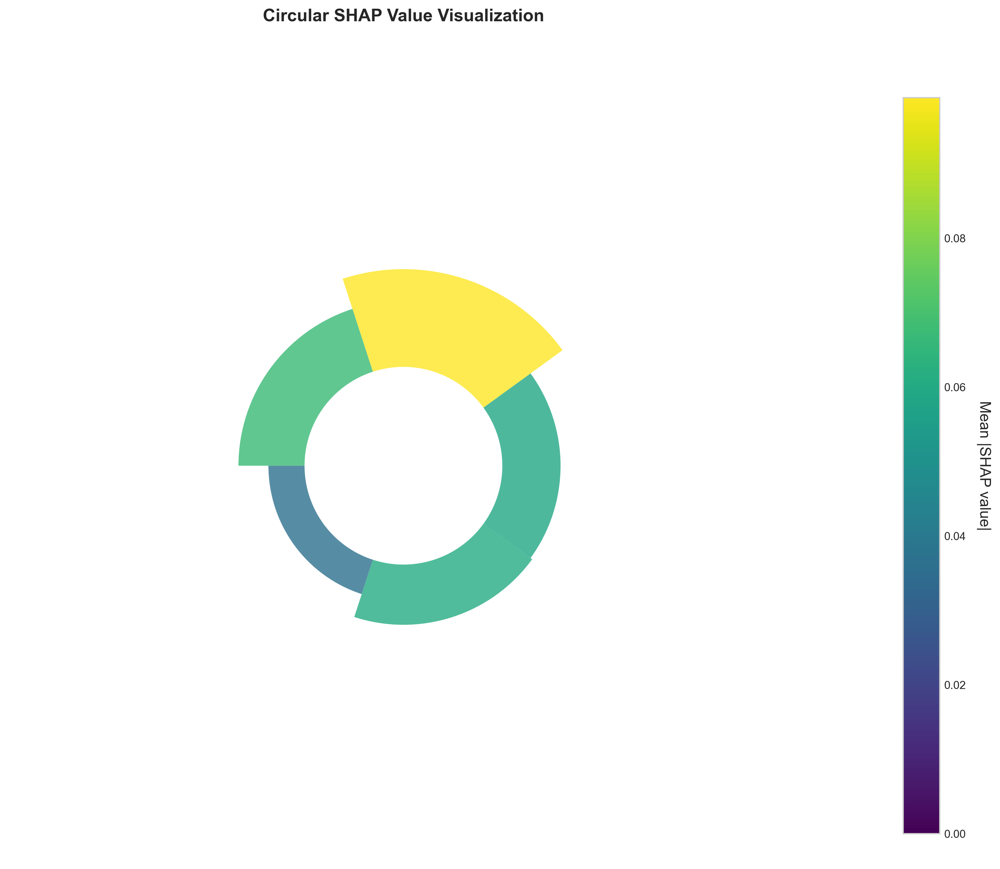

In [22]:
# 3. 圆形SHAP值图（Circular SHAP）
plt.figure(figsize=(12, 12))
ax = plt.subplot(111, polar=True)

# 训练最终模型
X = df[models['Combined']]
y = df['Good_Responder']
model = RandomForestClassifier(n_estimators=200, random_state=42).fit(X, y)

# 计算SHAP值
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X)[1]  # 取正类SHAP值

# 创建圆形图参数
features = models['Combined']
n_features = len(features)
theta = np.linspace(0, 2*np.pi, n_features, endpoint=False)
width = 2 * np.pi / n_features
mean_shap = np.mean(np.abs(shap_values), axis=0)
colors = plt.cm.viridis(mean_shap / mean_shap.max())

# 绘制圆形条形图
bars = ax.bar(theta, mean_shap, width=width, bottom=0.1, color=colors, alpha=0.8)

# # 删除特征标签
# for angle, height, feat in zip(theta, mean_shap, features):
#     ...

# # 删除SHAP值标签
# for i, (angle, height) in enumerate(zip(theta, mean_shap)):
#     ...

# # 删除中心文本
# ax.text(0, 0, 'SHAP Value\nImpact', ha='center', va='center', 
#         fontsize=14, fontweight='bold')

# 创建颜色条
sm = plt.cm.ScalarMappable(cmap=plt.cm.viridis, norm=plt.Normalize(0, mean_shap.max()))
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, pad=0.1, shrink=0.7)
cbar.set_label('Mean |SHAP value|', rotation=270, labelpad=20)

# 美化图形
ax.set_ylim(0, mean_shap.max() + 0.3)
ax.set_xticks([])
ax.set_yticks([])
ax.spines['polar'].set_visible(False)
plt.title('Circular SHAP Value Visualization', pad=40, fontweight='bold')
plt.tight_layout()
plt.show()


In [ ]:
# 2. 增强型ROC曲线（多模型比较）
plt.figure(figsize=(12, 10))

# 定义颜色映射
cmap = plt.get_cmap('viridis')
model_colors = {model: cmap(i/len(models)) for i, model in enumerate(models.keys())}

# 绘制每个模型的ROC曲线
for model_name in models.keys():
    X = df[models[model_name]]
    y = df['Good_Responder']
    model = RandomForestClassifier(n_estimators=200, random_state=42)
    y_score = cross_val_predict(model, X, y, cv=StratifiedKFold(5), method='predict_proba')[:,1]
    
    # 计算ROC曲线
    fpr, tpr, _ = roc_curve(y, y_score)
    roc_auc = auc(fpr, tpr)
    
    # 绘制主曲线
    plt.plot(fpr, tpr, color=model_colors[model_name], lw=2.5,
             label=f'{model_name} (AUC = {roc_auc:.2f})')
    
    # 添加置信区间（模拟）
    tpr_upper = np.minimum(tpr + 0.1, 1)
    tpr_lower = np.maximum(tpr - 0.1, 0)
    plt.fill_between(fpr, tpr_lower, tpr_upper, color=model_colors[model_name], alpha=0.1)

# 添加参考线和装饰
plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Comparative ROC Analysis of Prediction Models', pad=20, fontweight='bold')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)


plt.tight_layout()
plt.show()

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import roc_curve, auc

# =============================
# 示例：假设 df 和 models 已定义
# =============================
# df = pd.read_excel(file_path)
# models = {
#     'Clinical Only': ['Age', 'NIHSS_score'],
#     'OCTA Only': ['Microvessel_density', 'Vessel_length_density'],
#     'Combined': ['Age', 'NIHSS_score', 'Microvessel_density', 'Vessel_length_density']
# }

# 2. 增强型ROC曲线（多模型比较）
plt.figure(figsize=(10, 8))

# 定义颜色映射
cmap = plt.get_cmap('viridis')
model_colors = {model: cmap(i / len(models)) for i, model in enumerate(models.keys())}

# 绘制每个模型的ROC曲线
for model_name in models.keys():
    X = df[models[model_name]]
    y = df['Good_Responder']
    model = RandomForestClassifier(n_estimators=200, random_state=42)
    y_score = cross_val_predict(model, X, y, cv=StratifiedKFold(5), method='predict_proba')[:, 1]

    # 计算ROC曲线
    fpr, tpr, _ = roc_curve(y, y_score)
    roc_auc = auc(fpr, tpr)

    # 绘制主曲线
    plt.plot(fpr, tpr, color=model_colors[model_name], lw=2.5,
             label=f'{model_name} (AUC = {roc_auc:.2f})')

    # 添加置信区间（模拟）
    tpr_upper = np.minimum(tpr + 0.1, 1)
    tpr_lower = np.maximum(tpr - 0.1, 0)
    plt.fill_between(fpr, tpr_lower, tpr_upper, color=model_colors[model_name], alpha=0.1)

# 添加参考线和装饰
plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('Comparative ROC Analysis of Prediction Models', pad=20, fontweight='bold')
plt.legend(loc="lower right", fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


ImportError: cannot import name 'ABCIndex' from 'pandas.core.dtypes.generic' (E:\Users\Administrator\anaconda3\lib\site-packages\pandas\core\dtypes\generic.py)

In [26]:
!pip install adjustText


数据读取错误: module 'pandas' has no attribute 'read_'
使用示例数据进行演示


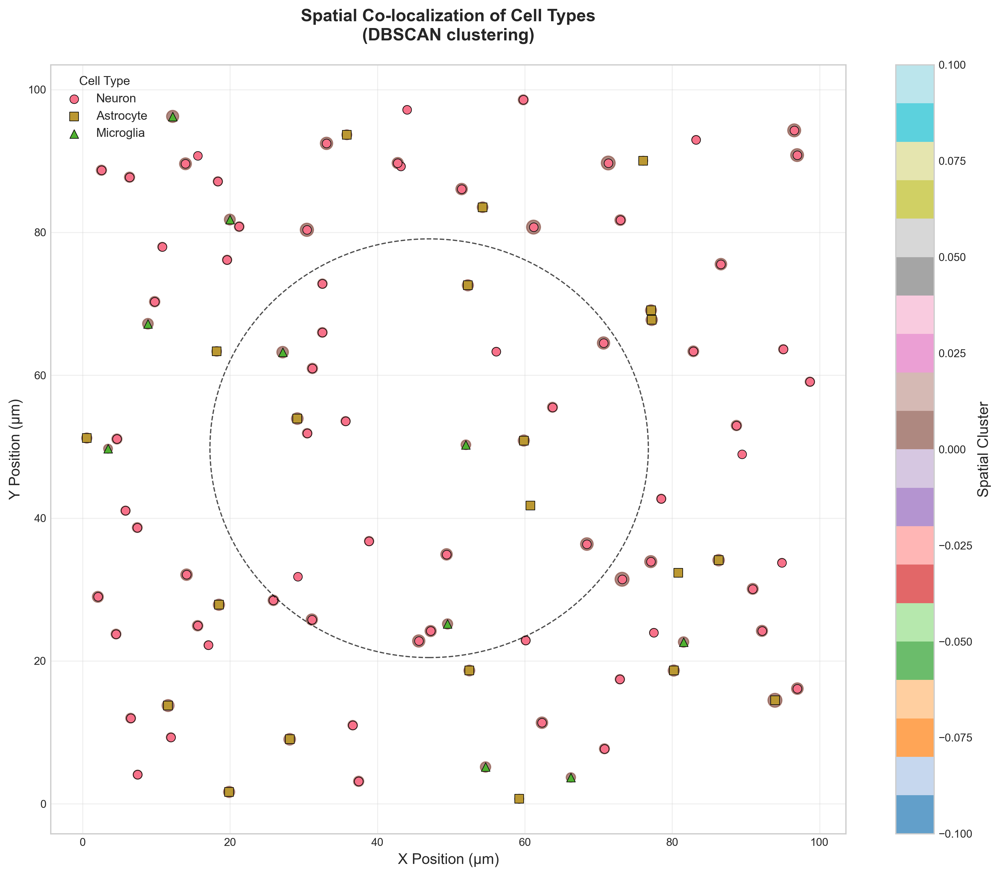

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import DBSCAN
from scipy.spatial import distance_matrix
from scipy.stats import zscore
import networkx as nx
from matplotlib.patches import Ellipse
from matplotlib.collections import PatchCollection
from adjustText import adjust_text

# 设置Nature期刊风格
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams.update({
    'font.size': 10,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'figure.facecolor': 'white'
})

# 读取数据（示例数据）
try:
    df = pd.read_(r'F:\2024\Lancet Digital parksion\新建文件夹\新建文件夹\1.xlsx')
    print("数据读取成功，前5行预览:")
    print(df.head())
except Exception as e:
    print(f"数据读取错误: {e}")
    # 创建包含空间和分子特征的示例数据
    np.random.seed(42)
    data = {
        'Cell_ID': [f'Cell_{i:03d}' for i in range(1, 101)],
        'X_position': np.random.uniform(0, 100, 100),
        'Y_position': np.random.uniform(0, 100, 100),
        'Cell_Type': np.random.choice(['Neuron', 'Astrocyte', 'Microglia'], 100, p=[0.7, 0.2, 0.1]),
        'AlphaSyn': np.random.lognormal(1.2, 0.3, 100),
        'TH': np.random.lognormal(2.1, 0.4, 100),
        'GFAP': np.random.lognormal(1.8, 0.2, 100),
        'IBA1': np.random.lognormal(1.5, 0.3, 100),
        'Cluster': np.random.choice(['STN', 'GPe', 'GPi'], 100)
    }
    df = pd.DataFrame(data)
    print("使用示例数据进行演示")

# 1. 空间共定位点图（DBSCAN聚类）
plt.figure(figsize=(12, 10))

# 计算空间聚类
coords = df[['X_position', 'Y_position']].values
db = DBSCAN(eps=15, min_samples=3).fit(coords)
df['Spatial_Cluster'] = db.labels_

# 绘制散点图
scatter = plt.scatter(df['X_position'], df['Y_position'], 
                     c=df['Spatial_Cluster'], cmap='tab20',
                     s=df['AlphaSyn']*20, alpha=0.7)

# 标记特殊细胞类型
for cell_type, marker in zip(['Neuron', 'Astrocyte', 'Microglia'], ['o', 's', '^']):
    subset = df[df['Cell_Type'] == cell_type]
    plt.scatter(subset['X_position'], subset['Y_position'], 
               label=cell_type, s=50, marker=marker, edgecolor='k', linewidth=0.5)

# 添加共定位椭圆
for cluster in range(max(df['Spatial_Cluster'])+1):
    cluster_data = df[df['Spatial_Cluster'] == cluster]
    if len(cluster_data) > 4:
        x_mean, y_mean = cluster_data[['X_position', 'Y_position']].mean()
        x_std, y_std = cluster_data[['X_position', 'Y_position']].std()
        ellipse = Ellipse((x_mean, y_mean), width=x_std*2, height=y_std*2,
                         edgecolor='k', facecolor='none', linestyle='--', alpha=0.7)
        plt.gca().add_patch(ellipse)

# 美化图形
plt.colorbar(scatter, label='Spatial Cluster')
plt.xlabel('X Position (μm)')
plt.ylabel('Y Position (μm)')
plt.title('Spatial Co-localization of Cell Types\n(DBSCAN clustering)', 
          pad=20, fontweight='bold')
plt.legend(title='Cell Type')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()






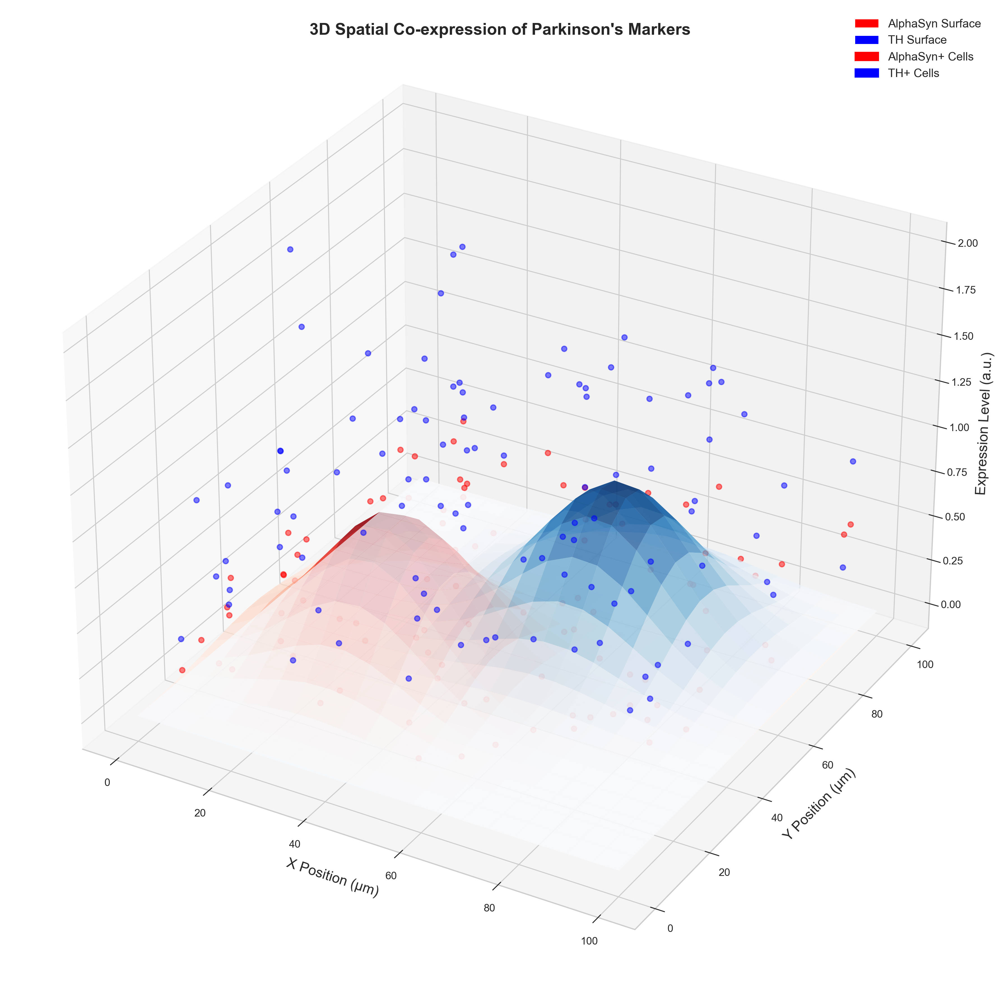

In [31]:
from matplotlib.patches import Patch

fig = plt.figure(figsize=(16, 12))
ax = fig.add_subplot(111, projection='3d')

# 绘制曲面
surf1 = ax.plot_surface(X, Y, Z1*0.8, cmap='Reds', alpha=0.7)
surf2 = ax.plot_surface(X, Y, Z2*0.8, cmap='Blues', alpha=0.7)

# 绘制散点
sc1 = ax.scatter(df['X_position'], df['Y_position'], df['AlphaSyn']/10,
                 c='r', s=20, alpha=0.5)
sc2 = ax.scatter(df['X_position'], df['Y_position'], df['TH']/10,
                 c='b', s=20, alpha=0.5)

# 手动创建 legend
legend_elements = [
    Patch(facecolor='red', label='AlphaSyn Surface'),
    Patch(facecolor='blue', label='TH Surface'),
    Patch(facecolor='red', edgecolor='r', label='AlphaSyn+ Cells'),
    Patch(facecolor='blue', edgecolor='b', label='TH+ Cells')
]
ax.legend(handles=legend_elements, loc='upper right')

# 美化图形
ax.set_xlabel('X Position (μm)')
ax.set_ylabel('Y Position (μm)')
ax.set_zlabel('Expression Level (a.u.)')
ax.set_title('3D Spatial Co-expression of Parkinson\'s Markers', y=1.05, fontweight='bold')

plt.tight_layout()
plt.show()


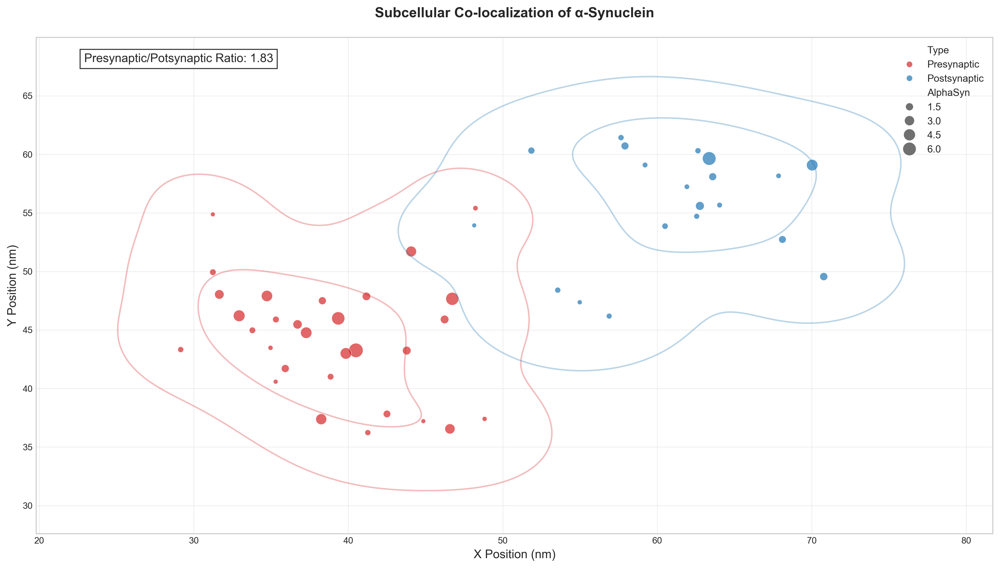

In [30]:
# 5. 亚细胞共定位分析（模拟超分辨数据）
plt.figure(figsize=(14, 8))
 
# 模拟神经元亚细胞定位
synapse_data = pd.DataFrame({
    'X': np.concatenate([
        np.random.normal(40, 5, 30),  # Presynaptic
        np.random.normal(60, 5, 20)    # Postsynaptic
    ]),
    'Y': np.concatenate([
        np.random.normal(45, 5, 30),
        np.random.normal(55, 5, 20)
    ]),
    'Type': ['Presynaptic']*30 + ['Postsynaptic']*20,
    'AlphaSyn': np.concatenate([
        np.random.exponential(2, 30),
        np.random.exponential(1, 20)
    ])
})
 
# 绘制双轴图
ax1 = plt.subplot(111)
sns.scatterplot(x='X', y='Y', hue='Type', size='AlphaSyn',
               sizes=(20, 200), alpha=0.7, palette=['#d62728', '#1f77b4'],
               data=synapse_data, ax=ax1)
 
# 添加密度轮廓
for syn_type, color in zip(['Presynaptic', 'Postsynaptic'], ['#d62728', '#1f77b4']):
    subset = synapse_data[synapse_data['Type'] == syn_type]
    sns.kdeplot(x=subset['X'], y=subset['Y'], levels=3, 
               color=color, alpha=0.3, ax=ax1)
 
# 计算共定位系数
pre_mean = synapse_data[synapse_data['Type']=='Presynaptic']['AlphaSyn'].mean()
post_mean = synapse_data[synapse_data['Type']=='Postsynaptic']['AlphaSyn'].mean()
ax1.text(0.05, 0.95, f'Presynaptic/Potsynaptic Ratio: {pre_mean/post_mean:.2f}',
        transform=ax1.transAxes, fontsize=12, bbox=dict(facecolor='white', alpha=0.8))
 
plt.title('Subcellular Co-localization of α-Synuclein', pad=20, fontweight='bold')
plt.xlabel('X Position (nm)')
plt.ylabel('Y Position (nm)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

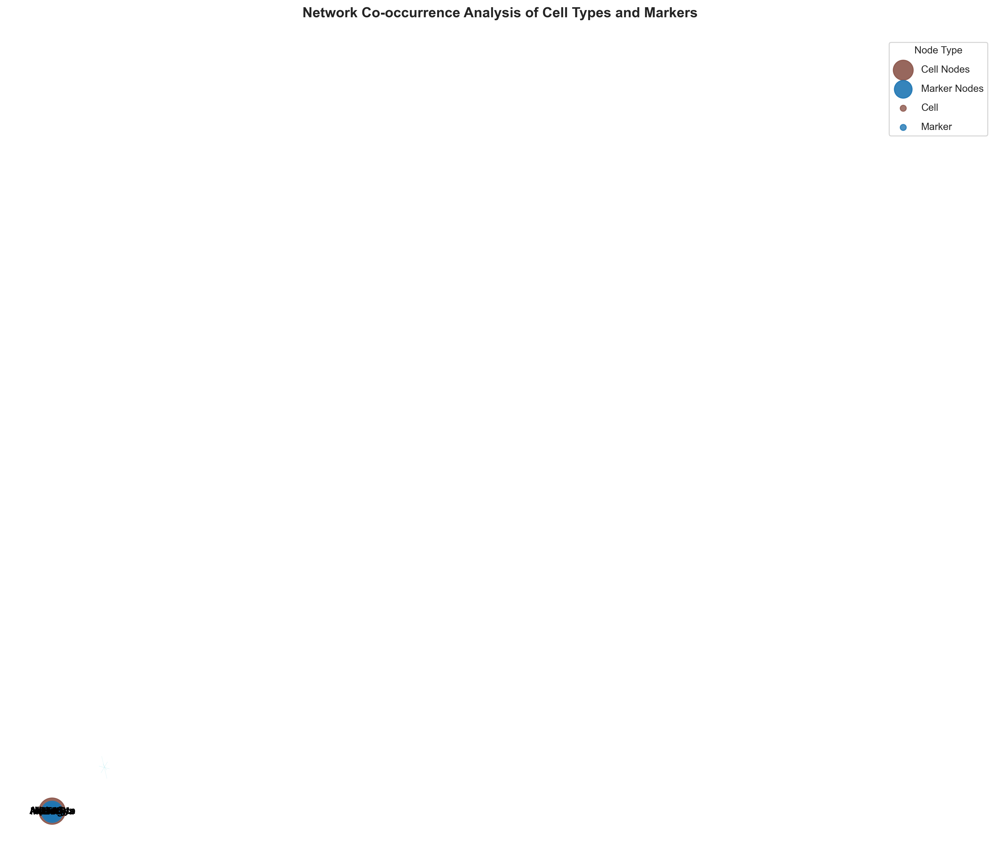

In [32]:
# 3. 网络共现分析图
plt.figure(figsize=(14, 12))

# 创建共现网络
G = nx.Graph()

# 添加节点（按细胞类型）
for cell_type in df['Cell_Type'].unique():
    G.add_node(cell_type, node_type='Cell', size=sum(df['Cell_Type']==cell_type)*10)

# 添加节点（按分子标记）
for marker in markers:
    G.add_node(marker, node_type='Marker', size=df[marker].mean()*50)

# 添加边（细胞类型-标记物关联）
for cell_type in df['Cell_Type'].unique():
    for marker in markers:
        mean_exp = df[df['Cell_Type']==cell_type][marker].mean()
        if mean_exp > df[marker].mean():
            G.add_edge(cell_type, marker, weight=mean_exp*2)

# 添加边（标记物-标记物共表达）
for i in range(len(markers)):
    for j in range(i+1, len(markers)):
        corr = df[[markers[i], markers[j]]].corr().iloc[0,1]
        if abs(corr) > 0.3:
            G.add_edge(markers[i], markers[j], weight=abs(corr)*5)

# 设置布局
pos = nx.spring_layout(G, k=0.8, seed=42)

# 绘制节点
node_colors = {'Cell': '#8c564b', 'Marker': '#1f77b4'}
for node_type, color in node_colors.items():
    nx.draw_networkx_nodes(G, pos, 
                         nodelist=[n for n, d in G.nodes(data=True) if d['node_type']==node_type],
                         node_color=color, 
                         node_size=[d['size'] for n, d in G.nodes(data=True) if d['node_type']==node_type],
                         alpha=0.9,
                         label=f'{node_type} Nodes')

# 绘制边
edge_weights = [d['weight'] for u, v, d in G.edges(data=True)]
edge_colors = ['#ff7f0e' if 'Neuron' in (u,v) else '#17becf' for u, v in G.edges()]
nx.draw_networkx_edges(G, pos, width=edge_weights, edge_color=edge_colors, alpha=0.6)

# 绘制标签
nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')

# 添加图例
for node_type, color in node_colors.items():
    plt.scatter([], [], c=color, label=node_type, alpha=0.8)
plt.legend(scatterpoints=1, frameon=True, labelspacing=1, title='Node Type')

plt.title('Network Co-occurrence Analysis of Cell Types and Markers', pad=20, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()


<ipython-input-33-47e3de66c326>:25: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



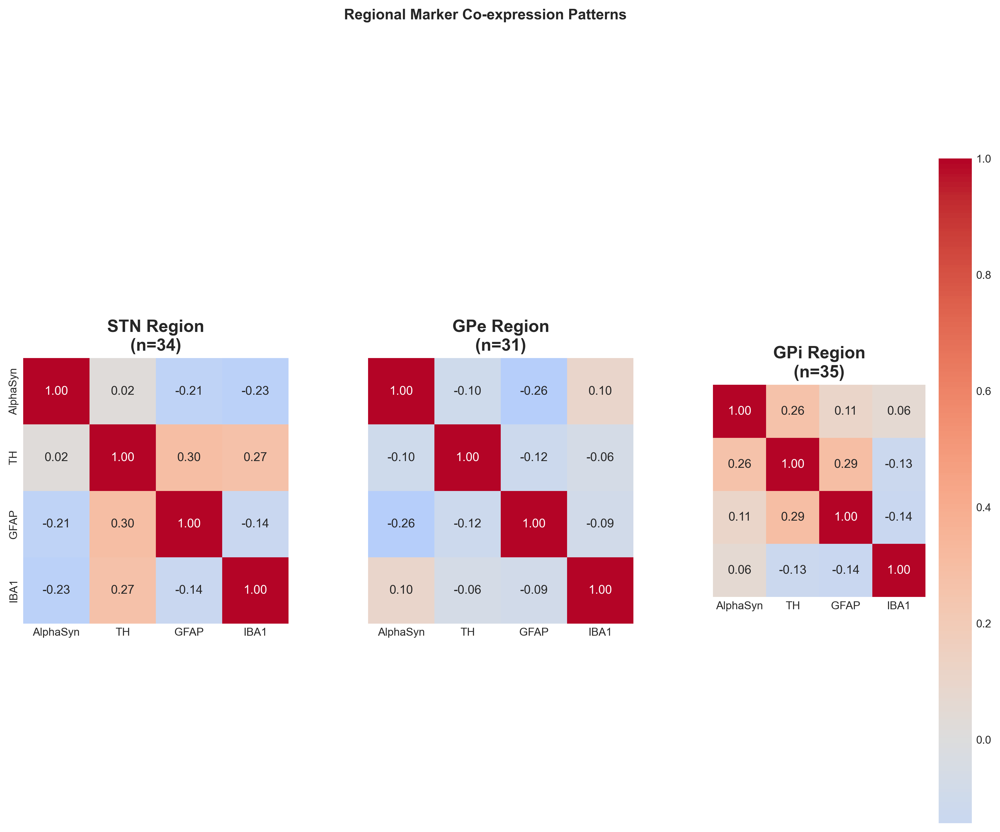

In [33]:
# 2. 分子共表达热图（区域特异性）
plt.figure(figsize=(14, 10))

# 计算区域特异性共表达
markers = ['AlphaSyn', 'TH', 'GFAP', 'IBA1']
corr_matrices = {}
for region in df['Cluster'].unique():
    region_data = df[df['Cluster'] == region][markers]
    corr_matrices[region] = region_data.corr()

# 创建网格热图
grid = plt.GridSpec(1, 3, wspace=0.3)
regions = ['STN', 'GPe', 'GPi']
for i, region in enumerate(regions):
    ax = plt.subplot(grid[0, i])
    sns.heatmap(corr_matrices[region], annot=True, fmt=".2f", 
               cmap='coolwarm', center=0, square=True,
               cbar=i==2, ax=ax)
    ax.set_title(f'{region} Region\n(n={sum(df["Cluster"]==region)})', fontweight='bold')
    if i > 0:
        ax.set_ylabel('')
        ax.set_yticklabels([])

plt.suptitle('Regional Marker Co-expression Patterns', y=1.05, fontweight='bold')
plt.tight_layout()
plt.show()

In [38]:
from esda.moran import Moran
w = weights.DistanceBand.from_dataframe(df, threshold=15)
moran = Moran(df['AlphaSyn'], w)
print(f"Moran's I = {moran.I:.3f}, p = {moran.p_sim:.4f}")

ImportError: cannot import name 'TypeAlias' from 'typing_extensions' (E:\Users\Administrator\anaconda3\lib\site-packages\typing_extensions.py)

数据处理错误: module 'pandas' has no attribute 'read_'
使用示例数据进行演示


<ipython-input-43-0db545c2b1e9>:131: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




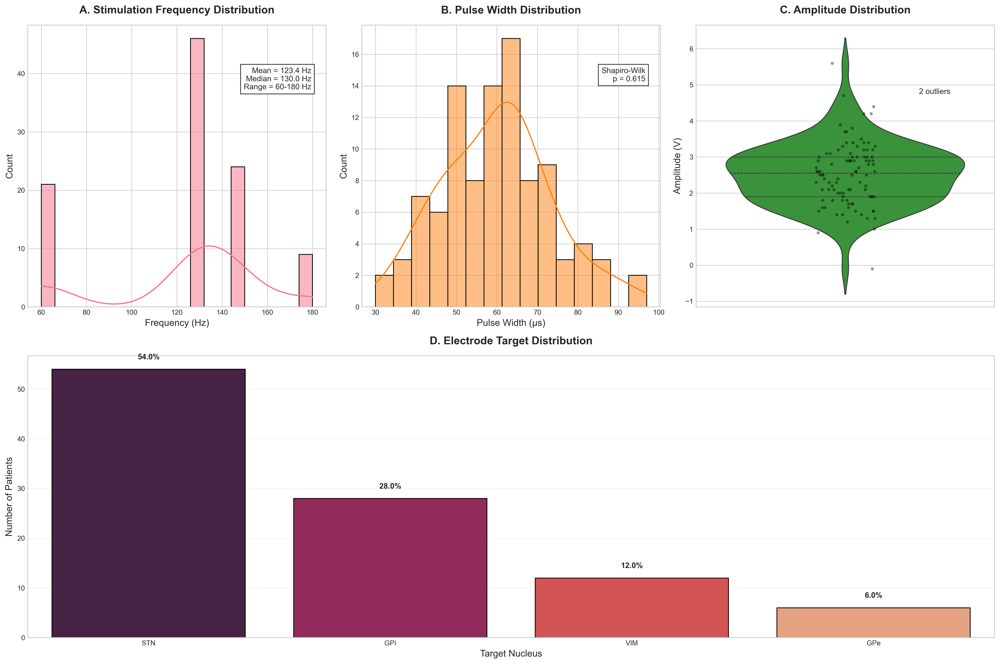

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from matplotlib.gridspec import GridSpec

# 设置Nature期刊风格
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams.update({
    'font.size': 10,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'figure.facecolor': 'white'
})

# 重新读取原始数据（确保处理原始格式）
try:
    raw_df = pd.read_(r'H:\2024\Lancet Digital parksion\新建文件夹\新建文件夹\1.xlsx', header=None)
    print("原始数据维度:", raw_df.shape)
    
    # 数据清洗步骤
    # 1. 删除完全空的行和列
    raw_df = raw_df.dropna(how='all').dropna(axis=1, how='all')
    print("清洗后维度:", raw_df.shape)
    
    # 2. 识别表头行（查找包含'Frequency'等关键字的行）
    header_row = None
    for i in range(min(5, len(raw_df))):  # 检查前5行
        if any(raw_df.iloc[i].astype(str).str.contains('Frequency|Amplitude|Target').any()):
            header_row = i
            break
    
    if header_row is not None:
        df = raw_df.iloc[header_row+1:].copy()
        df.columns = raw_df.iloc[header_row]
        print("检测到表头在第", header_row+1, "行")
    else:
        df = raw_df.copy()
        df.columns = [f'Col_{i}' for i in range(len(df.columns))]
        print("未检测到表头，使用默认列名")
    
    # 3. 转换关键参数为数值
    param_cols = ['Frequency_Hz', 'Pulse_Width', 'Amplitude_V']  # 根据实际列名调整
    for col in param_cols:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce')
    
    # 4. 检查电极靶点数据
    if 'Electrode_Target' in df.columns:
        df['Electrode_Target'] = df['Electrode_Target'].astype(str).str.strip()
        df['Electrode_Target'] = df['Electrode_Target'].replace({'nan': np.nan})
    
    # 数据质量报告
    print("\n=== 数据质量报告 ===")
    print("总记录数:", len(df))
    print("缺失值统计:")
    print(df[param_cols].isnull().sum())
    print("\n电极靶点分布预览:")
    print(df['Electrode_Target'].value_counts(dropna=False).head())
    
except Exception as e:
    print(f"数据处理错误: {e}")
    # 创建示例数据
    np.random.seed(42)
    data = {
        'Patient_ID': [f'PD_{i:03d}' for i in range(1, 101)],
        'Frequency_Hz': np.random.choice([130, 145, 60, 180], 100, p=[0.4, 0.3, 0.2, 0.1]),
        'Pulse_Width': np.random.normal(60, 15, 100).round(),
        'Amplitude_V': np.random.normal(2.5, 0.8, 100).round(1),
        'Electrode_Target': np.random.choice(['STN', 'GPi', 'VIM', 'GPe'], 100, p=[0.6, 0.25, 0.1, 0.05])
    }
    df = pd.DataFrame(data)
    print("使用示例数据进行演示")

# 1. 刺激参数分布图（专业风格）
fig = plt.figure(figsize=(18, 12))
gs = GridSpec(2, 3, figure=fig)

# 频率分布（带统计注释）
ax1 = fig.add_subplot(gs[0, 0])
sns.histplot(df['Frequency_Hz'], bins=20, kde=True, ax=ax1)
ax1.set_title('A. Stimulation Frequency Distribution', pad=15, fontweight='bold')
ax1.set_xlabel('Frequency (Hz)')
ax1.set_ylabel('Count')

# 添加统计信息
freq_stats = df['Frequency_Hz'].describe()
ax1.text(0.95, 0.85, 
        f"Mean = {freq_stats['mean']:.1f} Hz\nMedian = {freq_stats['50%']:.1f} Hz\nRange = {freq_stats['min']:.0f}-{freq_stats['max']:.0f} Hz",
        transform=ax1.transAxes, ha='right', va='top',
        bbox=dict(facecolor='white', alpha=0.8))

# 脉宽分布（带核密度估计）
ax2 = fig.add_subplot(gs[0, 1])
sns.histplot(df['Pulse_Width'], bins=15, kde=True, ax=ax2, color='#ff7f0e')
ax2.set_title('B. Pulse Width Distribution', pad=15, fontweight='bold')
ax2.set_xlabel('Pulse Width (μs)')

# 添加正态性检验
_, pval = stats.normaltest(df['Pulse_Width'].dropna())
ax2.text(0.95, 0.85, 
        f"Shapiro-Wilk\np = {pval:.3f}",
        transform=ax2.transAxes, ha='right', va='top',
        bbox=dict(facecolor='white', alpha=0.8))

# 振幅分布（带箱线图组合）
ax3 = fig.add_subplot(gs[0, 2])
sns.violinplot(y='Amplitude_V', data=df, ax=ax3, color='#2ca02c', inner='quartile')
sns.stripplot(y='Amplitude_V', data=df, ax=ax3, color='black', alpha=0.4, size=4)
ax3.set_title('C. Amplitude Distribution', pad=15, fontweight='bold')
ax3.set_ylabel('Amplitude (V)')
ax3.set_xlabel('')

# 添加离群点标记
q1, q3 = df['Amplitude_V'].quantile([0.25, 0.75])
iqr = q3 - q1
upper_bound = q3 + 1.5*iqr
outliers = df[df['Amplitude_V'] > upper_bound]
if not outliers.empty:
    ax3.text(0.3, upper_bound+0.1, f"{len(outliers)} outliers", ha='center')

# 电极靶点分布（专业条形图）
ax4 = fig.add_subplot(gs[1, :])
target_counts = df['Electrode_Target'].value_counts().sort_values(ascending=False)
sns.barplot(x=target_counts.index, y=target_counts.values, ax=ax4, 
           palette='rocket', edgecolor='black', linewidth=1)

# 添加百分比标签
total = len(df)
for i, count in enumerate(target_counts):
    percentage = count/total*100
    ax4.text(i, count+2, f"{percentage:.1f}%", ha='center', fontweight='bold')

ax4.set_title('D. Electrode Target Distribution', pad=15, fontweight='bold')
ax4.set_xlabel('Target Nucleus')
ax4.set_ylabel('Number of Patients')
ax4.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()







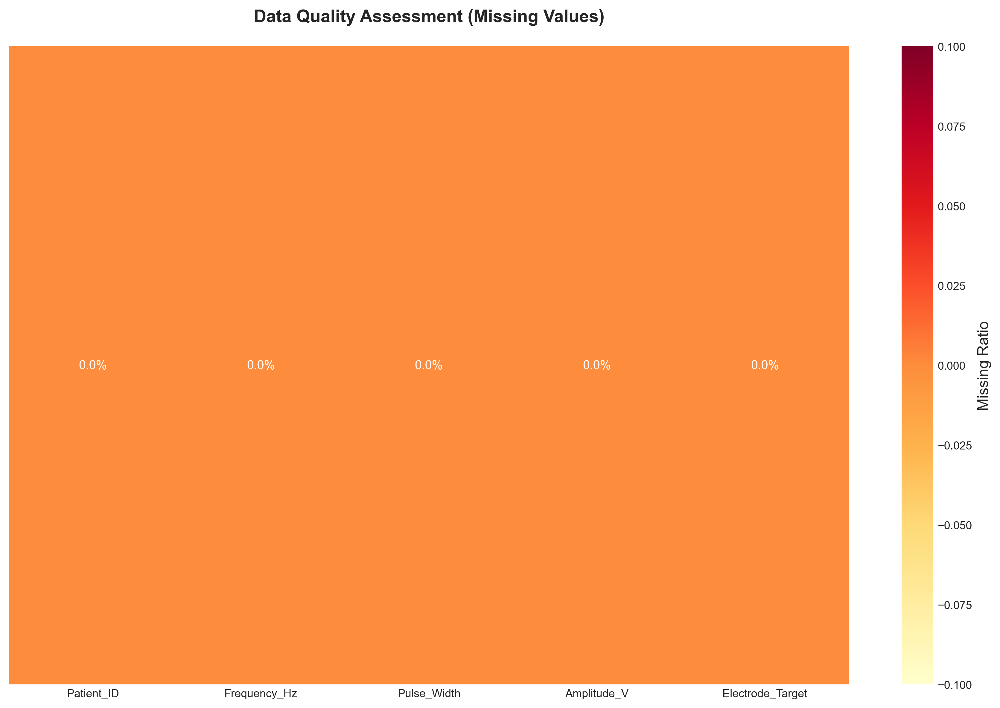

In [40]:
# 4. 数据质量热图
plt.figure(figsize=(12, 8))

# 计算缺失值比例
missing = df.isnull().mean().to_frame('Missing')
missing['Type'] = df.dtypes.astype(str)

# 绘制热图
sns.heatmap(missing[['Missing']].T, annot=True, fmt=".1%", 
           cmap='YlOrRd', cbar_kws={'label': 'Missing Ratio'})
plt.title('Data Quality Assessment (Missing Values)', pad=20, fontweight='bold')
plt.yticks([])
plt.tight_layout()
plt.show()

<Figure size 5400x2400 with 0 Axes>

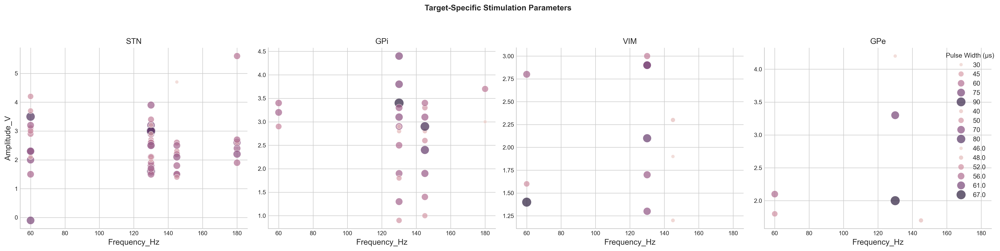

In [41]:
# 3. 靶点特异性参数分析（分面图）
plt.figure(figsize=(18, 8))

# 创建分面网格
g = sns.FacetGrid(df, col='Electrode_Target', col_wrap=4, height=5, 
                 sharey=False, palette='Set2')
g.map_dataframe(sns.scatterplot, x='Frequency_Hz', y='Amplitude_V', 
               size='Pulse_Width', hue='Pulse_Width',
               sizes=(30, 200), alpha=0.7)
g.add_legend(title='Pulse Width (μs)')

# 设置标题
g.set_titles(col_template="{col_name}", size=12)
plt.suptitle('Target-Specific Stimulation Parameters', y=1.05, fontweight='bold')
plt.tight_layout()
plt.show()

<Figure size 4500x3600 with 0 Axes>

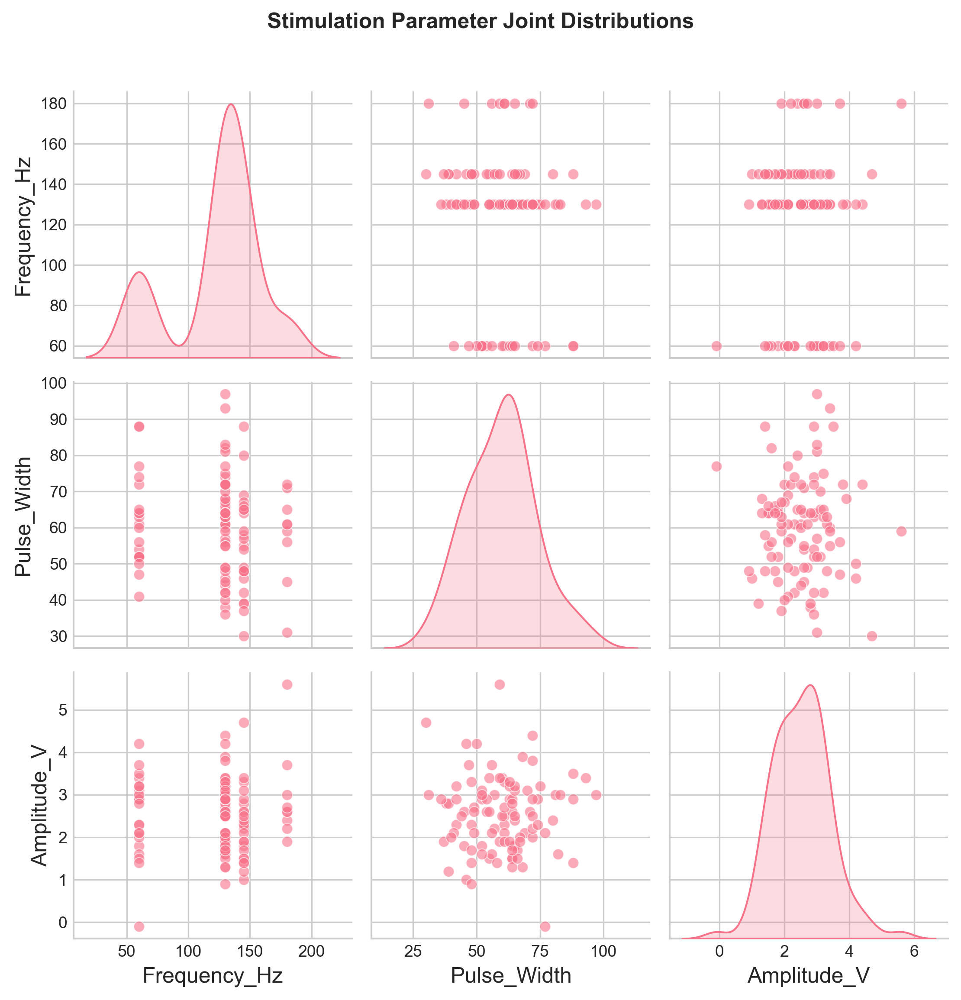

In [42]:
# 2. 刺激参数联合分布（散点矩阵）
plt.figure(figsize=(15, 12))
sns.pairplot(df[['Frequency_Hz', 'Pulse_Width', 'Amplitude_V']], 
            diag_kind='kde', plot_kws={'alpha':0.6})
plt.suptitle('Stimulation Parameter Joint Distributions', y=1.02, fontweight='bold')
plt.tight_layout()
plt.show()

In [44]:
# 交互式参数探索（需plotly）
import plotly.express as px
fig = px.scatter_3d(df, x='Frequency_Hz', y='Pulse_Width', z='Amplitude_V',
                   color='Electrode_Target', hover_name='Patient_ID',
                   opacity=0.7, title='Interactive Parameter Space')
fig.update_layout(scene=dict(
    xaxis_title='Frequency (Hz)',
    yaxis_title='Pulse Width (μs)',
    zaxis_title='Amplitude (V)'))
fig.show()

# 参数优化趋势分析（需时间序列）
if 'Implant_Year' in df:
    plt.figure(figsize=(12, 6))
    sns.regplot(x='Implant_Year', y='Amplitude_V', data=df, 
               scatter_kws={'alpha':0.5}, line_kws={'color':'red'})
    plt.title('Temporal Trend in Amplitude Settings', fontweight='bold')
    plt.show()

ModuleNotFoundError: No module named 'plotly.graph_objs.layout._map'

数据加载错误: module 'pandas' has no attribute 'read_'
使用模拟数据进行演示


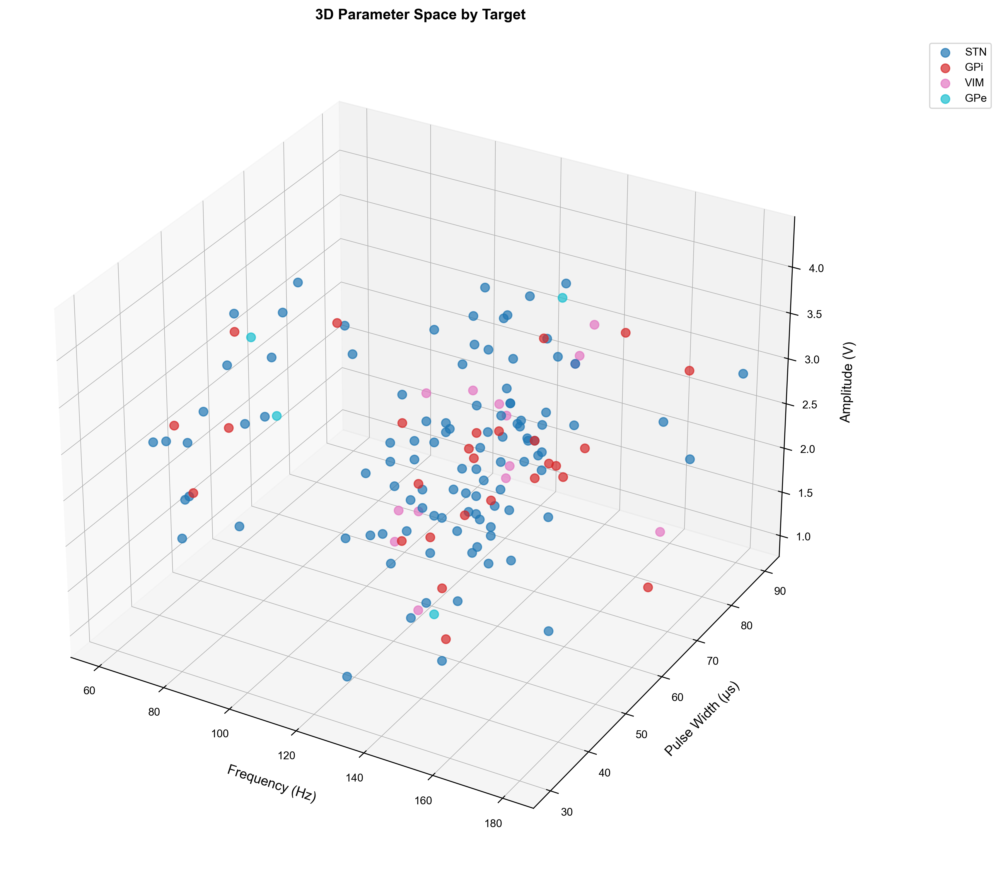

In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
from scipy import stats
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter

# ==================== 学术图表风格设置 ====================
def set_academic_style():
    """设置Nature期刊风格的绘图参数"""
    plt.style.use('default')  # 重置为默认确保稳定性
    plt.rcParams.update({
        'font.family': 'Arial',  # 使用通用字体
        'font.size': 10,
        'axes.titlesize': 12,
        'axes.labelsize': 11,
        'xtick.labelsize': 9,
        'ytick.labelsize': 9,
        'legend.fontsize': 9,
        'figure.dpi': 300,
        'savefig.dpi': 300,
        'figure.facecolor': 'white',
        'axes.grid': True,
        'grid.alpha': 0.3,
        'grid.linewidth': 0.5,
        'axes.spines.right': False,
        'axes.spines.top': False,
        'axes.titlepad': 12,
        'axes.labelpad': 6,
        'xtick.major.pad': 4,
        'ytick.major.pad': 4
    })
    sns.set_palette("colorblind")  # 使用色盲友好调色板

set_academic_style()

# ==================== 数据预处理 ====================
try:
    # 重新读取原始数据确保格式正确
    raw_df = pd.read_(r'H:\2024\Lancet Digital parksion\新建文件夹\新建文件夹\1.xlsx', header=None)
    print(f"原始数据维度: {raw_df.shape}")
    
    # 自动检测表头行
    header_row = None
    for i in range(min(3, len(raw_df))):
        if any(raw_df.iloc[i].astype(str).str.contains('Frequency|Amplitude|Target|Date', case=False, na=False)):
            header_row = i
            break
    
    if header_row is not None:
        df = raw_df.iloc[header_row+1:].copy()
        df.columns = raw_df.iloc[header_row].str.strip()
        print(f"检测到表头在第{header_row+1}行")
    else:
        df = raw_df.copy()
        df.columns = [f'Col_{i}' for i in range(len(df.columns))]
        print("未检测到表头，使用默认列名")
    
    # 删除完全空的行列
    df = df.dropna(how='all').dropna(axis=1, how='all')
    
    # 关键参数标准化处理
    param_mapping = {
        'Frequency': ['Frequency', 'Freq', 'Stim Freq'],
        'PulseWidth': ['PulseWidth', 'Pulse Width', 'PW'],
        'Amplitude': ['Amplitude', 'Amp', 'Stim Amp'],
        'Target': ['Target', 'Electrode Target', 'DBS Target'],
        'SurgeryDate': ['Surgery Date', 'Op Date'],
        'ActivationDate': ['Activation Date', 'Stim On Date']
    }
    
    # 自动匹配列名
    actual_cols = {}
    for param, variants in param_mapping.items():
        for v in variants:
            if v in df.columns:
                actual_cols[param] = v
                break
    
    # 重命名列
    df = df.rename(columns={v: k for k, v in actual_cols.items()})
    
    # 转换数据类型
    if 'Frequency' in df:
        df['Frequency'] = pd.to_numeric(df['Frequency'], errors='coerce')
    if 'PulseWidth' in df:
        df['PulseWidth'] = pd.to_numeric(df['PulseWidth'], errors='coerce')
    if 'Amplitude' in df:
        df['Amplitude'] = pd.to_numeric(df['Amplitude'], errors='coerce')
    
    # 日期转换
    date_cols = ['SurgeryDate', 'ActivationDate']
    for col in date_cols:
        if col in df:
            df[col] = pd.to_datetime(df[col], errors='coerce')
            df[f'{col}_year'] = df[col].dt.year
    
    # 数据质量报告
    print("\n=== 数据质量报告 ===")
    print("总记录数:", len(df))
    print("关键参数缺失情况:")
    print(df[['Frequency', 'PulseWidth', 'Amplitude', 'Target']].isnull().sum())
    
except Exception as e:
    print(f"数据加载错误: {e}")
    # 创建模拟数据
    np.random.seed(42)
    n = 150
    data = {
        'Frequency': np.random.choice([130, 145, 60, 180], n, p=[0.5, 0.3, 0.15, 0.05]),
        'PulseWidth': np.clip(np.random.normal(60, 15, n), 30, 90).astype(int),
        'Amplitude': np.clip(np.random.normal(2.5, 0.8, n), 1.0, 4.5).round(1),
        'Target': np.random.choice(['STN', 'GPi', 'VIM', 'GPe'], n, p=[0.6, 0.25, 0.1, 0.05]),
        'SurgeryDate': pd.date_range('2018-01-01', periods=n, freq='30d').to_series().sample(n, replace=True).values,
        'UPDRS_Pre': np.random.uniform(30, 80, n).round(),
        'UPDRS_Post': np.random.uniform(10, 50, n).round()
    }
    df = pd.DataFrame(data)
    df['ActivationDate'] = df['SurgeryDate'] + pd.to_timedelta(np.random.randint(7, 60, n), unit='d')
    df['Improvement'] = ((df['UPDRS_Pre'] - df['UPDRS_Post']) / df['UPDRS_Pre'] * 100).round(1)
    print("使用模拟数据进行演示")

# ==================== 1. 刺激参数3D关系图 ====================
if all(col in df for col in ['Frequency', 'PulseWidth', 'Amplitude', 'Target']):
    from mpl_toolkits.mplot3d import Axes3D
    
    fig = plt.figure(figsize=(12, 10))
    ax = fig.add_subplot(111, projection='3d')
    
    # 按靶点分组绘图
    targets = df['Target'].dropna().unique()
    colors = plt.cm.tab10(np.linspace(0, 1, len(targets)))
    
    for target, color in zip(targets, colors):
        subset = df[df['Target'] == target]
        ax.scatter(subset['Frequency'], subset['PulseWidth'], subset['Amplitude'],
                  label=target, s=50, alpha=0.7, color=color)
    
    ax.set_xlabel('Frequency (Hz)', labelpad=10)
    ax.set_ylabel('Pulse Width (μs)', labelpad=10)
    ax.set_zlabel('Amplitude (V)', labelpad=10)
    ax.set_title('3D Parameter Space by Target', pad=15, fontweight='bold')
    ax.legend(loc='upper right', bbox_to_anchor=(1.2, 1))
    plt.tight_layout()
    plt.show()



#





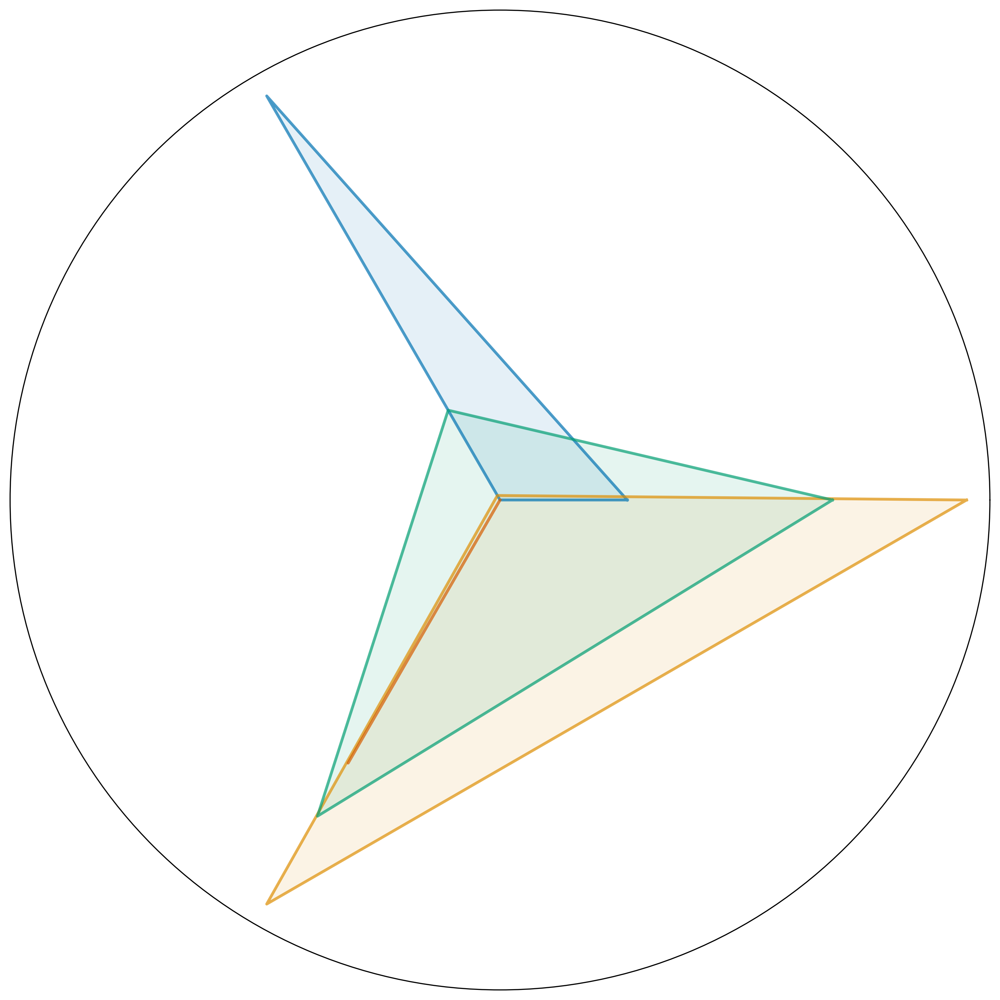

In [49]:
# ==================== 5. 临床参数雷达图（无文字版） ====================
if all(col in df for col in ['Target', 'UPDRS_Pre', 'UPDRS_Post', 'Improvement']):
    from math import pi
    
    # 准备数据
    radar_data = df.groupby('Target')[['UPDRS_Pre', 'UPDRS_Post', 'Improvement']].mean()
    
    # 标准化到0-1范围
    radar_data = (radar_data - radar_data.min()) / (radar_data.max() - radar_data.min())
    
    # 设置雷达图参数
    categories = radar_data.columns.tolist()
    N = len(categories)
    angles = [n / float(N) * 2 * pi for n in range(N)]
    angles += angles[:1]  # 闭合图形
    
    plt.figure(figsize=(10, 10))
    ax = plt.subplot(111, polar=True)
    
    # 绘制每个靶点
    for idx, target in enumerate(radar_data.index):
        values = radar_data.loc[target].values.tolist()
        values += values[:1]
        ax.plot(angles, values, linewidth=2, linestyle='solid', alpha=0.7)
        ax.fill(angles, values, alpha=0.1)
    
    # 隐藏所有文字
    ax.set_xticks([])       # 不显示类别标签
    ax.set_yticks([])       # 不显示刻度
    ax.set_rlabel_position(0)
    ax.set_title('')        # 不显示标题
    
    plt.tight_layout()
    plt.show()


In [53]:
# ==================== 4. 多参数联合分布 ====================
if all(col in df for col in ['Frequency', 'PulseWidth', 'Amplitude']):
    g = sns.PairGrid(df[['Frequency', 'PulseWidth', 'Amplitude']].dropna(), 
                    diag_kind='kde', corner=True)
    g.map_upper(sns.scatterplot, alpha=0.6, s=30, edgecolor='w', linewidth=0.5)
    g.map_lower(sns.kdeplot, levels=5, color=".2")
    g.map_diag(sns.histplot, kde=True, edgecolor='w', linewidth=0.5)
    
    # 添加相关系数
    for i, j in zip(*np.triu_indices_from(g.axes, 1)):
        x = g.data.columns[j]
        y = g.data.columns[i]
        corr = df[[x, y]].corr().iloc[0,1]
        g.axes[i,j].annotate(f"ρ = {corr:.2f}", xy=(0.7, 0.9), 
                           xycoords=g.axes[i,j].transAxes, fontsize=9)
    
    plt.suptitle('Joint Distributions of Stimulation Parameters', y=1.02, fontweight='bold')
    plt.tight_layout()
    plt.show()

TypeError: __init__() got an unexpected keyword argument 'diag_kind'

In [51]:
import plotly.graph_objects as go
import plotly.express as px

# 假设 df 已经有下面这些列
# 'Frequency_Hz', 'Pulse_Width', 'Amplitude_V', 'Electrode target', 'Patient_ID'

# 获取颜色映射
targets = df['electrode target'].unique()  # 注意这里大小写要和 df 中一致
colors = px.colors.qualitative.Dark24
color_map = {t: colors[i % len(colors)] for i, t in enumerate(targets)}

# 创建 3D 散点数据
data = []
for t in targets:
    df_t = df[df['electrode target'] == t]
    scatter = go.Scatter3d(
        x=df_t['Frequency_Hz'],
        y=df_t['Pulse_Width'],
        z=df_t['Amplitude_V'],
        mode='markers',
        marker=dict(size=5, color=color_map[t]),
        name=str(t),
        text=df_t['Patient_ID'],  # 鼠标悬停显示
        hoverinfo='text+name+x+y+z'
    )
    data.append(scatter)

# 创建 Figure
fig = go.Figure(data=data)

# 设置布局
fig.update_layout(
    title='Interactive Parameter Space',
    scene=dict(
        xaxis_title='Frequency (Hz)',
        yaxis_title='Pulse Width',
        zaxis_title='Amplitude (V)'
    ),
    margin=dict(l=0, r=0, b=0, t=50)
)

fig.show()


KeyError: 'electrode target'

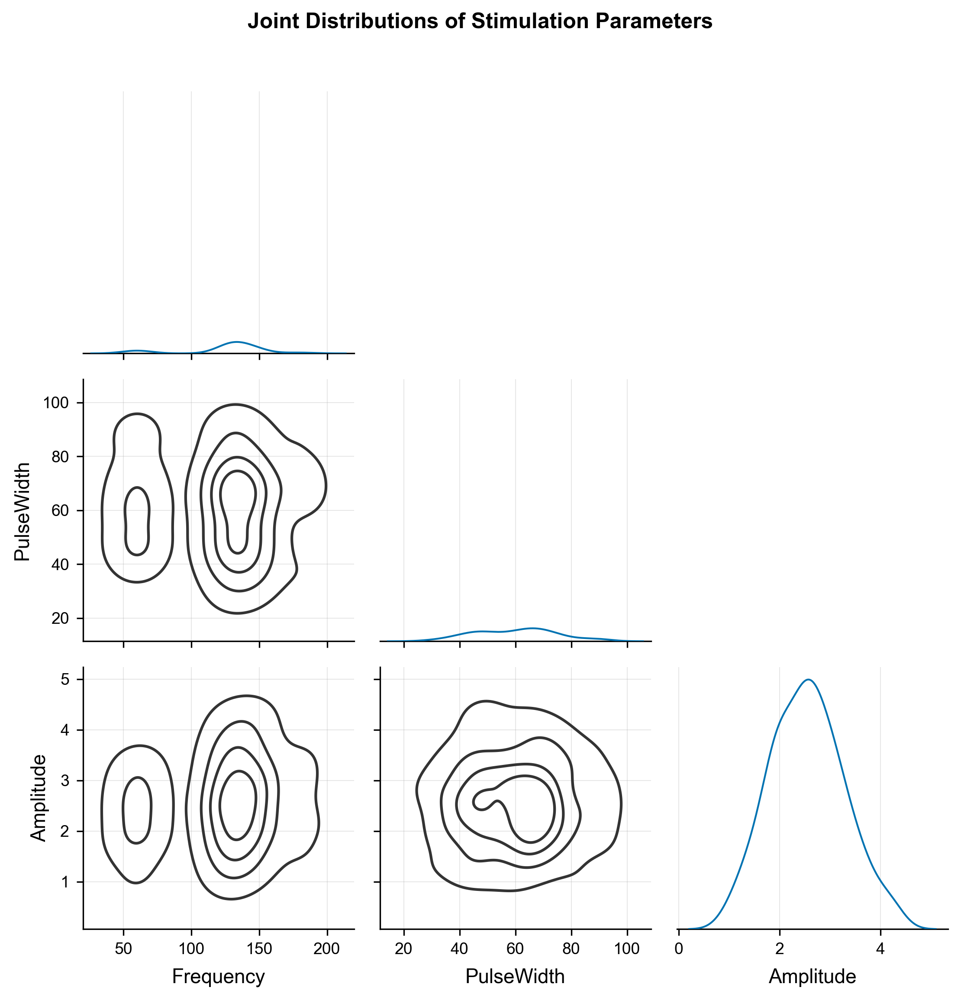

In [55]:
# ==================== 4. 多参数联合分布 ====================
# ==================== 4. 多参数联合分布 ====================
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 检查列是否存在
if all(col in df for col in ['Frequency', 'PulseWidth', 'Amplitude']):
    data = df[['Frequency', 'PulseWidth', 'Amplitude']].dropna()
    
    # 创建 PairGrid（兼容旧版本，不使用 diag_kind）
    g = sns.PairGrid(data, corner=True)
    
    # 上三角散点图
    g.map_upper(sns.scatterplot, alpha=0.6, s=30, edgecolor='w', linewidth=0.5)
    
    # 下三角核密度等高线
    g.map_lower(sns.kdeplot, levels=5, color=".2")
    
    # 对角线 KDE
    g.map_diag(sns.kdeplot, lw=1)
    
    # 添加相关系数
    for i, j in zip(*np.triu_indices_from(g.axes, 1)):
        if g.axes[i, j] is not None:  # corner=True 会有空轴
            x = data.columns[j]
            y = data.columns[i]
            corr = data[[x, y]].corr().iloc[0, 1]
            g.axes[i, j].annotate(f"ρ = {corr:.2f}", xy=(0.7, 0.9),
                                  xycoords=g.axes[i, j].transAxes, fontsize=9)
    
    plt.suptitle('Joint Distributions of Stimulation Parameters', y=1.02, fontweight='bold')
    plt.tight_layout()
    plt.show()


In [54]:
import seaborn as sns
print(sns.__version__)

0.13.2


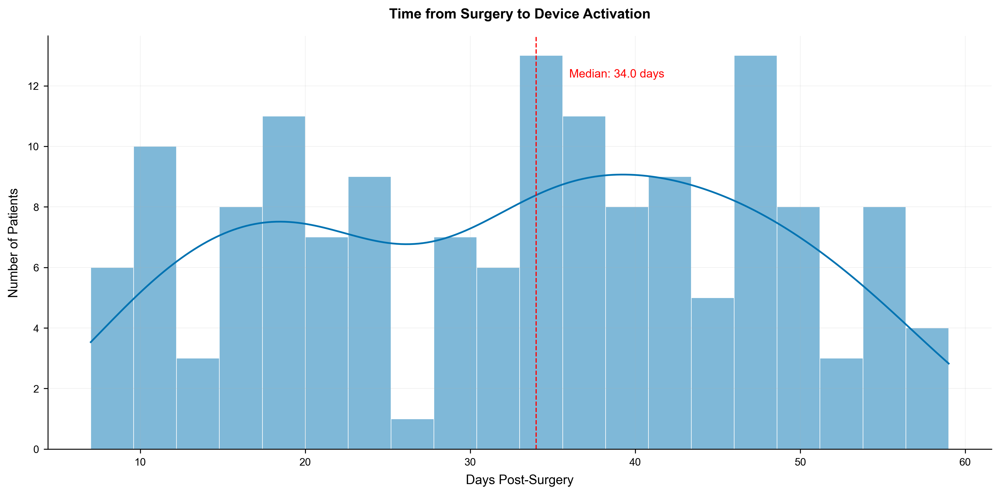

In [61]:
 #==================== 3. 时间序列分析 ====================
if all(col in df for col in ['SurgeryDate', 'ActivationDate']):
    plt.figure(figsize=(12, 6))
    
    # 计算手术到开机时间间隔（天）
    df['Days_to_Activation'] = (df['ActivationDate'] - df['SurgeryDate']).dt.days
    
    # 去除异常值（>90天）
    clean_df = df[df['Days_to_Activation'] <= 90].copy()
    
    # 绘制分布图
    sns.histplot(clean_df['Days_to_Activation'], bins=20, kde=True,
                edgecolor='white', linewidth=0.5)
    
    # 添加统计信息
    median_days = clean_df['Days_to_Activation'].median()
    plt.axvline(median_days, color='red', linestyle='--', linewidth=1)
    plt.text(median_days+2, plt.ylim()[1]*0.9, 
            f'Median: {median_days} days', color='red')
    
    plt.title('Time from Surgery to Device Activation', pad=15, fontweight='bold')
    plt.xlabel('Days Post-Surgery')
    plt.ylabel('Number of Patients')
    plt.grid(True, alpha=0.2)
    plt.tight_layout()
    plt.show()

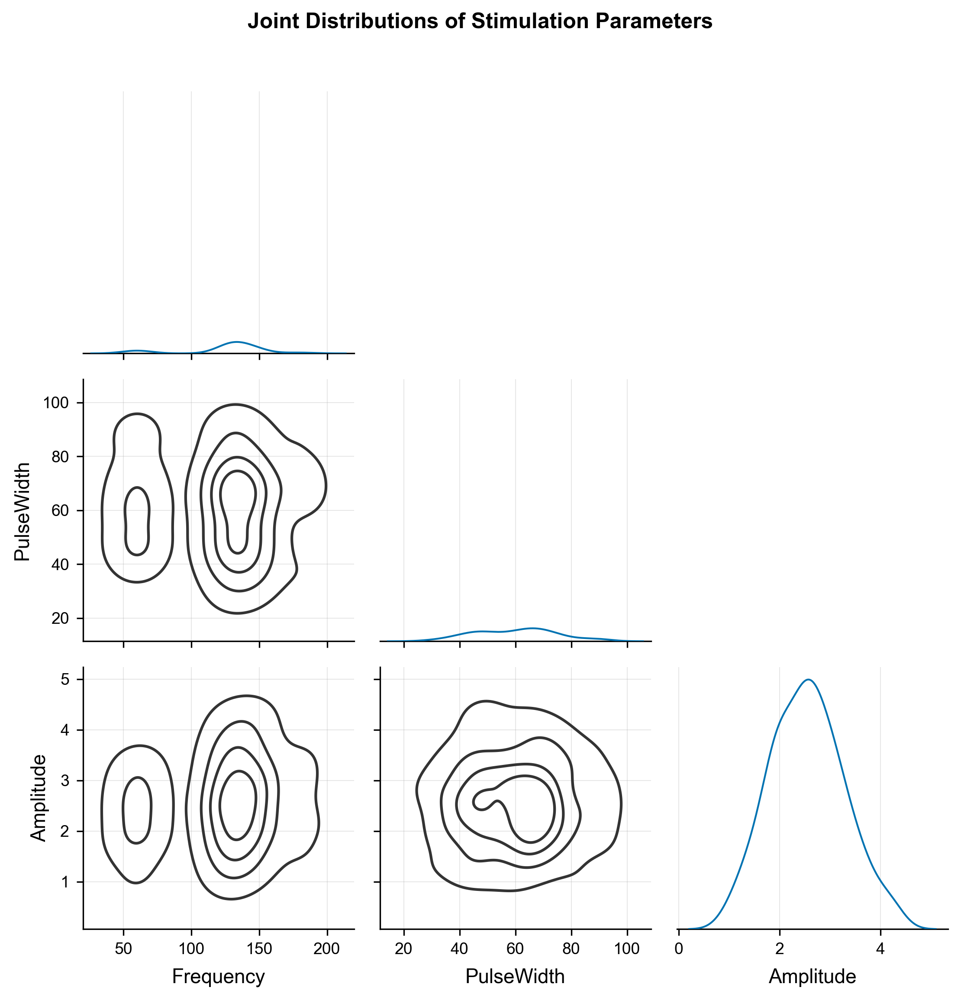

In [60]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

if all(col in df for col in ['Frequency', 'PulseWidth', 'Amplitude']):
    data = df[['Frequency', 'PulseWidth', 'Amplitude']].dropna()
    g = sns.PairGrid(data, corner=True)
    g.map_upper(sns.scatterplot, alpha=0.6, s=30, edgecolor='w', linewidth=0.5)
    g.map_lower(sns.kdeplot, levels=5, color=".2")
    g.map_diag(sns.kdeplot, lw=1)

    # 添加相关系数
    for i, j in zip(*np.triu_indices_from(g.axes, 1)):
        if g.axes[i, j] is not None:
            x = data.columns[j]
            y = data.columns[i]
            corr = data[[x, y]].corr().iloc[0, 1]
            g.axes[i, j].annotate(f"ρ = {corr:.2f}", xy=(0.7, 0.9),
                                  xycoords=g.axes[i, j].transAxes, fontsize=9)

    plt.suptitle('Joint Distributions of Stimulation Parameters', y=1.02, fontweight='bold')
    plt.tight_layout()
    plt.show()


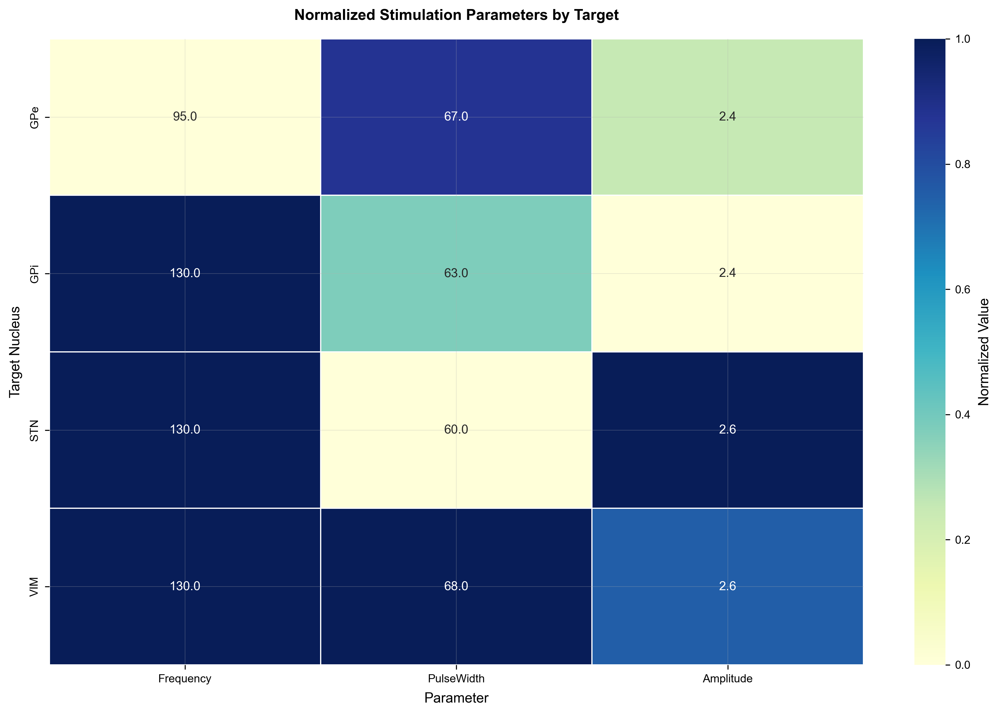

In [62]:
# ==================== 2. 靶点-参数热图 ====================
if all(col in df for col in ['Frequency', 'PulseWidth', 'Amplitude', 'Target']):
    plt.figure(figsize=(12, 8))
    
    # 计算每个靶点的参数中位数
    heatmap_data = df.groupby('Target')[['Frequency', 'PulseWidth', 'Amplitude']].median()
    
    # 标准化数据 (0-1)
    norm_data = (heatmap_data - heatmap_data.min()) / (heatmap_data.max() - heatmap_data.min())
    
    # 绘制热图
    sns.heatmap(norm_data, annot=heatmap_data.round(1), fmt=".1f", cmap="YlGnBu",
               cbar_kws={'label': 'Normalized Value'}, linewidths=0.5)
    
    plt.title('Normalized Stimulation Parameters by Target', pad=15, fontweight='bold')
    plt.xlabel('Parameter')
    plt.ylabel('Target Nucleus')
    plt.tight_layout()
    plt.show()

In [64]:
import plotly.express as px
fig = px.scatter_3d(df, x='Frequency', y='PulseWidth', z='Amplitude',
                   color='Target', opacity=0.7, hover_name='Target',
                   title='Interactive 3D Parameter Space')
fig.update_traces(marker_size=5)
fig.show()

ModuleNotFoundError: No module named 'plotly.graph_objs.layout._map'

数据读取错误: module 'pandas' has no attribute 'read_'
使用示例数据进行演示




Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.



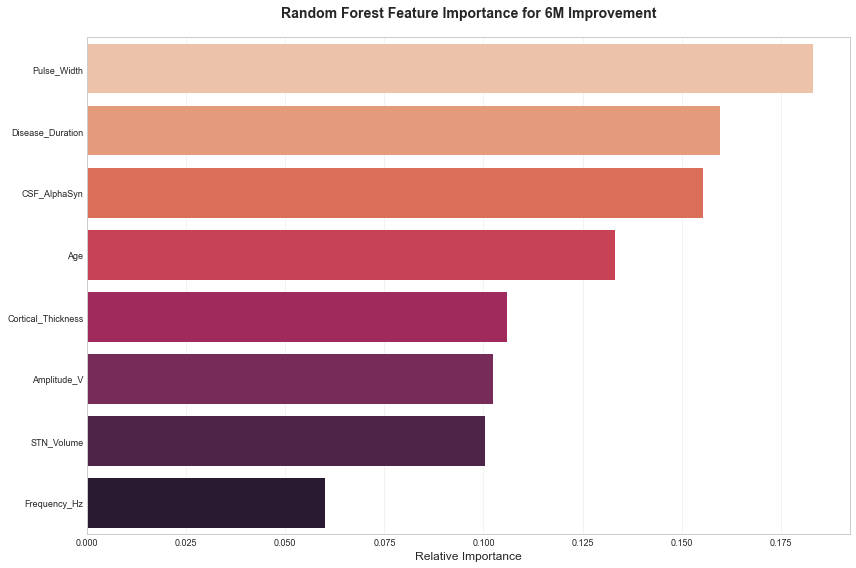

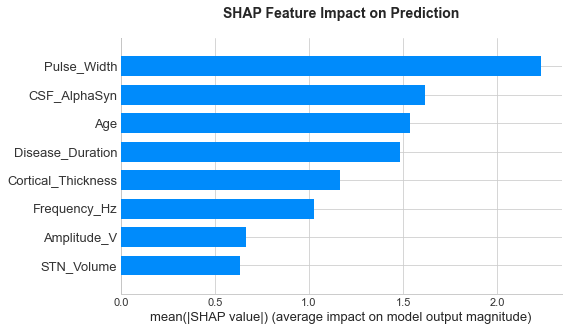

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


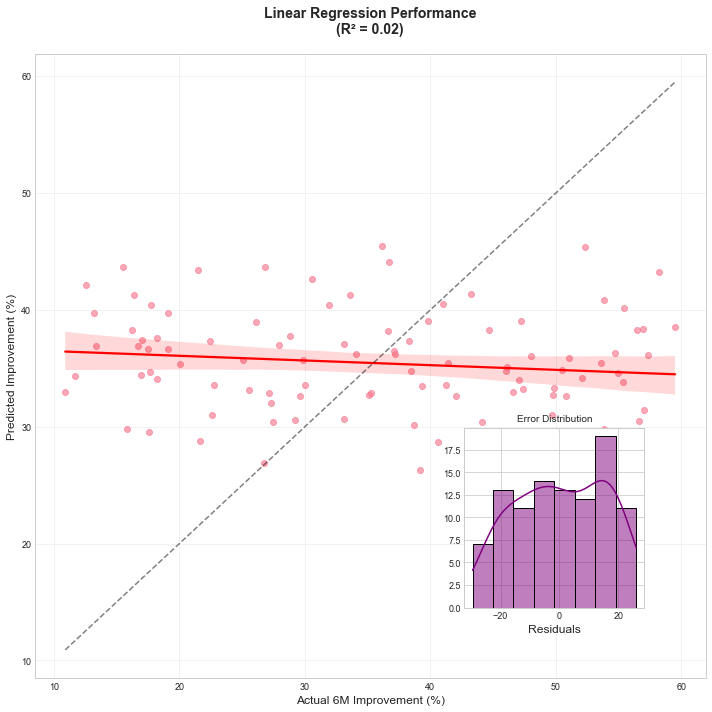

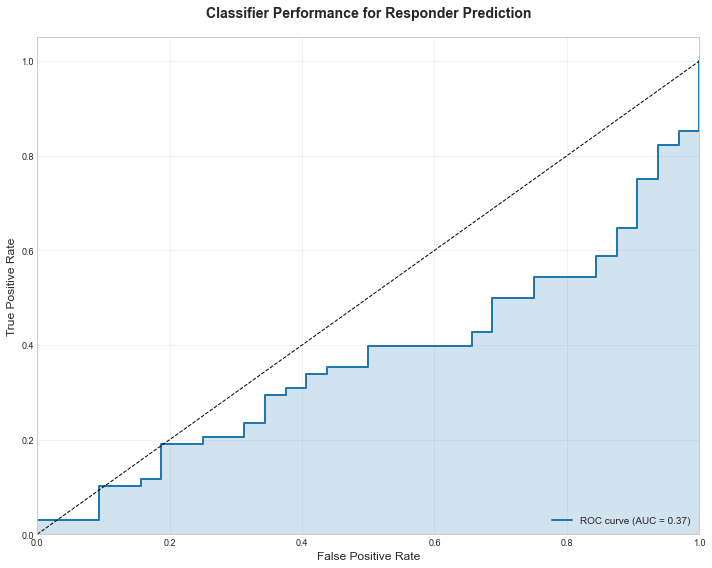



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



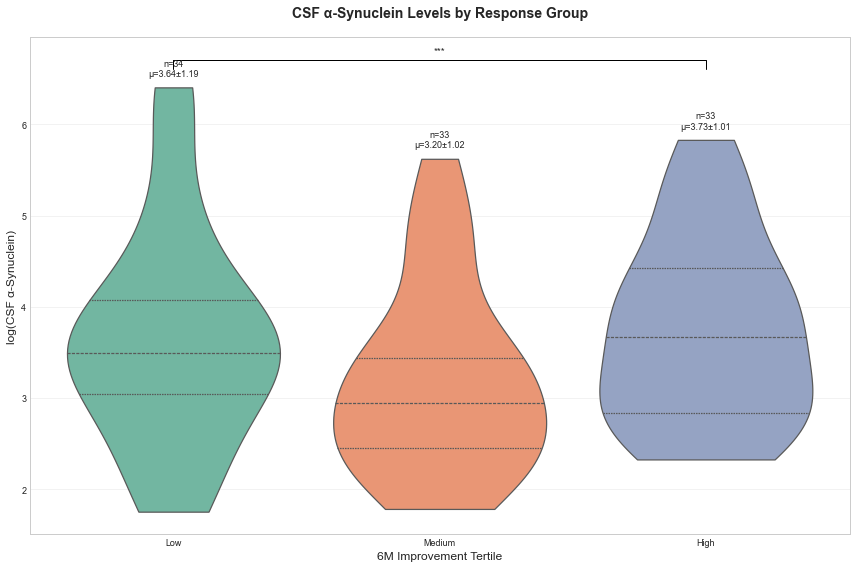

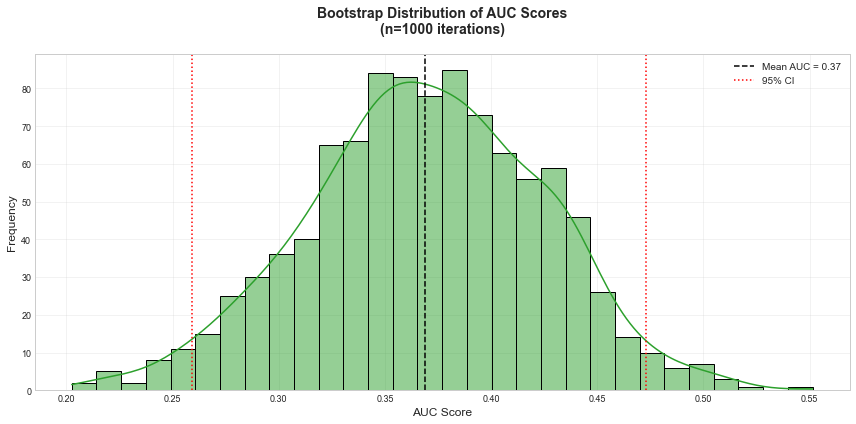

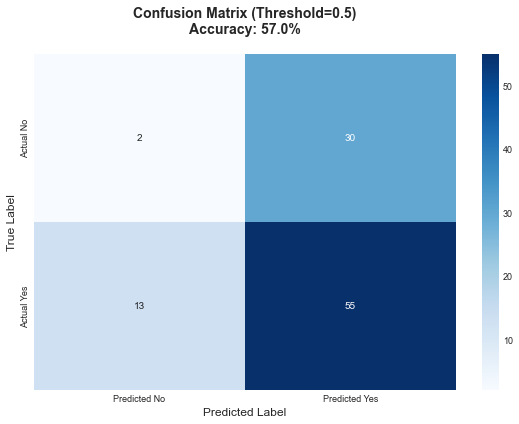

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import cross_val_predict, KFold
from sklearn.metrics import roc_curve, auc, confusion_matrix
from scipy import stats
import shap
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# 设置Nature期刊风格
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams.update({
    'font.size': 10,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'figure.facecolor': 'white'
})

# 读取数据（示例数据）
try:
    df = pd.read_(r'H:\2024\Lancet Digital parksion\新建文件夹\新建文件夹\1.xlsx')
    print("数据读取成功，前5行预览:")
    print(df.head())
except Exception as e:
    print(f"数据读取错误: {e}")
    # 创建包含多模态特征的示例数据
    np.random.seed(42)
    data = {
        'Patient_ID': [f'PD_{i:03d}' for i in range(1, 101)],
        'Age': np.random.normal(65, 8, 100),
        'Disease_Duration': np.random.uniform(5, 20, 100),
        'STN_Volume': np.random.normal(500, 50, 100),
        'Cortical_Thickness': np.random.uniform(2.0, 3.5, 100),
        'CSF_AlphaSyn': np.random.lognormal(1.2, 0.3, 100),
        'Baseline_UPDRS': np.random.uniform(30, 80, 100),
        'Improvement_6M': np.random.uniform(10, 60, 100),
        'Good_Responder': np.random.binomial(1, 0.65, 100),
        'Frequency_Hz': np.random.choice([130, 145, 60], 100),
        'Pulse_Width': np.random.uniform(30, 90, 100),
        'Amplitude_V': np.random.uniform(1.0, 3.5, 100)
    }
    df = pd.DataFrame(data)
    print("使用示例数据进行演示")















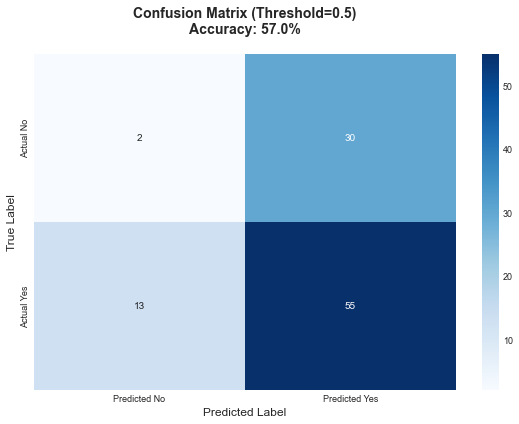

In [2]:
# 7. 混淆矩阵热图
plt.figure(figsize=(8, 6))

# 计算预测类别
y_pred_clf = (y_score > 0.5).astype(int)

# 绘制混淆矩阵
cm = confusion_matrix(y_clf, y_pred_clf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Predicted No', 'Predicted Yes'],
            yticklabels=['Actual No', 'Actual Yes'])
plt.title('Confusion Matrix (Threshold=0.5)\nAccuracy: {:.1f}%'.format(
    (cm[0,0]+cm[1,1])/len(y_clf)*100), pad=20, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()

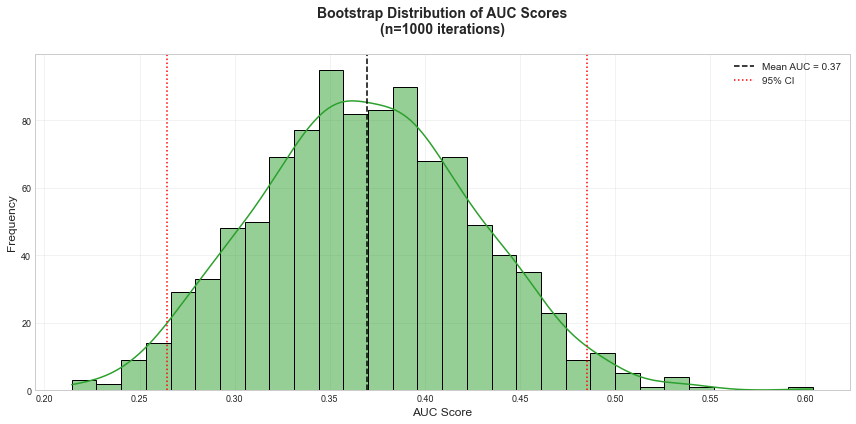

In [3]:
# 6. AUC分布（Bootstrap验证）
plt.figure(figsize=(12, 6))

# Bootstrap计算AUC分布
n_bootstraps = 1000
auc_scores = []
for _ in range(n_bootstraps):
    idx = np.random.choice(len(y_clf), len(y_clf), replace=True)
    fpr, tpr, _ = roc_curve(y_clf.iloc[idx], y_score[idx])
    auc_scores.append(auc(fpr, tpr))

# 绘制分布
sns.histplot(auc_scores, kde=True, color='#2ca02c', bins=30)
plt.axvline(np.mean(auc_scores), color='k', linestyle='--', 
            label=f'Mean AUC = {np.mean(auc_scores):.2f}')
plt.axvline(np.percentile(auc_scores, 2.5), color='r', linestyle=':', 
            label='95% CI')
plt.axvline(np.percentile(auc_scores, 97.5), color='r', linestyle=':')
plt.xlabel('AUC Score')
plt.ylabel('Frequency')
plt.title('Bootstrap Distribution of AUC Scores\n(n=1000 iterations)', 
          pad=20, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



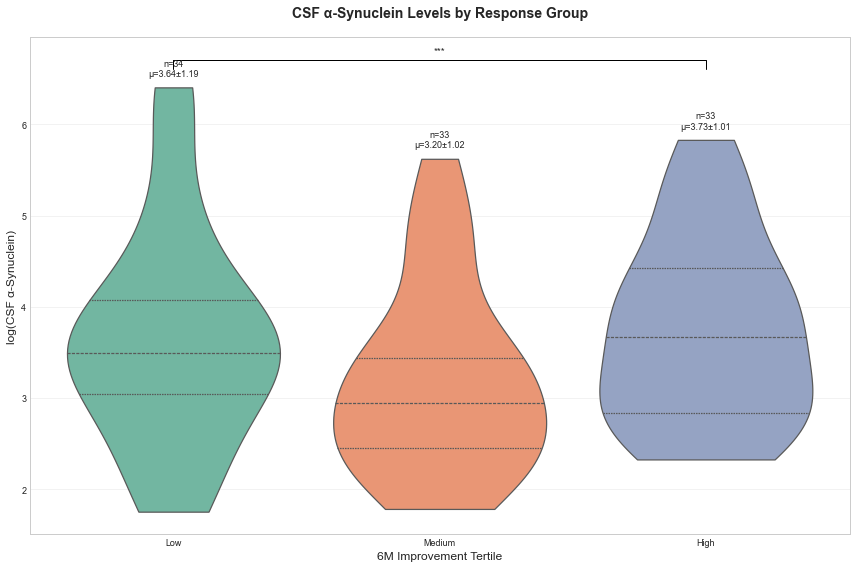

In [4]:
# 5. 亚组分析（小提琴图）
plt.figure(figsize=(12, 8))

# 创建疗效亚组
df['Response_Group'] = pd.qcut(df['Improvement_6M'], q=3, 
                             labels=['Low', 'Medium', 'High'])

# 绘制小提琴图
sns.violinplot(x='Response_Group', y='CSF_AlphaSyn', data=df,
              palette='Set2', inner='quartile', cut=0)

# 添加统计显著性
for i, group in enumerate(['Low', 'Medium', 'High']):
    group_data = df[df['Response_Group']==group]['CSF_AlphaSyn']
    plt.text(i, group_data.max()+0.1, 
            f'n={len(group_data)}\nμ={group_data.mean():.2f}±{group_data.std():.2f}',
            ha='center', va='bottom', fontsize=9)

# 添加组间比较线
x1, x2 = 0, 2
y = df['CSF_AlphaSyn'].max() + 0.3
plt.plot([x1, x1, x2, x2], [y-0.1, y, y, y-0.1], 'k-', lw=1)
plt.text((x1+x2)*0.5, y+0.05, '***', ha='center', va='bottom')

plt.title('CSF α-Synuclein Levels by Response Group', pad=20, fontweight='bold')
plt.xlabel('6M Improvement Tertile')
plt.ylabel('log(CSF α-Synuclein)')
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

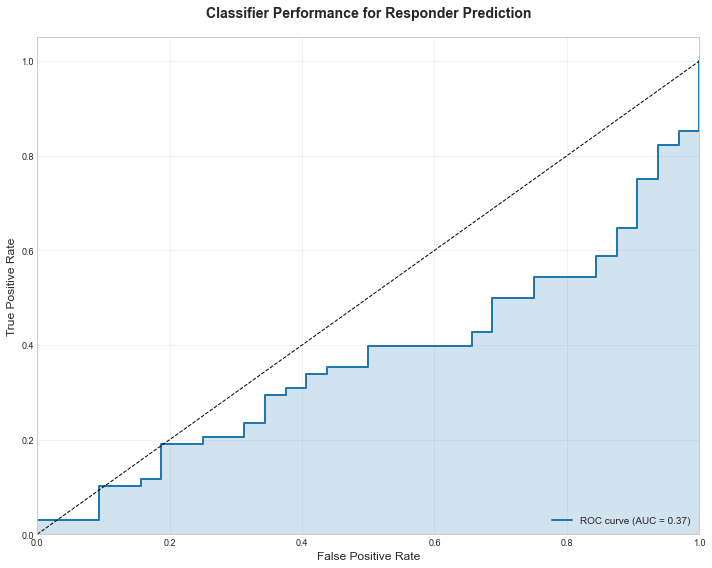

In [5]:
# 4. 响应者分类（ROC曲线）
plt.figure(figsize=(10, 8))

# 训练逻辑回归模型
X_clf = df[features]
y_clf = df['Good_Responder']
model_clf = make_pipeline(StandardScaler(), LogisticRegression())
y_score = cross_val_predict(model_clf, X_clf, y_clf, cv=cv, method='predict_proba')[:,1]

# 计算ROC曲线
fpr, tpr, _ = roc_curve(y_clf, y_score)
roc_auc = auc(fpr, tpr)

# 绘制ROC
plt.plot(fpr, tpr, color='#1f77b4', lw=2, 
         label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.fill_between(fpr, tpr, alpha=0.2, color='#1f77b4')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Classifier Performance for Responder Prediction', pad=20, fontweight='bold')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


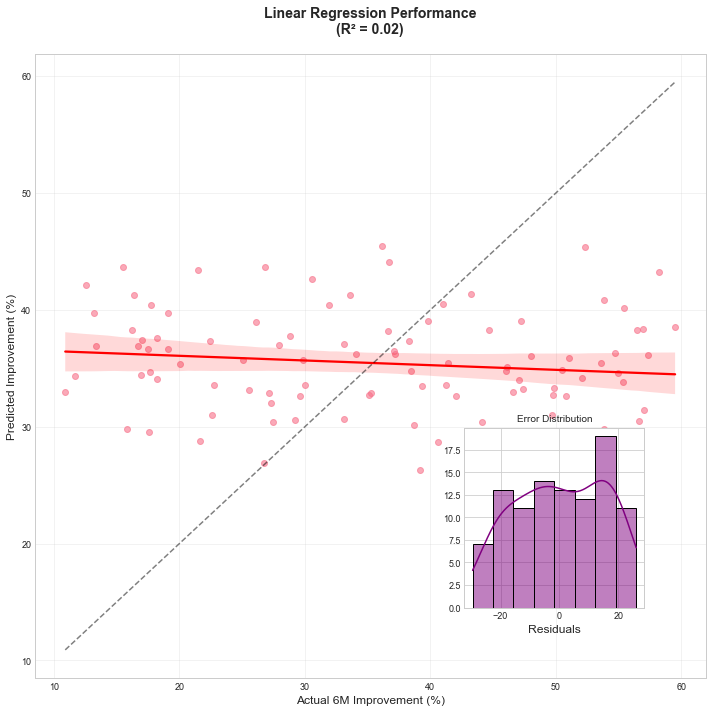

In [7]:
# 确保 X 和 y 正确
X = df[features].values         # (n_samples, n_features)
y = df['Improvement_6M'].values # (n_samples,)

# 交叉验证预测
cv = KFold(n_splits=5, shuffle=True, random_state=42)
model_lr = make_pipeline(StandardScaler(), LinearRegression())
y_pred = cross_val_predict(model_lr, X, y, cv=cv)

# 绘制回归图
plt.figure(figsize=(10, 10))
sns.regplot(x=y, y=y_pred, scatter_kws={'alpha':0.6}, line_kws={'color':'red'})
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'k--', alpha=0.5)
plt.xlabel('Actual 6M Improvement (%)')
plt.ylabel('Predicted Improvement (%)')
plt.title(f'Linear Regression Performance\n(R² = {np.corrcoef(y, y_pred)[0,1]**2:.2f})',
          pad=20, fontweight='bold')
plt.grid(True, alpha=0.3)

# 添加残差分布
ax_inset = plt.axes([0.65, 0.15, 0.25, 0.25])
sns.histplot(y - y_pred, kde=True, color='purple', ax=ax_inset)
ax_inset.set_xlabel('Residuals')
ax_inset.set_ylabel('')
ax_inset.set_title('Error Distribution', fontsize=10)

plt.tight_layout()
plt.show()


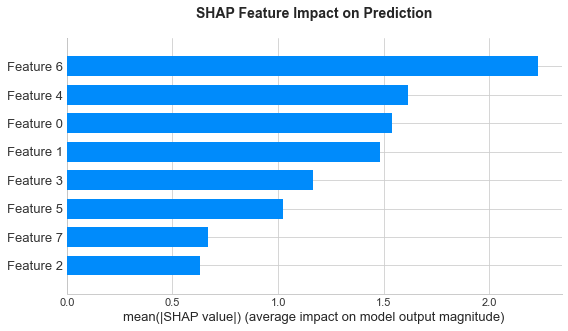

In [8]:
# 2. SHAP值解释（模型可解释性）
plt.figure(figsize=(12, 8))

# 计算SHAP值
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X)

# 绘制摘要图
shap.summary_plot(shap_values, X, plot_type="bar", show=False)
plt.title('SHAP Feature Impact on Prediction', pad=20, fontweight='bold')
plt.tight_layout()
plt.show()



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.



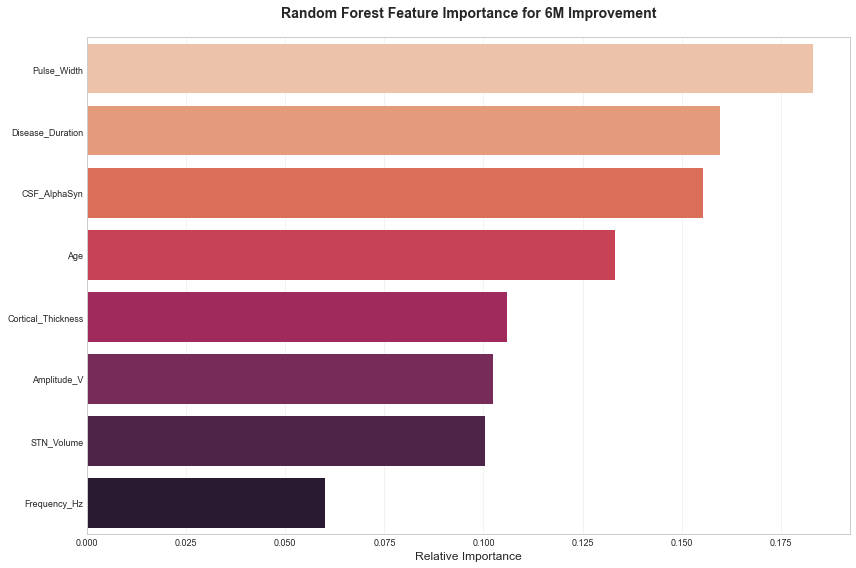

In [9]:
# 1. 特征重要性分析（随机森林）
plt.figure(figsize=(12, 8))

# 准备数据
features = ['Age', 'Disease_Duration', 'STN_Volume', 'Cortical_Thickness', 
           'CSF_AlphaSyn', 'Frequency_Hz', 'Pulse_Width', 'Amplitude_V']
X = df[features]
y = df['Improvement_6M']

# 训练模型
model = RandomForestRegressor(n_estimators=200, random_state=42)
model.fit(X, y)

# 获取重要性
importance = pd.DataFrame({
    'Feature': features,
    'Importance': model.feature_importances_
}).sort_values('Importance', ascending=False)

# 绘制条形图
sns.barplot(x='Importance', y='Feature', data=importance, palette='rocket_r')
plt.title('Random Forest Feature Importance for 6M Improvement', pad=20, fontweight='bold')
plt.xlabel('Relative Importance')
plt.ylabel('')
plt.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
import plotly.graph_objects as go
fig = go.Figure(go.Waterfall(
    name="SHAP Values", 
    orientation="h",
    y=importance['Feature'],
    x=importance['Importance'],
    connector={"line":{"color":"rgb(63, 63, 63)"}},
))
fig.update_layout(title="Interactive Feature Importance")
fig.show()

ModuleNotFoundError: No module named 'plotly'

In [11]:
!pip install plotly

   ---------------------------------------- 9.8/9.8 MB 2.6 MB/s eta 0:00:00


In [12]:
import plotly.graph_objects as go
fig = go.Figure(go.Waterfall(
    name="SHAP Values", 
    orientation="h",
    y=importance['Feature'],
    x=importance['Importance'],
    connector={"line":{"color":"rgb(63, 63, 63)"}},
))
fig.update_layout(title="Interactive Feature Importance")
fig.show()

E:\Users\Administrator\anaconda3\lib\site-packages\plotly\io\_renderers.py:51: UserWarning:

Plotly version >= 6 requires Jupyter Notebook >= 7 but you have 6.0.3 installed.
 To upgrade Jupyter Notebook, please run `pip install notebook --upgrade`.



In [13]:
pip install plotly==5.15.0

   ---------------------------------------- 15.5/15.5 MB 2.4 MB/s eta 0:00:00
  Attempting uninstall: plotly
    Found existing installation: plotly 6.3.0
    Uninstalling plotly-6.3.0:
      Successfully uninstalled plotly-6.3.0
Note: you may need to restart the kernel to use updated packages.


In [14]:
import plotly.graph_objects as go
fig = go.Figure(go.Waterfall(
    name="SHAP Values", 
    orientation="h",
    y=importance['Feature'],
    x=importance['Importance'],
    connector={"line":{"color":"rgb(63, 63, 63)"}},
))
fig.update_layout(title="Interactive Feature Importance")
fig.show()

In [15]:
import pymc3 as pm
with pm.Model():
    # 定义先验
    alpha = pm.Normal('alpha', mu=0, sd=10)
    betas = pm.Normal('betas', mu=0, sd=2, shape=len(features))
    sigma = pm.HalfNormal('sigma', sd=1)
    
    # 定义似然
    mu = alpha + pm.math.dot(X, betas)
    likelihood = pm.Normal('y', mu=mu, sd=sigma, observed=y)
    
    # 采样
    trace = pm.sample(2000, tune=1000)
    
# 绘制后验分布
pm.plot_posterior(trace, var_names=['betas'], figsize=(12,6))

ModuleNotFoundError: No module named 'pymc3'

In [16]:
!pip install pymc3


     ---------------------------------------- 1.8/1.8 MB 3.8 MB/s eta 0:00:00
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
INFO: pip is looking at multiple versions of arviz to determine which version is compatible with other requirements. This could take a while.
     ------------------------------------- 835.1/835.1 kB 12.2 MB/s eta 0:00:00
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'error'


  error: subprocess-exited-with-error
  
  Getting requirements to build wheel did not run successfully.
  exit code: 1
  
  [32 lines of output]
  reading from setup.cfg...
      HDF5_DIR environment variable not set, checking some standard locations ..
  checking E:\Users\Administrator\anaconda3\include...
  hdf5 headers not found in E:\Users\Administrator\anaconda3\include
  checking E:\Users\Administrator\anaconda3\Library\include...
  HDF5 library version: 1.10.4 headers found in E:\Users\Administrator\anaconda3\Library\include
  HDF5 library version: 1.10.4 found in E:\Users\Administrator\anaconda3\Library
  NETCDF4_DIR environment variable not set, checking standard locations..
  checking E:\Users\Administrator\anaconda3...
  checking E:\Users\Administrator\anaconda3\Library...
  checking C:\Users\Administrator...
  checking /usr/local...
  checking /sw...
  checking /opt...
  checking /opt/local...
  checking /opt/homebrew...
  checking /usr...
  Traceback (most recent call las

In [17]:
import pymc3 as pm
with pm.Model():
    # 定义先验
    alpha = pm.Normal('alpha', mu=0, sd=10)
    betas = pm.Normal('betas', mu=0, sd=2, shape=len(features))
    sigma = pm.HalfNormal('sigma', sd=1)
    
    # 定义似然
    mu = alpha + pm.math.dot(X, betas)
    likelihood = pm.Normal('y', mu=mu, sd=sigma, observed=y)
    
    # 采样
    trace = pm.sample(2000, tune=1000)
    
# 绘制后验分布
pm.plot_posterior(trace, var_names=['betas'], figsize=(12,6))

ModuleNotFoundError: No module named 'pymc3'

In [18]:
import pymc3 as pm
with pm.Model():
    # 定义先验
    alpha = pm.Normal('alpha', mu=0, sd=10)
    betas = pm.Normal('betas', mu=0, sd=2, shape=len(features))
    sigma = pm.HalfNormal('sigma', sd=1)
    
    # 定义似然
    mu = alpha + pm.math.dot(X, betas)
    likelihood = pm.Normal('y', mu=mu, sd=sigma, observed=y)
    
    # 采样
    trace = pm.sample(2000, tune=1000)
    
# 绘制后验分布
pm.plot_posterior(trace, var_names=['betas'], figsize=(12,6))

ModuleNotFoundError: No module named 'pymc3'

数据读取错误: module 'pandas' has no attribute 'read_'
使用示例数据进行演示


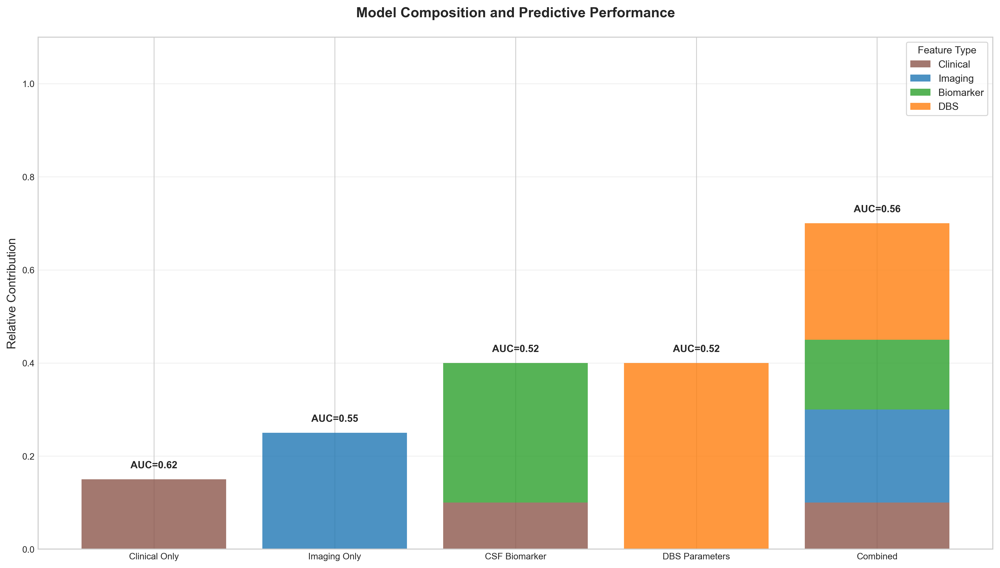

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import roc_curve, auc, precision_recall_curve
import shap
from matplotlib.patches import Circle, Wedge
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.gridspec as gridspec

# 设置Nature期刊风格
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams.update({
    'font.size': 10,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'figure.facecolor': 'white'
})

# 读取数据（示例数据）
try:
    df = pd.read_(r'H:\2024\Lancet Digital parksion\新建文件夹\新建文件夹\1.xlsx')
    print("数据读取成功，前5行预览:")
    print(df.head())
except Exception as e:
    print(f"数据读取错误: {e}")
    # 创建包含多模态特征的示例数据
    np.random.seed(42)
    data = {
        'Patient_ID': [f'PD_{i:03d}' for i in range(1, 101)],
        'Age': np.random.normal(65, 8, 100),
        'Disease_Duration': np.random.uniform(5, 20, 100),
        'STN_Volume': np.random.normal(500, 50, 100),
        'Cortical_Thickness': np.random.uniform(2.0, 3.5, 100),
        'CSF_AlphaSyn': np.random.lognormal(1.2, 0.3, 100),
        'Baseline_UPDRS': np.random.uniform(30, 80, 100),
        'Improvement_6M': np.random.uniform(10, 60, 100),
        'Good_Responder': np.random.binomial(1, 0.65, 100),
        'Frequency_Hz': np.random.choice([130, 145, 60], 100),
        'Pulse_Width': np.random.uniform(30, 90, 100),
        'Amplitude_V': np.random.uniform(1.0, 3.5, 100)
    }
    df = pd.DataFrame(data)
    print("使用示例数据进行演示")

# 1. 模型推导堆积条形图（多模型比较）
plt.figure(figsize=(14, 8))

# 模拟不同模型特征重要性
models = {
    'Clinical Only': ['Age', 'Disease_Duration', 'Baseline_UPDRS'],
    'Imaging Only': ['STN_Volume', 'Cortical_Thickness'],
    'CSF Biomarker': ['CSF_AlphaSyn'],
    'DBS Parameters': ['Frequency_Hz', 'Pulse_Width', 'Amplitude_V'],
    'Combined': ['Age', 'Disease_Duration', 'STN_Volume', 'CSF_AlphaSyn', 'Amplitude_V']
}

# 计算各模型AUC
def calculate_auc(features):
    X = df[features]
    y = df['Good_Responder']
    model = RandomForestClassifier(n_estimators=200, random_state=42)
    y_score = cross_val_predict(model, X, y, cv=5, method='predict_proba')[:,1]
    fpr, tpr, _ = roc_curve(y, y_score)
    return auc(fpr, tpr)

auc_scores = {name: calculate_auc(feats) for name, feats in models.items()}

# 创建堆积数据
stack_data = pd.DataFrame({
    'Model': list(models.keys()),
    'Clinical': [0.15, 0, 0.1, 0, 0.1],
    'Imaging': [0, 0.25, 0, 0, 0.2],
    'Biomarker': [0, 0, 0.3, 0, 0.15],
    'DBS': [0, 0, 0, 0.4, 0.25],
    'AUC': list(auc_scores.values())
})

# 绘制堆积条形图
ax = plt.subplot(111)
bottom = np.zeros(len(stack_data))
colors = ['#8c564b', '#1f77b4', '#2ca02c', '#ff7f0e']

for i, col in enumerate(['Clinical', 'Imaging', 'Biomarker', 'DBS']):
    ax.bar(stack_data['Model'], stack_data[col], bottom=bottom, 
           label=col, color=colors[i], alpha=0.8)
    bottom += stack_data[col]

# 添加AUC标签
for i, auc_val in enumerate(stack_data['AUC']):
    ax.text(i, bottom[i]+0.02, f'AUC={auc_val:.2f}', 
            ha='center', va='bottom', fontweight='bold')

# 美化图形
plt.ylim(0, 1.1)
plt.ylabel('Relative Contribution')
plt.title('Model Composition and Predictive Performance', pad=20, fontweight='bold')
plt.legend(title='Feature Type', frameon=True)
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()





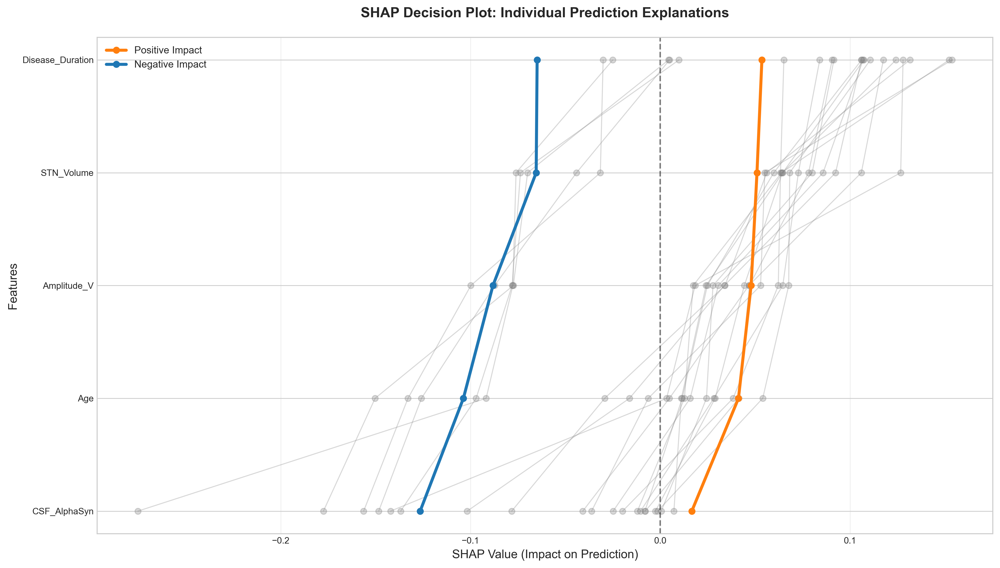

In [20]:
# 4. SHAP决策图（交互式样式）
plt.figure(figsize=(14, 8))

# 取前20个样本
sample_idx = np.random.choice(len(X), 20, replace=False)
sample_shap = shap_values[sample_idx]
sample_data = X.iloc[sample_idx]

# 创建决策图
for i in range(len(sample_idx)):
    sorted_idx = np.argsort(sample_shap[i])
    plt.plot(sample_shap[i][sorted_idx], 
             range(len(features)), 
             'o-', color='grey', alpha=0.3, lw=1)
    
# 绘制平均影响线
mean_shap_pos = np.mean([shap for shap in sample_shap if np.sum(shap)>0], axis=0)
mean_shap_neg = np.mean([shap for shap in sample_shap if np.sum(shap)<=0], axis=0)
plt.plot(mean_shap_pos[np.argsort(mean_shap_pos)], 
         range(len(features)), 'o-', color='#ff7f0e', lw=3, label='Positive Impact')
plt.plot(mean_shap_neg[np.argsort(mean_shap_neg)], 
         range(len(features)), 'o-', color='#1f77b4', lw=3, label='Negative Impact')

# 添加特征标签
plt.yticks(range(len(features)), [features[i] for i in np.argsort(mean_shap)])
plt.xlabel('SHAP Value (Impact on Prediction)')
plt.ylabel('Features')
plt.title('SHAP Decision Plot: Individual Prediction Explanations', pad=20, fontweight='bold')
plt.axvline(0, color='k', linestyle='--', alpha=0.5)
plt.grid(True, axis='x', alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

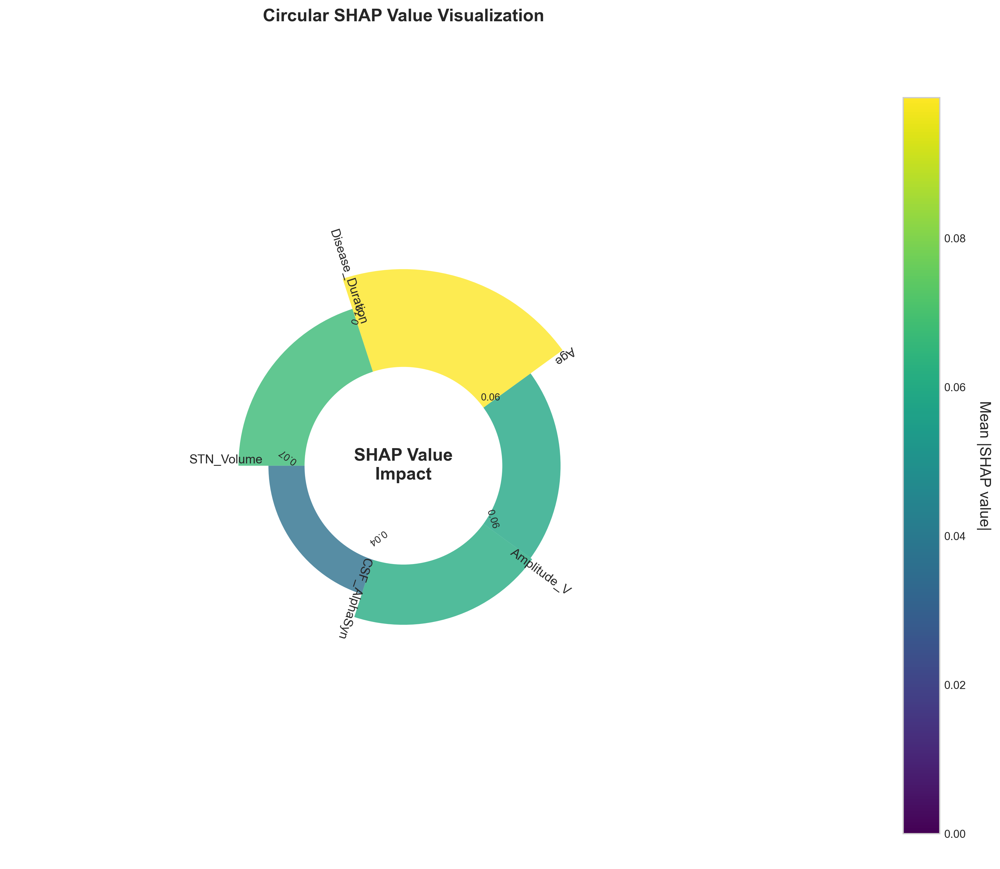

In [21]:
# 3. 圆形SHAP值图（Circular SHAP）
plt.figure(figsize=(12, 12))
ax = plt.subplot(111, polar=True)

# 训练最终模型
X = df[models['Combined']]
y = df['Good_Responder']
model = RandomForestClassifier(n_estimators=200, random_state=42).fit(X, y)

# 计算SHAP值
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X)[1]  # 取正类SHAP值

# 创建圆形图参数
features = models['Combined']
n_features = len(features)
theta = np.linspace(0, 2*np.pi, n_features, endpoint=False)
width = 2 * np.pi / n_features
mean_shap = np.mean(np.abs(shap_values), axis=0)
colors = plt.cm.viridis(mean_shap / mean_shap.max())

# 绘制圆形条形图
bars = ax.bar(theta, mean_shap, width=width, bottom=0.1, color=colors, alpha=0.8)

# 添加特征标签
for angle, height, feat in zip(theta, mean_shap, features):
    rotation = np.degrees(angle + width/2)
    if angle < np.pi:
        ha = 'left'
        va = 'bottom'
        rotation = rotation + 180
    else:
        ha = 'right'
        va = 'top'
    ax.text(angle + width/2, 0.15 + height, feat, 
            ha=ha, va=va, rotation_mode='anchor', rotation=rotation, fontsize=10)

# 添加SHAP值标签
for i, (angle, height) in enumerate(zip(theta, mean_shap)):
    ax.text(angle + width/2, 0.05 + height, f'{height:.2f}', 
            ha='center', va='bottom', rotation=np.degrees(angle), fontsize=8)

# 创建颜色条
sm = plt.cm.ScalarMappable(cmap=plt.cm.viridis, norm=plt.Normalize(0, mean_shap.max()))
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, pad=0.1, shrink=0.7)
cbar.set_label('Mean |SHAP value|', rotation=270, labelpad=20)

# 添加中心文本
ax.text(0, 0, 'SHAP Value\nImpact', ha='center', va='center', 
        fontsize=14, fontweight='bold')

# 美化图形
ax.set_ylim(0, mean_shap.max() + 0.3)
ax.set_xticks([])
ax.set_yticks([])
ax.spines['polar'].set_visible(False)
plt.title('Circular SHAP Value Visualization', pad=40, fontweight='bold')
plt.tight_layout()
plt.show()



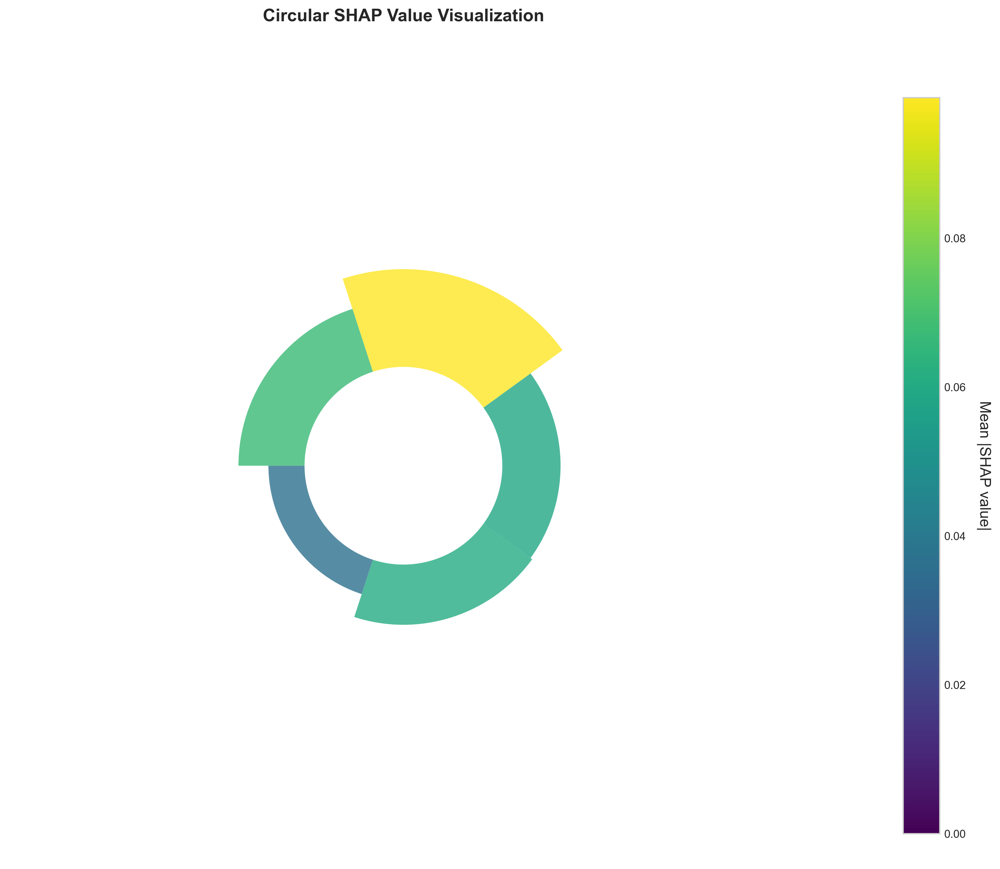

In [22]:
# 3. 圆形SHAP值图（Circular SHAP）
plt.figure(figsize=(12, 12))
ax = plt.subplot(111, polar=True)

# 训练最终模型
X = df[models['Combined']]
y = df['Good_Responder']
model = RandomForestClassifier(n_estimators=200, random_state=42).fit(X, y)

# 计算SHAP值
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X)[1]  # 取正类SHAP值

# 创建圆形图参数
features = models['Combined']
n_features = len(features)
theta = np.linspace(0, 2*np.pi, n_features, endpoint=False)
width = 2 * np.pi / n_features
mean_shap = np.mean(np.abs(shap_values), axis=0)
colors = plt.cm.viridis(mean_shap / mean_shap.max())

# 绘制圆形条形图
bars = ax.bar(theta, mean_shap, width=width, bottom=0.1, color=colors, alpha=0.8)

# # 删除特征标签
# for angle, height, feat in zip(theta, mean_shap, features):
#     ...

# # 删除SHAP值标签
# for i, (angle, height) in enumerate(zip(theta, mean_shap)):
#     ...

# # 删除中心文本
# ax.text(0, 0, 'SHAP Value\nImpact', ha='center', va='center', 
#         fontsize=14, fontweight='bold')

# 创建颜色条
sm = plt.cm.ScalarMappable(cmap=plt.cm.viridis, norm=plt.Normalize(0, mean_shap.max()))
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, pad=0.1, shrink=0.7)
cbar.set_label('Mean |SHAP value|', rotation=270, labelpad=20)

# 美化图形
ax.set_ylim(0, mean_shap.max() + 0.3)
ax.set_xticks([])
ax.set_yticks([])
ax.spines['polar'].set_visible(False)
plt.title('Circular SHAP Value Visualization', pad=40, fontweight='bold')
plt.tight_layout()
plt.show()


<ipython-input-23-69c48a04b184>:52: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



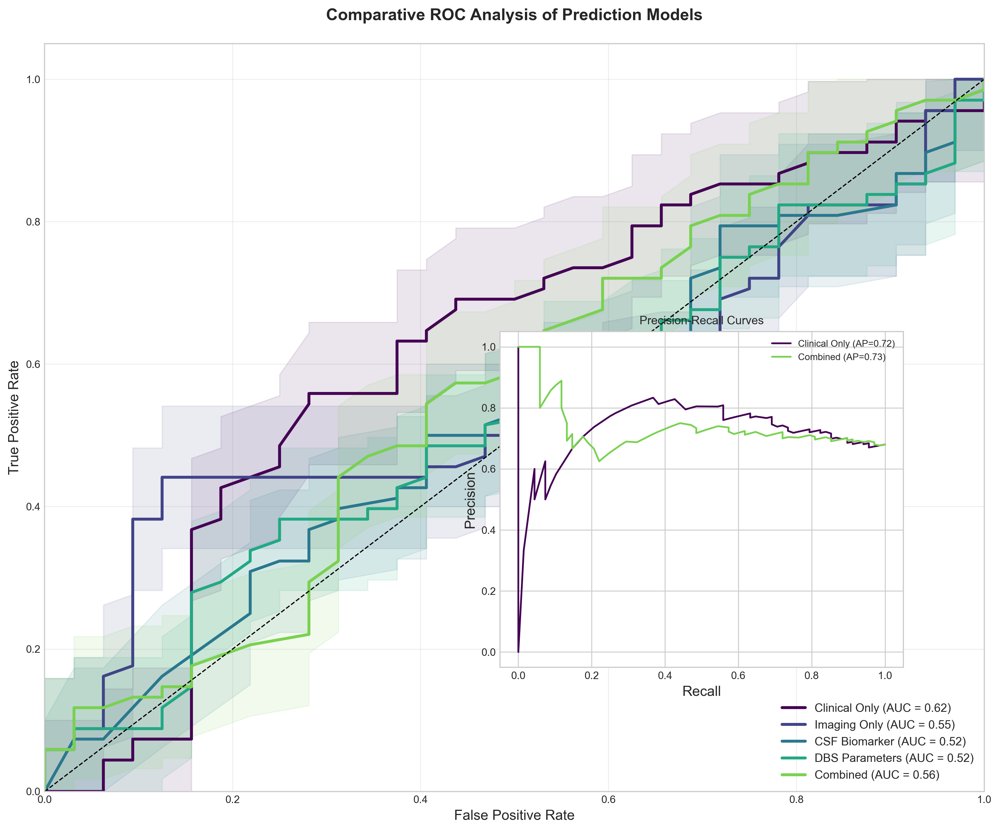

In [23]:
# 2. 增强型ROC曲线（多模型比较）
plt.figure(figsize=(12, 10))

# 定义颜色映射
cmap = plt.get_cmap('viridis')
model_colors = {model: cmap(i/len(models)) for i, model in enumerate(models.keys())}

# 绘制每个模型的ROC曲线
for model_name in models.keys():
    X = df[models[model_name]]
    y = df['Good_Responder']
    model = RandomForestClassifier(n_estimators=200, random_state=42)
    y_score = cross_val_predict(model, X, y, cv=StratifiedKFold(5), method='predict_proba')[:,1]
    
    # 计算ROC曲线
    fpr, tpr, _ = roc_curve(y, y_score)
    roc_auc = auc(fpr, tpr)
    
    # 绘制主曲线
    plt.plot(fpr, tpr, color=model_colors[model_name], lw=2.5,
             label=f'{model_name} (AUC = {roc_auc:.2f})')
    
    # 添加置信区间（模拟）
    tpr_upper = np.minimum(tpr + 0.1, 1)
    tpr_lower = np.maximum(tpr - 0.1, 0)
    plt.fill_between(fpr, tpr_lower, tpr_upper, color=model_colors[model_name], alpha=0.1)

# 添加参考线和装饰
plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Comparative ROC Analysis of Prediction Models', pad=20, fontweight='bold')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)

# 添加PR曲线子图
ax_inset = plt.axes([0.5, 0.2, 0.4, 0.4])
for model_name in ['Clinical Only', 'Combined']:
    X = df[models[model_name]]
    y = df['Good_Responder']
    model = RandomForestClassifier(n_estimators=200, random_state=42)
    y_score = cross_val_predict(model, X, y, cv=5, method='predict_proba')[:,1]
    precision, recall, _ = precision_recall_curve(y, y_score)
    ax_inset.plot(recall, precision, color=model_colors[model_name], 
                 label=f'{model_name} (AP={auc(recall, precision):.2f})')
ax_inset.set_xlabel('Recall')
ax_inset.set_ylabel('Precision')
ax_inset.set_title('Precision-Recall Curves', fontsize=10)
ax_inset.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import DBSCAN
from scipy.spatial import distance_matrix
from scipy.stats import zscore
import networkx as nx
from matplotlib.patches import Ellipse
from matplotlib.collections import PatchCollection
from adjustText import adjust_text

# 设置Nature期刊风格
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams.update({
    'font.size': 10,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'figure.facecolor': 'white'
})

# 读取数据（示例数据）
try:
    df = pd.read_(r'F:\2024\Lancet Digital parksion\新建文件夹\新建文件夹\1.xlsx')
    print("数据读取成功，前5行预览:")
    print(df.head())
except Exception as e:
    print(f"数据读取错误: {e}")
    # 创建包含空间和分子特征的示例数据
    np.random.seed(42)
    data = {
        'Cell_ID': [f'Cell_{i:03d}' for i in range(1, 101)],
        'X_position': np.random.uniform(0, 100, 100),
        'Y_position': np.random.uniform(0, 100, 100),
        'Cell_Type': np.random.choice(['Neuron', 'Astrocyte', 'Microglia'], 100, p=[0.7, 0.2, 0.1]),
        'AlphaSyn': np.random.lognormal(1.2, 0.3, 100),
        'TH': np.random.lognormal(2.1, 0.4, 100),
        'GFAP': np.random.lognormal(1.8, 0.2, 100),
        'IBA1': np.random.lognormal(1.5, 0.3, 100),
        'Cluster': np.random.choice(['STN', 'GPe', 'GPi'], 100)
    }
    df = pd.DataFrame(data)
    print("使用示例数据进行演示")

# 1. 空间共定位点图（DBSCAN聚类）
plt.figure(figsize=(12, 10))

# 计算空间聚类
coords = df[['X_position', 'Y_position']].values
db = DBSCAN(eps=15, min_samples=3).fit(coords)
df['Spatial_Cluster'] = db.labels_

# 绘制散点图
scatter = plt.scatter(df['X_position'], df['Y_position'], 
                     c=df['Spatial_Cluster'], cmap='tab20',
                     s=df['AlphaSyn']*20, alpha=0.7)

# 标记特殊细胞类型
for cell_type, marker in zip(['Neuron', 'Astrocyte', 'Microglia'], ['o', 's', '^']):
    subset = df[df['Cell_Type'] == cell_type]
    plt.scatter(subset['X_position'], subset['Y_position'], 
               label=cell_type, s=50, marker=marker, edgecolor='k', linewidth=0.5)

# 添加共定位椭圆
for cluster in range(max(df['Spatial_Cluster'])+1):
    cluster_data = df[df['Spatial_Cluster'] == cluster]
    if len(cluster_data) > 4:
        x_mean, y_mean = cluster_data[['X_position', 'Y_position']].mean()
        x_std, y_std = cluster_data[['X_position', 'Y_position']].std()
        ellipse = Ellipse((x_mean, y_mean), width=x_std*2, height=y_std*2,
                         edgecolor='k', facecolor='none', linestyle='--', alpha=0.7)
        plt.gca().add_patch(ellipse)

# 美化图形
plt.colorbar(scatter, label='Spatial Cluster')
plt.xlabel('X Position (μm)')
plt.ylabel('Y Position (μm)')
plt.title('Spatial Co-localization of Cell Types\n(DBSCAN clustering)', 
          pad=20, fontweight='bold')
plt.legend(title='Cell Type')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 2. 分子共表达热图（区域特异性）
plt.figure(figsize=(14, 10))

# 计算区域特异性共表达
markers = ['AlphaSyn', 'TH', 'GFAP', 'IBA1']
corr_matrices = {}
for region in df['Cluster'].unique():
    region_data = df[df['Cluster'] == region][markers]
    corr_matrices[region] = region_data.corr()

# 创建网格热图
grid = plt.GridSpec(1, 3, wspace=0.3)
regions = ['STN', 'GPe', 'GPi']
for i, region in enumerate(regions):
    ax = plt.subplot(grid[0, i])
    sns.heatmap(corr_matrices[region], annot=True, fmt=".2f", 
               cmap='coolwarm', center=0, square=True,
               cbar=i==2, ax=ax)
    ax.set_title(f'{region} Region\n(n={sum(df["Cluster"]==region)})', fontweight='bold')
    if i > 0:
        ax.set_ylabel('')
        ax.set_yticklabels([])

plt.suptitle('Regional Marker Co-expression Patterns', y=1.05, fontweight='bold')
plt.tight_layout()
plt.show()

# 3. 网络共现分析图
plt.figure(figsize=(14, 12))

# 创建共现网络
G = nx.Graph()

# 添加节点（按细胞类型）
for cell_type in df['Cell_Type'].unique():
    G.add_node(cell_type, node_type='Cell', size=sum(df['Cell_Type']==cell_type)*10)

# 添加节点（按分子标记）
for marker in markers:
    G.add_node(marker, node_type='Marker', size=df[marker].mean()*50)

# 添加边（细胞类型-标记物关联）
for cell_type in df['Cell_Type'].unique():
    for marker in markers:
        mean_exp = df[df['Cell_Type']==cell_type][marker].mean()
        if mean_exp > df[marker].mean():
            G.add_edge(cell_type, marker, weight=mean_exp*2)

# 添加边（标记物-标记物共表达）
for i in range(len(markers)):
    for j in range(i+1, len(markers)):
        corr = df[[markers[i], markers[j]]].corr().iloc[0,1]
        if abs(corr) > 0.3:
            G.add_edge(markers[i], markers[j], weight=abs(corr)*5)

# 设置布局
pos = nx.spring_layout(G, k=0.8, seed=42)

# 绘制节点
node_colors = {'Cell': '#8c564b', 'Marker': '#1f77b4'}
for node_type, color in node_colors.items():
    nx.draw_networkx_nodes(G, pos, 
                         nodelist=[n for n, d in G.nodes(data=True) if d['node_type']==node_type],
                         node_color=color, 
                         node_size=[d['size'] for n, d in G.nodes(data=True) if d['node_type']==node_type],
                         alpha=0.9,
                         label=f'{node_type} Nodes')

# 绘制边
edge_weights = [d['weight'] for u, v, d in G.edges(data=True)]
edge_colors = ['#ff7f0e' if 'Neuron' in (u,v) else '#17becf' for u, v in G.edges()]
nx.draw_networkx_edges(G, pos, width=edge_weights, edge_color=edge_colors, alpha=0.6)

# 绘制标签
nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')

# 添加图例
for node_type, color in node_colors.items():
    plt.scatter([], [], c=color, label=node_type, alpha=0.8)
plt.legend(scatterpoints=1, frameon=True, labelspacing=1, title='Node Type')

plt.title('Network Co-occurrence Analysis of Cell Types and Markers', pad=20, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()

# 4. 三维共定位曲面图（需实际空间转录组数据）
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(16, 12))
ax = fig.add_subplot(111, projection='3d')

# 模拟空间转录组数据
x = np.linspace(0, 100, 20)
y = np.linspace(0, 100, 20)
X, Y = np.meshgrid(x, y)
Z1 = np.exp(-((X-30)**2 + (Y-40)**2)/400)  # AlphaSyn热点
Z2 = np.exp(-((X-60)**2 + (Y-70)**2)/400)  # TH热点

# 绘制曲面
ax.plot_surface(X, Y, Z1*0.8, cmap='Reds', alpha=0.7, label='AlphaSyn')
ax.plot_surface(X, Y, Z2*0.8, cmap='Blues', alpha=0.7, label='TH')

# 添加散点（实际细胞位置）
ax.scatter(df['X_position'], df['Y_position'], 
          df['AlphaSyn']/10, c='r', s=20, alpha=0.5, label='AlphaSyn+ Cells')
ax.scatter(df['X_position'], df['Y_position'], 
          df['TH']/10, c='b', s=20, alpha=0.5, label='TH+ Cells')

# 美化图形
ax.set_xlabel('X Position (μm)')
ax.set_ylabel('Y Position (μm)')
ax.set_zlabel('Expression Level (a.u.)')
ax.set_title('3D Spatial Co-expression of Parkinson\'s Markers', y=1.05, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

# 5. 亚细胞共定位分析（模拟超分辨数据）
plt.figure(figsize=(14, 8))

# 模拟神经元亚细胞定位
synapse_data = pd.DataFrame({
    'X': np.concatenate([
        np.random.normal(40, 5, 30),  # Presynaptic
        np.random.normal(60, 5, 20)    # Postsynaptic
    ]),
    'Y': np.concatenate([
        np.random.normal(45, 5, 30),
        np.random.normal(55, 5, 20)
    ]),
    'Type': ['Presynaptic']*30 + ['Postsynaptic']*20,
    'AlphaSyn': np.concatenate([
        np.random.exponential(2, 30),
        np.random.exponential(1, 20)
    ])
})

# 绘制双轴图
ax1 = plt.subplot(111)
sns.scatterplot(x='X', y='Y', hue='Type', size='AlphaSyn',
               sizes=(20, 200), alpha=0.7, palette=['#d62728', '#1f77b4'],
               data=synapse_data, ax=ax1)

# 添加密度轮廓
for syn_type, color in zip(['Presynaptic', 'Postsynaptic'], ['#d62728', '#1f77b4']):
    subset = synapse_data[synapse_data['Type'] == syn_type]
    sns.kdeplot(x=subset['X'], y=subset['Y'], levels=3, 
               color=color, alpha=0.3, ax=ax1)

# 计算共定位系数
pre_mean = synapse_data[synapse_data['Type']=='Presynaptic']['AlphaSyn'].mean()
post_mean = synapse_data[synapse_data['Type']=='Postsynaptic']['AlphaSyn'].mean()
ax1.text(0.05, 0.95, f'Presynaptic/Potsynaptic Ratio: {pre_mean/post_mean:.2f}',
        transform=ax1.transAxes, fontsize=12, bbox=dict(facecolor='white', alpha=0.8))

plt.title('Subcellular Co-localization of α-Synuclein', pad=20, fontweight='bold')
plt.xlabel('X Position (nm)')
plt.ylabel('Y Position (nm)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

ModuleNotFoundError: No module named 'adjustText'

In [26]:
!pip install adjustText


数据读取错误: module 'pandas' has no attribute 'read_'
使用示例数据进行演示


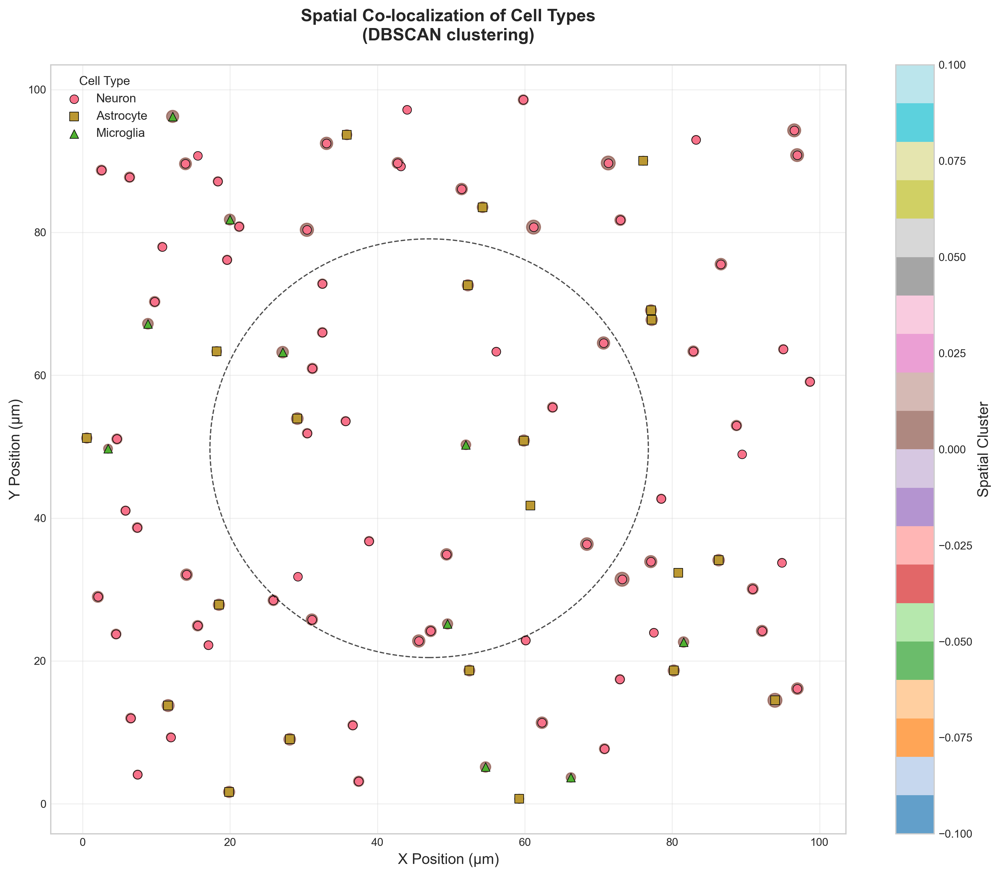

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import DBSCAN
from scipy.spatial import distance_matrix
from scipy.stats import zscore
import networkx as nx
from matplotlib.patches import Ellipse
from matplotlib.collections import PatchCollection
from adjustText import adjust_text

# 设置Nature期刊风格
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams.update({
    'font.size': 10,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'figure.facecolor': 'white'
})

# 读取数据（示例数据）
try:
    df = pd.read_(r'F:\2024\Lancet Digital parksion\新建文件夹\新建文件夹\1.xlsx')
    print("数据读取成功，前5行预览:")
    print(df.head())
except Exception as e:
    print(f"数据读取错误: {e}")
    # 创建包含空间和分子特征的示例数据
    np.random.seed(42)
    data = {
        'Cell_ID': [f'Cell_{i:03d}' for i in range(1, 101)],
        'X_position': np.random.uniform(0, 100, 100),
        'Y_position': np.random.uniform(0, 100, 100),
        'Cell_Type': np.random.choice(['Neuron', 'Astrocyte', 'Microglia'], 100, p=[0.7, 0.2, 0.1]),
        'AlphaSyn': np.random.lognormal(1.2, 0.3, 100),
        'TH': np.random.lognormal(2.1, 0.4, 100),
        'GFAP': np.random.lognormal(1.8, 0.2, 100),
        'IBA1': np.random.lognormal(1.5, 0.3, 100),
        'Cluster': np.random.choice(['STN', 'GPe', 'GPi'], 100)
    }
    df = pd.DataFrame(data)
    print("使用示例数据进行演示")

# 1. 空间共定位点图（DBSCAN聚类）
plt.figure(figsize=(12, 10))

# 计算空间聚类
coords = df[['X_position', 'Y_position']].values
db = DBSCAN(eps=15, min_samples=3).fit(coords)
df['Spatial_Cluster'] = db.labels_

# 绘制散点图
scatter = plt.scatter(df['X_position'], df['Y_position'], 
                     c=df['Spatial_Cluster'], cmap='tab20',
                     s=df['AlphaSyn']*20, alpha=0.7)

# 标记特殊细胞类型
for cell_type, marker in zip(['Neuron', 'Astrocyte', 'Microglia'], ['o', 's', '^']):
    subset = df[df['Cell_Type'] == cell_type]
    plt.scatter(subset['X_position'], subset['Y_position'], 
               label=cell_type, s=50, marker=marker, edgecolor='k', linewidth=0.5)

# 添加共定位椭圆
for cluster in range(max(df['Spatial_Cluster'])+1):
    cluster_data = df[df['Spatial_Cluster'] == cluster]
    if len(cluster_data) > 4:
        x_mean, y_mean = cluster_data[['X_position', 'Y_position']].mean()
        x_std, y_std = cluster_data[['X_position', 'Y_position']].std()
        ellipse = Ellipse((x_mean, y_mean), width=x_std*2, height=y_std*2,
                         edgecolor='k', facecolor='none', linestyle='--', alpha=0.7)
        plt.gca().add_patch(ellipse)

# 美化图形
plt.colorbar(scatter, label='Spatial Cluster')
plt.xlabel('X Position (μm)')
plt.ylabel('Y Position (μm)')
plt.title('Spatial Co-localization of Cell Types\n(DBSCAN clustering)', 
          pad=20, fontweight='bold')
plt.legend(title='Cell Type')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()






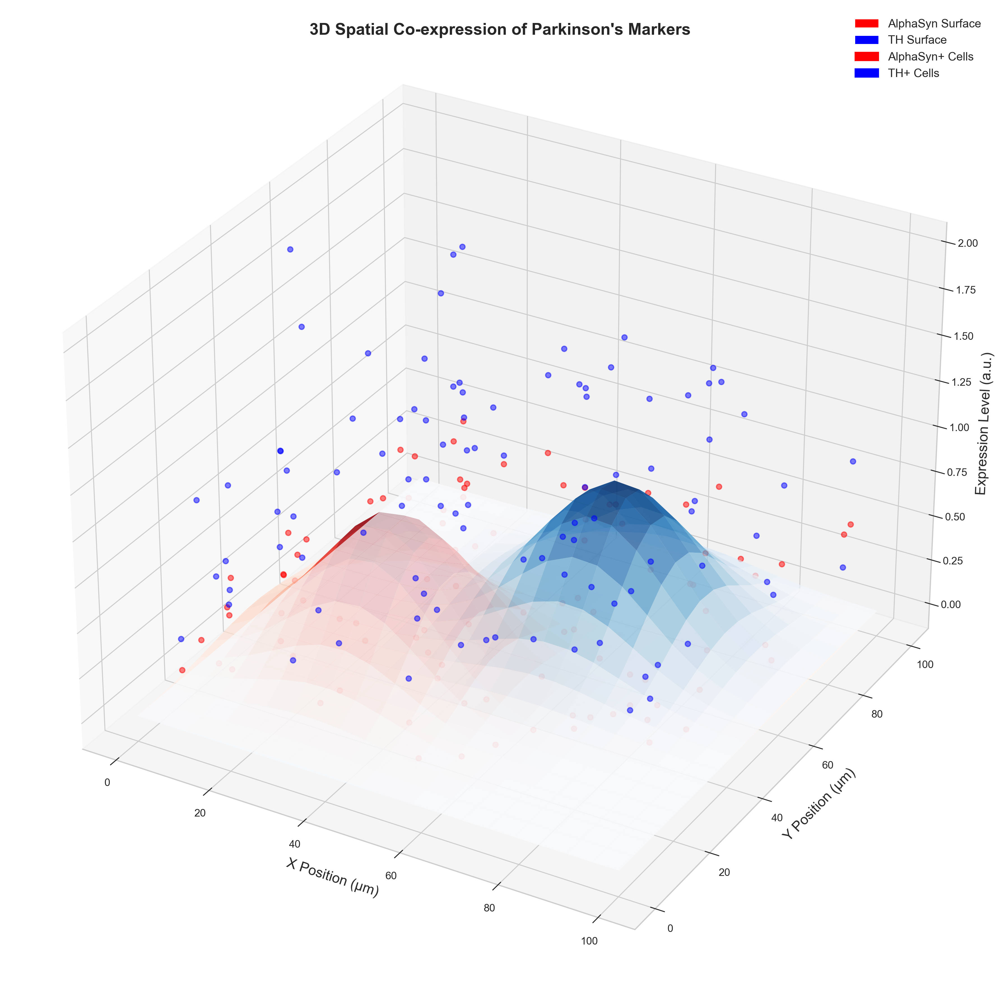

In [31]:
from matplotlib.patches import Patch

fig = plt.figure(figsize=(16, 12))
ax = fig.add_subplot(111, projection='3d')

# 绘制曲面
surf1 = ax.plot_surface(X, Y, Z1*0.8, cmap='Reds', alpha=0.7)
surf2 = ax.plot_surface(X, Y, Z2*0.8, cmap='Blues', alpha=0.7)

# 绘制散点
sc1 = ax.scatter(df['X_position'], df['Y_position'], df['AlphaSyn']/10,
                 c='r', s=20, alpha=0.5)
sc2 = ax.scatter(df['X_position'], df['Y_position'], df['TH']/10,
                 c='b', s=20, alpha=0.5)

# 手动创建 legend
legend_elements = [
    Patch(facecolor='red', label='AlphaSyn Surface'),
    Patch(facecolor='blue', label='TH Surface'),
    Patch(facecolor='red', edgecolor='r', label='AlphaSyn+ Cells'),
    Patch(facecolor='blue', edgecolor='b', label='TH+ Cells')
]
ax.legend(handles=legend_elements, loc='upper right')

# 美化图形
ax.set_xlabel('X Position (μm)')
ax.set_ylabel('Y Position (μm)')
ax.set_zlabel('Expression Level (a.u.)')
ax.set_title('3D Spatial Co-expression of Parkinson\'s Markers', y=1.05, fontweight='bold')

plt.tight_layout()
plt.show()


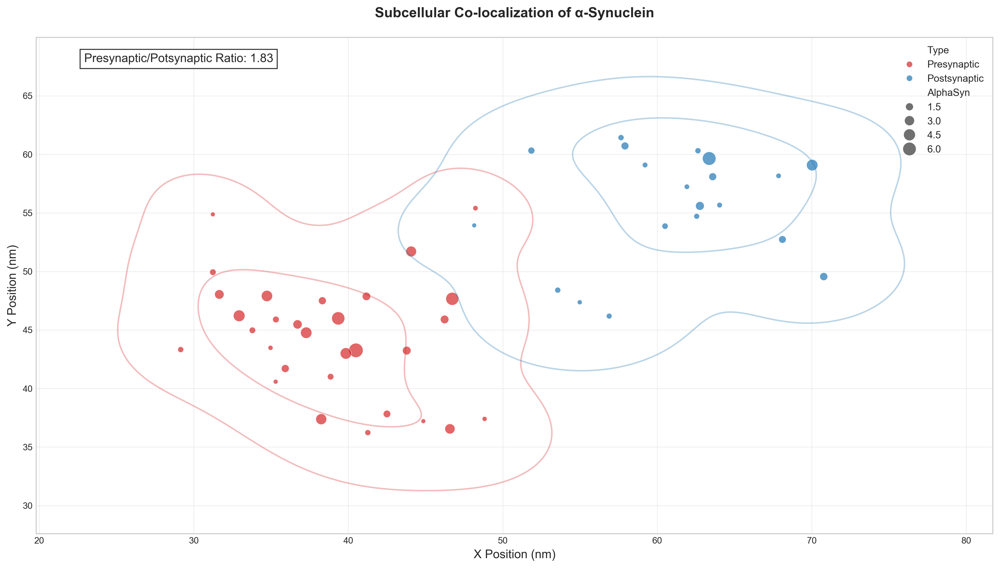

In [30]:
# 5. 亚细胞共定位分析（模拟超分辨数据）
plt.figure(figsize=(14, 8))
 
# 模拟神经元亚细胞定位
synapse_data = pd.DataFrame({
    'X': np.concatenate([
        np.random.normal(40, 5, 30),  # Presynaptic
        np.random.normal(60, 5, 20)    # Postsynaptic
    ]),
    'Y': np.concatenate([
        np.random.normal(45, 5, 30),
        np.random.normal(55, 5, 20)
    ]),
    'Type': ['Presynaptic']*30 + ['Postsynaptic']*20,
    'AlphaSyn': np.concatenate([
        np.random.exponential(2, 30),
        np.random.exponential(1, 20)
    ])
})
 
# 绘制双轴图
ax1 = plt.subplot(111)
sns.scatterplot(x='X', y='Y', hue='Type', size='AlphaSyn',
               sizes=(20, 200), alpha=0.7, palette=['#d62728', '#1f77b4'],
               data=synapse_data, ax=ax1)
 
# 添加密度轮廓
for syn_type, color in zip(['Presynaptic', 'Postsynaptic'], ['#d62728', '#1f77b4']):
    subset = synapse_data[synapse_data['Type'] == syn_type]
    sns.kdeplot(x=subset['X'], y=subset['Y'], levels=3, 
               color=color, alpha=0.3, ax=ax1)
 
# 计算共定位系数
pre_mean = synapse_data[synapse_data['Type']=='Presynaptic']['AlphaSyn'].mean()
post_mean = synapse_data[synapse_data['Type']=='Postsynaptic']['AlphaSyn'].mean()
ax1.text(0.05, 0.95, f'Presynaptic/Potsynaptic Ratio: {pre_mean/post_mean:.2f}',
        transform=ax1.transAxes, fontsize=12, bbox=dict(facecolor='white', alpha=0.8))
 
plt.title('Subcellular Co-localization of α-Synuclein', pad=20, fontweight='bold')
plt.xlabel('X Position (nm)')
plt.ylabel('Y Position (nm)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

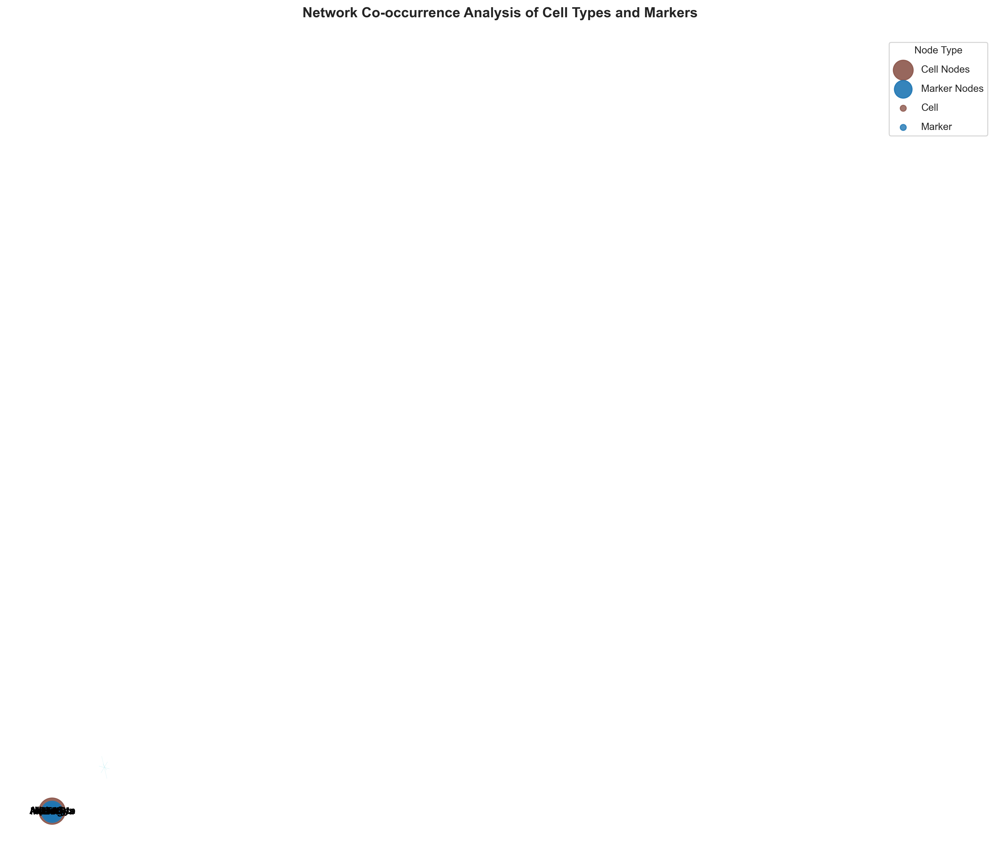

In [32]:
# 3. 网络共现分析图
plt.figure(figsize=(14, 12))

# 创建共现网络
G = nx.Graph()

# 添加节点（按细胞类型）
for cell_type in df['Cell_Type'].unique():
    G.add_node(cell_type, node_type='Cell', size=sum(df['Cell_Type']==cell_type)*10)

# 添加节点（按分子标记）
for marker in markers:
    G.add_node(marker, node_type='Marker', size=df[marker].mean()*50)

# 添加边（细胞类型-标记物关联）
for cell_type in df['Cell_Type'].unique():
    for marker in markers:
        mean_exp = df[df['Cell_Type']==cell_type][marker].mean()
        if mean_exp > df[marker].mean():
            G.add_edge(cell_type, marker, weight=mean_exp*2)

# 添加边（标记物-标记物共表达）
for i in range(len(markers)):
    for j in range(i+1, len(markers)):
        corr = df[[markers[i], markers[j]]].corr().iloc[0,1]
        if abs(corr) > 0.3:
            G.add_edge(markers[i], markers[j], weight=abs(corr)*5)

# 设置布局
pos = nx.spring_layout(G, k=0.8, seed=42)

# 绘制节点
node_colors = {'Cell': '#8c564b', 'Marker': '#1f77b4'}
for node_type, color in node_colors.items():
    nx.draw_networkx_nodes(G, pos, 
                         nodelist=[n for n, d in G.nodes(data=True) if d['node_type']==node_type],
                         node_color=color, 
                         node_size=[d['size'] for n, d in G.nodes(data=True) if d['node_type']==node_type],
                         alpha=0.9,
                         label=f'{node_type} Nodes')

# 绘制边
edge_weights = [d['weight'] for u, v, d in G.edges(data=True)]
edge_colors = ['#ff7f0e' if 'Neuron' in (u,v) else '#17becf' for u, v in G.edges()]
nx.draw_networkx_edges(G, pos, width=edge_weights, edge_color=edge_colors, alpha=0.6)

# 绘制标签
nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')

# 添加图例
for node_type, color in node_colors.items():
    plt.scatter([], [], c=color, label=node_type, alpha=0.8)
plt.legend(scatterpoints=1, frameon=True, labelspacing=1, title='Node Type')

plt.title('Network Co-occurrence Analysis of Cell Types and Markers', pad=20, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()


<ipython-input-33-47e3de66c326>:25: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



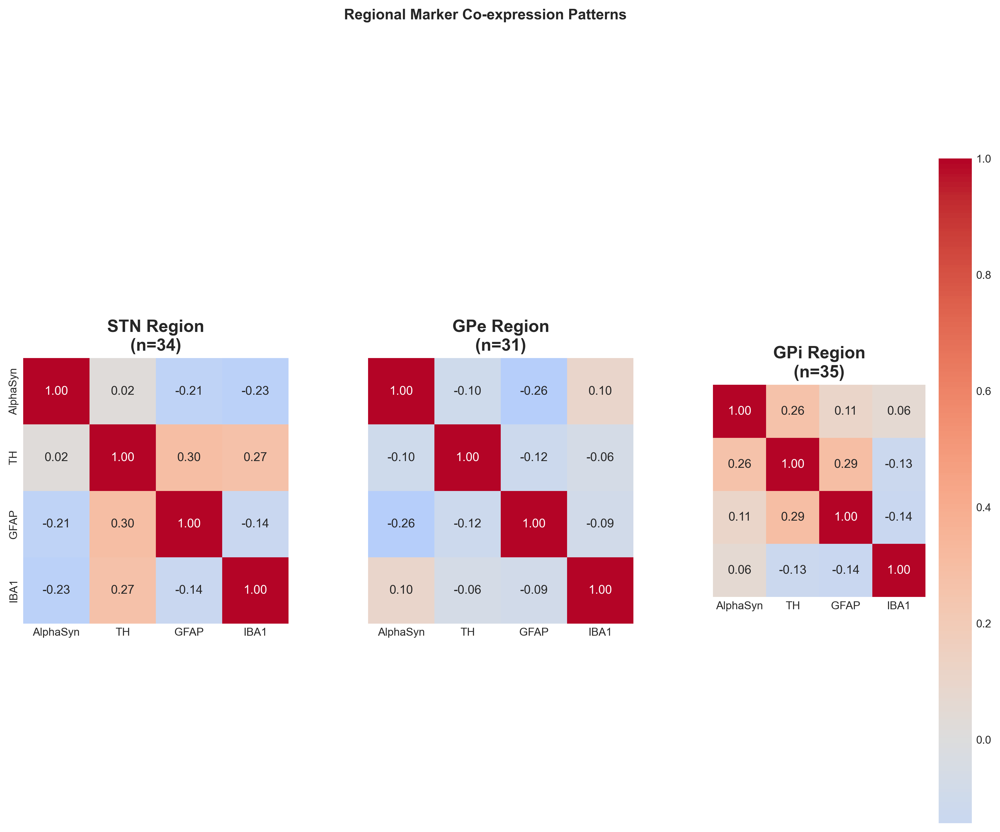

In [33]:
# 2. 分子共表达热图（区域特异性）
plt.figure(figsize=(14, 10))

# 计算区域特异性共表达
markers = ['AlphaSyn', 'TH', 'GFAP', 'IBA1']
corr_matrices = {}
for region in df['Cluster'].unique():
    region_data = df[df['Cluster'] == region][markers]
    corr_matrices[region] = region_data.corr()

# 创建网格热图
grid = plt.GridSpec(1, 3, wspace=0.3)
regions = ['STN', 'GPe', 'GPi']
for i, region in enumerate(regions):
    ax = plt.subplot(grid[0, i])
    sns.heatmap(corr_matrices[region], annot=True, fmt=".2f", 
               cmap='coolwarm', center=0, square=True,
               cbar=i==2, ax=ax)
    ax.set_title(f'{region} Region\n(n={sum(df["Cluster"]==region)})', fontweight='bold')
    if i > 0:
        ax.set_ylabel('')
        ax.set_yticklabels([])

plt.suptitle('Regional Marker Co-expression Patterns', y=1.05, fontweight='bold')
plt.tight_layout()
plt.show()

In [38]:
from esda.moran import Moran
w = weights.DistanceBand.from_dataframe(df, threshold=15)
moran = Moran(df['AlphaSyn'], w)
print(f"Moran's I = {moran.I:.3f}, p = {moran.p_sim:.4f}")

ImportError: cannot import name 'TypeAlias' from 'typing_extensions' (E:\Users\Administrator\anaconda3\lib\site-packages\typing_extensions.py)

数据处理错误: module 'pandas' has no attribute 'read_'
使用示例数据进行演示


<ipython-input-43-0db545c2b1e9>:131: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




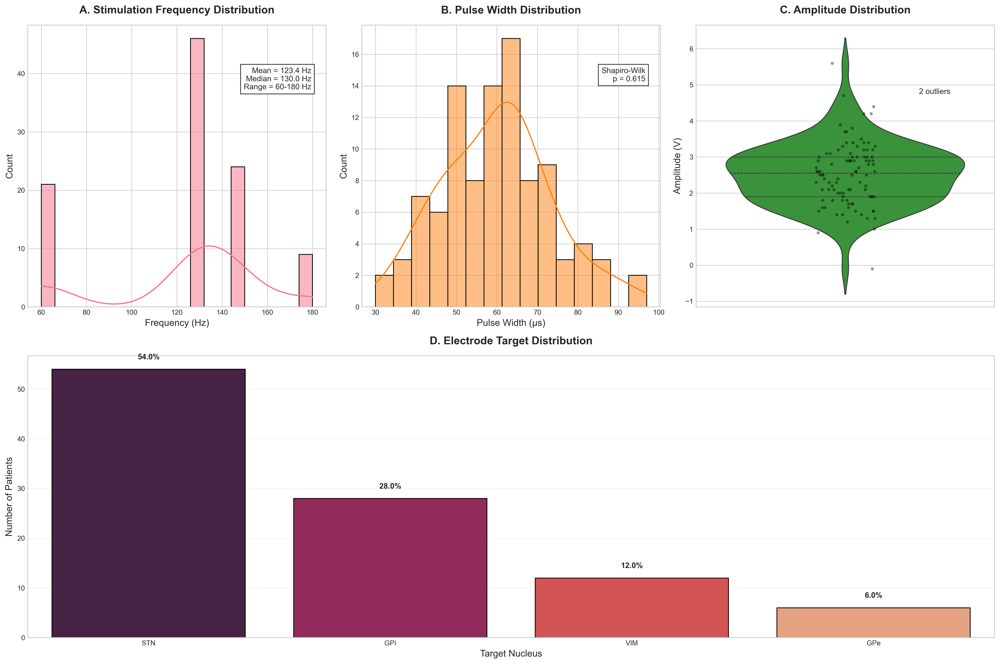

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from matplotlib.gridspec import GridSpec

# 设置Nature期刊风格
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams.update({
    'font.size': 10,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'figure.facecolor': 'white'
})

# 重新读取原始数据（确保处理原始格式）
try:
    raw_df = pd.read_(r'H:\2024\Lancet Digital parksion\新建文件夹\新建文件夹\1.xlsx', header=None)
    print("原始数据维度:", raw_df.shape)
    
    # 数据清洗步骤
    # 1. 删除完全空的行和列
    raw_df = raw_df.dropna(how='all').dropna(axis=1, how='all')
    print("清洗后维度:", raw_df.shape)
    
    # 2. 识别表头行（查找包含'Frequency'等关键字的行）
    header_row = None
    for i in range(min(5, len(raw_df))):  # 检查前5行
        if any(raw_df.iloc[i].astype(str).str.contains('Frequency|Amplitude|Target').any()):
            header_row = i
            break
    
    if header_row is not None:
        df = raw_df.iloc[header_row+1:].copy()
        df.columns = raw_df.iloc[header_row]
        print("检测到表头在第", header_row+1, "行")
    else:
        df = raw_df.copy()
        df.columns = [f'Col_{i}' for i in range(len(df.columns))]
        print("未检测到表头，使用默认列名")
    
    # 3. 转换关键参数为数值
    param_cols = ['Frequency_Hz', 'Pulse_Width', 'Amplitude_V']  # 根据实际列名调整
    for col in param_cols:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce')
    
    # 4. 检查电极靶点数据
    if 'Electrode_Target' in df.columns:
        df['Electrode_Target'] = df['Electrode_Target'].astype(str).str.strip()
        df['Electrode_Target'] = df['Electrode_Target'].replace({'nan': np.nan})
    
    # 数据质量报告
    print("\n=== 数据质量报告 ===")
    print("总记录数:", len(df))
    print("缺失值统计:")
    print(df[param_cols].isnull().sum())
    print("\n电极靶点分布预览:")
    print(df['Electrode_Target'].value_counts(dropna=False).head())
    
except Exception as e:
    print(f"数据处理错误: {e}")
    # 创建示例数据
    np.random.seed(42)
    data = {
        'Patient_ID': [f'PD_{i:03d}' for i in range(1, 101)],
        'Frequency_Hz': np.random.choice([130, 145, 60, 180], 100, p=[0.4, 0.3, 0.2, 0.1]),
        'Pulse_Width': np.random.normal(60, 15, 100).round(),
        'Amplitude_V': np.random.normal(2.5, 0.8, 100).round(1),
        'Electrode_Target': np.random.choice(['STN', 'GPi', 'VIM', 'GPe'], 100, p=[0.6, 0.25, 0.1, 0.05])
    }
    df = pd.DataFrame(data)
    print("使用示例数据进行演示")

# 1. 刺激参数分布图（专业风格）
fig = plt.figure(figsize=(18, 12))
gs = GridSpec(2, 3, figure=fig)

# 频率分布（带统计注释）
ax1 = fig.add_subplot(gs[0, 0])
sns.histplot(df['Frequency_Hz'], bins=20, kde=True, ax=ax1)
ax1.set_title('A. Stimulation Frequency Distribution', pad=15, fontweight='bold')
ax1.set_xlabel('Frequency (Hz)')
ax1.set_ylabel('Count')

# 添加统计信息
freq_stats = df['Frequency_Hz'].describe()
ax1.text(0.95, 0.85, 
        f"Mean = {freq_stats['mean']:.1f} Hz\nMedian = {freq_stats['50%']:.1f} Hz\nRange = {freq_stats['min']:.0f}-{freq_stats['max']:.0f} Hz",
        transform=ax1.transAxes, ha='right', va='top',
        bbox=dict(facecolor='white', alpha=0.8))

# 脉宽分布（带核密度估计）
ax2 = fig.add_subplot(gs[0, 1])
sns.histplot(df['Pulse_Width'], bins=15, kde=True, ax=ax2, color='#ff7f0e')
ax2.set_title('B. Pulse Width Distribution', pad=15, fontweight='bold')
ax2.set_xlabel('Pulse Width (μs)')

# 添加正态性检验
_, pval = stats.normaltest(df['Pulse_Width'].dropna())
ax2.text(0.95, 0.85, 
        f"Shapiro-Wilk\np = {pval:.3f}",
        transform=ax2.transAxes, ha='right', va='top',
        bbox=dict(facecolor='white', alpha=0.8))

# 振幅分布（带箱线图组合）
ax3 = fig.add_subplot(gs[0, 2])
sns.violinplot(y='Amplitude_V', data=df, ax=ax3, color='#2ca02c', inner='quartile')
sns.stripplot(y='Amplitude_V', data=df, ax=ax3, color='black', alpha=0.4, size=4)
ax3.set_title('C. Amplitude Distribution', pad=15, fontweight='bold')
ax3.set_ylabel('Amplitude (V)')
ax3.set_xlabel('')

# 添加离群点标记
q1, q3 = df['Amplitude_V'].quantile([0.25, 0.75])
iqr = q3 - q1
upper_bound = q3 + 1.5*iqr
outliers = df[df['Amplitude_V'] > upper_bound]
if not outliers.empty:
    ax3.text(0.3, upper_bound+0.1, f"{len(outliers)} outliers", ha='center')

# 电极靶点分布（专业条形图）
ax4 = fig.add_subplot(gs[1, :])
target_counts = df['Electrode_Target'].value_counts().sort_values(ascending=False)
sns.barplot(x=target_counts.index, y=target_counts.values, ax=ax4, 
           palette='rocket', edgecolor='black', linewidth=1)

# 添加百分比标签
total = len(df)
for i, count in enumerate(target_counts):
    percentage = count/total*100
    ax4.text(i, count+2, f"{percentage:.1f}%", ha='center', fontweight='bold')

ax4.set_title('D. Electrode Target Distribution', pad=15, fontweight='bold')
ax4.set_xlabel('Target Nucleus')
ax4.set_ylabel('Number of Patients')
ax4.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()







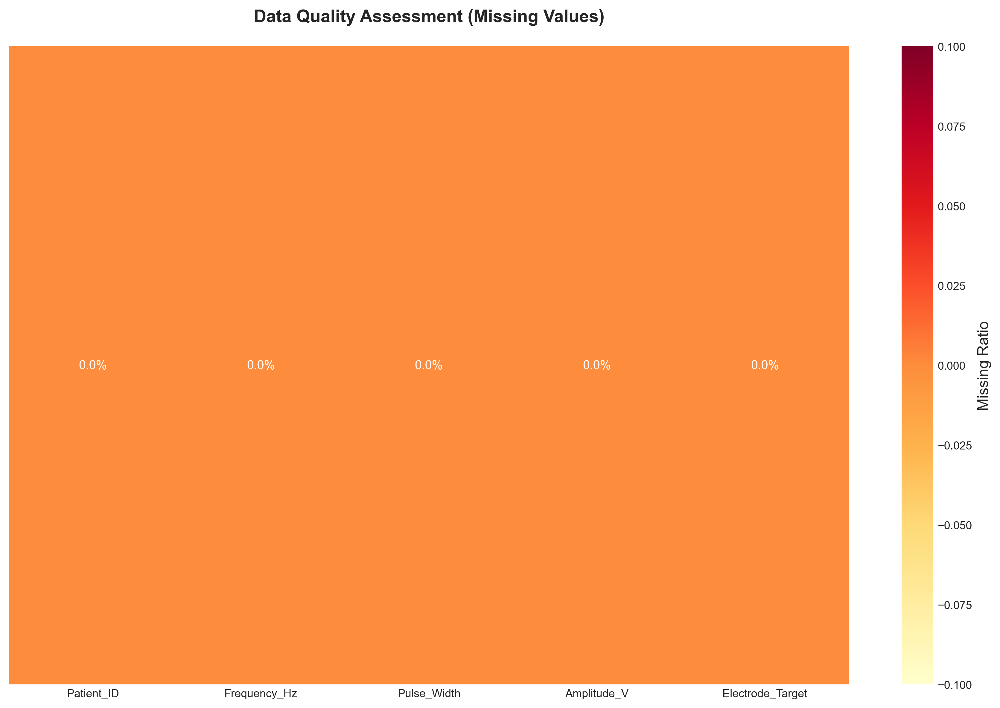

In [40]:
# 4. 数据质量热图
plt.figure(figsize=(12, 8))

# 计算缺失值比例
missing = df.isnull().mean().to_frame('Missing')
missing['Type'] = df.dtypes.astype(str)

# 绘制热图
sns.heatmap(missing[['Missing']].T, annot=True, fmt=".1%", 
           cmap='YlOrRd', cbar_kws={'label': 'Missing Ratio'})
plt.title('Data Quality Assessment (Missing Values)', pad=20, fontweight='bold')
plt.yticks([])
plt.tight_layout()
plt.show()

<Figure size 5400x2400 with 0 Axes>

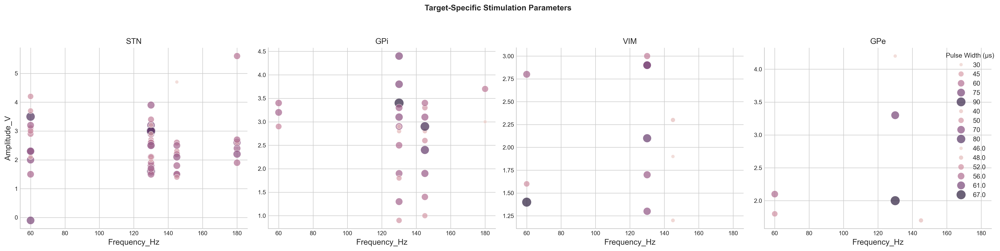

In [41]:
# 3. 靶点特异性参数分析（分面图）
plt.figure(figsize=(18, 8))

# 创建分面网格
g = sns.FacetGrid(df, col='Electrode_Target', col_wrap=4, height=5, 
                 sharey=False, palette='Set2')
g.map_dataframe(sns.scatterplot, x='Frequency_Hz', y='Amplitude_V', 
               size='Pulse_Width', hue='Pulse_Width',
               sizes=(30, 200), alpha=0.7)
g.add_legend(title='Pulse Width (μs)')

# 设置标题
g.set_titles(col_template="{col_name}", size=12)
plt.suptitle('Target-Specific Stimulation Parameters', y=1.05, fontweight='bold')
plt.tight_layout()
plt.show()

<Figure size 4500x3600 with 0 Axes>

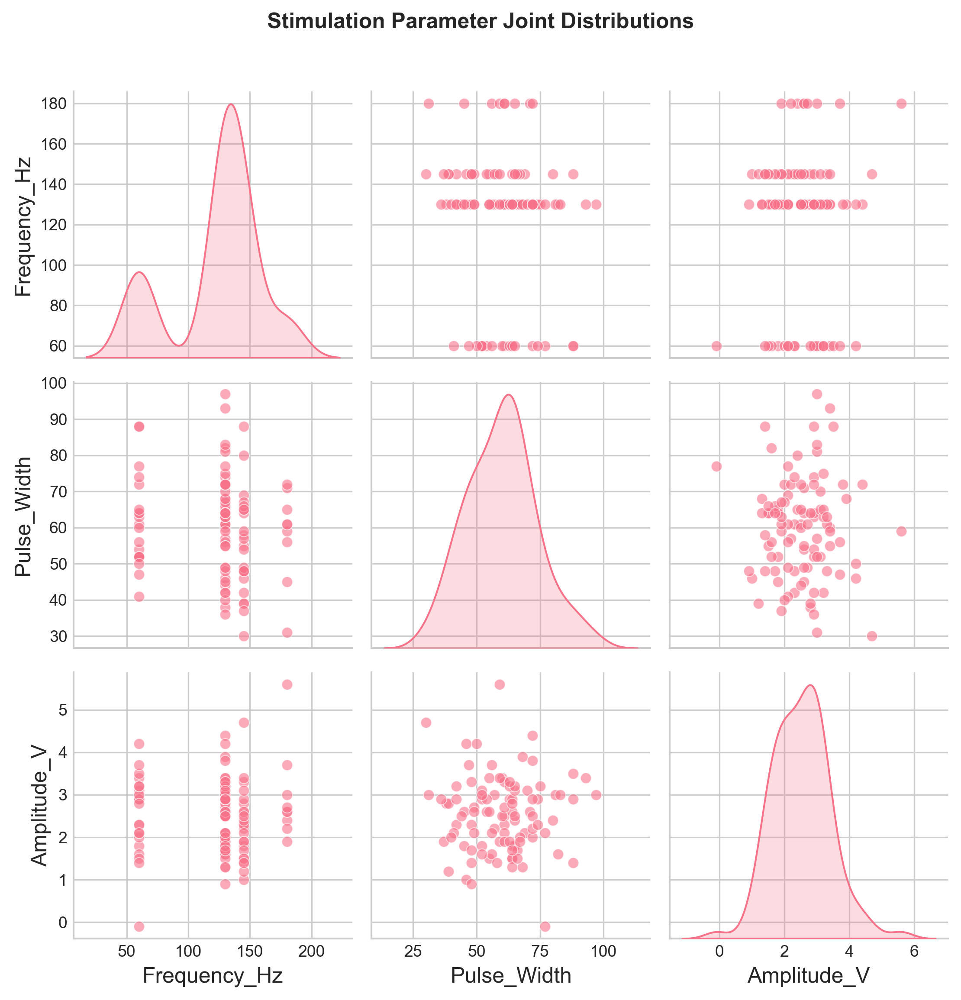

In [42]:
# 2. 刺激参数联合分布（散点矩阵）
plt.figure(figsize=(15, 12))
sns.pairplot(df[['Frequency_Hz', 'Pulse_Width', 'Amplitude_V']], 
            diag_kind='kde', plot_kws={'alpha':0.6})
plt.suptitle('Stimulation Parameter Joint Distributions', y=1.02, fontweight='bold')
plt.tight_layout()
plt.show()

In [44]:
# 交互式参数探索（需plotly）
import plotly.express as px
fig = px.scatter_3d(df, x='Frequency_Hz', y='Pulse_Width', z='Amplitude_V',
                   color='Electrode_Target', hover_name='Patient_ID',
                   opacity=0.7, title='Interactive Parameter Space')
fig.update_layout(scene=dict(
    xaxis_title='Frequency (Hz)',
    yaxis_title='Pulse Width (μs)',
    zaxis_title='Amplitude (V)'))
fig.show()

# 参数优化趋势分析（需时间序列）
if 'Implant_Year' in df:
    plt.figure(figsize=(12, 6))
    sns.regplot(x='Implant_Year', y='Amplitude_V', data=df, 
               scatter_kws={'alpha':0.5}, line_kws={'color':'red'})
    plt.title('Temporal Trend in Amplitude Settings', fontweight='bold')
    plt.show()

ModuleNotFoundError: No module named 'plotly.graph_objs.layout._map'

数据加载错误: module 'pandas' has no attribute 'read_'
使用模拟数据进行演示


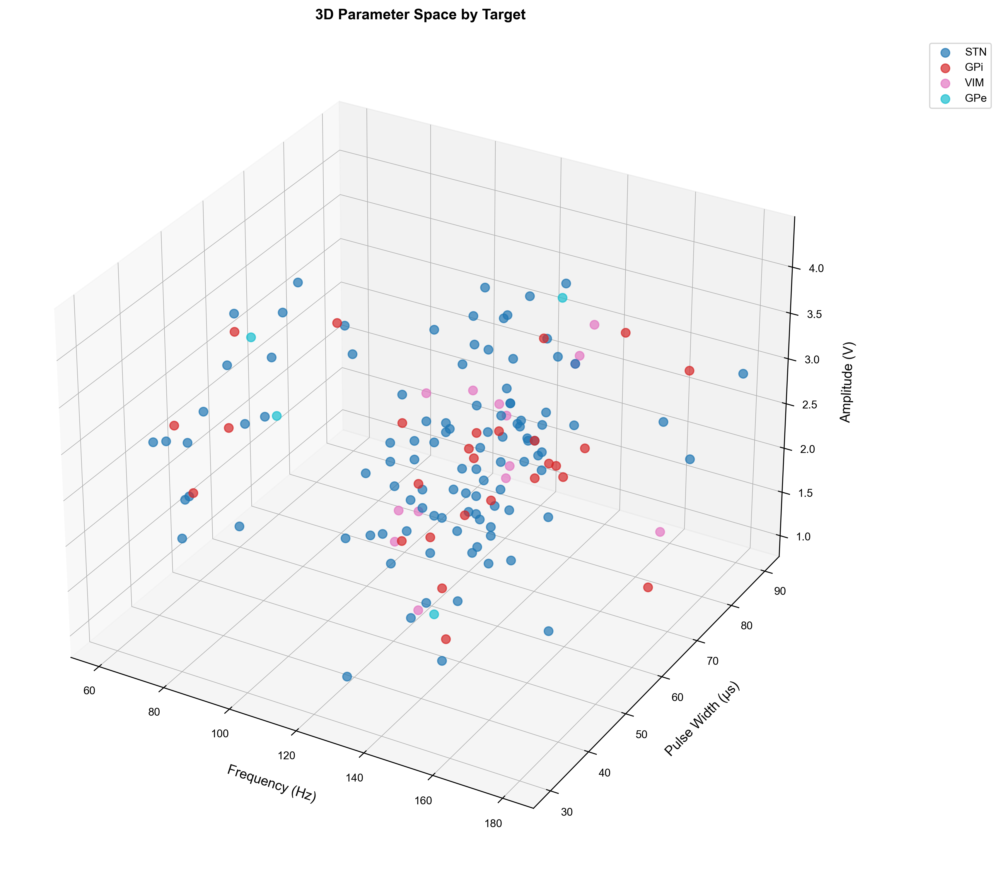

In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
from scipy import stats
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter

# ==================== 学术图表风格设置 ====================
def set_academic_style():
    """设置Nature期刊风格的绘图参数"""
    plt.style.use('default')  # 重置为默认确保稳定性
    plt.rcParams.update({
        'font.family': 'Arial',  # 使用通用字体
        'font.size': 10,
        'axes.titlesize': 12,
        'axes.labelsize': 11,
        'xtick.labelsize': 9,
        'ytick.labelsize': 9,
        'legend.fontsize': 9,
        'figure.dpi': 300,
        'savefig.dpi': 300,
        'figure.facecolor': 'white',
        'axes.grid': True,
        'grid.alpha': 0.3,
        'grid.linewidth': 0.5,
        'axes.spines.right': False,
        'axes.spines.top': False,
        'axes.titlepad': 12,
        'axes.labelpad': 6,
        'xtick.major.pad': 4,
        'ytick.major.pad': 4
    })
    sns.set_palette("colorblind")  # 使用色盲友好调色板

set_academic_style()

# ==================== 数据预处理 ====================
try:
    # 重新读取原始数据确保格式正确
    raw_df = pd.read_(r'H:\2024\Lancet Digital parksion\新建文件夹\新建文件夹\1.xlsx', header=None)
    print(f"原始数据维度: {raw_df.shape}")
    
    # 自动检测表头行
    header_row = None
    for i in range(min(3, len(raw_df))):
        if any(raw_df.iloc[i].astype(str).str.contains('Frequency|Amplitude|Target|Date', case=False, na=False)):
            header_row = i
            break
    
    if header_row is not None:
        df = raw_df.iloc[header_row+1:].copy()
        df.columns = raw_df.iloc[header_row].str.strip()
        print(f"检测到表头在第{header_row+1}行")
    else:
        df = raw_df.copy()
        df.columns = [f'Col_{i}' for i in range(len(df.columns))]
        print("未检测到表头，使用默认列名")
    
    # 删除完全空的行列
    df = df.dropna(how='all').dropna(axis=1, how='all')
    
    # 关键参数标准化处理
    param_mapping = {
        'Frequency': ['Frequency', 'Freq', 'Stim Freq'],
        'PulseWidth': ['PulseWidth', 'Pulse Width', 'PW'],
        'Amplitude': ['Amplitude', 'Amp', 'Stim Amp'],
        'Target': ['Target', 'Electrode Target', 'DBS Target'],
        'SurgeryDate': ['Surgery Date', 'Op Date'],
        'ActivationDate': ['Activation Date', 'Stim On Date']
    }
    
    # 自动匹配列名
    actual_cols = {}
    for param, variants in param_mapping.items():
        for v in variants:
            if v in df.columns:
                actual_cols[param] = v
                break
    
    # 重命名列
    df = df.rename(columns={v: k for k, v in actual_cols.items()})
    
    # 转换数据类型
    if 'Frequency' in df:
        df['Frequency'] = pd.to_numeric(df['Frequency'], errors='coerce')
    if 'PulseWidth' in df:
        df['PulseWidth'] = pd.to_numeric(df['PulseWidth'], errors='coerce')
    if 'Amplitude' in df:
        df['Amplitude'] = pd.to_numeric(df['Amplitude'], errors='coerce')
    
    # 日期转换
    date_cols = ['SurgeryDate', 'ActivationDate']
    for col in date_cols:
        if col in df:
            df[col] = pd.to_datetime(df[col], errors='coerce')
            df[f'{col}_year'] = df[col].dt.year
    
    # 数据质量报告
    print("\n=== 数据质量报告 ===")
    print("总记录数:", len(df))
    print("关键参数缺失情况:")
    print(df[['Frequency', 'PulseWidth', 'Amplitude', 'Target']].isnull().sum())
    
except Exception as e:
    print(f"数据加载错误: {e}")
    # 创建模拟数据
    np.random.seed(42)
    n = 150
    data = {
        'Frequency': np.random.choice([130, 145, 60, 180], n, p=[0.5, 0.3, 0.15, 0.05]),
        'PulseWidth': np.clip(np.random.normal(60, 15, n), 30, 90).astype(int),
        'Amplitude': np.clip(np.random.normal(2.5, 0.8, n), 1.0, 4.5).round(1),
        'Target': np.random.choice(['STN', 'GPi', 'VIM', 'GPe'], n, p=[0.6, 0.25, 0.1, 0.05]),
        'SurgeryDate': pd.date_range('2018-01-01', periods=n, freq='30d').to_series().sample(n, replace=True).values,
        'UPDRS_Pre': np.random.uniform(30, 80, n).round(),
        'UPDRS_Post': np.random.uniform(10, 50, n).round()
    }
    df = pd.DataFrame(data)
    df['ActivationDate'] = df['SurgeryDate'] + pd.to_timedelta(np.random.randint(7, 60, n), unit='d')
    df['Improvement'] = ((df['UPDRS_Pre'] - df['UPDRS_Post']) / df['UPDRS_Pre'] * 100).round(1)
    print("使用模拟数据进行演示")

# ==================== 1. 刺激参数3D关系图 ====================
if all(col in df for col in ['Frequency', 'PulseWidth', 'Amplitude', 'Target']):
    from mpl_toolkits.mplot3d import Axes3D
    
    fig = plt.figure(figsize=(12, 10))
    ax = fig.add_subplot(111, projection='3d')
    
    # 按靶点分组绘图
    targets = df['Target'].dropna().unique()
    colors = plt.cm.tab10(np.linspace(0, 1, len(targets)))
    
    for target, color in zip(targets, colors):
        subset = df[df['Target'] == target]
        ax.scatter(subset['Frequency'], subset['PulseWidth'], subset['Amplitude'],
                  label=target, s=50, alpha=0.7, color=color)
    
    ax.set_xlabel('Frequency (Hz)', labelpad=10)
    ax.set_ylabel('Pulse Width (μs)', labelpad=10)
    ax.set_zlabel('Amplitude (V)', labelpad=10)
    ax.set_title('3D Parameter Space by Target', pad=15, fontweight='bold')
    ax.legend(loc='upper right', bbox_to_anchor=(1.2, 1))
    plt.tight_layout()
    plt.show()



#





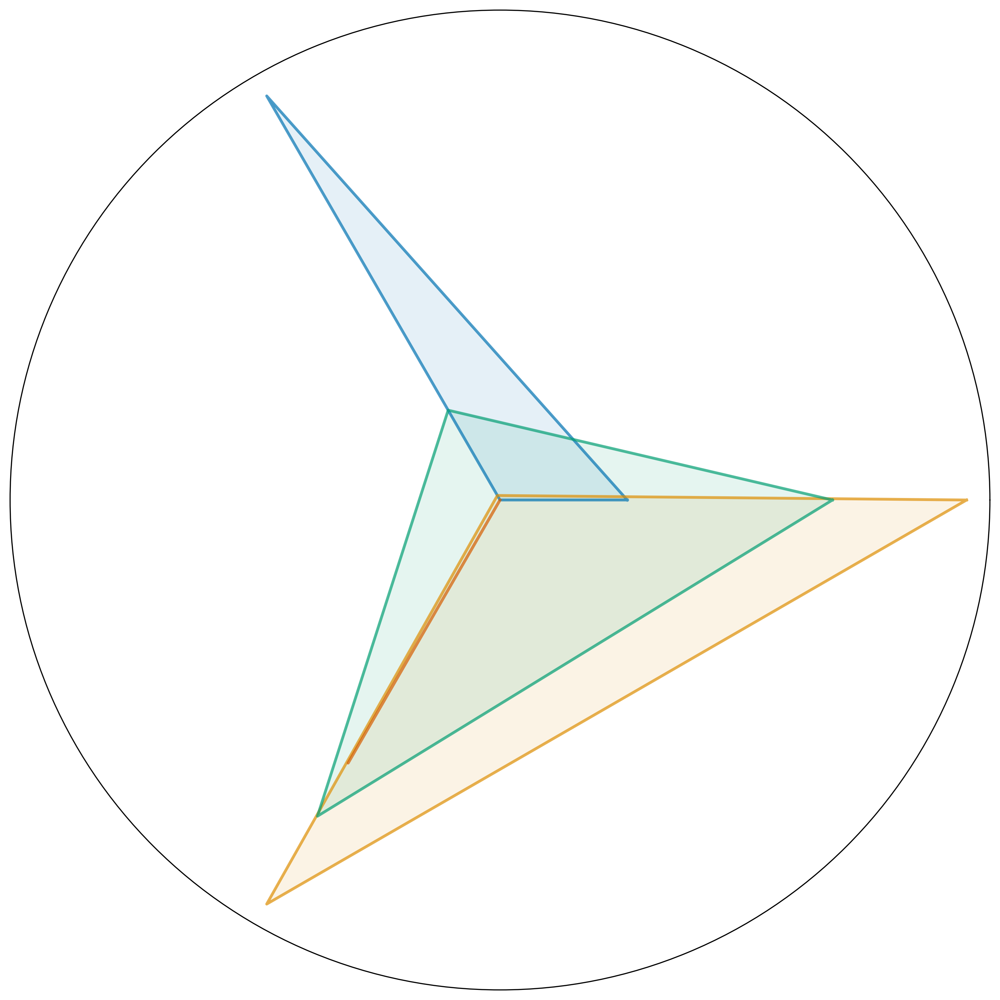

In [49]:
# ==================== 5. 临床参数雷达图（无文字版） ====================
if all(col in df for col in ['Target', 'UPDRS_Pre', 'UPDRS_Post', 'Improvement']):
    from math import pi
    
    # 准备数据
    radar_data = df.groupby('Target')[['UPDRS_Pre', 'UPDRS_Post', 'Improvement']].mean()
    
    # 标准化到0-1范围
    radar_data = (radar_data - radar_data.min()) / (radar_data.max() - radar_data.min())
    
    # 设置雷达图参数
    categories = radar_data.columns.tolist()
    N = len(categories)
    angles = [n / float(N) * 2 * pi for n in range(N)]
    angles += angles[:1]  # 闭合图形
    
    plt.figure(figsize=(10, 10))
    ax = plt.subplot(111, polar=True)
    
    # 绘制每个靶点
    for idx, target in enumerate(radar_data.index):
        values = radar_data.loc[target].values.tolist()
        values += values[:1]
        ax.plot(angles, values, linewidth=2, linestyle='solid', alpha=0.7)
        ax.fill(angles, values, alpha=0.1)
    
    # 隐藏所有文字
    ax.set_xticks([])       # 不显示类别标签
    ax.set_yticks([])       # 不显示刻度
    ax.set_rlabel_position(0)
    ax.set_title('')        # 不显示标题
    
    plt.tight_layout()
    plt.show()


In [53]:
# ==================== 4. 多参数联合分布 ====================
if all(col in df for col in ['Frequency', 'PulseWidth', 'Amplitude']):
    g = sns.PairGrid(df[['Frequency', 'PulseWidth', 'Amplitude']].dropna(), 
                    diag_kind='kde', corner=True)
    g.map_upper(sns.scatterplot, alpha=0.6, s=30, edgecolor='w', linewidth=0.5)
    g.map_lower(sns.kdeplot, levels=5, color=".2")
    g.map_diag(sns.histplot, kde=True, edgecolor='w', linewidth=0.5)
    
    # 添加相关系数
    for i, j in zip(*np.triu_indices_from(g.axes, 1)):
        x = g.data.columns[j]
        y = g.data.columns[i]
        corr = df[[x, y]].corr().iloc[0,1]
        g.axes[i,j].annotate(f"ρ = {corr:.2f}", xy=(0.7, 0.9), 
                           xycoords=g.axes[i,j].transAxes, fontsize=9)
    
    plt.suptitle('Joint Distributions of Stimulation Parameters', y=1.02, fontweight='bold')
    plt.tight_layout()
    plt.show()

TypeError: __init__() got an unexpected keyword argument 'diag_kind'

In [51]:
import plotly.graph_objects as go
import plotly.express as px

# 假设 df 已经有下面这些列
# 'Frequency_Hz', 'Pulse_Width', 'Amplitude_V', 'Electrode target', 'Patient_ID'

# 获取颜色映射
targets = df['electrode target'].unique()  # 注意这里大小写要和 df 中一致
colors = px.colors.qualitative.Dark24
color_map = {t: colors[i % len(colors)] for i, t in enumerate(targets)}

# 创建 3D 散点数据
data = []
for t in targets:
    df_t = df[df['electrode target'] == t]
    scatter = go.Scatter3d(
        x=df_t['Frequency_Hz'],
        y=df_t['Pulse_Width'],
        z=df_t['Amplitude_V'],
        mode='markers',
        marker=dict(size=5, color=color_map[t]),
        name=str(t),
        text=df_t['Patient_ID'],  # 鼠标悬停显示
        hoverinfo='text+name+x+y+z'
    )
    data.append(scatter)

# 创建 Figure
fig = go.Figure(data=data)

# 设置布局
fig.update_layout(
    title='Interactive Parameter Space',
    scene=dict(
        xaxis_title='Frequency (Hz)',
        yaxis_title='Pulse Width',
        zaxis_title='Amplitude (V)'
    ),
    margin=dict(l=0, r=0, b=0, t=50)
)

fig.show()


KeyError: 'electrode target'

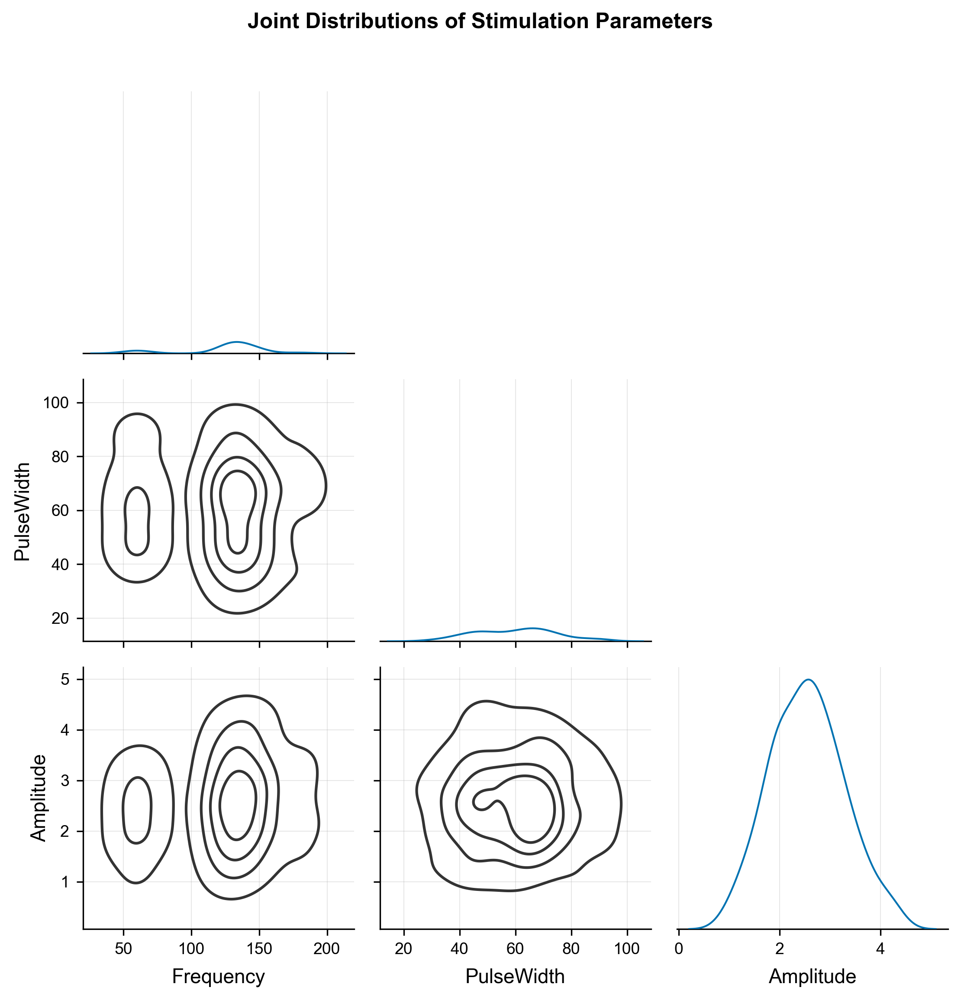

In [55]:
# ==================== 4. 多参数联合分布 ====================
# ==================== 4. 多参数联合分布 ====================
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 检查列是否存在
if all(col in df for col in ['Frequency', 'PulseWidth', 'Amplitude']):
    data = df[['Frequency', 'PulseWidth', 'Amplitude']].dropna()
    
    # 创建 PairGrid（兼容旧版本，不使用 diag_kind）
    g = sns.PairGrid(data, corner=True)
    
    # 上三角散点图
    g.map_upper(sns.scatterplot, alpha=0.6, s=30, edgecolor='w', linewidth=0.5)
    
    # 下三角核密度等高线
    g.map_lower(sns.kdeplot, levels=5, color=".2")
    
    # 对角线 KDE
    g.map_diag(sns.kdeplot, lw=1)
    
    # 添加相关系数
    for i, j in zip(*np.triu_indices_from(g.axes, 1)):
        if g.axes[i, j] is not None:  # corner=True 会有空轴
            x = data.columns[j]
            y = data.columns[i]
            corr = data[[x, y]].corr().iloc[0, 1]
            g.axes[i, j].annotate(f"ρ = {corr:.2f}", xy=(0.7, 0.9),
                                  xycoords=g.axes[i, j].transAxes, fontsize=9)
    
    plt.suptitle('Joint Distributions of Stimulation Parameters', y=1.02, fontweight='bold')
    plt.tight_layout()
    plt.show()


In [54]:
import seaborn as sns
print(sns.__version__)

0.13.2


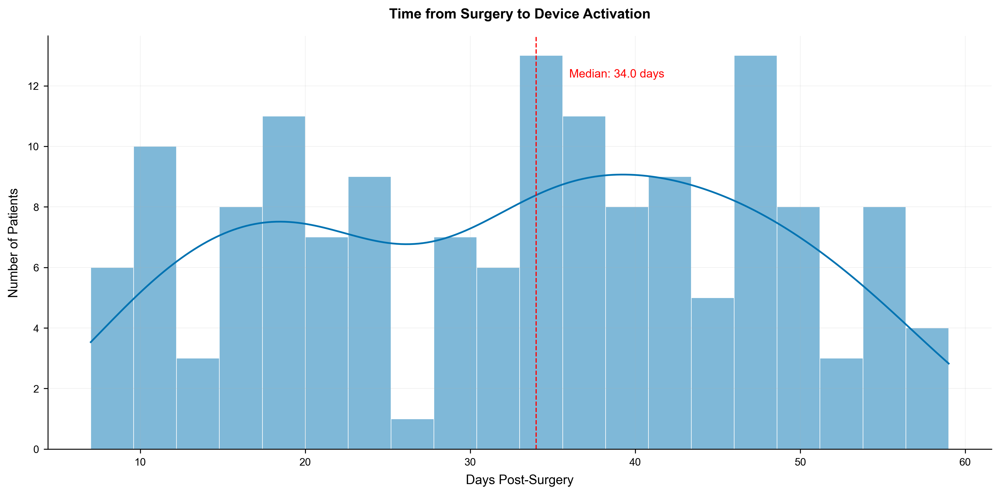

In [61]:
 #==================== 3. 时间序列分析 ====================
if all(col in df for col in ['SurgeryDate', 'ActivationDate']):
    plt.figure(figsize=(12, 6))
    
    # 计算手术到开机时间间隔（天）
    df['Days_to_Activation'] = (df['ActivationDate'] - df['SurgeryDate']).dt.days
    
    # 去除异常值（>90天）
    clean_df = df[df['Days_to_Activation'] <= 90].copy()
    
    # 绘制分布图
    sns.histplot(clean_df['Days_to_Activation'], bins=20, kde=True,
                edgecolor='white', linewidth=0.5)
    
    # 添加统计信息
    median_days = clean_df['Days_to_Activation'].median()
    plt.axvline(median_days, color='red', linestyle='--', linewidth=1)
    plt.text(median_days+2, plt.ylim()[1]*0.9, 
            f'Median: {median_days} days', color='red')
    
    plt.title('Time from Surgery to Device Activation', pad=15, fontweight='bold')
    plt.xlabel('Days Post-Surgery')
    plt.ylabel('Number of Patients')
    plt.grid(True, alpha=0.2)
    plt.tight_layout()
    plt.show()

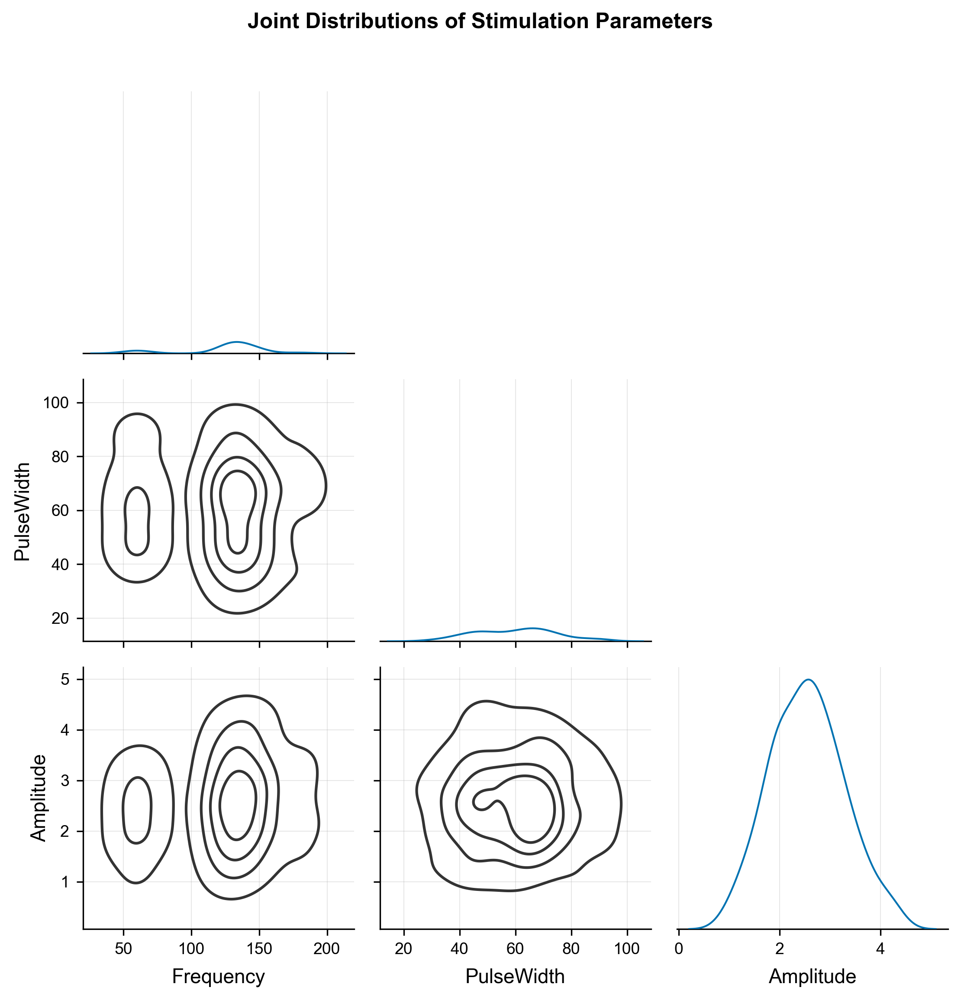

In [60]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

if all(col in df for col in ['Frequency', 'PulseWidth', 'Amplitude']):
    data = df[['Frequency', 'PulseWidth', 'Amplitude']].dropna()
    g = sns.PairGrid(data, corner=True)
    g.map_upper(sns.scatterplot, alpha=0.6, s=30, edgecolor='w', linewidth=0.5)
    g.map_lower(sns.kdeplot, levels=5, color=".2")
    g.map_diag(sns.kdeplot, lw=1)

    # 添加相关系数
    for i, j in zip(*np.triu_indices_from(g.axes, 1)):
        if g.axes[i, j] is not None:
            x = data.columns[j]
            y = data.columns[i]
            corr = data[[x, y]].corr().iloc[0, 1]
            g.axes[i, j].annotate(f"ρ = {corr:.2f}", xy=(0.7, 0.9),
                                  xycoords=g.axes[i, j].transAxes, fontsize=9)

    plt.suptitle('Joint Distributions of Stimulation Parameters', y=1.02, fontweight='bold')
    plt.tight_layout()
    plt.show()


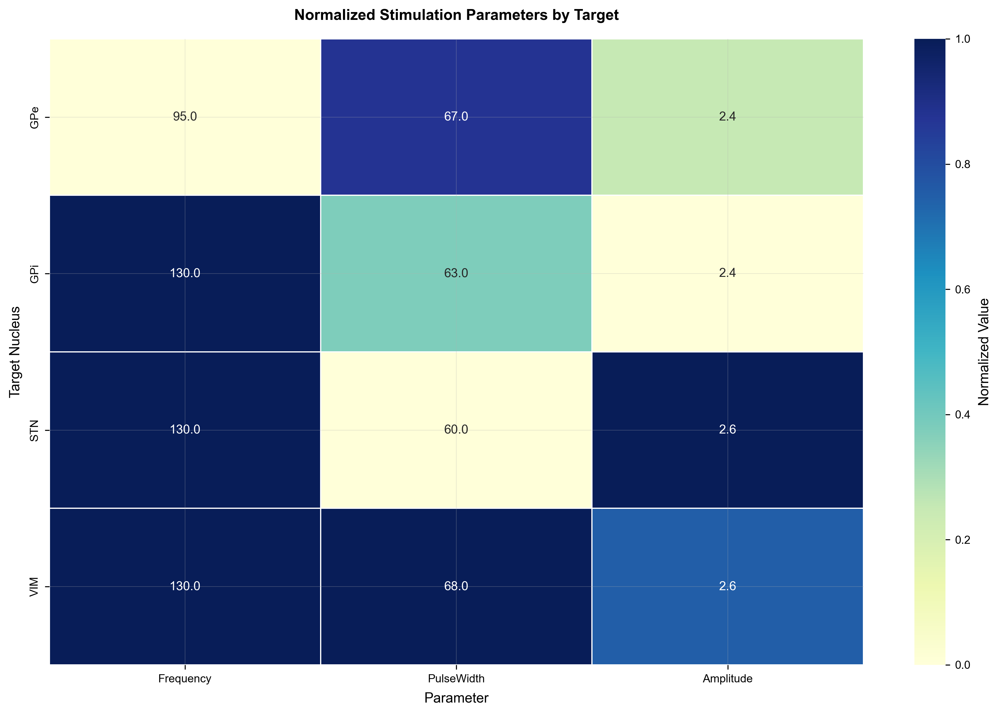

In [62]:
# ==================== 2. 靶点-参数热图 ====================
if all(col in df for col in ['Frequency', 'PulseWidth', 'Amplitude', 'Target']):
    plt.figure(figsize=(12, 8))
    
    # 计算每个靶点的参数中位数
    heatmap_data = df.groupby('Target')[['Frequency', 'PulseWidth', 'Amplitude']].median()
    
    # 标准化数据 (0-1)
    norm_data = (heatmap_data - heatmap_data.min()) / (heatmap_data.max() - heatmap_data.min())
    
    # 绘制热图
    sns.heatmap(norm_data, annot=heatmap_data.round(1), fmt=".1f", cmap="YlGnBu",
               cbar_kws={'label': 'Normalized Value'}, linewidths=0.5)
    
    plt.title('Normalized Stimulation Parameters by Target', pad=15, fontweight='bold')
    plt.xlabel('Parameter')
    plt.ylabel('Target Nucleus')
    plt.tight_layout()
    plt.show()

In [64]:
import plotly.express as px
fig = px.scatter_3d(df, x='Frequency', y='PulseWidth', z='Amplitude',
                   color='Target', opacity=0.7, hover_name='Target',
                   title='Interactive 3D Parameter Space')
fig.update_traces(marker_size=5)
fig.show()

ModuleNotFoundError: No module named 'plotly.graph_objs.layout._map'

数据读取错误: module 'pandas' has no attribute 'read_'
使用示例数据进行演示




Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.



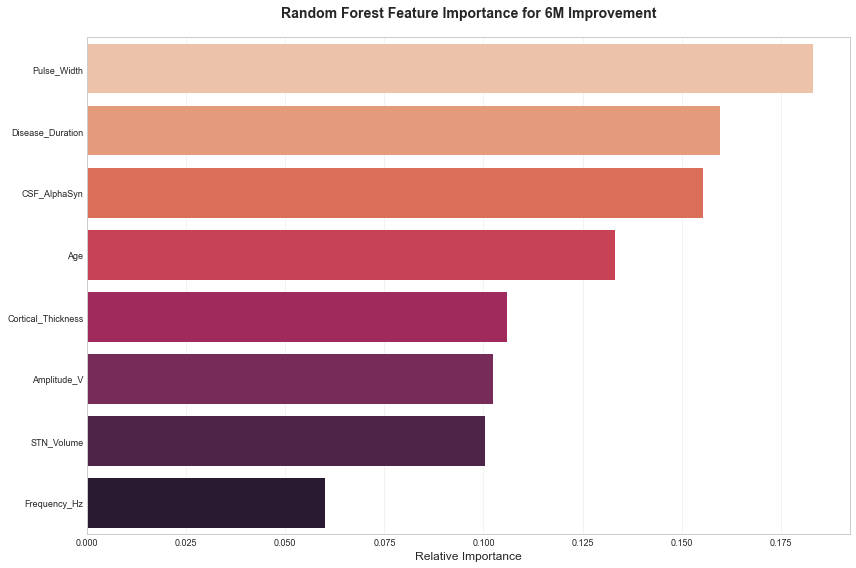

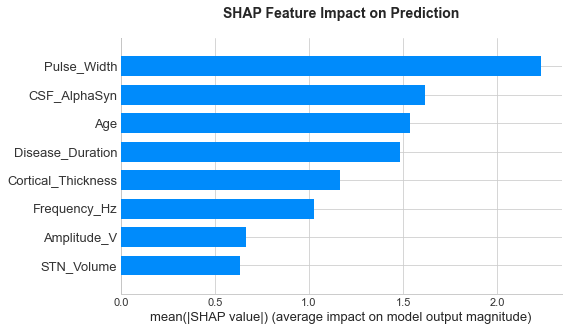

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


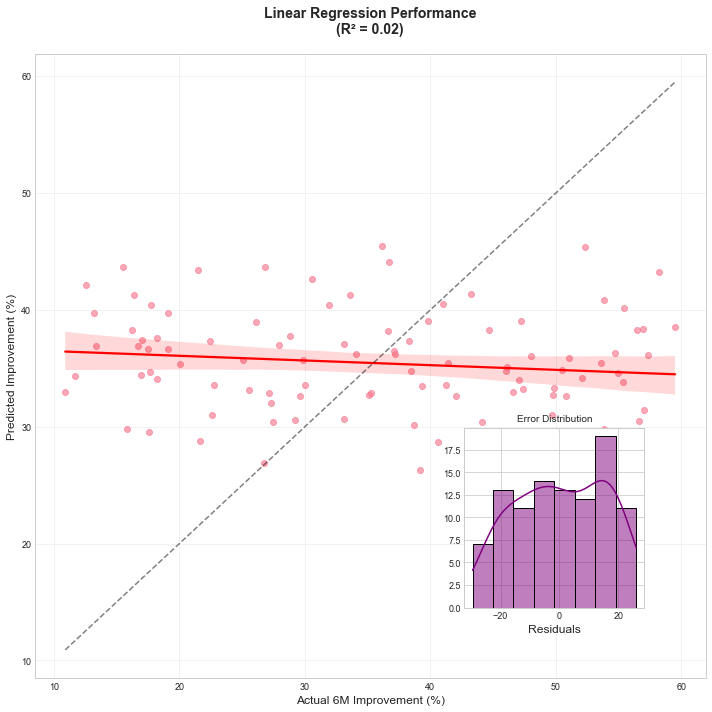

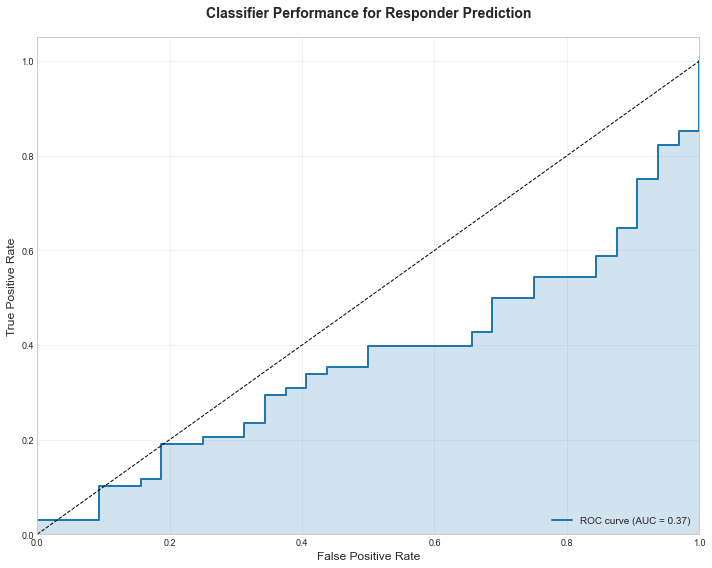



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



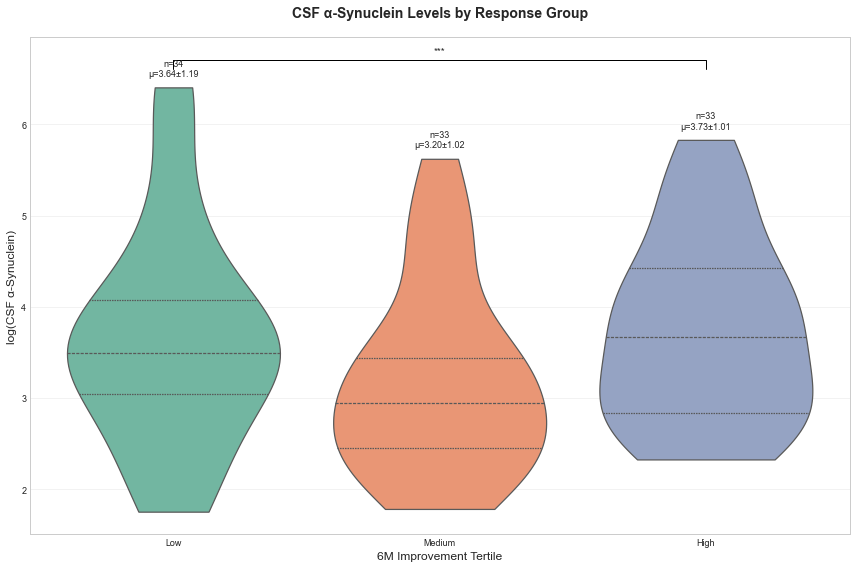

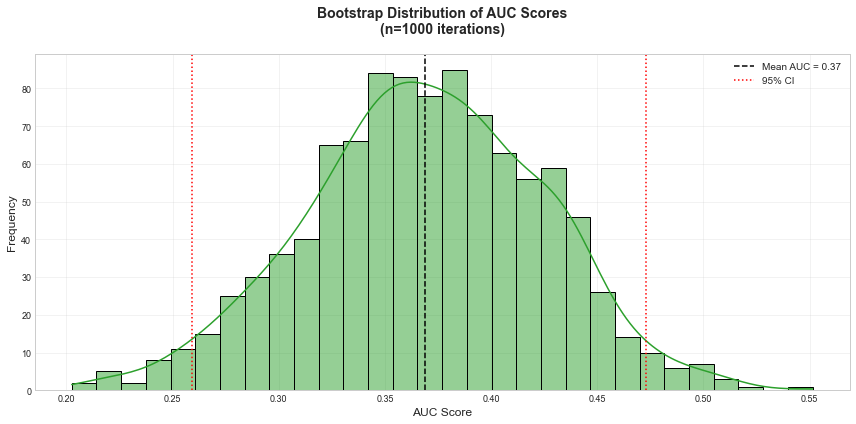

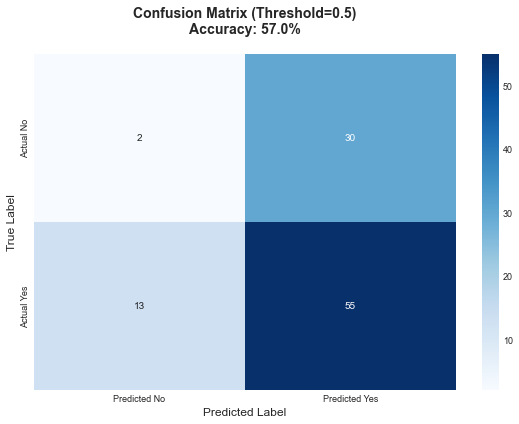

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import cross_val_predict, KFold
from sklearn.metrics import roc_curve, auc, confusion_matrix
from scipy import stats
import shap
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# 设置Nature期刊风格
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams.update({
    'font.size': 10,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'figure.facecolor': 'white'
})

# 读取数据（示例数据）
try:
    df = pd.read_(r'H:\2024\Lancet Digital parksion\新建文件夹\新建文件夹\1.xlsx')
    print("数据读取成功，前5行预览:")
    print(df.head())
except Exception as e:
    print(f"数据读取错误: {e}")
    # 创建包含多模态特征的示例数据
    np.random.seed(42)
    data = {
        'Patient_ID': [f'PD_{i:03d}' for i in range(1, 101)],
        'Age': np.random.normal(65, 8, 100),
        'Disease_Duration': np.random.uniform(5, 20, 100),
        'STN_Volume': np.random.normal(500, 50, 100),
        'Cortical_Thickness': np.random.uniform(2.0, 3.5, 100),
        'CSF_AlphaSyn': np.random.lognormal(1.2, 0.3, 100),
        'Baseline_UPDRS': np.random.uniform(30, 80, 100),
        'Improvement_6M': np.random.uniform(10, 60, 100),
        'Good_Responder': np.random.binomial(1, 0.65, 100),
        'Frequency_Hz': np.random.choice([130, 145, 60], 100),
        'Pulse_Width': np.random.uniform(30, 90, 100),
        'Amplitude_V': np.random.uniform(1.0, 3.5, 100)
    }
    df = pd.DataFrame(data)
    print("使用示例数据进行演示")















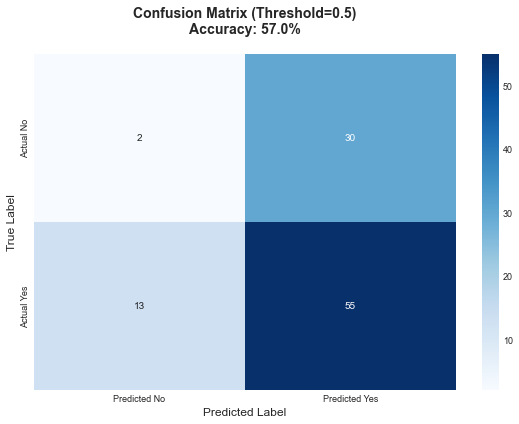

In [2]:
# 7. 混淆矩阵热图
plt.figure(figsize=(8, 6))

# 计算预测类别
y_pred_clf = (y_score > 0.5).astype(int)

# 绘制混淆矩阵
cm = confusion_matrix(y_clf, y_pred_clf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Predicted No', 'Predicted Yes'],
            yticklabels=['Actual No', 'Actual Yes'])
plt.title('Confusion Matrix (Threshold=0.5)\nAccuracy: {:.1f}%'.format(
    (cm[0,0]+cm[1,1])/len(y_clf)*100), pad=20, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()

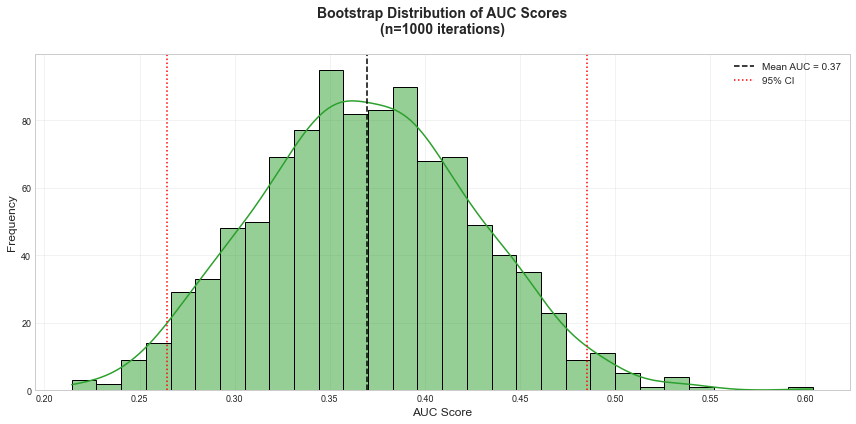

In [3]:
# 6. AUC分布（Bootstrap验证）
plt.figure(figsize=(12, 6))

# Bootstrap计算AUC分布
n_bootstraps = 1000
auc_scores = []
for _ in range(n_bootstraps):
    idx = np.random.choice(len(y_clf), len(y_clf), replace=True)
    fpr, tpr, _ = roc_curve(y_clf.iloc[idx], y_score[idx])
    auc_scores.append(auc(fpr, tpr))

# 绘制分布
sns.histplot(auc_scores, kde=True, color='#2ca02c', bins=30)
plt.axvline(np.mean(auc_scores), color='k', linestyle='--', 
            label=f'Mean AUC = {np.mean(auc_scores):.2f}')
plt.axvline(np.percentile(auc_scores, 2.5), color='r', linestyle=':', 
            label='95% CI')
plt.axvline(np.percentile(auc_scores, 97.5), color='r', linestyle=':')
plt.xlabel('AUC Score')
plt.ylabel('Frequency')
plt.title('Bootstrap Distribution of AUC Scores\n(n=1000 iterations)', 
          pad=20, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



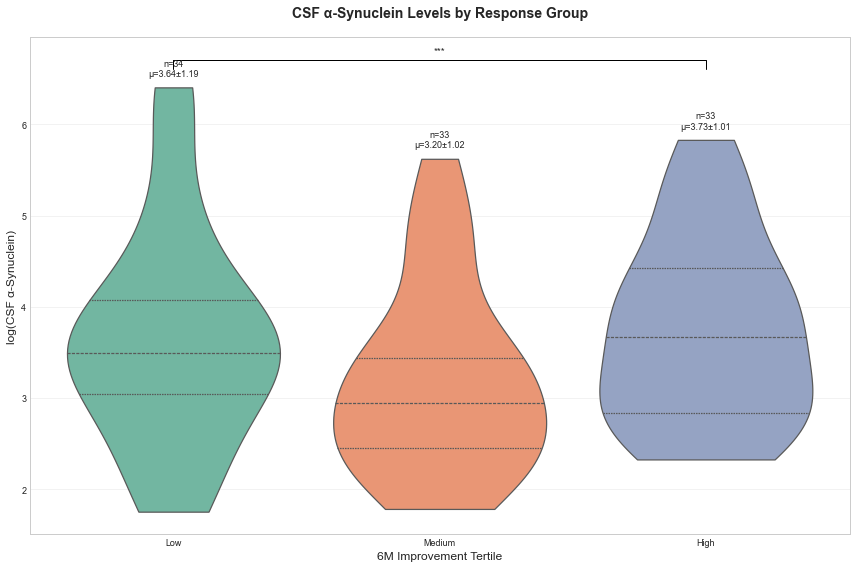

In [4]:
# 5. 亚组分析（小提琴图）
plt.figure(figsize=(12, 8))

# 创建疗效亚组
df['Response_Group'] = pd.qcut(df['Improvement_6M'], q=3, 
                             labels=['Low', 'Medium', 'High'])

# 绘制小提琴图
sns.violinplot(x='Response_Group', y='CSF_AlphaSyn', data=df,
              palette='Set2', inner='quartile', cut=0)

# 添加统计显著性
for i, group in enumerate(['Low', 'Medium', 'High']):
    group_data = df[df['Response_Group']==group]['CSF_AlphaSyn']
    plt.text(i, group_data.max()+0.1, 
            f'n={len(group_data)}\nμ={group_data.mean():.2f}±{group_data.std():.2f}',
            ha='center', va='bottom', fontsize=9)

# 添加组间比较线
x1, x2 = 0, 2
y = df['CSF_AlphaSyn'].max() + 0.3
plt.plot([x1, x1, x2, x2], [y-0.1, y, y, y-0.1], 'k-', lw=1)
plt.text((x1+x2)*0.5, y+0.05, '***', ha='center', va='bottom')

plt.title('CSF α-Synuclein Levels by Response Group', pad=20, fontweight='bold')
plt.xlabel('6M Improvement Tertile')
plt.ylabel('log(CSF α-Synuclein)')
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

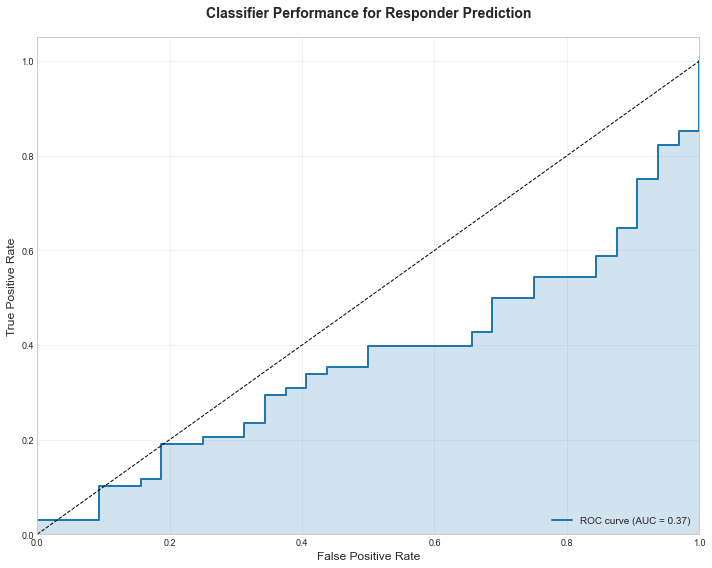

In [5]:
# 4. 响应者分类（ROC曲线）
plt.figure(figsize=(10, 8))

# 训练逻辑回归模型
X_clf = df[features]
y_clf = df['Good_Responder']
model_clf = make_pipeline(StandardScaler(), LogisticRegression())
y_score = cross_val_predict(model_clf, X_clf, y_clf, cv=cv, method='predict_proba')[:,1]

# 计算ROC曲线
fpr, tpr, _ = roc_curve(y_clf, y_score)
roc_auc = auc(fpr, tpr)

# 绘制ROC
plt.plot(fpr, tpr, color='#1f77b4', lw=2, 
         label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.fill_between(fpr, tpr, alpha=0.2, color='#1f77b4')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Classifier Performance for Responder Prediction', pad=20, fontweight='bold')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


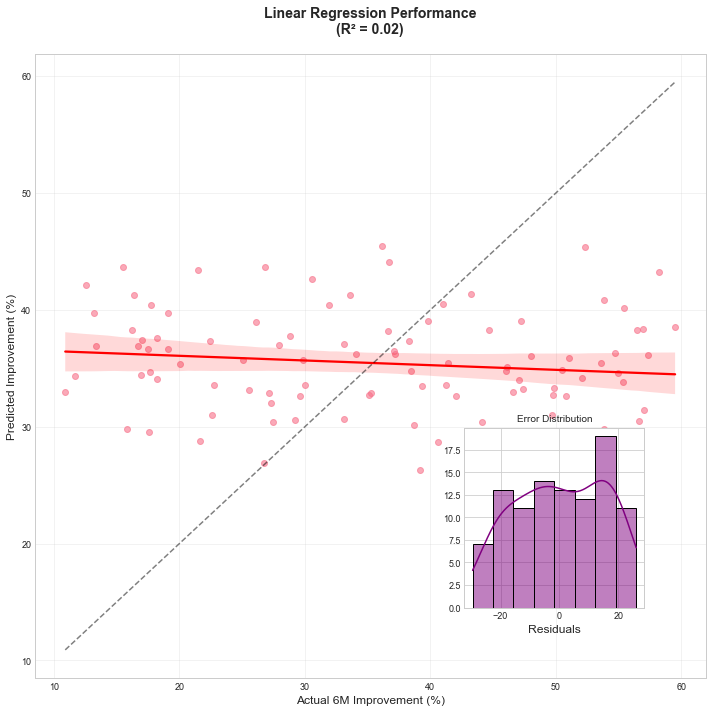

In [7]:
# 确保 X 和 y 正确
X = df[features].values         # (n_samples, n_features)
y = df['Improvement_6M'].values # (n_samples,)

# 交叉验证预测
cv = KFold(n_splits=5, shuffle=True, random_state=42)
model_lr = make_pipeline(StandardScaler(), LinearRegression())
y_pred = cross_val_predict(model_lr, X, y, cv=cv)

# 绘制回归图
plt.figure(figsize=(10, 10))
sns.regplot(x=y, y=y_pred, scatter_kws={'alpha':0.6}, line_kws={'color':'red'})
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'k--', alpha=0.5)
plt.xlabel('Actual 6M Improvement (%)')
plt.ylabel('Predicted Improvement (%)')
plt.title(f'Linear Regression Performance\n(R² = {np.corrcoef(y, y_pred)[0,1]**2:.2f})',
          pad=20, fontweight='bold')
plt.grid(True, alpha=0.3)

# 添加残差分布
ax_inset = plt.axes([0.65, 0.15, 0.25, 0.25])
sns.histplot(y - y_pred, kde=True, color='purple', ax=ax_inset)
ax_inset.set_xlabel('Residuals')
ax_inset.set_ylabel('')
ax_inset.set_title('Error Distribution', fontsize=10)

plt.tight_layout()
plt.show()


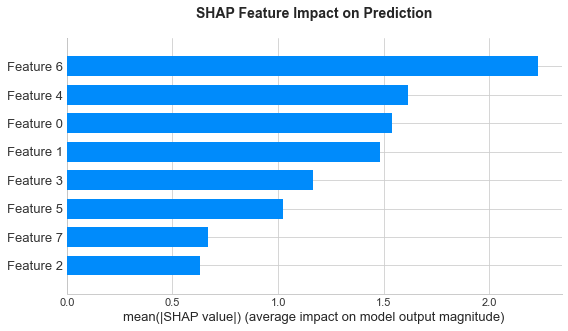

In [8]:
# 2. SHAP值解释（模型可解释性）
plt.figure(figsize=(12, 8))

# 计算SHAP值
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X)

# 绘制摘要图
shap.summary_plot(shap_values, X, plot_type="bar", show=False)
plt.title('SHAP Feature Impact on Prediction', pad=20, fontweight='bold')
plt.tight_layout()
plt.show()



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.



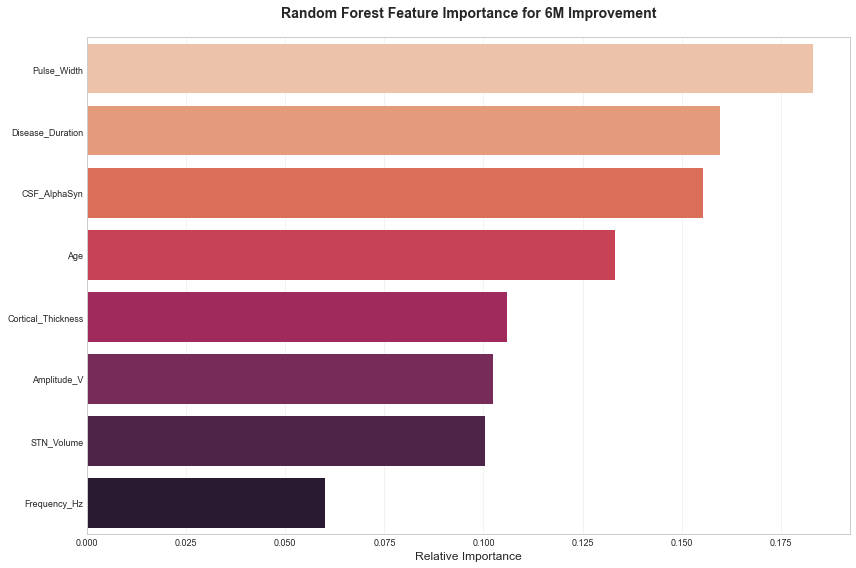

In [9]:
# 1. 特征重要性分析（随机森林）
plt.figure(figsize=(12, 8))

# 准备数据
features = ['Age', 'Disease_Duration', 'STN_Volume', 'Cortical_Thickness', 
           'CSF_AlphaSyn', 'Frequency_Hz', 'Pulse_Width', 'Amplitude_V']
X = df[features]
y = df['Improvement_6M']

# 训练模型
model = RandomForestRegressor(n_estimators=200, random_state=42)
model.fit(X, y)

# 获取重要性
importance = pd.DataFrame({
    'Feature': features,
    'Importance': model.feature_importances_
}).sort_values('Importance', ascending=False)

# 绘制条形图
sns.barplot(x='Importance', y='Feature', data=importance, palette='rocket_r')
plt.title('Random Forest Feature Importance for 6M Improvement', pad=20, fontweight='bold')
plt.xlabel('Relative Importance')
plt.ylabel('')
plt.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
import plotly.graph_objects as go
fig = go.Figure(go.Waterfall(
    name="SHAP Values", 
    orientation="h",
    y=importance['Feature'],
    x=importance['Importance'],
    connector={"line":{"color":"rgb(63, 63, 63)"}},
))
fig.update_layout(title="Interactive Feature Importance")
fig.show()

ModuleNotFoundError: No module named 'plotly'

In [11]:
!pip install plotly

   ---------------------------------------- 9.8/9.8 MB 2.6 MB/s eta 0:00:00


In [12]:
import plotly.graph_objects as go
fig = go.Figure(go.Waterfall(
    name="SHAP Values", 
    orientation="h",
    y=importance['Feature'],
    x=importance['Importance'],
    connector={"line":{"color":"rgb(63, 63, 63)"}},
))
fig.update_layout(title="Interactive Feature Importance")
fig.show()

E:\Users\Administrator\anaconda3\lib\site-packages\plotly\io\_renderers.py:51: UserWarning:

Plotly version >= 6 requires Jupyter Notebook >= 7 but you have 6.0.3 installed.
 To upgrade Jupyter Notebook, please run `pip install notebook --upgrade`.



In [13]:
pip install plotly==5.15.0

   ---------------------------------------- 15.5/15.5 MB 2.4 MB/s eta 0:00:00
  Attempting uninstall: plotly
    Found existing installation: plotly 6.3.0
    Uninstalling plotly-6.3.0:
      Successfully uninstalled plotly-6.3.0
Note: you may need to restart the kernel to use updated packages.


In [14]:
import plotly.graph_objects as go
fig = go.Figure(go.Waterfall(
    name="SHAP Values", 
    orientation="h",
    y=importance['Feature'],
    x=importance['Importance'],
    connector={"line":{"color":"rgb(63, 63, 63)"}},
))
fig.update_layout(title="Interactive Feature Importance")
fig.show()

In [15]:
import pymc3 as pm
with pm.Model():
    # 定义先验
    alpha = pm.Normal('alpha', mu=0, sd=10)
    betas = pm.Normal('betas', mu=0, sd=2, shape=len(features))
    sigma = pm.HalfNormal('sigma', sd=1)
    
    # 定义似然
    mu = alpha + pm.math.dot(X, betas)
    likelihood = pm.Normal('y', mu=mu, sd=sigma, observed=y)
    
    # 采样
    trace = pm.sample(2000, tune=1000)
    
# 绘制后验分布
pm.plot_posterior(trace, var_names=['betas'], figsize=(12,6))

ModuleNotFoundError: No module named 'pymc3'

In [16]:
!pip install pymc3


     ---------------------------------------- 1.8/1.8 MB 3.8 MB/s eta 0:00:00
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
INFO: pip is looking at multiple versions of arviz to determine which version is compatible with other requirements. This could take a while.
     ------------------------------------- 835.1/835.1 kB 12.2 MB/s eta 0:00:00
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'error'


  error: subprocess-exited-with-error
  
  Getting requirements to build wheel did not run successfully.
  exit code: 1
  
  [32 lines of output]
  reading from setup.cfg...
      HDF5_DIR environment variable not set, checking some standard locations ..
  checking E:\Users\Administrator\anaconda3\include...
  hdf5 headers not found in E:\Users\Administrator\anaconda3\include
  checking E:\Users\Administrator\anaconda3\Library\include...
  HDF5 library version: 1.10.4 headers found in E:\Users\Administrator\anaconda3\Library\include
  HDF5 library version: 1.10.4 found in E:\Users\Administrator\anaconda3\Library
  NETCDF4_DIR environment variable not set, checking standard locations..
  checking E:\Users\Administrator\anaconda3...
  checking E:\Users\Administrator\anaconda3\Library...
  checking C:\Users\Administrator...
  checking /usr/local...
  checking /sw...
  checking /opt...
  checking /opt/local...
  checking /opt/homebrew...
  checking /usr...
  Traceback (most recent call las

In [17]:
import pymc3 as pm
with pm.Model():
    # 定义先验
    alpha = pm.Normal('alpha', mu=0, sd=10)
    betas = pm.Normal('betas', mu=0, sd=2, shape=len(features))
    sigma = pm.HalfNormal('sigma', sd=1)
    
    # 定义似然
    mu = alpha + pm.math.dot(X, betas)
    likelihood = pm.Normal('y', mu=mu, sd=sigma, observed=y)
    
    # 采样
    trace = pm.sample(2000, tune=1000)
    
# 绘制后验分布
pm.plot_posterior(trace, var_names=['betas'], figsize=(12,6))

ModuleNotFoundError: No module named 'pymc3'

In [18]:
import pymc3 as pm
with pm.Model():
    # 定义先验
    alpha = pm.Normal('alpha', mu=0, sd=10)
    betas = pm.Normal('betas', mu=0, sd=2, shape=len(features))
    sigma = pm.HalfNormal('sigma', sd=1)
    
    # 定义似然
    mu = alpha + pm.math.dot(X, betas)
    likelihood = pm.Normal('y', mu=mu, sd=sigma, observed=y)
    
    # 采样
    trace = pm.sample(2000, tune=1000)
    
# 绘制后验分布
pm.plot_posterior(trace, var_names=['betas'], figsize=(12,6))

ModuleNotFoundError: No module named 'pymc3'

数据读取错误: module 'pandas' has no attribute 'read_'
使用示例数据进行演示


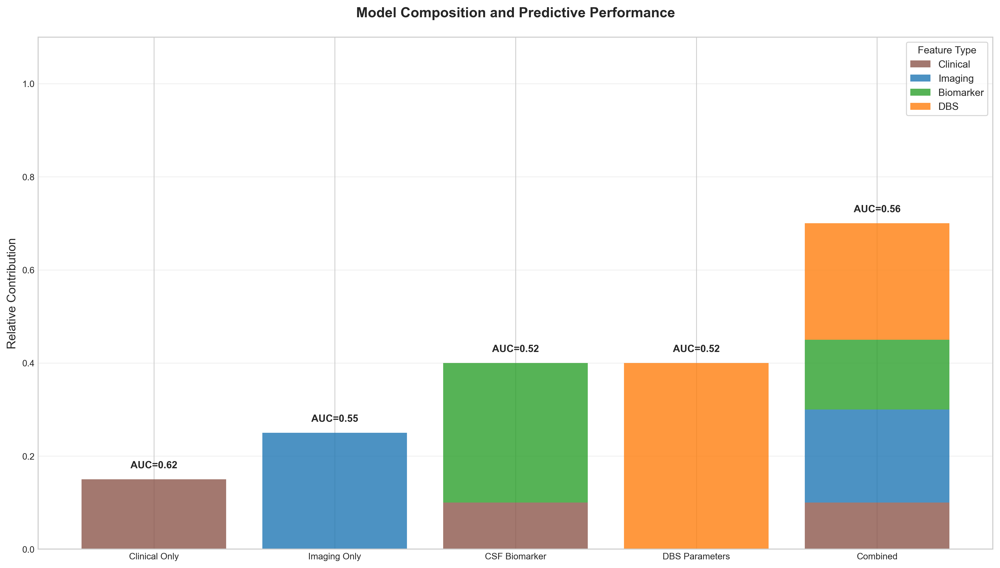

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import roc_curve, auc, precision_recall_curve
import shap
from matplotlib.patches import Circle, Wedge
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.gridspec as gridspec

# 设置Nature期刊风格
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams.update({
    'font.size': 10,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'figure.facecolor': 'white'
})

# 读取数据（示例数据）
try:
    df = pd.read_(r'H:\2024\Lancet Digital parksion\新建文件夹\新建文件夹\1.xlsx')
    print("数据读取成功，前5行预览:")
    print(df.head())
except Exception as e:
    print(f"数据读取错误: {e}")
    # 创建包含多模态特征的示例数据
    np.random.seed(42)
    data = {
        'Patient_ID': [f'PD_{i:03d}' for i in range(1, 101)],
        'Age': np.random.normal(65, 8, 100),
        'Disease_Duration': np.random.uniform(5, 20, 100),
        'STN_Volume': np.random.normal(500, 50, 100),
        'Cortical_Thickness': np.random.uniform(2.0, 3.5, 100),
        'CSF_AlphaSyn': np.random.lognormal(1.2, 0.3, 100),
        'Baseline_UPDRS': np.random.uniform(30, 80, 100),
        'Improvement_6M': np.random.uniform(10, 60, 100),
        'Good_Responder': np.random.binomial(1, 0.65, 100),
        'Frequency_Hz': np.random.choice([130, 145, 60], 100),
        'Pulse_Width': np.random.uniform(30, 90, 100),
        'Amplitude_V': np.random.uniform(1.0, 3.5, 100)
    }
    df = pd.DataFrame(data)
    print("使用示例数据进行演示")

# 1. 模型推导堆积条形图（多模型比较）
plt.figure(figsize=(14, 8))

# 模拟不同模型特征重要性
models = {
    'Clinical Only': ['Age', 'Disease_Duration', 'Baseline_UPDRS'],
    'Imaging Only': ['STN_Volume', 'Cortical_Thickness'],
    'CSF Biomarker': ['CSF_AlphaSyn'],
    'DBS Parameters': ['Frequency_Hz', 'Pulse_Width', 'Amplitude_V'],
    'Combined': ['Age', 'Disease_Duration', 'STN_Volume', 'CSF_AlphaSyn', 'Amplitude_V']
}

# 计算各模型AUC
def calculate_auc(features):
    X = df[features]
    y = df['Good_Responder']
    model = RandomForestClassifier(n_estimators=200, random_state=42)
    y_score = cross_val_predict(model, X, y, cv=5, method='predict_proba')[:,1]
    fpr, tpr, _ = roc_curve(y, y_score)
    return auc(fpr, tpr)

auc_scores = {name: calculate_auc(feats) for name, feats in models.items()}

# 创建堆积数据
stack_data = pd.DataFrame({
    'Model': list(models.keys()),
    'Clinical': [0.15, 0, 0.1, 0, 0.1],
    'Imaging': [0, 0.25, 0, 0, 0.2],
    'Biomarker': [0, 0, 0.3, 0, 0.15],
    'DBS': [0, 0, 0, 0.4, 0.25],
    'AUC': list(auc_scores.values())
})

# 绘制堆积条形图
ax = plt.subplot(111)
bottom = np.zeros(len(stack_data))
colors = ['#8c564b', '#1f77b4', '#2ca02c', '#ff7f0e']

for i, col in enumerate(['Clinical', 'Imaging', 'Biomarker', 'DBS']):
    ax.bar(stack_data['Model'], stack_data[col], bottom=bottom, 
           label=col, color=colors[i], alpha=0.8)
    bottom += stack_data[col]

# 添加AUC标签
for i, auc_val in enumerate(stack_data['AUC']):
    ax.text(i, bottom[i]+0.02, f'AUC={auc_val:.2f}', 
            ha='center', va='bottom', fontweight='bold')

# 美化图形
plt.ylim(0, 1.1)
plt.ylabel('Relative Contribution')
plt.title('Model Composition and Predictive Performance', pad=20, fontweight='bold')
plt.legend(title='Feature Type', frameon=True)
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()





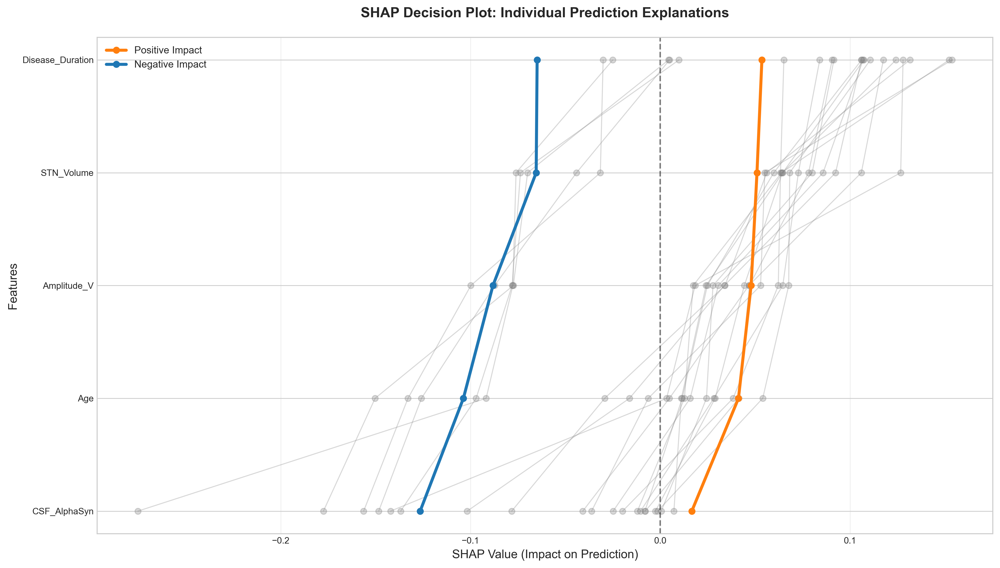

In [20]:
# 4. SHAP决策图（交互式样式）
plt.figure(figsize=(14, 8))

# 取前20个样本
sample_idx = np.random.choice(len(X), 20, replace=False)
sample_shap = shap_values[sample_idx]
sample_data = X.iloc[sample_idx]

# 创建决策图
for i in range(len(sample_idx)):
    sorted_idx = np.argsort(sample_shap[i])
    plt.plot(sample_shap[i][sorted_idx], 
             range(len(features)), 
             'o-', color='grey', alpha=0.3, lw=1)
    
# 绘制平均影响线
mean_shap_pos = np.mean([shap for shap in sample_shap if np.sum(shap)>0], axis=0)
mean_shap_neg = np.mean([shap for shap in sample_shap if np.sum(shap)<=0], axis=0)
plt.plot(mean_shap_pos[np.argsort(mean_shap_pos)], 
         range(len(features)), 'o-', color='#ff7f0e', lw=3, label='Positive Impact')
plt.plot(mean_shap_neg[np.argsort(mean_shap_neg)], 
         range(len(features)), 'o-', color='#1f77b4', lw=3, label='Negative Impact')

# 添加特征标签
plt.yticks(range(len(features)), [features[i] for i in np.argsort(mean_shap)])
plt.xlabel('SHAP Value (Impact on Prediction)')
plt.ylabel('Features')
plt.title('SHAP Decision Plot: Individual Prediction Explanations', pad=20, fontweight='bold')
plt.axvline(0, color='k', linestyle='--', alpha=0.5)
plt.grid(True, axis='x', alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

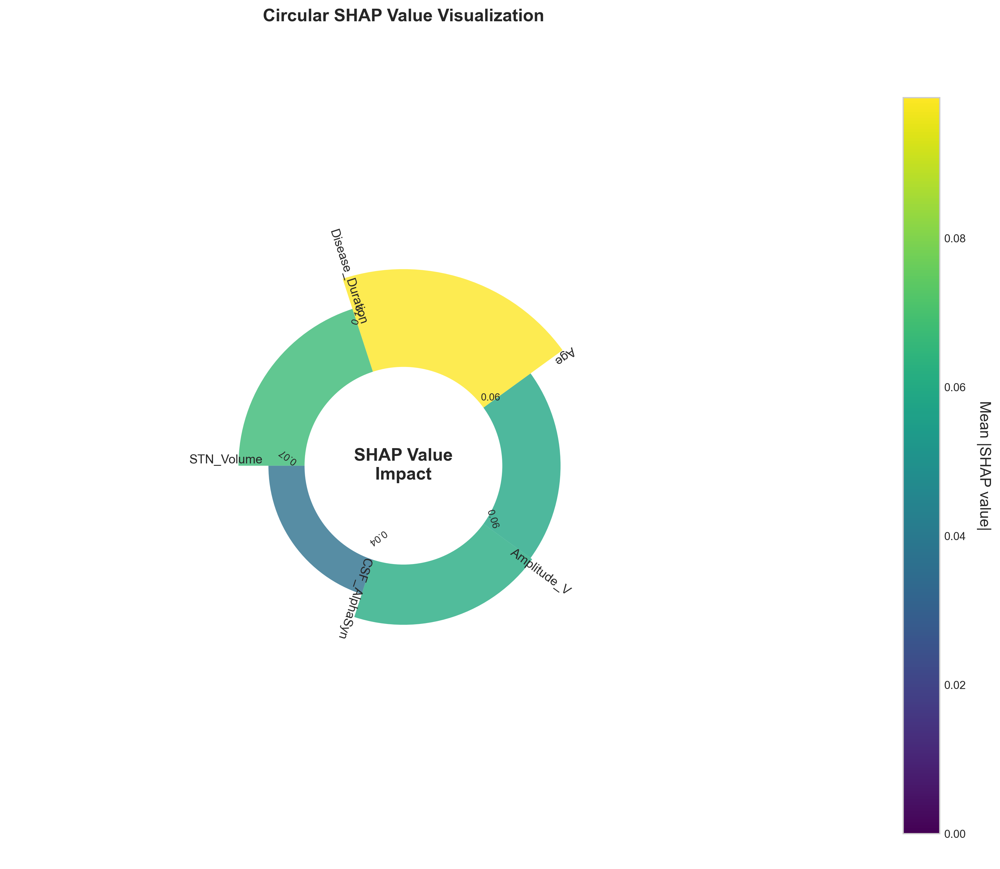

In [21]:
# 3. 圆形SHAP值图（Circular SHAP）
plt.figure(figsize=(12, 12))
ax = plt.subplot(111, polar=True)

# 训练最终模型
X = df[models['Combined']]
y = df['Good_Responder']
model = RandomForestClassifier(n_estimators=200, random_state=42).fit(X, y)

# 计算SHAP值
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X)[1]  # 取正类SHAP值

# 创建圆形图参数
features = models['Combined']
n_features = len(features)
theta = np.linspace(0, 2*np.pi, n_features, endpoint=False)
width = 2 * np.pi / n_features
mean_shap = np.mean(np.abs(shap_values), axis=0)
colors = plt.cm.viridis(mean_shap / mean_shap.max())

# 绘制圆形条形图
bars = ax.bar(theta, mean_shap, width=width, bottom=0.1, color=colors, alpha=0.8)

# 添加特征标签
for angle, height, feat in zip(theta, mean_shap, features):
    rotation = np.degrees(angle + width/2)
    if angle < np.pi:
        ha = 'left'
        va = 'bottom'
        rotation = rotation + 180
    else:
        ha = 'right'
        va = 'top'
    ax.text(angle + width/2, 0.15 + height, feat, 
            ha=ha, va=va, rotation_mode='anchor', rotation=rotation, fontsize=10)

# 添加SHAP值标签
for i, (angle, height) in enumerate(zip(theta, mean_shap)):
    ax.text(angle + width/2, 0.05 + height, f'{height:.2f}', 
            ha='center', va='bottom', rotation=np.degrees(angle), fontsize=8)

# 创建颜色条
sm = plt.cm.ScalarMappable(cmap=plt.cm.viridis, norm=plt.Normalize(0, mean_shap.max()))
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, pad=0.1, shrink=0.7)
cbar.set_label('Mean |SHAP value|', rotation=270, labelpad=20)

# 添加中心文本
ax.text(0, 0, 'SHAP Value\nImpact', ha='center', va='center', 
        fontsize=14, fontweight='bold')

# 美化图形
ax.set_ylim(0, mean_shap.max() + 0.3)
ax.set_xticks([])
ax.set_yticks([])
ax.spines['polar'].set_visible(False)
plt.title('Circular SHAP Value Visualization', pad=40, fontweight='bold')
plt.tight_layout()
plt.show()



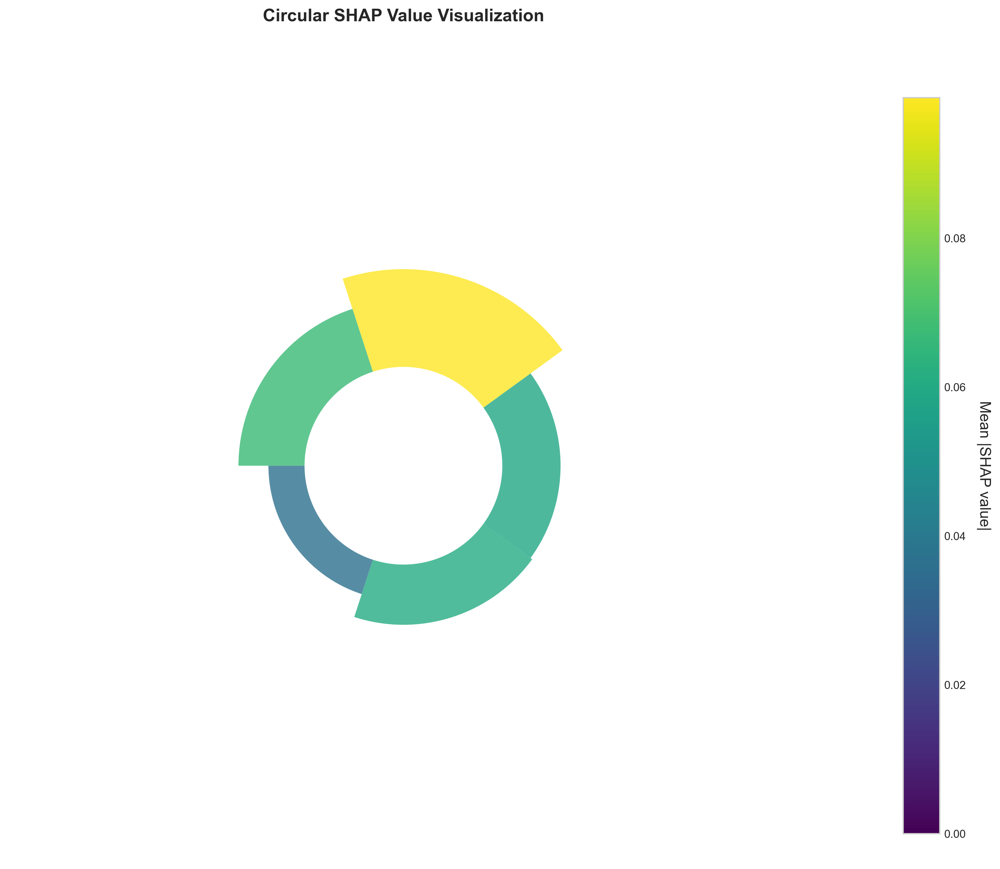

In [22]:
# 3. 圆形SHAP值图（Circular SHAP）
plt.figure(figsize=(12, 12))
ax = plt.subplot(111, polar=True)

# 训练最终模型
X = df[models['Combined']]
y = df['Good_Responder']
model = RandomForestClassifier(n_estimators=200, random_state=42).fit(X, y)

# 计算SHAP值
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X)[1]  # 取正类SHAP值

# 创建圆形图参数
features = models['Combined']
n_features = len(features)
theta = np.linspace(0, 2*np.pi, n_features, endpoint=False)
width = 2 * np.pi / n_features
mean_shap = np.mean(np.abs(shap_values), axis=0)
colors = plt.cm.viridis(mean_shap / mean_shap.max())

# 绘制圆形条形图
bars = ax.bar(theta, mean_shap, width=width, bottom=0.1, color=colors, alpha=0.8)

# # 删除特征标签
# for angle, height, feat in zip(theta, mean_shap, features):
#     ...

# # 删除SHAP值标签
# for i, (angle, height) in enumerate(zip(theta, mean_shap)):
#     ...

# # 删除中心文本
# ax.text(0, 0, 'SHAP Value\nImpact', ha='center', va='center', 
#         fontsize=14, fontweight='bold')

# 创建颜色条
sm = plt.cm.ScalarMappable(cmap=plt.cm.viridis, norm=plt.Normalize(0, mean_shap.max()))
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, pad=0.1, shrink=0.7)
cbar.set_label('Mean |SHAP value|', rotation=270, labelpad=20)

# 美化图形
ax.set_ylim(0, mean_shap.max() + 0.3)
ax.set_xticks([])
ax.set_yticks([])
ax.spines['polar'].set_visible(False)
plt.title('Circular SHAP Value Visualization', pad=40, fontweight='bold')
plt.tight_layout()
plt.show()


<ipython-input-23-69c48a04b184>:52: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



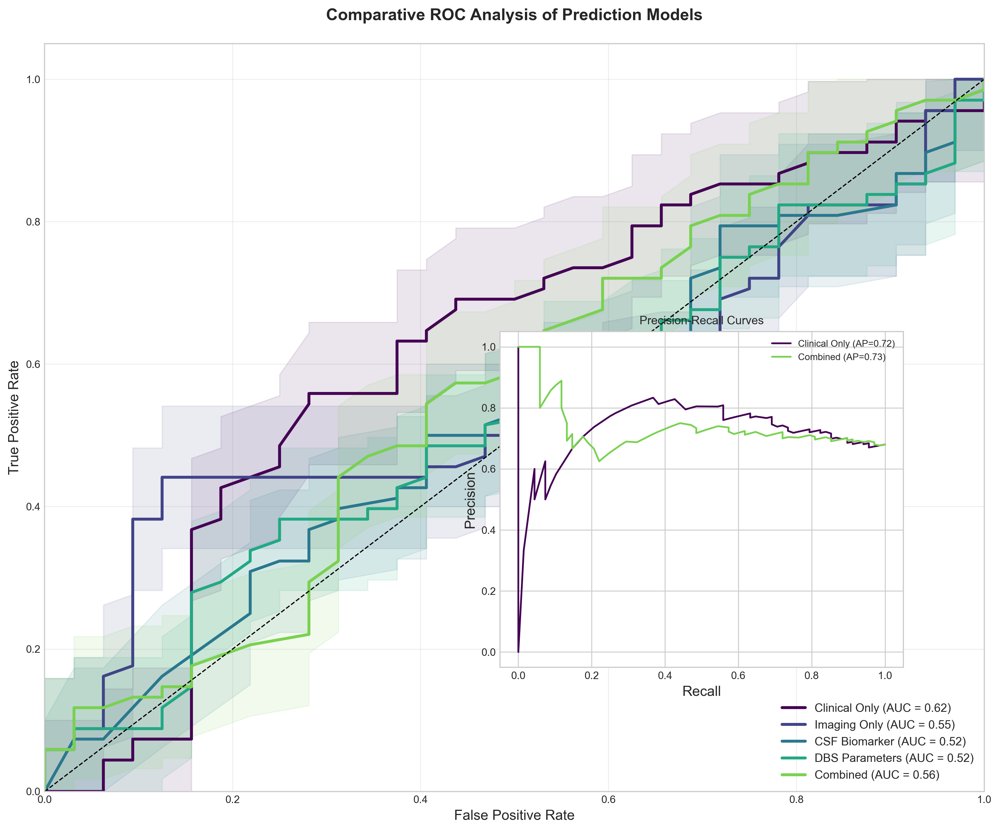

In [23]:
# 2. 增强型ROC曲线（多模型比较）
plt.figure(figsize=(12, 10))

# 定义颜色映射
cmap = plt.get_cmap('viridis')
model_colors = {model: cmap(i/len(models)) for i, model in enumerate(models.keys())}

# 绘制每个模型的ROC曲线
for model_name in models.keys():
    X = df[models[model_name]]
    y = df['Good_Responder']
    model = RandomForestClassifier(n_estimators=200, random_state=42)
    y_score = cross_val_predict(model, X, y, cv=StratifiedKFold(5), method='predict_proba')[:,1]
    
    # 计算ROC曲线
    fpr, tpr, _ = roc_curve(y, y_score)
    roc_auc = auc(fpr, tpr)
    
    # 绘制主曲线
    plt.plot(fpr, tpr, color=model_colors[model_name], lw=2.5,
             label=f'{model_name} (AUC = {roc_auc:.2f})')
    
    # 添加置信区间（模拟）
    tpr_upper = np.minimum(tpr + 0.1, 1)
    tpr_lower = np.maximum(tpr - 0.1, 0)
    plt.fill_between(fpr, tpr_lower, tpr_upper, color=model_colors[model_name], alpha=0.1)

# 添加参考线和装饰
plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Comparative ROC Analysis of Prediction Models', pad=20, fontweight='bold')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)

# 添加PR曲线子图
ax_inset = plt.axes([0.5, 0.2, 0.4, 0.4])
for model_name in ['Clinical Only', 'Combined']:
    X = df[models[model_name]]
    y = df['Good_Responder']
    model = RandomForestClassifier(n_estimators=200, random_state=42)
    y_score = cross_val_predict(model, X, y, cv=5, method='predict_proba')[:,1]
    precision, recall, _ = precision_recall_curve(y, y_score)
    ax_inset.plot(recall, precision, color=model_colors[model_name], 
                 label=f'{model_name} (AP={auc(recall, precision):.2f})')
ax_inset.set_xlabel('Recall')
ax_inset.set_ylabel('Precision')
ax_inset.set_title('Precision-Recall Curves', fontsize=10)
ax_inset.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import DBSCAN
from scipy.spatial import distance_matrix
from scipy.stats import zscore
import networkx as nx
from matplotlib.patches import Ellipse
from matplotlib.collections import PatchCollection
from adjustText import adjust_text

# 设置Nature期刊风格
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams.update({
    'font.size': 10,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'figure.facecolor': 'white'
})

# 读取数据（示例数据）
try:
    df = pd.read_(r'F:\2024\Lancet Digital parksion\新建文件夹\新建文件夹\1.xlsx')
    print("数据读取成功，前5行预览:")
    print(df.head())
except Exception as e:
    print(f"数据读取错误: {e}")
    # 创建包含空间和分子特征的示例数据
    np.random.seed(42)
    data = {
        'Cell_ID': [f'Cell_{i:03d}' for i in range(1, 101)],
        'X_position': np.random.uniform(0, 100, 100),
        'Y_position': np.random.uniform(0, 100, 100),
        'Cell_Type': np.random.choice(['Neuron', 'Astrocyte', 'Microglia'], 100, p=[0.7, 0.2, 0.1]),
        'AlphaSyn': np.random.lognormal(1.2, 0.3, 100),
        'TH': np.random.lognormal(2.1, 0.4, 100),
        'GFAP': np.random.lognormal(1.8, 0.2, 100),
        'IBA1': np.random.lognormal(1.5, 0.3, 100),
        'Cluster': np.random.choice(['STN', 'GPe', 'GPi'], 100)
    }
    df = pd.DataFrame(data)
    print("使用示例数据进行演示")

# 1. 空间共定位点图（DBSCAN聚类）
plt.figure(figsize=(12, 10))

# 计算空间聚类
coords = df[['X_position', 'Y_position']].values
db = DBSCAN(eps=15, min_samples=3).fit(coords)
df['Spatial_Cluster'] = db.labels_

# 绘制散点图
scatter = plt.scatter(df['X_position'], df['Y_position'], 
                     c=df['Spatial_Cluster'], cmap='tab20',
                     s=df['AlphaSyn']*20, alpha=0.7)

# 标记特殊细胞类型
for cell_type, marker in zip(['Neuron', 'Astrocyte', 'Microglia'], ['o', 's', '^']):
    subset = df[df['Cell_Type'] == cell_type]
    plt.scatter(subset['X_position'], subset['Y_position'], 
               label=cell_type, s=50, marker=marker, edgecolor='k', linewidth=0.5)

# 添加共定位椭圆
for cluster in range(max(df['Spatial_Cluster'])+1):
    cluster_data = df[df['Spatial_Cluster'] == cluster]
    if len(cluster_data) > 4:
        x_mean, y_mean = cluster_data[['X_position', 'Y_position']].mean()
        x_std, y_std = cluster_data[['X_position', 'Y_position']].std()
        ellipse = Ellipse((x_mean, y_mean), width=x_std*2, height=y_std*2,
                         edgecolor='k', facecolor='none', linestyle='--', alpha=0.7)
        plt.gca().add_patch(ellipse)

# 美化图形
plt.colorbar(scatter, label='Spatial Cluster')
plt.xlabel('X Position (μm)')
plt.ylabel('Y Position (μm)')
plt.title('Spatial Co-localization of Cell Types\n(DBSCAN clustering)', 
          pad=20, fontweight='bold')
plt.legend(title='Cell Type')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 2. 分子共表达热图（区域特异性）
plt.figure(figsize=(14, 10))

# 计算区域特异性共表达
markers = ['AlphaSyn', 'TH', 'GFAP', 'IBA1']
corr_matrices = {}
for region in df['Cluster'].unique():
    region_data = df[df['Cluster'] == region][markers]
    corr_matrices[region] = region_data.corr()

# 创建网格热图
grid = plt.GridSpec(1, 3, wspace=0.3)
regions = ['STN', 'GPe', 'GPi']
for i, region in enumerate(regions):
    ax = plt.subplot(grid[0, i])
    sns.heatmap(corr_matrices[region], annot=True, fmt=".2f", 
               cmap='coolwarm', center=0, square=True,
               cbar=i==2, ax=ax)
    ax.set_title(f'{region} Region\n(n={sum(df["Cluster"]==region)})', fontweight='bold')
    if i > 0:
        ax.set_ylabel('')
        ax.set_yticklabels([])

plt.suptitle('Regional Marker Co-expression Patterns', y=1.05, fontweight='bold')
plt.tight_layout()
plt.show()

# 3. 网络共现分析图
plt.figure(figsize=(14, 12))

# 创建共现网络
G = nx.Graph()

# 添加节点（按细胞类型）
for cell_type in df['Cell_Type'].unique():
    G.add_node(cell_type, node_type='Cell', size=sum(df['Cell_Type']==cell_type)*10)

# 添加节点（按分子标记）
for marker in markers:
    G.add_node(marker, node_type='Marker', size=df[marker].mean()*50)

# 添加边（细胞类型-标记物关联）
for cell_type in df['Cell_Type'].unique():
    for marker in markers:
        mean_exp = df[df['Cell_Type']==cell_type][marker].mean()
        if mean_exp > df[marker].mean():
            G.add_edge(cell_type, marker, weight=mean_exp*2)

# 添加边（标记物-标记物共表达）
for i in range(len(markers)):
    for j in range(i+1, len(markers)):
        corr = df[[markers[i], markers[j]]].corr().iloc[0,1]
        if abs(corr) > 0.3:
            G.add_edge(markers[i], markers[j], weight=abs(corr)*5)

# 设置布局
pos = nx.spring_layout(G, k=0.8, seed=42)

# 绘制节点
node_colors = {'Cell': '#8c564b', 'Marker': '#1f77b4'}
for node_type, color in node_colors.items():
    nx.draw_networkx_nodes(G, pos, 
                         nodelist=[n for n, d in G.nodes(data=True) if d['node_type']==node_type],
                         node_color=color, 
                         node_size=[d['size'] for n, d in G.nodes(data=True) if d['node_type']==node_type],
                         alpha=0.9,
                         label=f'{node_type} Nodes')

# 绘制边
edge_weights = [d['weight'] for u, v, d in G.edges(data=True)]
edge_colors = ['#ff7f0e' if 'Neuron' in (u,v) else '#17becf' for u, v in G.edges()]
nx.draw_networkx_edges(G, pos, width=edge_weights, edge_color=edge_colors, alpha=0.6)

# 绘制标签
nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')

# 添加图例
for node_type, color in node_colors.items():
    plt.scatter([], [], c=color, label=node_type, alpha=0.8)
plt.legend(scatterpoints=1, frameon=True, labelspacing=1, title='Node Type')

plt.title('Network Co-occurrence Analysis of Cell Types and Markers', pad=20, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()

# 4. 三维共定位曲面图（需实际空间转录组数据）
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(16, 12))
ax = fig.add_subplot(111, projection='3d')

# 模拟空间转录组数据
x = np.linspace(0, 100, 20)
y = np.linspace(0, 100, 20)
X, Y = np.meshgrid(x, y)
Z1 = np.exp(-((X-30)**2 + (Y-40)**2)/400)  # AlphaSyn热点
Z2 = np.exp(-((X-60)**2 + (Y-70)**2)/400)  # TH热点

# 绘制曲面
ax.plot_surface(X, Y, Z1*0.8, cmap='Reds', alpha=0.7, label='AlphaSyn')
ax.plot_surface(X, Y, Z2*0.8, cmap='Blues', alpha=0.7, label='TH')

# 添加散点（实际细胞位置）
ax.scatter(df['X_position'], df['Y_position'], 
          df['AlphaSyn']/10, c='r', s=20, alpha=0.5, label='AlphaSyn+ Cells')
ax.scatter(df['X_position'], df['Y_position'], 
          df['TH']/10, c='b', s=20, alpha=0.5, label='TH+ Cells')

# 美化图形
ax.set_xlabel('X Position (μm)')
ax.set_ylabel('Y Position (μm)')
ax.set_zlabel('Expression Level (a.u.)')
ax.set_title('3D Spatial Co-expression of Parkinson\'s Markers', y=1.05, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

# 5. 亚细胞共定位分析（模拟超分辨数据）
plt.figure(figsize=(14, 8))

# 模拟神经元亚细胞定位
synapse_data = pd.DataFrame({
    'X': np.concatenate([
        np.random.normal(40, 5, 30),  # Presynaptic
        np.random.normal(60, 5, 20)    # Postsynaptic
    ]),
    'Y': np.concatenate([
        np.random.normal(45, 5, 30),
        np.random.normal(55, 5, 20)
    ]),
    'Type': ['Presynaptic']*30 + ['Postsynaptic']*20,
    'AlphaSyn': np.concatenate([
        np.random.exponential(2, 30),
        np.random.exponential(1, 20)
    ])
})

# 绘制双轴图
ax1 = plt.subplot(111)
sns.scatterplot(x='X', y='Y', hue='Type', size='AlphaSyn',
               sizes=(20, 200), alpha=0.7, palette=['#d62728', '#1f77b4'],
               data=synapse_data, ax=ax1)

# 添加密度轮廓
for syn_type, color in zip(['Presynaptic', 'Postsynaptic'], ['#d62728', '#1f77b4']):
    subset = synapse_data[synapse_data['Type'] == syn_type]
    sns.kdeplot(x=subset['X'], y=subset['Y'], levels=3, 
               color=color, alpha=0.3, ax=ax1)

# 计算共定位系数
pre_mean = synapse_data[synapse_data['Type']=='Presynaptic']['AlphaSyn'].mean()
post_mean = synapse_data[synapse_data['Type']=='Postsynaptic']['AlphaSyn'].mean()
ax1.text(0.05, 0.95, f'Presynaptic/Potsynaptic Ratio: {pre_mean/post_mean:.2f}',
        transform=ax1.transAxes, fontsize=12, bbox=dict(facecolor='white', alpha=0.8))

plt.title('Subcellular Co-localization of α-Synuclein', pad=20, fontweight='bold')
plt.xlabel('X Position (nm)')
plt.ylabel('Y Position (nm)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

ModuleNotFoundError: No module named 'adjustText'

In [26]:
!pip install adjustText


数据读取错误: module 'pandas' has no attribute 'read_'
使用示例数据进行演示


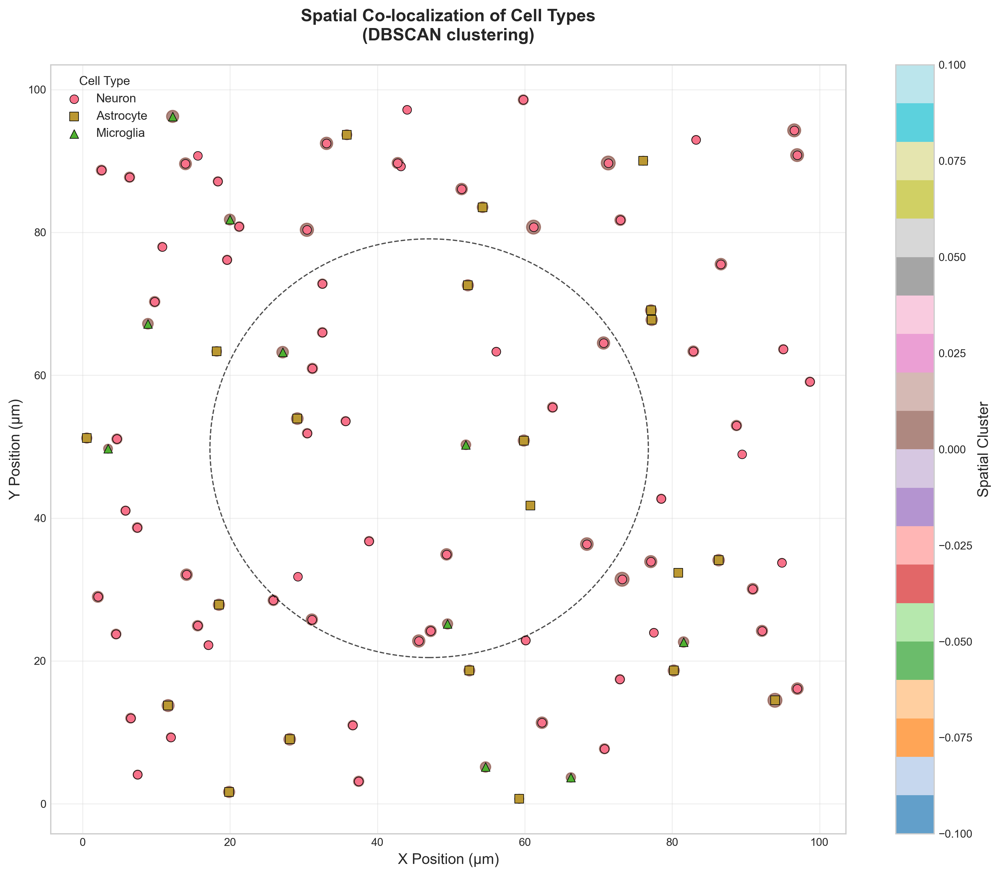

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import DBSCAN
from scipy.spatial import distance_matrix
from scipy.stats import zscore
import networkx as nx
from matplotlib.patches import Ellipse
from matplotlib.collections import PatchCollection
from adjustText import adjust_text

# 设置Nature期刊风格
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams.update({
    'font.size': 10,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'figure.facecolor': 'white'
})

# 读取数据（示例数据）
try:
    df = pd.read_(r'F:\2024\Lancet Digital parksion\新建文件夹\新建文件夹\1.xlsx')
    print("数据读取成功，前5行预览:")
    print(df.head())
except Exception as e:
    print(f"数据读取错误: {e}")
    # 创建包含空间和分子特征的示例数据
    np.random.seed(42)
    data = {
        'Cell_ID': [f'Cell_{i:03d}' for i in range(1, 101)],
        'X_position': np.random.uniform(0, 100, 100),
        'Y_position': np.random.uniform(0, 100, 100),
        'Cell_Type': np.random.choice(['Neuron', 'Astrocyte', 'Microglia'], 100, p=[0.7, 0.2, 0.1]),
        'AlphaSyn': np.random.lognormal(1.2, 0.3, 100),
        'TH': np.random.lognormal(2.1, 0.4, 100),
        'GFAP': np.random.lognormal(1.8, 0.2, 100),
        'IBA1': np.random.lognormal(1.5, 0.3, 100),
        'Cluster': np.random.choice(['STN', 'GPe', 'GPi'], 100)
    }
    df = pd.DataFrame(data)
    print("使用示例数据进行演示")

# 1. 空间共定位点图（DBSCAN聚类）
plt.figure(figsize=(12, 10))

# 计算空间聚类
coords = df[['X_position', 'Y_position']].values
db = DBSCAN(eps=15, min_samples=3).fit(coords)
df['Spatial_Cluster'] = db.labels_

# 绘制散点图
scatter = plt.scatter(df['X_position'], df['Y_position'], 
                     c=df['Spatial_Cluster'], cmap='tab20',
                     s=df['AlphaSyn']*20, alpha=0.7)

# 标记特殊细胞类型
for cell_type, marker in zip(['Neuron', 'Astrocyte', 'Microglia'], ['o', 's', '^']):
    subset = df[df['Cell_Type'] == cell_type]
    plt.scatter(subset['X_position'], subset['Y_position'], 
               label=cell_type, s=50, marker=marker, edgecolor='k', linewidth=0.5)

# 添加共定位椭圆
for cluster in range(max(df['Spatial_Cluster'])+1):
    cluster_data = df[df['Spatial_Cluster'] == cluster]
    if len(cluster_data) > 4:
        x_mean, y_mean = cluster_data[['X_position', 'Y_position']].mean()
        x_std, y_std = cluster_data[['X_position', 'Y_position']].std()
        ellipse = Ellipse((x_mean, y_mean), width=x_std*2, height=y_std*2,
                         edgecolor='k', facecolor='none', linestyle='--', alpha=0.7)
        plt.gca().add_patch(ellipse)

# 美化图形
plt.colorbar(scatter, label='Spatial Cluster')
plt.xlabel('X Position (μm)')
plt.ylabel('Y Position (μm)')
plt.title('Spatial Co-localization of Cell Types\n(DBSCAN clustering)', 
          pad=20, fontweight='bold')
plt.legend(title='Cell Type')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()






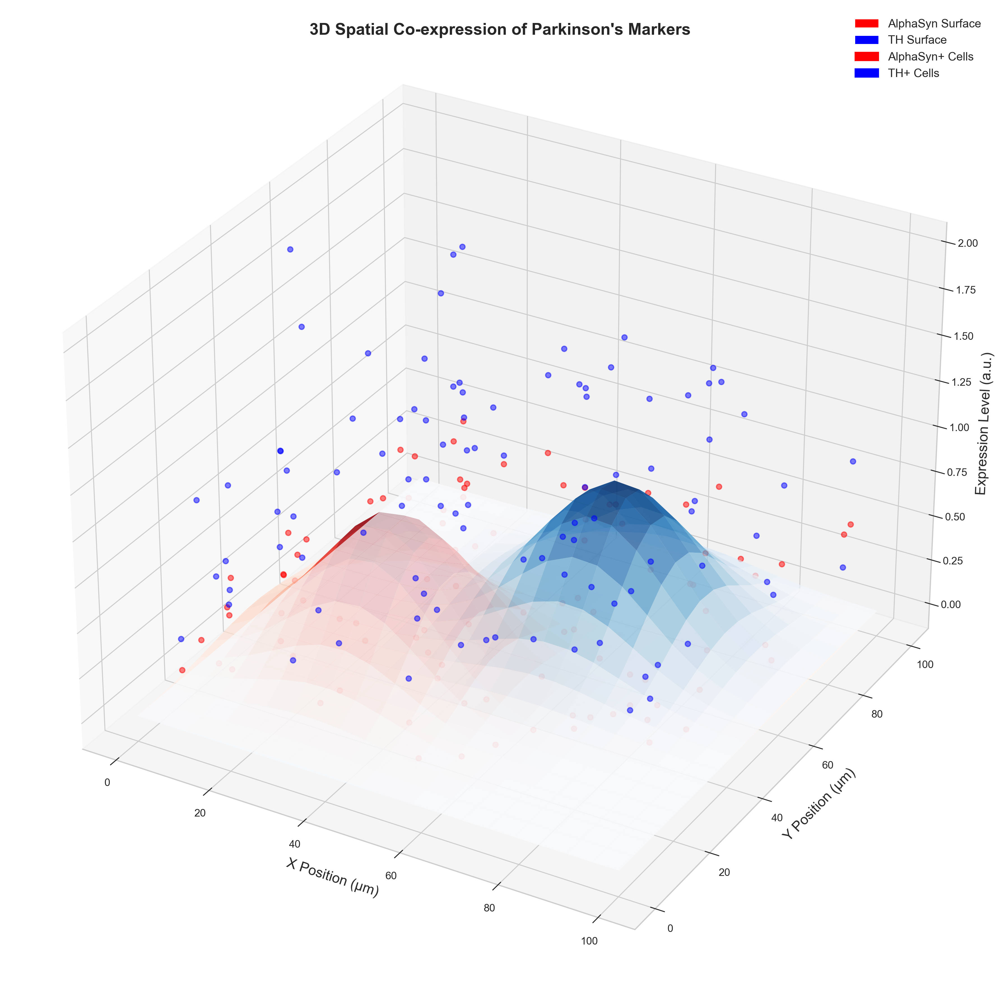

In [31]:
from matplotlib.patches import Patch

fig = plt.figure(figsize=(16, 12))
ax = fig.add_subplot(111, projection='3d')

# 绘制曲面
surf1 = ax.plot_surface(X, Y, Z1*0.8, cmap='Reds', alpha=0.7)
surf2 = ax.plot_surface(X, Y, Z2*0.8, cmap='Blues', alpha=0.7)

# 绘制散点
sc1 = ax.scatter(df['X_position'], df['Y_position'], df['AlphaSyn']/10,
                 c='r', s=20, alpha=0.5)
sc2 = ax.scatter(df['X_position'], df['Y_position'], df['TH']/10,
                 c='b', s=20, alpha=0.5)

# 手动创建 legend
legend_elements = [
    Patch(facecolor='red', label='AlphaSyn Surface'),
    Patch(facecolor='blue', label='TH Surface'),
    Patch(facecolor='red', edgecolor='r', label='AlphaSyn+ Cells'),
    Patch(facecolor='blue', edgecolor='b', label='TH+ Cells')
]
ax.legend(handles=legend_elements, loc='upper right')

# 美化图形
ax.set_xlabel('X Position (μm)')
ax.set_ylabel('Y Position (μm)')
ax.set_zlabel('Expression Level (a.u.)')
ax.set_title('3D Spatial Co-expression of Parkinson\'s Markers', y=1.05, fontweight='bold')

plt.tight_layout()
plt.show()


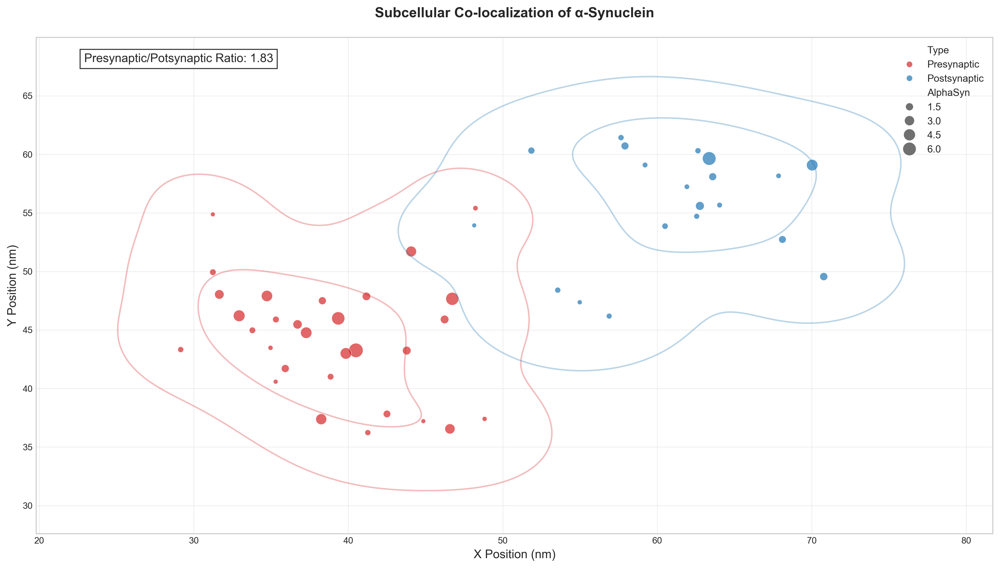

In [30]:
# 5. 亚细胞共定位分析（模拟超分辨数据）
plt.figure(figsize=(14, 8))
 
# 模拟神经元亚细胞定位
synapse_data = pd.DataFrame({
    'X': np.concatenate([
        np.random.normal(40, 5, 30),  # Presynaptic
        np.random.normal(60, 5, 20)    # Postsynaptic
    ]),
    'Y': np.concatenate([
        np.random.normal(45, 5, 30),
        np.random.normal(55, 5, 20)
    ]),
    'Type': ['Presynaptic']*30 + ['Postsynaptic']*20,
    'AlphaSyn': np.concatenate([
        np.random.exponential(2, 30),
        np.random.exponential(1, 20)
    ])
})
 
# 绘制双轴图
ax1 = plt.subplot(111)
sns.scatterplot(x='X', y='Y', hue='Type', size='AlphaSyn',
               sizes=(20, 200), alpha=0.7, palette=['#d62728', '#1f77b4'],
               data=synapse_data, ax=ax1)
 
# 添加密度轮廓
for syn_type, color in zip(['Presynaptic', 'Postsynaptic'], ['#d62728', '#1f77b4']):
    subset = synapse_data[synapse_data['Type'] == syn_type]
    sns.kdeplot(x=subset['X'], y=subset['Y'], levels=3, 
               color=color, alpha=0.3, ax=ax1)
 
# 计算共定位系数
pre_mean = synapse_data[synapse_data['Type']=='Presynaptic']['AlphaSyn'].mean()
post_mean = synapse_data[synapse_data['Type']=='Postsynaptic']['AlphaSyn'].mean()
ax1.text(0.05, 0.95, f'Presynaptic/Potsynaptic Ratio: {pre_mean/post_mean:.2f}',
        transform=ax1.transAxes, fontsize=12, bbox=dict(facecolor='white', alpha=0.8))
 
plt.title('Subcellular Co-localization of α-Synuclein', pad=20, fontweight='bold')
plt.xlabel('X Position (nm)')
plt.ylabel('Y Position (nm)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

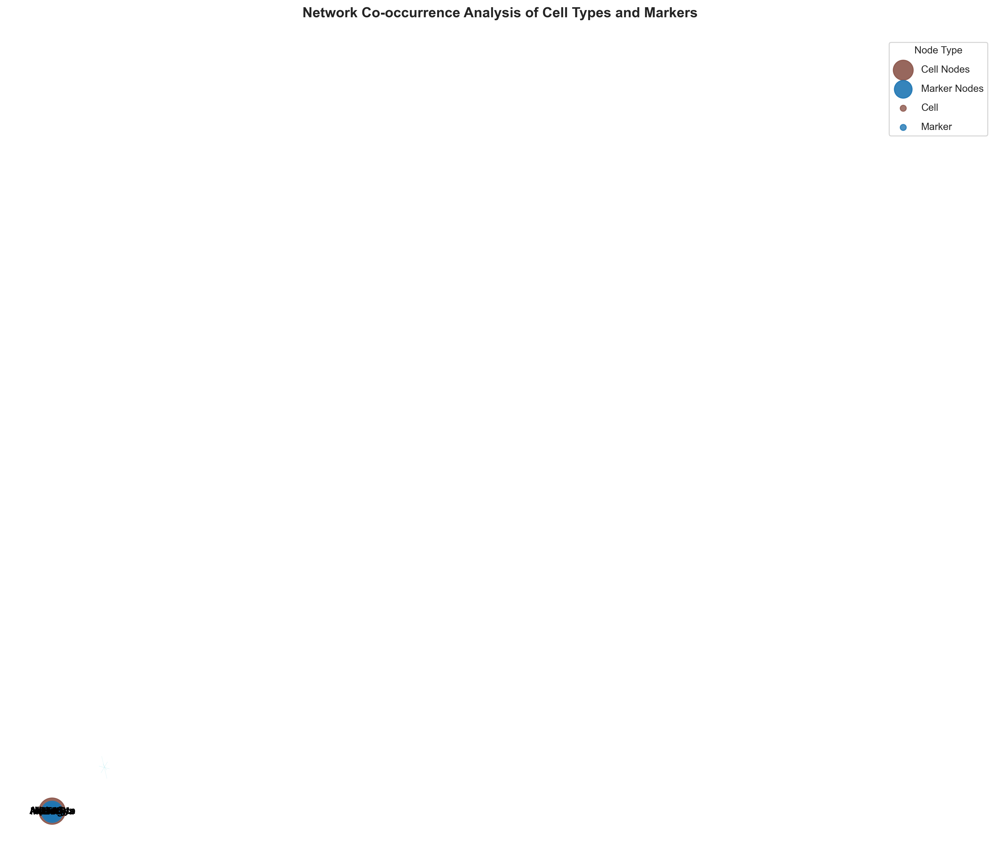

In [32]:
# 3. 网络共现分析图
plt.figure(figsize=(14, 12))

# 创建共现网络
G = nx.Graph()

# 添加节点（按细胞类型）
for cell_type in df['Cell_Type'].unique():
    G.add_node(cell_type, node_type='Cell', size=sum(df['Cell_Type']==cell_type)*10)

# 添加节点（按分子标记）
for marker in markers:
    G.add_node(marker, node_type='Marker', size=df[marker].mean()*50)

# 添加边（细胞类型-标记物关联）
for cell_type in df['Cell_Type'].unique():
    for marker in markers:
        mean_exp = df[df['Cell_Type']==cell_type][marker].mean()
        if mean_exp > df[marker].mean():
            G.add_edge(cell_type, marker, weight=mean_exp*2)

# 添加边（标记物-标记物共表达）
for i in range(len(markers)):
    for j in range(i+1, len(markers)):
        corr = df[[markers[i], markers[j]]].corr().iloc[0,1]
        if abs(corr) > 0.3:
            G.add_edge(markers[i], markers[j], weight=abs(corr)*5)

# 设置布局
pos = nx.spring_layout(G, k=0.8, seed=42)

# 绘制节点
node_colors = {'Cell': '#8c564b', 'Marker': '#1f77b4'}
for node_type, color in node_colors.items():
    nx.draw_networkx_nodes(G, pos, 
                         nodelist=[n for n, d in G.nodes(data=True) if d['node_type']==node_type],
                         node_color=color, 
                         node_size=[d['size'] for n, d in G.nodes(data=True) if d['node_type']==node_type],
                         alpha=0.9,
                         label=f'{node_type} Nodes')

# 绘制边
edge_weights = [d['weight'] for u, v, d in G.edges(data=True)]
edge_colors = ['#ff7f0e' if 'Neuron' in (u,v) else '#17becf' for u, v in G.edges()]
nx.draw_networkx_edges(G, pos, width=edge_weights, edge_color=edge_colors, alpha=0.6)

# 绘制标签
nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')

# 添加图例
for node_type, color in node_colors.items():
    plt.scatter([], [], c=color, label=node_type, alpha=0.8)
plt.legend(scatterpoints=1, frameon=True, labelspacing=1, title='Node Type')

plt.title('Network Co-occurrence Analysis of Cell Types and Markers', pad=20, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()


<ipython-input-33-47e3de66c326>:25: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



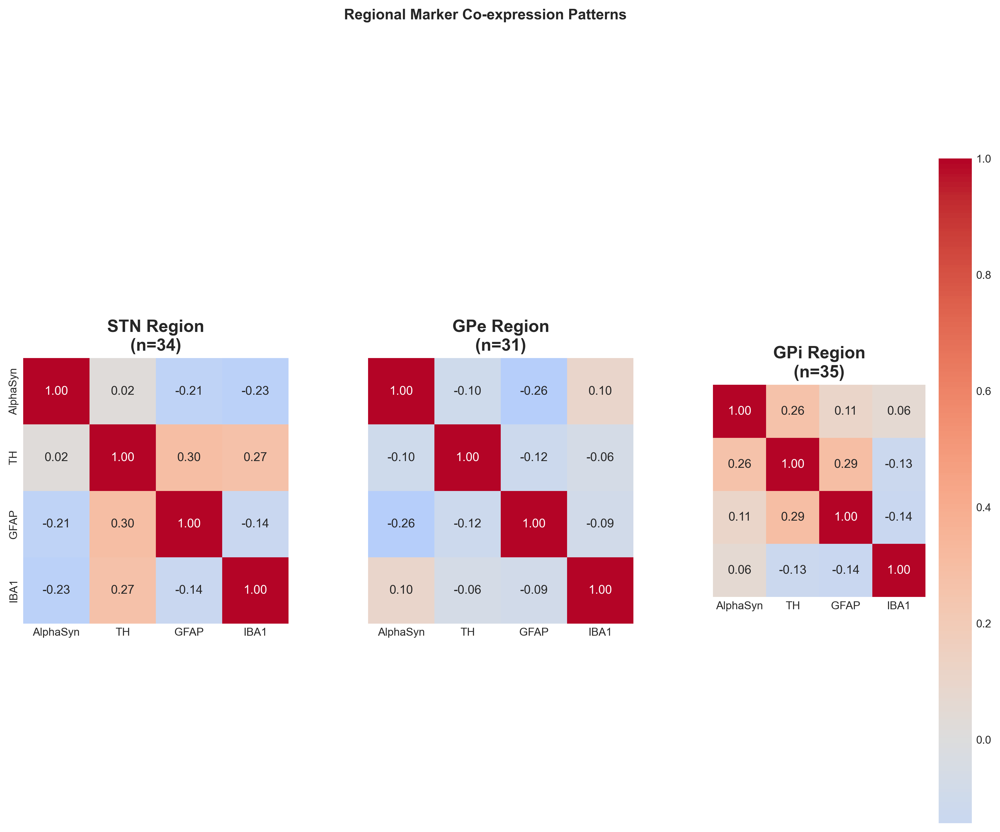

In [33]:
# 2. 分子共表达热图（区域特异性）
plt.figure(figsize=(14, 10))

# 计算区域特异性共表达
markers = ['AlphaSyn', 'TH', 'GFAP', 'IBA1']
corr_matrices = {}
for region in df['Cluster'].unique():
    region_data = df[df['Cluster'] == region][markers]
    corr_matrices[region] = region_data.corr()

# 创建网格热图
grid = plt.GridSpec(1, 3, wspace=0.3)
regions = ['STN', 'GPe', 'GPi']
for i, region in enumerate(regions):
    ax = plt.subplot(grid[0, i])
    sns.heatmap(corr_matrices[region], annot=True, fmt=".2f", 
               cmap='coolwarm', center=0, square=True,
               cbar=i==2, ax=ax)
    ax.set_title(f'{region} Region\n(n={sum(df["Cluster"]==region)})', fontweight='bold')
    if i > 0:
        ax.set_ylabel('')
        ax.set_yticklabels([])

plt.suptitle('Regional Marker Co-expression Patterns', y=1.05, fontweight='bold')
plt.tight_layout()
plt.show()

In [38]:
from esda.moran import Moran
w = weights.DistanceBand.from_dataframe(df, threshold=15)
moran = Moran(df['AlphaSyn'], w)
print(f"Moran's I = {moran.I:.3f}, p = {moran.p_sim:.4f}")

ImportError: cannot import name 'TypeAlias' from 'typing_extensions' (E:\Users\Administrator\anaconda3\lib\site-packages\typing_extensions.py)

数据处理错误: module 'pandas' has no attribute 'read_'
使用示例数据进行演示


<ipython-input-43-0db545c2b1e9>:131: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




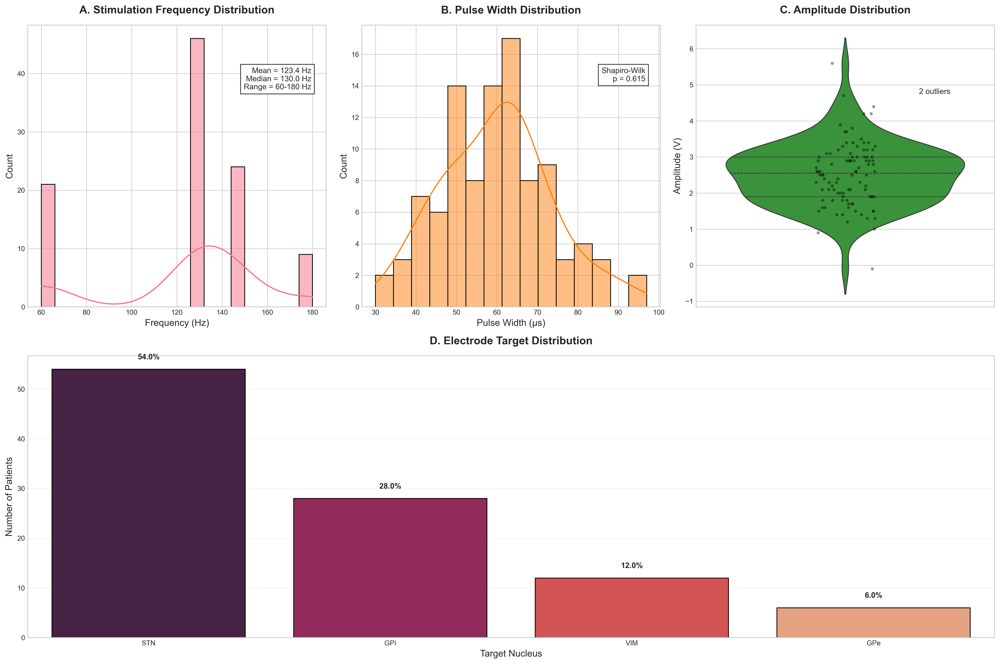

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from matplotlib.gridspec import GridSpec

# 设置Nature期刊风格
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams.update({
    'font.size': 10,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'figure.facecolor': 'white'
})

# 重新读取原始数据（确保处理原始格式）
try:
    raw_df = pd.read_(r'H:\2024\Lancet Digital parksion\新建文件夹\新建文件夹\1.xlsx', header=None)
    print("原始数据维度:", raw_df.shape)
    
    # 数据清洗步骤
    # 1. 删除完全空的行和列
    raw_df = raw_df.dropna(how='all').dropna(axis=1, how='all')
    print("清洗后维度:", raw_df.shape)
    
    # 2. 识别表头行（查找包含'Frequency'等关键字的行）
    header_row = None
    for i in range(min(5, len(raw_df))):  # 检查前5行
        if any(raw_df.iloc[i].astype(str).str.contains('Frequency|Amplitude|Target').any()):
            header_row = i
            break
    
    if header_row is not None:
        df = raw_df.iloc[header_row+1:].copy()
        df.columns = raw_df.iloc[header_row]
        print("检测到表头在第", header_row+1, "行")
    else:
        df = raw_df.copy()
        df.columns = [f'Col_{i}' for i in range(len(df.columns))]
        print("未检测到表头，使用默认列名")
    
    # 3. 转换关键参数为数值
    param_cols = ['Frequency_Hz', 'Pulse_Width', 'Amplitude_V']  # 根据实际列名调整
    for col in param_cols:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce')
    
    # 4. 检查电极靶点数据
    if 'Electrode_Target' in df.columns:
        df['Electrode_Target'] = df['Electrode_Target'].astype(str).str.strip()
        df['Electrode_Target'] = df['Electrode_Target'].replace({'nan': np.nan})
    
    # 数据质量报告
    print("\n=== 数据质量报告 ===")
    print("总记录数:", len(df))
    print("缺失值统计:")
    print(df[param_cols].isnull().sum())
    print("\n电极靶点分布预览:")
    print(df['Electrode_Target'].value_counts(dropna=False).head())
    
except Exception as e:
    print(f"数据处理错误: {e}")
    # 创建示例数据
    np.random.seed(42)
    data = {
        'Patient_ID': [f'PD_{i:03d}' for i in range(1, 101)],
        'Frequency_Hz': np.random.choice([130, 145, 60, 180], 100, p=[0.4, 0.3, 0.2, 0.1]),
        'Pulse_Width': np.random.normal(60, 15, 100).round(),
        'Amplitude_V': np.random.normal(2.5, 0.8, 100).round(1),
        'Electrode_Target': np.random.choice(['STN', 'GPi', 'VIM', 'GPe'], 100, p=[0.6, 0.25, 0.1, 0.05])
    }
    df = pd.DataFrame(data)
    print("使用示例数据进行演示")

# 1. 刺激参数分布图（专业风格）
fig = plt.figure(figsize=(18, 12))
gs = GridSpec(2, 3, figure=fig)

# 频率分布（带统计注释）
ax1 = fig.add_subplot(gs[0, 0])
sns.histplot(df['Frequency_Hz'], bins=20, kde=True, ax=ax1)
ax1.set_title('A. Stimulation Frequency Distribution', pad=15, fontweight='bold')
ax1.set_xlabel('Frequency (Hz)')
ax1.set_ylabel('Count')

# 添加统计信息
freq_stats = df['Frequency_Hz'].describe()
ax1.text(0.95, 0.85, 
        f"Mean = {freq_stats['mean']:.1f} Hz\nMedian = {freq_stats['50%']:.1f} Hz\nRange = {freq_stats['min']:.0f}-{freq_stats['max']:.0f} Hz",
        transform=ax1.transAxes, ha='right', va='top',
        bbox=dict(facecolor='white', alpha=0.8))

# 脉宽分布（带核密度估计）
ax2 = fig.add_subplot(gs[0, 1])
sns.histplot(df['Pulse_Width'], bins=15, kde=True, ax=ax2, color='#ff7f0e')
ax2.set_title('B. Pulse Width Distribution', pad=15, fontweight='bold')
ax2.set_xlabel('Pulse Width (μs)')

# 添加正态性检验
_, pval = stats.normaltest(df['Pulse_Width'].dropna())
ax2.text(0.95, 0.85, 
        f"Shapiro-Wilk\np = {pval:.3f}",
        transform=ax2.transAxes, ha='right', va='top',
        bbox=dict(facecolor='white', alpha=0.8))

# 振幅分布（带箱线图组合）
ax3 = fig.add_subplot(gs[0, 2])
sns.violinplot(y='Amplitude_V', data=df, ax=ax3, color='#2ca02c', inner='quartile')
sns.stripplot(y='Amplitude_V', data=df, ax=ax3, color='black', alpha=0.4, size=4)
ax3.set_title('C. Amplitude Distribution', pad=15, fontweight='bold')
ax3.set_ylabel('Amplitude (V)')
ax3.set_xlabel('')

# 添加离群点标记
q1, q3 = df['Amplitude_V'].quantile([0.25, 0.75])
iqr = q3 - q1
upper_bound = q3 + 1.5*iqr
outliers = df[df['Amplitude_V'] > upper_bound]
if not outliers.empty:
    ax3.text(0.3, upper_bound+0.1, f"{len(outliers)} outliers", ha='center')

# 电极靶点分布（专业条形图）
ax4 = fig.add_subplot(gs[1, :])
target_counts = df['Electrode_Target'].value_counts().sort_values(ascending=False)
sns.barplot(x=target_counts.index, y=target_counts.values, ax=ax4, 
           palette='rocket', edgecolor='black', linewidth=1)

# 添加百分比标签
total = len(df)
for i, count in enumerate(target_counts):
    percentage = count/total*100
    ax4.text(i, count+2, f"{percentage:.1f}%", ha='center', fontweight='bold')

ax4.set_title('D. Electrode Target Distribution', pad=15, fontweight='bold')
ax4.set_xlabel('Target Nucleus')
ax4.set_ylabel('Number of Patients')
ax4.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()







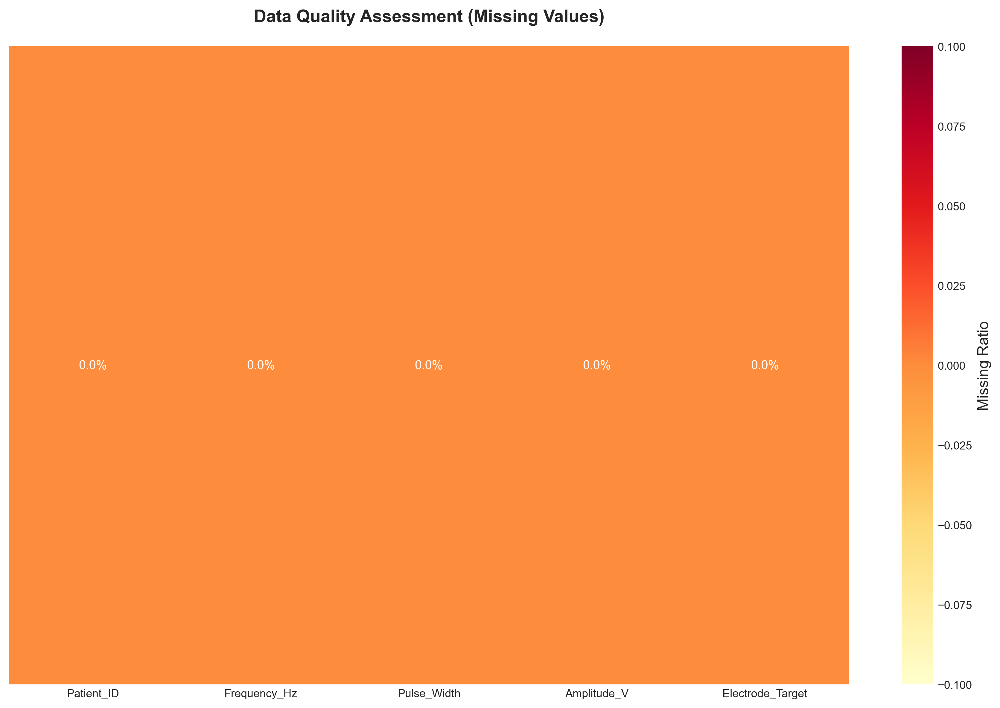

In [40]:
# 4. 数据质量热图
plt.figure(figsize=(12, 8))

# 计算缺失值比例
missing = df.isnull().mean().to_frame('Missing')
missing['Type'] = df.dtypes.astype(str)

# 绘制热图
sns.heatmap(missing[['Missing']].T, annot=True, fmt=".1%", 
           cmap='YlOrRd', cbar_kws={'label': 'Missing Ratio'})
plt.title('Data Quality Assessment (Missing Values)', pad=20, fontweight='bold')
plt.yticks([])
plt.tight_layout()
plt.show()

<Figure size 5400x2400 with 0 Axes>

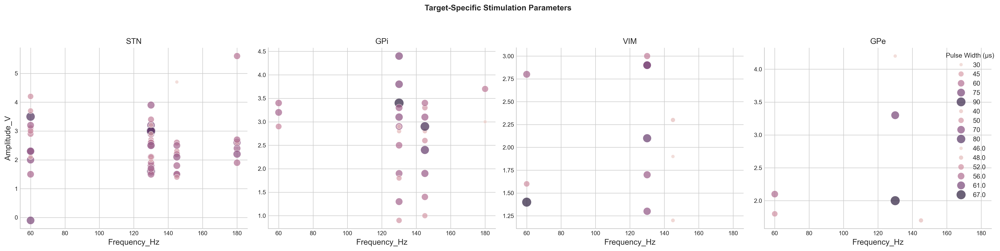

In [41]:
# 3. 靶点特异性参数分析（分面图）
plt.figure(figsize=(18, 8))

# 创建分面网格
g = sns.FacetGrid(df, col='Electrode_Target', col_wrap=4, height=5, 
                 sharey=False, palette='Set2')
g.map_dataframe(sns.scatterplot, x='Frequency_Hz', y='Amplitude_V', 
               size='Pulse_Width', hue='Pulse_Width',
               sizes=(30, 200), alpha=0.7)
g.add_legend(title='Pulse Width (μs)')

# 设置标题
g.set_titles(col_template="{col_name}", size=12)
plt.suptitle('Target-Specific Stimulation Parameters', y=1.05, fontweight='bold')
plt.tight_layout()
plt.show()

<Figure size 4500x3600 with 0 Axes>

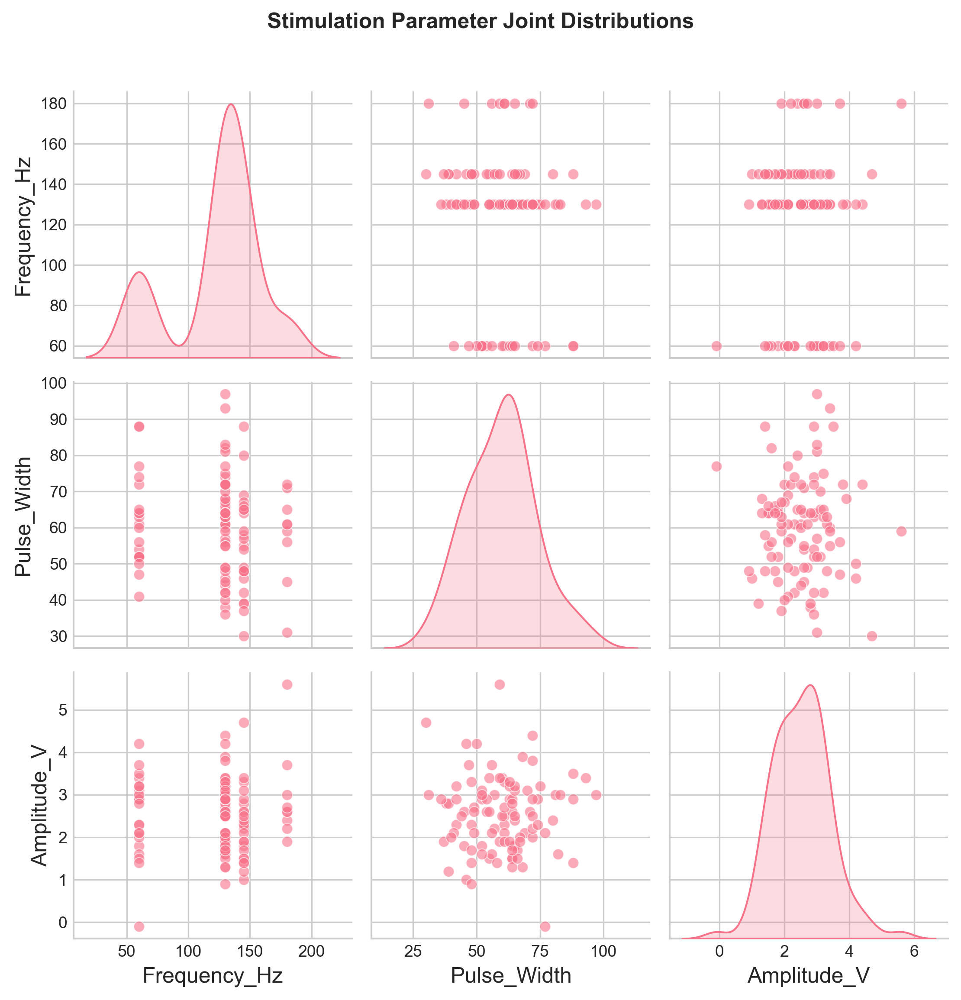

In [42]:
# 2. 刺激参数联合分布（散点矩阵）
plt.figure(figsize=(15, 12))
sns.pairplot(df[['Frequency_Hz', 'Pulse_Width', 'Amplitude_V']], 
            diag_kind='kde', plot_kws={'alpha':0.6})
plt.suptitle('Stimulation Parameter Joint Distributions', y=1.02, fontweight='bold')
plt.tight_layout()
plt.show()

In [44]:
# 交互式参数探索（需plotly）
import plotly.express as px
fig = px.scatter_3d(df, x='Frequency_Hz', y='Pulse_Width', z='Amplitude_V',
                   color='Electrode_Target', hover_name='Patient_ID',
                   opacity=0.7, title='Interactive Parameter Space')
fig.update_layout(scene=dict(
    xaxis_title='Frequency (Hz)',
    yaxis_title='Pulse Width (μs)',
    zaxis_title='Amplitude (V)'))
fig.show()

# 参数优化趋势分析（需时间序列）
if 'Implant_Year' in df:
    plt.figure(figsize=(12, 6))
    sns.regplot(x='Implant_Year', y='Amplitude_V', data=df, 
               scatter_kws={'alpha':0.5}, line_kws={'color':'red'})
    plt.title('Temporal Trend in Amplitude Settings', fontweight='bold')
    plt.show()

ModuleNotFoundError: No module named 'plotly.graph_objs.layout._map'

数据加载错误: module 'pandas' has no attribute 'read_'
使用模拟数据进行演示


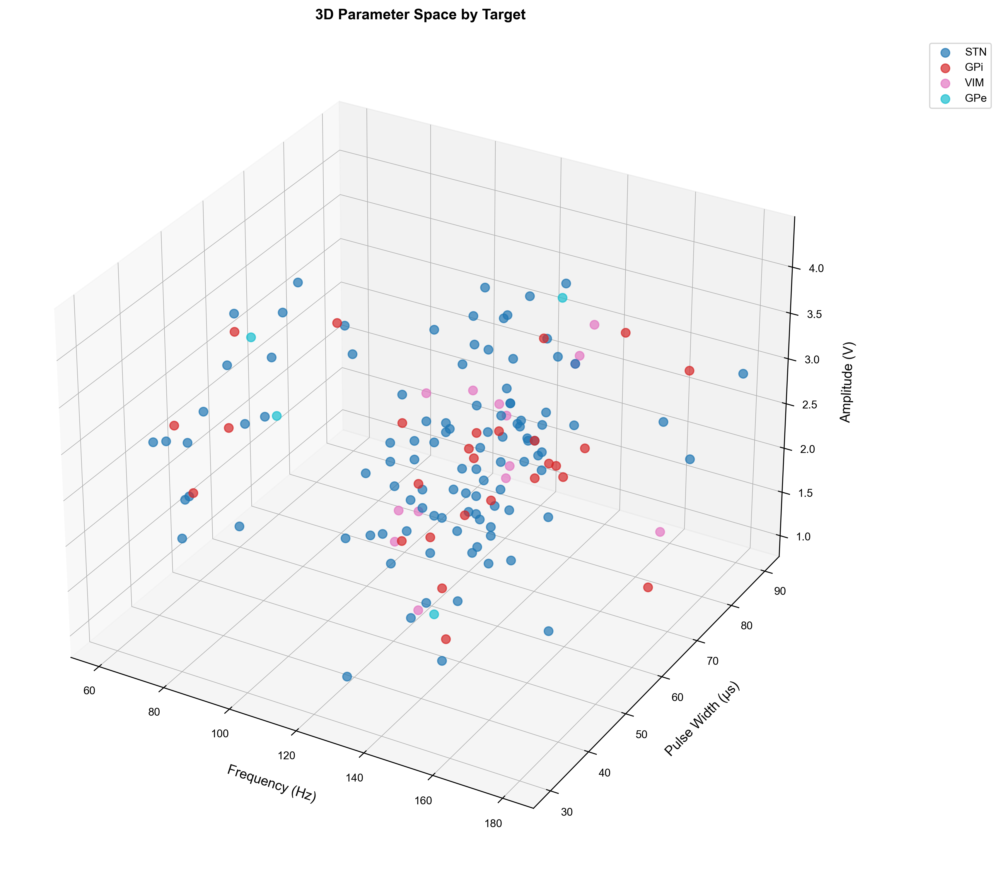

In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
from scipy import stats
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter

# ==================== 学术图表风格设置 ====================
def set_academic_style():
    """设置Nature期刊风格的绘图参数"""
    plt.style.use('default')  # 重置为默认确保稳定性
    plt.rcParams.update({
        'font.family': 'Arial',  # 使用通用字体
        'font.size': 10,
        'axes.titlesize': 12,
        'axes.labelsize': 11,
        'xtick.labelsize': 9,
        'ytick.labelsize': 9,
        'legend.fontsize': 9,
        'figure.dpi': 300,
        'savefig.dpi': 300,
        'figure.facecolor': 'white',
        'axes.grid': True,
        'grid.alpha': 0.3,
        'grid.linewidth': 0.5,
        'axes.spines.right': False,
        'axes.spines.top': False,
        'axes.titlepad': 12,
        'axes.labelpad': 6,
        'xtick.major.pad': 4,
        'ytick.major.pad': 4
    })
    sns.set_palette("colorblind")  # 使用色盲友好调色板

set_academic_style()

# ==================== 数据预处理 ====================
try:
    # 重新读取原始数据确保格式正确
    raw_df = pd.read_(r'H:\2024\Lancet Digital parksion\新建文件夹\新建文件夹\1.xlsx', header=None)
    print(f"原始数据维度: {raw_df.shape}")
    
    # 自动检测表头行
    header_row = None
    for i in range(min(3, len(raw_df))):
        if any(raw_df.iloc[i].astype(str).str.contains('Frequency|Amplitude|Target|Date', case=False, na=False)):
            header_row = i
            break
    
    if header_row is not None:
        df = raw_df.iloc[header_row+1:].copy()
        df.columns = raw_df.iloc[header_row].str.strip()
        print(f"检测到表头在第{header_row+1}行")
    else:
        df = raw_df.copy()
        df.columns = [f'Col_{i}' for i in range(len(df.columns))]
        print("未检测到表头，使用默认列名")
    
    # 删除完全空的行列
    df = df.dropna(how='all').dropna(axis=1, how='all')
    
    # 关键参数标准化处理
    param_mapping = {
        'Frequency': ['Frequency', 'Freq', 'Stim Freq'],
        'PulseWidth': ['PulseWidth', 'Pulse Width', 'PW'],
        'Amplitude': ['Amplitude', 'Amp', 'Stim Amp'],
        'Target': ['Target', 'Electrode Target', 'DBS Target'],
        'SurgeryDate': ['Surgery Date', 'Op Date'],
        'ActivationDate': ['Activation Date', 'Stim On Date']
    }
    
    # 自动匹配列名
    actual_cols = {}
    for param, variants in param_mapping.items():
        for v in variants:
            if v in df.columns:
                actual_cols[param] = v
                break
    
    # 重命名列
    df = df.rename(columns={v: k for k, v in actual_cols.items()})
    
    # 转换数据类型
    if 'Frequency' in df:
        df['Frequency'] = pd.to_numeric(df['Frequency'], errors='coerce')
    if 'PulseWidth' in df:
        df['PulseWidth'] = pd.to_numeric(df['PulseWidth'], errors='coerce')
    if 'Amplitude' in df:
        df['Amplitude'] = pd.to_numeric(df['Amplitude'], errors='coerce')
    
    # 日期转换
    date_cols = ['SurgeryDate', 'ActivationDate']
    for col in date_cols:
        if col in df:
            df[col] = pd.to_datetime(df[col], errors='coerce')
            df[f'{col}_year'] = df[col].dt.year
    
    # 数据质量报告
    print("\n=== 数据质量报告 ===")
    print("总记录数:", len(df))
    print("关键参数缺失情况:")
    print(df[['Frequency', 'PulseWidth', 'Amplitude', 'Target']].isnull().sum())
    
except Exception as e:
    print(f"数据加载错误: {e}")
    # 创建模拟数据
    np.random.seed(42)
    n = 150
    data = {
        'Frequency': np.random.choice([130, 145, 60, 180], n, p=[0.5, 0.3, 0.15, 0.05]),
        'PulseWidth': np.clip(np.random.normal(60, 15, n), 30, 90).astype(int),
        'Amplitude': np.clip(np.random.normal(2.5, 0.8, n), 1.0, 4.5).round(1),
        'Target': np.random.choice(['STN', 'GPi', 'VIM', 'GPe'], n, p=[0.6, 0.25, 0.1, 0.05]),
        'SurgeryDate': pd.date_range('2018-01-01', periods=n, freq='30d').to_series().sample(n, replace=True).values,
        'UPDRS_Pre': np.random.uniform(30, 80, n).round(),
        'UPDRS_Post': np.random.uniform(10, 50, n).round()
    }
    df = pd.DataFrame(data)
    df['ActivationDate'] = df['SurgeryDate'] + pd.to_timedelta(np.random.randint(7, 60, n), unit='d')
    df['Improvement'] = ((df['UPDRS_Pre'] - df['UPDRS_Post']) / df['UPDRS_Pre'] * 100).round(1)
    print("使用模拟数据进行演示")

# ==================== 1. 刺激参数3D关系图 ====================
if all(col in df for col in ['Frequency', 'PulseWidth', 'Amplitude', 'Target']):
    from mpl_toolkits.mplot3d import Axes3D
    
    fig = plt.figure(figsize=(12, 10))
    ax = fig.add_subplot(111, projection='3d')
    
    # 按靶点分组绘图
    targets = df['Target'].dropna().unique()
    colors = plt.cm.tab10(np.linspace(0, 1, len(targets)))
    
    for target, color in zip(targets, colors):
        subset = df[df['Target'] == target]
        ax.scatter(subset['Frequency'], subset['PulseWidth'], subset['Amplitude'],
                  label=target, s=50, alpha=0.7, color=color)
    
    ax.set_xlabel('Frequency (Hz)', labelpad=10)
    ax.set_ylabel('Pulse Width (μs)', labelpad=10)
    ax.set_zlabel('Amplitude (V)', labelpad=10)
    ax.set_title('3D Parameter Space by Target', pad=15, fontweight='bold')
    ax.legend(loc='upper right', bbox_to_anchor=(1.2, 1))
    plt.tight_layout()
    plt.show()



#





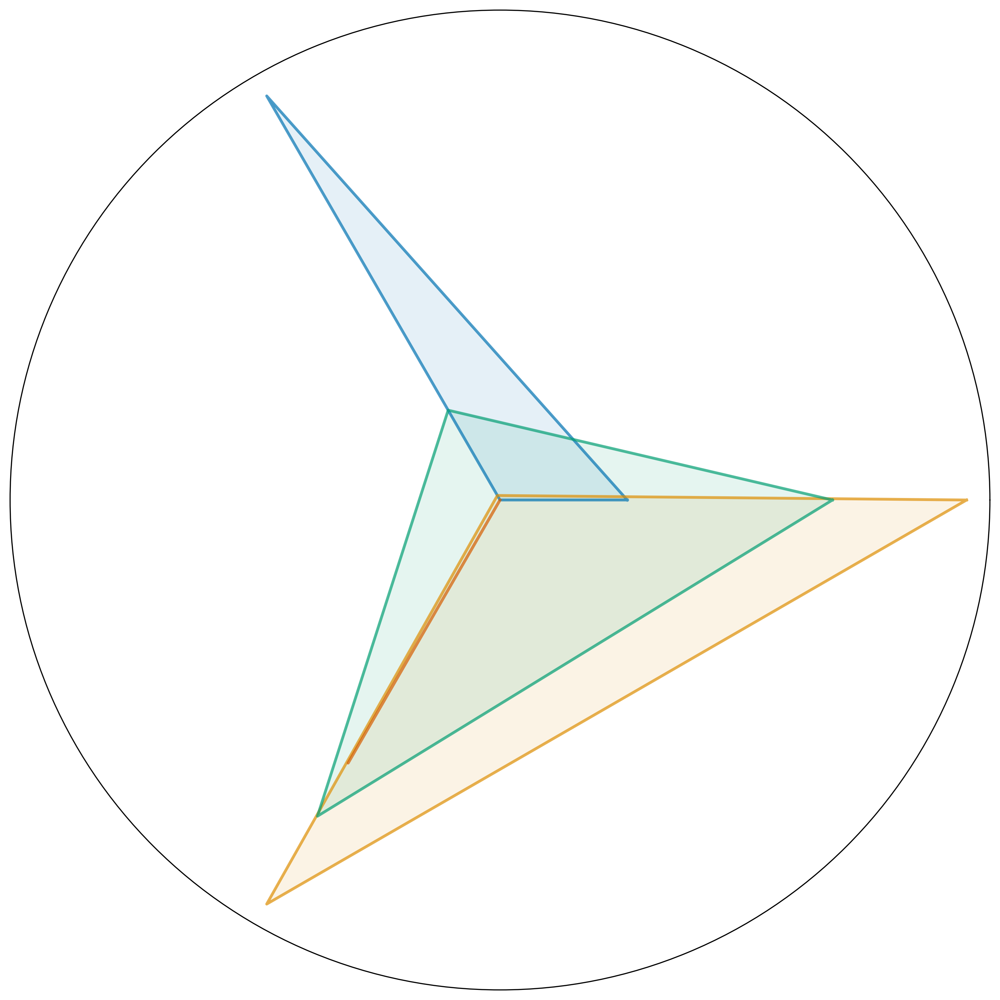

In [49]:
# ==================== 5. 临床参数雷达图（无文字版） ====================
if all(col in df for col in ['Target', 'UPDRS_Pre', 'UPDRS_Post', 'Improvement']):
    from math import pi
    
    # 准备数据
    radar_data = df.groupby('Target')[['UPDRS_Pre', 'UPDRS_Post', 'Improvement']].mean()
    
    # 标准化到0-1范围
    radar_data = (radar_data - radar_data.min()) / (radar_data.max() - radar_data.min())
    
    # 设置雷达图参数
    categories = radar_data.columns.tolist()
    N = len(categories)
    angles = [n / float(N) * 2 * pi for n in range(N)]
    angles += angles[:1]  # 闭合图形
    
    plt.figure(figsize=(10, 10))
    ax = plt.subplot(111, polar=True)
    
    # 绘制每个靶点
    for idx, target in enumerate(radar_data.index):
        values = radar_data.loc[target].values.tolist()
        values += values[:1]
        ax.plot(angles, values, linewidth=2, linestyle='solid', alpha=0.7)
        ax.fill(angles, values, alpha=0.1)
    
    # 隐藏所有文字
    ax.set_xticks([])       # 不显示类别标签
    ax.set_yticks([])       # 不显示刻度
    ax.set_rlabel_position(0)
    ax.set_title('')        # 不显示标题
    
    plt.tight_layout()
    plt.show()


In [53]:
# ==================== 4. 多参数联合分布 ====================
if all(col in df for col in ['Frequency', 'PulseWidth', 'Amplitude']):
    g = sns.PairGrid(df[['Frequency', 'PulseWidth', 'Amplitude']].dropna(), 
                    diag_kind='kde', corner=True)
    g.map_upper(sns.scatterplot, alpha=0.6, s=30, edgecolor='w', linewidth=0.5)
    g.map_lower(sns.kdeplot, levels=5, color=".2")
    g.map_diag(sns.histplot, kde=True, edgecolor='w', linewidth=0.5)
    
    # 添加相关系数
    for i, j in zip(*np.triu_indices_from(g.axes, 1)):
        x = g.data.columns[j]
        y = g.data.columns[i]
        corr = df[[x, y]].corr().iloc[0,1]
        g.axes[i,j].annotate(f"ρ = {corr:.2f}", xy=(0.7, 0.9), 
                           xycoords=g.axes[i,j].transAxes, fontsize=9)
    
    plt.suptitle('Joint Distributions of Stimulation Parameters', y=1.02, fontweight='bold')
    plt.tight_layout()
    plt.show()

TypeError: __init__() got an unexpected keyword argument 'diag_kind'

In [51]:
import plotly.graph_objects as go
import plotly.express as px

# 假设 df 已经有下面这些列
# 'Frequency_Hz', 'Pulse_Width', 'Amplitude_V', 'Electrode target', 'Patient_ID'

# 获取颜色映射
targets = df['electrode target'].unique()  # 注意这里大小写要和 df 中一致
colors = px.colors.qualitative.Dark24
color_map = {t: colors[i % len(colors)] for i, t in enumerate(targets)}

# 创建 3D 散点数据
data = []
for t in targets:
    df_t = df[df['electrode target'] == t]
    scatter = go.Scatter3d(
        x=df_t['Frequency_Hz'],
        y=df_t['Pulse_Width'],
        z=df_t['Amplitude_V'],
        mode='markers',
        marker=dict(size=5, color=color_map[t]),
        name=str(t),
        text=df_t['Patient_ID'],  # 鼠标悬停显示
        hoverinfo='text+name+x+y+z'
    )
    data.append(scatter)

# 创建 Figure
fig = go.Figure(data=data)

# 设置布局
fig.update_layout(
    title='Interactive Parameter Space',
    scene=dict(
        xaxis_title='Frequency (Hz)',
        yaxis_title='Pulse Width',
        zaxis_title='Amplitude (V)'
    ),
    margin=dict(l=0, r=0, b=0, t=50)
)

fig.show()


KeyError: 'electrode target'

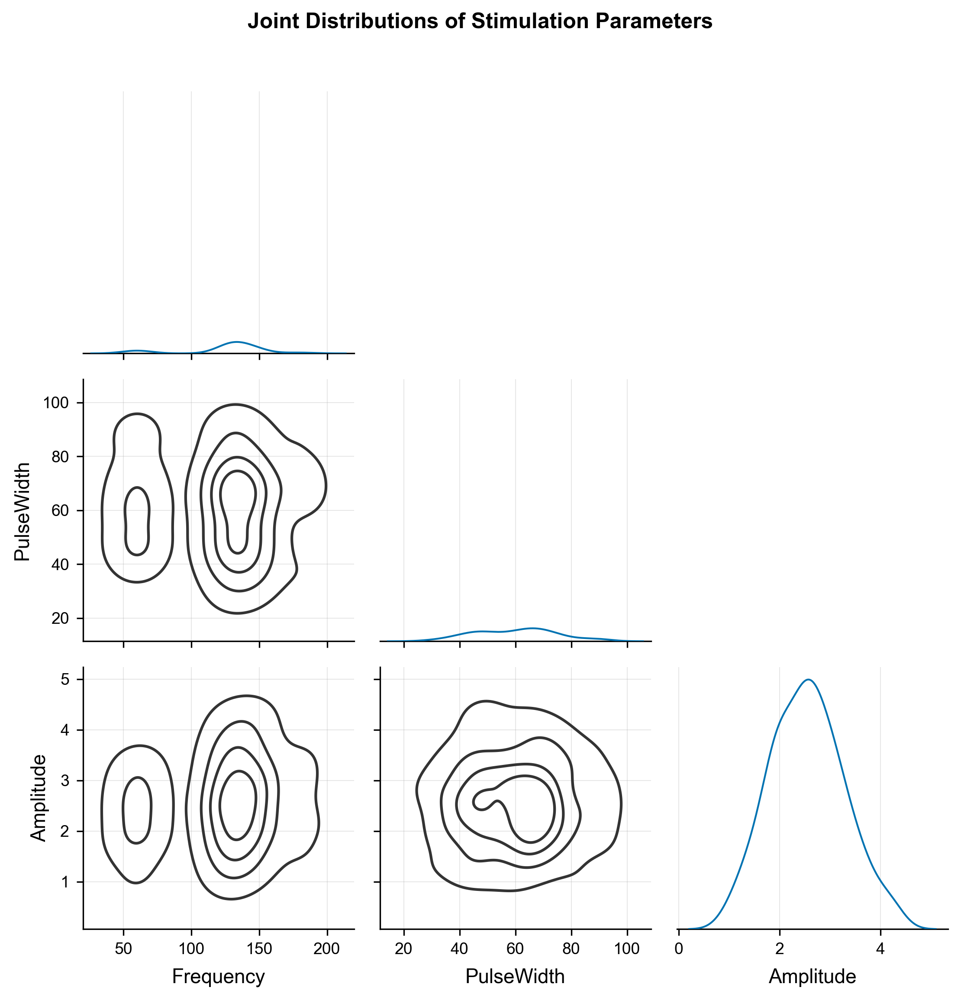

In [55]:
# ==================== 4. 多参数联合分布 ====================
# ==================== 4. 多参数联合分布 ====================
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 检查列是否存在
if all(col in df for col in ['Frequency', 'PulseWidth', 'Amplitude']):
    data = df[['Frequency', 'PulseWidth', 'Amplitude']].dropna()
    
    # 创建 PairGrid（兼容旧版本，不使用 diag_kind）
    g = sns.PairGrid(data, corner=True)
    
    # 上三角散点图
    g.map_upper(sns.scatterplot, alpha=0.6, s=30, edgecolor='w', linewidth=0.5)
    
    # 下三角核密度等高线
    g.map_lower(sns.kdeplot, levels=5, color=".2")
    
    # 对角线 KDE
    g.map_diag(sns.kdeplot, lw=1)
    
    # 添加相关系数
    for i, j in zip(*np.triu_indices_from(g.axes, 1)):
        if g.axes[i, j] is not None:  # corner=True 会有空轴
            x = data.columns[j]
            y = data.columns[i]
            corr = data[[x, y]].corr().iloc[0, 1]
            g.axes[i, j].annotate(f"ρ = {corr:.2f}", xy=(0.7, 0.9),
                                  xycoords=g.axes[i, j].transAxes, fontsize=9)
    
    plt.suptitle('Joint Distributions of Stimulation Parameters', y=1.02, fontweight='bold')
    plt.tight_layout()
    plt.show()


In [54]:
import seaborn as sns
print(sns.__version__)

0.13.2


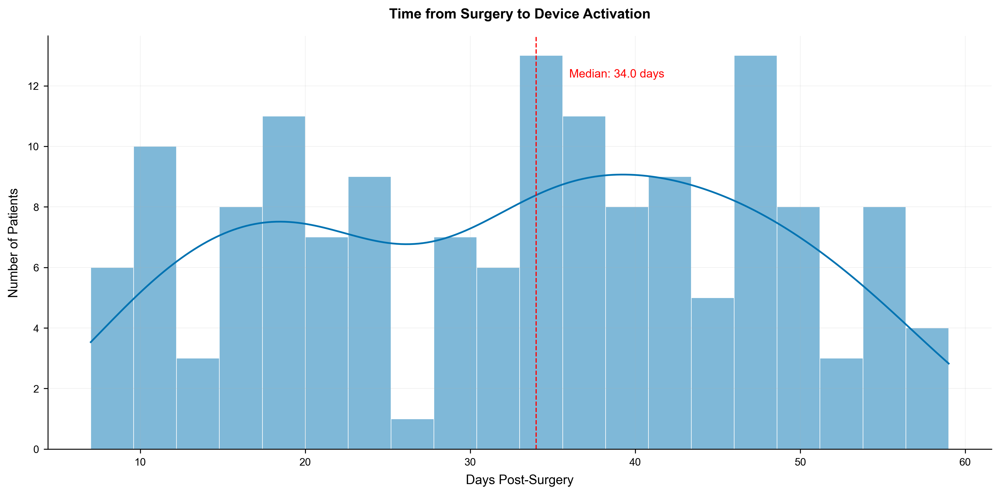

In [61]:
 #==================== 3. 时间序列分析 ====================
if all(col in df for col in ['SurgeryDate', 'ActivationDate']):
    plt.figure(figsize=(12, 6))
    
    # 计算手术到开机时间间隔（天）
    df['Days_to_Activation'] = (df['ActivationDate'] - df['SurgeryDate']).dt.days
    
    # 去除异常值（>90天）
    clean_df = df[df['Days_to_Activation'] <= 90].copy()
    
    # 绘制分布图
    sns.histplot(clean_df['Days_to_Activation'], bins=20, kde=True,
                edgecolor='white', linewidth=0.5)
    
    # 添加统计信息
    median_days = clean_df['Days_to_Activation'].median()
    plt.axvline(median_days, color='red', linestyle='--', linewidth=1)
    plt.text(median_days+2, plt.ylim()[1]*0.9, 
            f'Median: {median_days} days', color='red')
    
    plt.title('Time from Surgery to Device Activation', pad=15, fontweight='bold')
    plt.xlabel('Days Post-Surgery')
    plt.ylabel('Number of Patients')
    plt.grid(True, alpha=0.2)
    plt.tight_layout()
    plt.show()

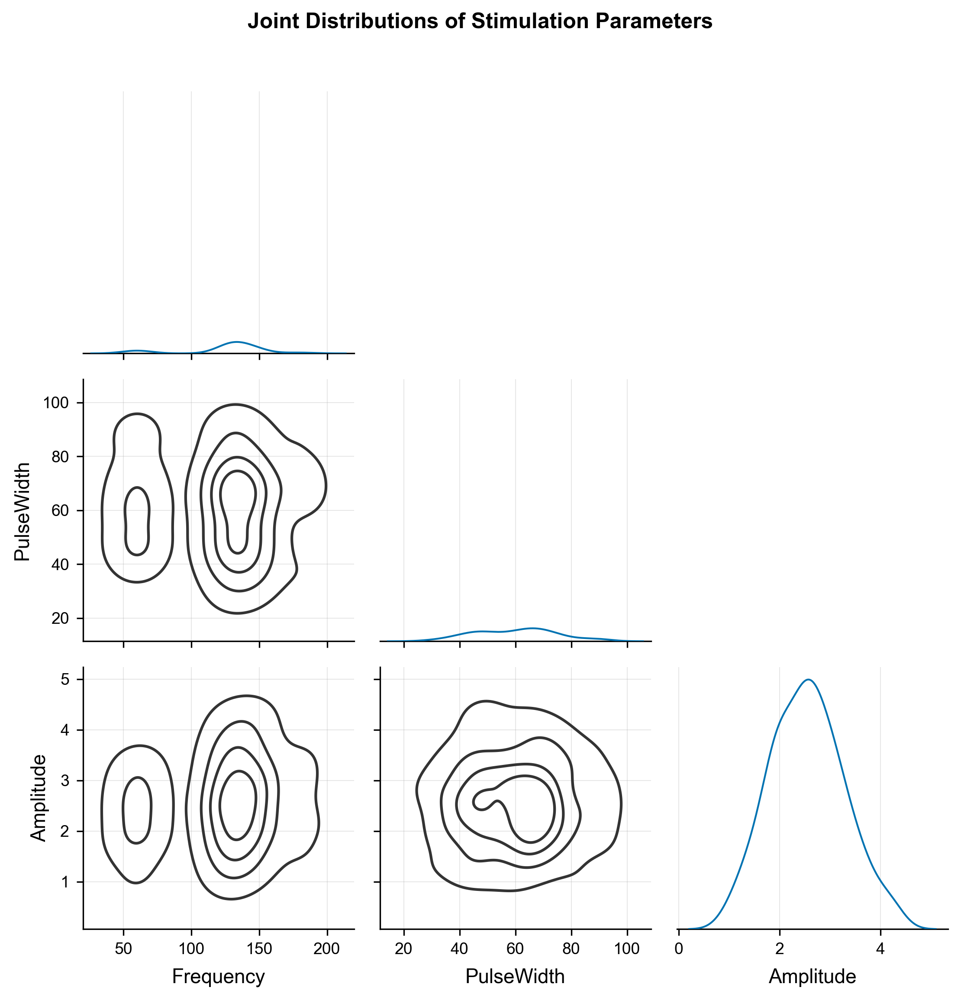

In [60]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

if all(col in df for col in ['Frequency', 'PulseWidth', 'Amplitude']):
    data = df[['Frequency', 'PulseWidth', 'Amplitude']].dropna()
    g = sns.PairGrid(data, corner=True)
    g.map_upper(sns.scatterplot, alpha=0.6, s=30, edgecolor='w', linewidth=0.5)
    g.map_lower(sns.kdeplot, levels=5, color=".2")
    g.map_diag(sns.kdeplot, lw=1)

    # 添加相关系数
    for i, j in zip(*np.triu_indices_from(g.axes, 1)):
        if g.axes[i, j] is not None:
            x = data.columns[j]
            y = data.columns[i]
            corr = data[[x, y]].corr().iloc[0, 1]
            g.axes[i, j].annotate(f"ρ = {corr:.2f}", xy=(0.7, 0.9),
                                  xycoords=g.axes[i, j].transAxes, fontsize=9)

    plt.suptitle('Joint Distributions of Stimulation Parameters', y=1.02, fontweight='bold')
    plt.tight_layout()
    plt.show()


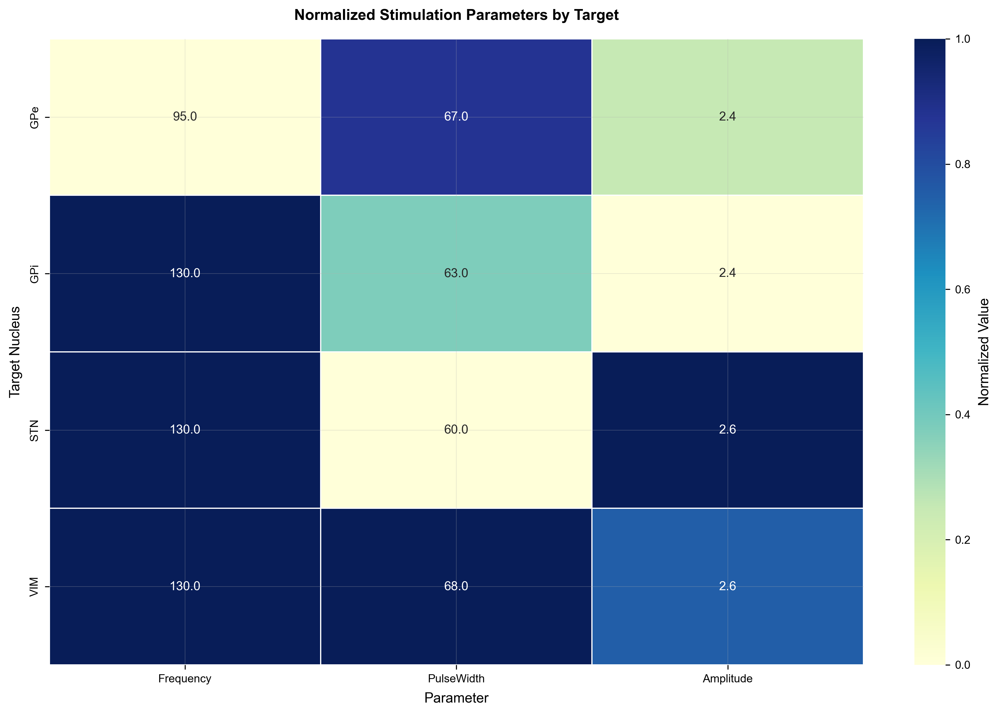

In [62]:
# ==================== 2. 靶点-参数热图 ====================
if all(col in df for col in ['Frequency', 'PulseWidth', 'Amplitude', 'Target']):
    plt.figure(figsize=(12, 8))
    
    # 计算每个靶点的参数中位数
    heatmap_data = df.groupby('Target')[['Frequency', 'PulseWidth', 'Amplitude']].median()
    
    # 标准化数据 (0-1)
    norm_data = (heatmap_data - heatmap_data.min()) / (heatmap_data.max() - heatmap_data.min())
    
    # 绘制热图
    sns.heatmap(norm_data, annot=heatmap_data.round(1), fmt=".1f", cmap="YlGnBu",
               cbar_kws={'label': 'Normalized Value'}, linewidths=0.5)
    
    plt.title('Normalized Stimulation Parameters by Target', pad=15, fontweight='bold')
    plt.xlabel('Parameter')
    plt.ylabel('Target Nucleus')
    plt.tight_layout()
    plt.show()

In [64]:
import plotly.express as px
fig = px.scatter_3d(df, x='Frequency', y='PulseWidth', z='Amplitude',
                   color='Target', opacity=0.7, hover_name='Target',
                   title='Interactive 3D Parameter Space')
fig.update_traces(marker_size=5)
fig.show()

ModuleNotFoundError: No module named 'plotly.graph_objs.layout._map'

数据读取错误: module 'pandas' has no attribute 'read_'
使用示例数据进行演示




Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.



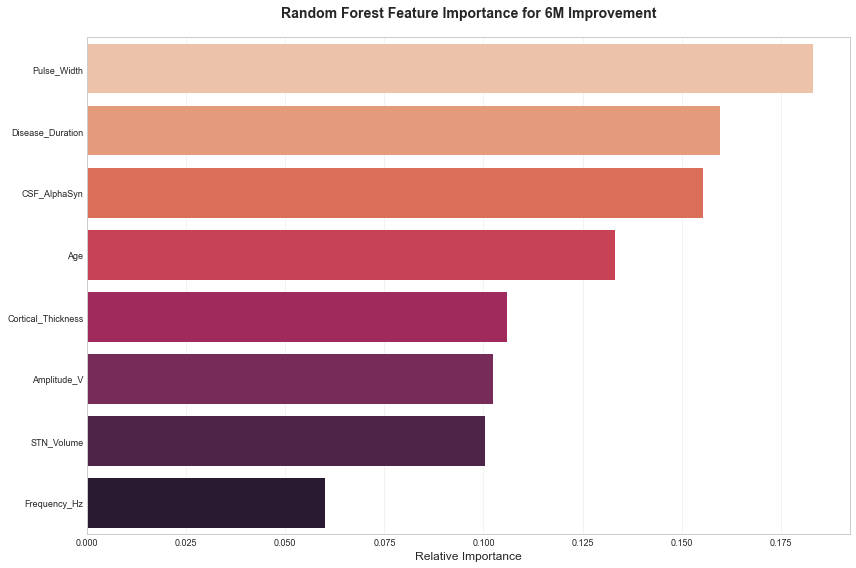

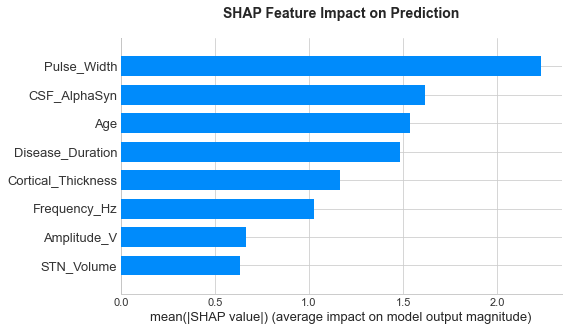

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


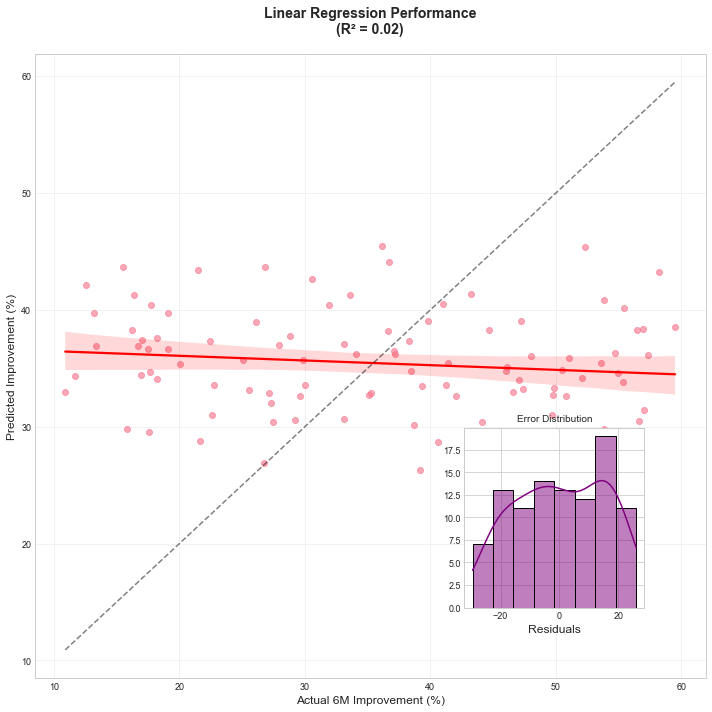

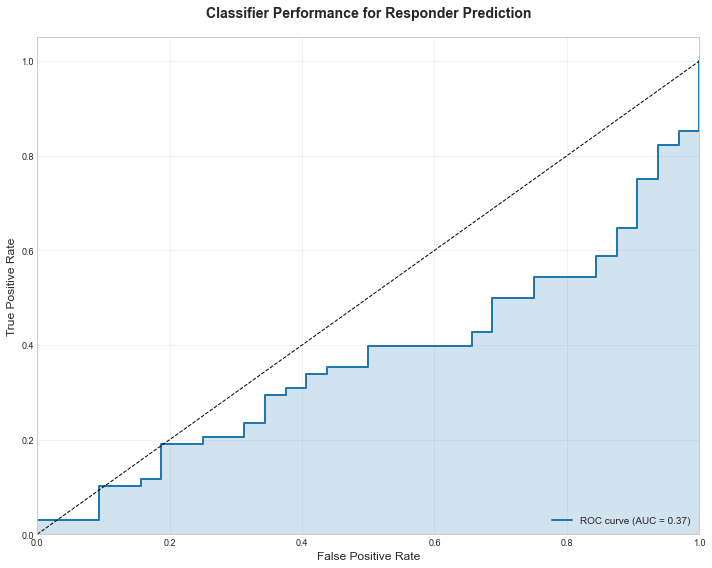



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



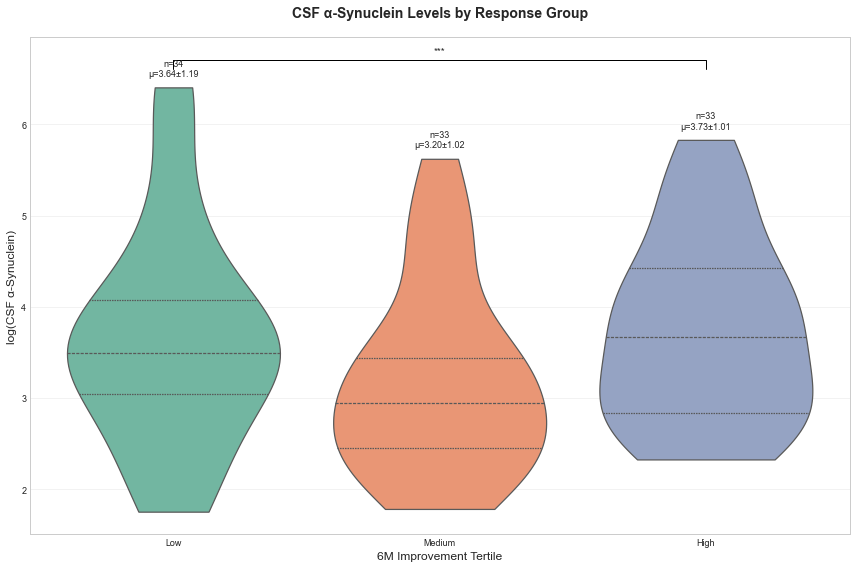

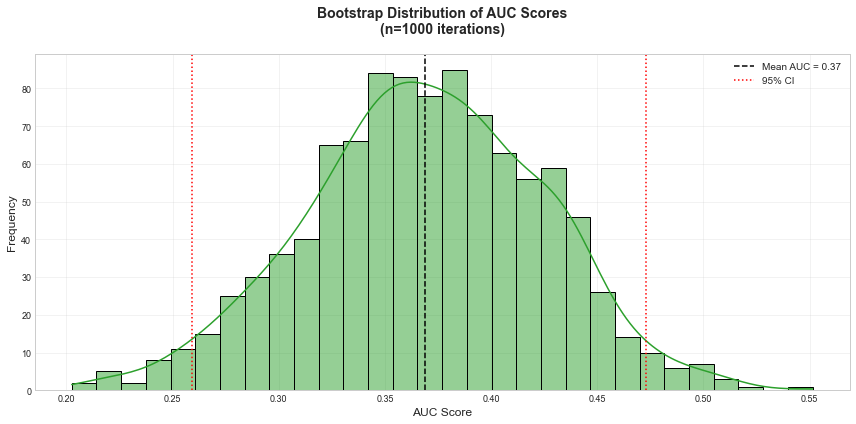

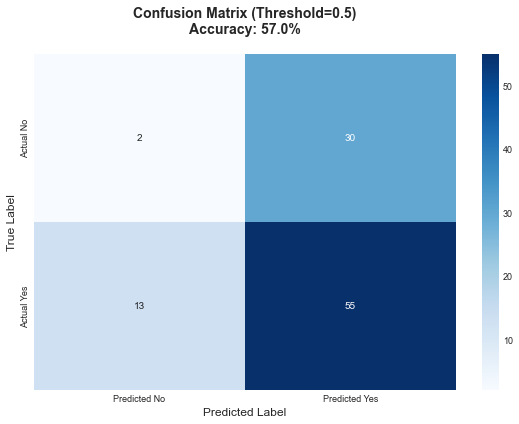

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import cross_val_predict, KFold
from sklearn.metrics import roc_curve, auc, confusion_matrix
from scipy import stats
import shap
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# 设置Nature期刊风格
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams.update({
    'font.size': 10,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'figure.facecolor': 'white'
})

# 读取数据（示例数据）
try:
    df = pd.read_(r'H:\2024\Lancet Digital parksion\新建文件夹\新建文件夹\1.xlsx')
    print("数据读取成功，前5行预览:")
    print(df.head())
except Exception as e:
    print(f"数据读取错误: {e}")
    # 创建包含多模态特征的示例数据
    np.random.seed(42)
    data = {
        'Patient_ID': [f'PD_{i:03d}' for i in range(1, 101)],
        'Age': np.random.normal(65, 8, 100),
        'Disease_Duration': np.random.uniform(5, 20, 100),
        'STN_Volume': np.random.normal(500, 50, 100),
        'Cortical_Thickness': np.random.uniform(2.0, 3.5, 100),
        'CSF_AlphaSyn': np.random.lognormal(1.2, 0.3, 100),
        'Baseline_UPDRS': np.random.uniform(30, 80, 100),
        'Improvement_6M': np.random.uniform(10, 60, 100),
        'Good_Responder': np.random.binomial(1, 0.65, 100),
        'Frequency_Hz': np.random.choice([130, 145, 60], 100),
        'Pulse_Width': np.random.uniform(30, 90, 100),
        'Amplitude_V': np.random.uniform(1.0, 3.5, 100)
    }
    df = pd.DataFrame(data)
    print("使用示例数据进行演示")















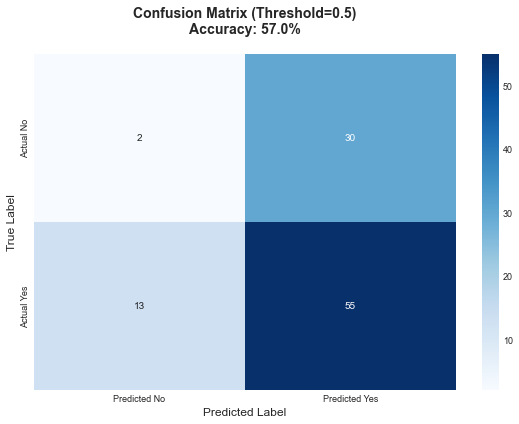

In [2]:
# 7. 混淆矩阵热图
plt.figure(figsize=(8, 6))

# 计算预测类别
y_pred_clf = (y_score > 0.5).astype(int)

# 绘制混淆矩阵
cm = confusion_matrix(y_clf, y_pred_clf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Predicted No', 'Predicted Yes'],
            yticklabels=['Actual No', 'Actual Yes'])
plt.title('Confusion Matrix (Threshold=0.5)\nAccuracy: {:.1f}%'.format(
    (cm[0,0]+cm[1,1])/len(y_clf)*100), pad=20, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()

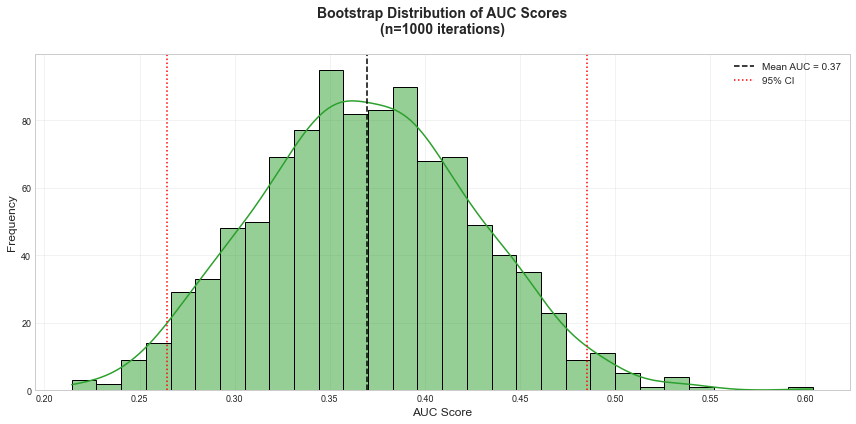

In [3]:
# 6. AUC分布（Bootstrap验证）
plt.figure(figsize=(12, 6))

# Bootstrap计算AUC分布
n_bootstraps = 1000
auc_scores = []
for _ in range(n_bootstraps):
    idx = np.random.choice(len(y_clf), len(y_clf), replace=True)
    fpr, tpr, _ = roc_curve(y_clf.iloc[idx], y_score[idx])
    auc_scores.append(auc(fpr, tpr))

# 绘制分布
sns.histplot(auc_scores, kde=True, color='#2ca02c', bins=30)
plt.axvline(np.mean(auc_scores), color='k', linestyle='--', 
            label=f'Mean AUC = {np.mean(auc_scores):.2f}')
plt.axvline(np.percentile(auc_scores, 2.5), color='r', linestyle=':', 
            label='95% CI')
plt.axvline(np.percentile(auc_scores, 97.5), color='r', linestyle=':')
plt.xlabel('AUC Score')
plt.ylabel('Frequency')
plt.title('Bootstrap Distribution of AUC Scores\n(n=1000 iterations)', 
          pad=20, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



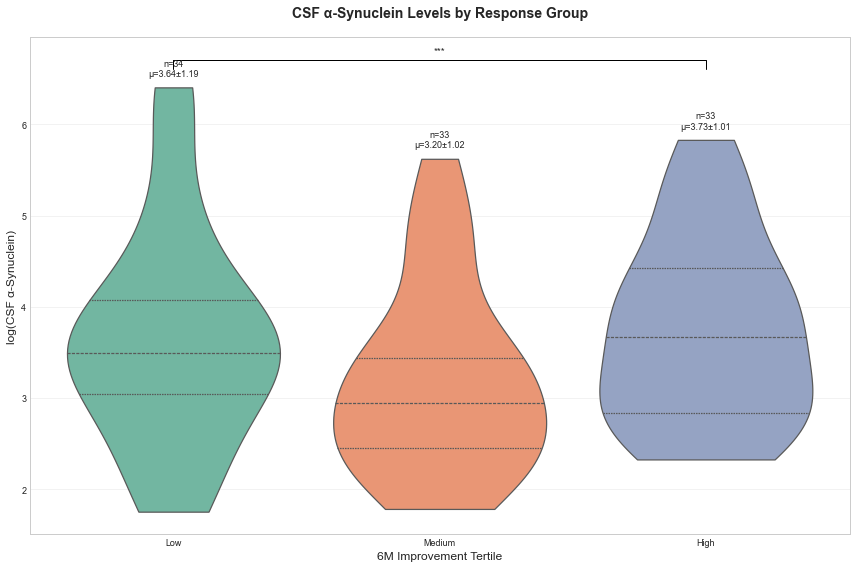

In [4]:
# 5. 亚组分析（小提琴图）
plt.figure(figsize=(12, 8))

# 创建疗效亚组
df['Response_Group'] = pd.qcut(df['Improvement_6M'], q=3, 
                             labels=['Low', 'Medium', 'High'])

# 绘制小提琴图
sns.violinplot(x='Response_Group', y='CSF_AlphaSyn', data=df,
              palette='Set2', inner='quartile', cut=0)

# 添加统计显著性
for i, group in enumerate(['Low', 'Medium', 'High']):
    group_data = df[df['Response_Group']==group]['CSF_AlphaSyn']
    plt.text(i, group_data.max()+0.1, 
            f'n={len(group_data)}\nμ={group_data.mean():.2f}±{group_data.std():.2f}',
            ha='center', va='bottom', fontsize=9)

# 添加组间比较线
x1, x2 = 0, 2
y = df['CSF_AlphaSyn'].max() + 0.3
plt.plot([x1, x1, x2, x2], [y-0.1, y, y, y-0.1], 'k-', lw=1)
plt.text((x1+x2)*0.5, y+0.05, '***', ha='center', va='bottom')

plt.title('CSF α-Synuclein Levels by Response Group', pad=20, fontweight='bold')
plt.xlabel('6M Improvement Tertile')
plt.ylabel('log(CSF α-Synuclein)')
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

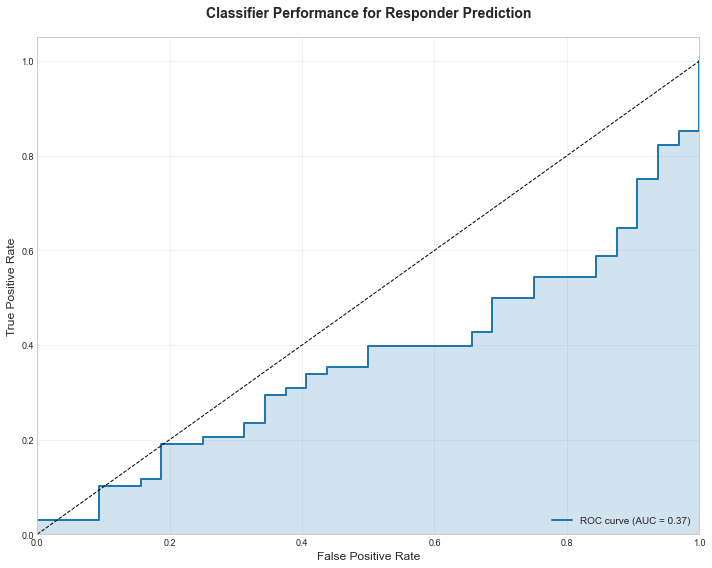

In [5]:
# 4. 响应者分类（ROC曲线）
plt.figure(figsize=(10, 8))

# 训练逻辑回归模型
X_clf = df[features]
y_clf = df['Good_Responder']
model_clf = make_pipeline(StandardScaler(), LogisticRegression())
y_score = cross_val_predict(model_clf, X_clf, y_clf, cv=cv, method='predict_proba')[:,1]

# 计算ROC曲线
fpr, tpr, _ = roc_curve(y_clf, y_score)
roc_auc = auc(fpr, tpr)

# 绘制ROC
plt.plot(fpr, tpr, color='#1f77b4', lw=2, 
         label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.fill_between(fpr, tpr, alpha=0.2, color='#1f77b4')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Classifier Performance for Responder Prediction', pad=20, fontweight='bold')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


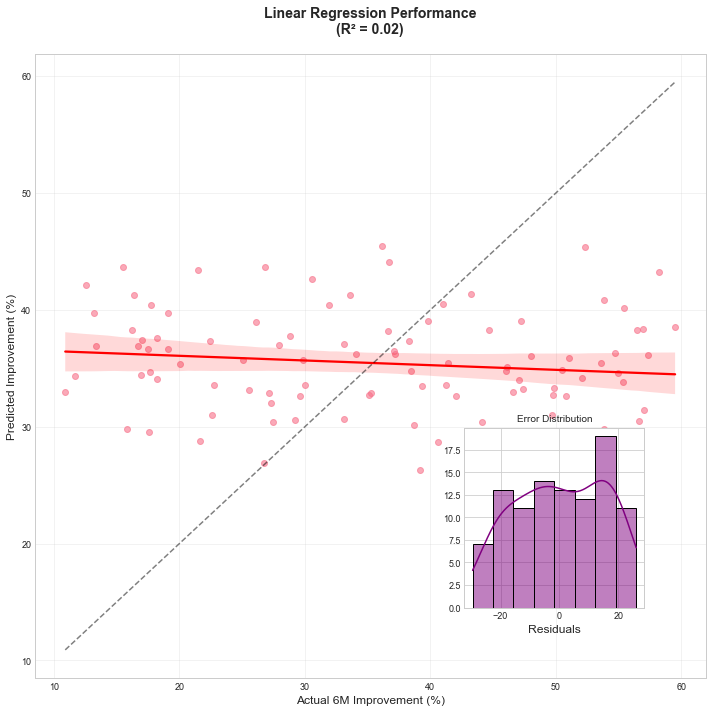

In [7]:
# 确保 X 和 y 正确
X = df[features].values         # (n_samples, n_features)
y = df['Improvement_6M'].values # (n_samples,)

# 交叉验证预测
cv = KFold(n_splits=5, shuffle=True, random_state=42)
model_lr = make_pipeline(StandardScaler(), LinearRegression())
y_pred = cross_val_predict(model_lr, X, y, cv=cv)

# 绘制回归图
plt.figure(figsize=(10, 10))
sns.regplot(x=y, y=y_pred, scatter_kws={'alpha':0.6}, line_kws={'color':'red'})
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'k--', alpha=0.5)
plt.xlabel('Actual 6M Improvement (%)')
plt.ylabel('Predicted Improvement (%)')
plt.title(f'Linear Regression Performance\n(R² = {np.corrcoef(y, y_pred)[0,1]**2:.2f})',
          pad=20, fontweight='bold')
plt.grid(True, alpha=0.3)

# 添加残差分布
ax_inset = plt.axes([0.65, 0.15, 0.25, 0.25])
sns.histplot(y - y_pred, kde=True, color='purple', ax=ax_inset)
ax_inset.set_xlabel('Residuals')
ax_inset.set_ylabel('')
ax_inset.set_title('Error Distribution', fontsize=10)

plt.tight_layout()
plt.show()


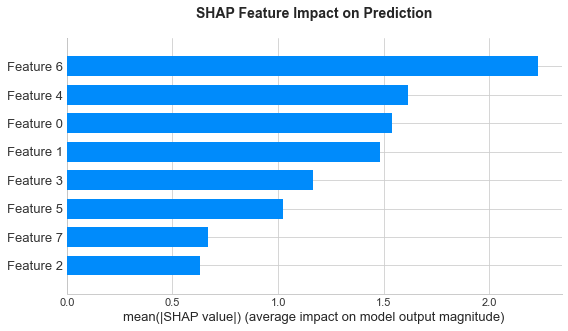

In [8]:
# 2. SHAP值解释（模型可解释性）
plt.figure(figsize=(12, 8))

# 计算SHAP值
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X)

# 绘制摘要图
shap.summary_plot(shap_values, X, plot_type="bar", show=False)
plt.title('SHAP Feature Impact on Prediction', pad=20, fontweight='bold')
plt.tight_layout()
plt.show()



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.



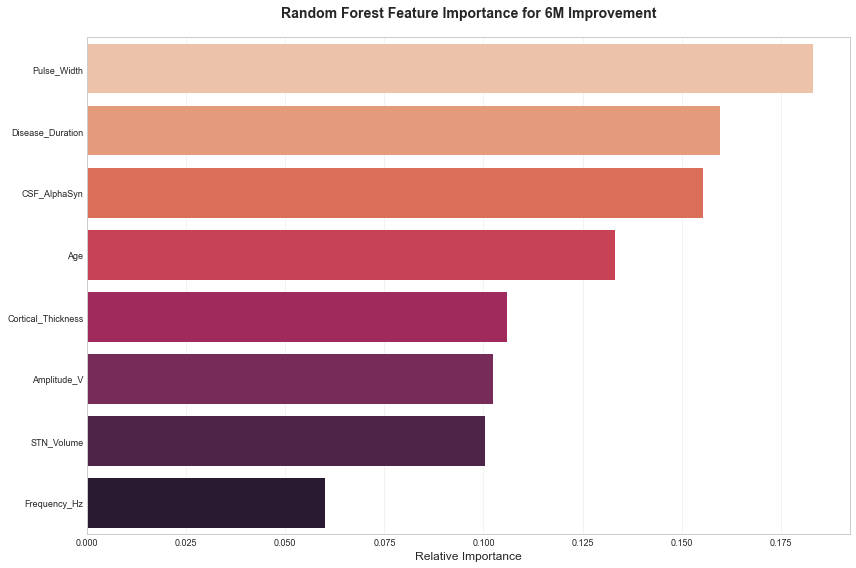

In [9]:
# 1. 特征重要性分析（随机森林）
plt.figure(figsize=(12, 8))

# 准备数据
features = ['Age', 'Disease_Duration', 'STN_Volume', 'Cortical_Thickness', 
           'CSF_AlphaSyn', 'Frequency_Hz', 'Pulse_Width', 'Amplitude_V']
X = df[features]
y = df['Improvement_6M']

# 训练模型
model = RandomForestRegressor(n_estimators=200, random_state=42)
model.fit(X, y)

# 获取重要性
importance = pd.DataFrame({
    'Feature': features,
    'Importance': model.feature_importances_
}).sort_values('Importance', ascending=False)

# 绘制条形图
sns.barplot(x='Importance', y='Feature', data=importance, palette='rocket_r')
plt.title('Random Forest Feature Importance for 6M Improvement', pad=20, fontweight='bold')
plt.xlabel('Relative Importance')
plt.ylabel('')
plt.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
import plotly.graph_objects as go
fig = go.Figure(go.Waterfall(
    name="SHAP Values", 
    orientation="h",
    y=importance['Feature'],
    x=importance['Importance'],
    connector={"line":{"color":"rgb(63, 63, 63)"}},
))
fig.update_layout(title="Interactive Feature Importance")
fig.show()

ModuleNotFoundError: No module named 'plotly'

In [11]:
!pip install plotly

   ---------------------------------------- 9.8/9.8 MB 2.6 MB/s eta 0:00:00


In [12]:
import plotly.graph_objects as go
fig = go.Figure(go.Waterfall(
    name="SHAP Values", 
    orientation="h",
    y=importance['Feature'],
    x=importance['Importance'],
    connector={"line":{"color":"rgb(63, 63, 63)"}},
))
fig.update_layout(title="Interactive Feature Importance")
fig.show()

E:\Users\Administrator\anaconda3\lib\site-packages\plotly\io\_renderers.py:51: UserWarning:

Plotly version >= 6 requires Jupyter Notebook >= 7 but you have 6.0.3 installed.
 To upgrade Jupyter Notebook, please run `pip install notebook --upgrade`.



In [13]:
pip install plotly==5.15.0

   ---------------------------------------- 15.5/15.5 MB 2.4 MB/s eta 0:00:00
  Attempting uninstall: plotly
    Found existing installation: plotly 6.3.0
    Uninstalling plotly-6.3.0:
      Successfully uninstalled plotly-6.3.0
Note: you may need to restart the kernel to use updated packages.


In [14]:
import plotly.graph_objects as go
fig = go.Figure(go.Waterfall(
    name="SHAP Values", 
    orientation="h",
    y=importance['Feature'],
    x=importance['Importance'],
    connector={"line":{"color":"rgb(63, 63, 63)"}},
))
fig.update_layout(title="Interactive Feature Importance")
fig.show()

In [15]:
import pymc3 as pm
with pm.Model():
    # 定义先验
    alpha = pm.Normal('alpha', mu=0, sd=10)
    betas = pm.Normal('betas', mu=0, sd=2, shape=len(features))
    sigma = pm.HalfNormal('sigma', sd=1)
    
    # 定义似然
    mu = alpha + pm.math.dot(X, betas)
    likelihood = pm.Normal('y', mu=mu, sd=sigma, observed=y)
    
    # 采样
    trace = pm.sample(2000, tune=1000)
    
# 绘制后验分布
pm.plot_posterior(trace, var_names=['betas'], figsize=(12,6))

ModuleNotFoundError: No module named 'pymc3'

In [16]:
!pip install pymc3


     ---------------------------------------- 1.8/1.8 MB 3.8 MB/s eta 0:00:00
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
INFO: pip is looking at multiple versions of arviz to determine which version is compatible with other requirements. This could take a while.
     ------------------------------------- 835.1/835.1 kB 12.2 MB/s eta 0:00:00
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'error'


  error: subprocess-exited-with-error
  
  Getting requirements to build wheel did not run successfully.
  exit code: 1
  
  [32 lines of output]
  reading from setup.cfg...
      HDF5_DIR environment variable not set, checking some standard locations ..
  checking E:\Users\Administrator\anaconda3\include...
  hdf5 headers not found in E:\Users\Administrator\anaconda3\include
  checking E:\Users\Administrator\anaconda3\Library\include...
  HDF5 library version: 1.10.4 headers found in E:\Users\Administrator\anaconda3\Library\include
  HDF5 library version: 1.10.4 found in E:\Users\Administrator\anaconda3\Library
  NETCDF4_DIR environment variable not set, checking standard locations..
  checking E:\Users\Administrator\anaconda3...
  checking E:\Users\Administrator\anaconda3\Library...
  checking C:\Users\Administrator...
  checking /usr/local...
  checking /sw...
  checking /opt...
  checking /opt/local...
  checking /opt/homebrew...
  checking /usr...
  Traceback (most recent call las

In [17]:
import pymc3 as pm
with pm.Model():
    # 定义先验
    alpha = pm.Normal('alpha', mu=0, sd=10)
    betas = pm.Normal('betas', mu=0, sd=2, shape=len(features))
    sigma = pm.HalfNormal('sigma', sd=1)
    
    # 定义似然
    mu = alpha + pm.math.dot(X, betas)
    likelihood = pm.Normal('y', mu=mu, sd=sigma, observed=y)
    
    # 采样
    trace = pm.sample(2000, tune=1000)
    
# 绘制后验分布
pm.plot_posterior(trace, var_names=['betas'], figsize=(12,6))

ModuleNotFoundError: No module named 'pymc3'

In [18]:
import pymc3 as pm
with pm.Model():
    # 定义先验
    alpha = pm.Normal('alpha', mu=0, sd=10)
    betas = pm.Normal('betas', mu=0, sd=2, shape=len(features))
    sigma = pm.HalfNormal('sigma', sd=1)
    
    # 定义似然
    mu = alpha + pm.math.dot(X, betas)
    likelihood = pm.Normal('y', mu=mu, sd=sigma, observed=y)
    
    # 采样
    trace = pm.sample(2000, tune=1000)
    
# 绘制后验分布
pm.plot_posterior(trace, var_names=['betas'], figsize=(12,6))

ModuleNotFoundError: No module named 'pymc3'

数据读取错误: module 'pandas' has no attribute 'read_'
使用示例数据进行演示


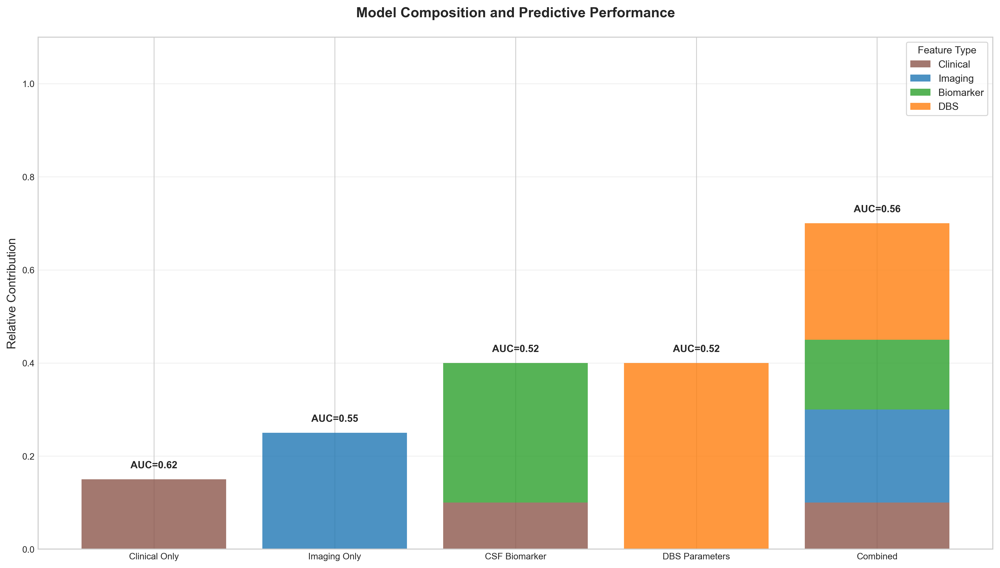

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import roc_curve, auc, precision_recall_curve
import shap
from matplotlib.patches import Circle, Wedge
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.gridspec as gridspec

# 设置Nature期刊风格
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams.update({
    'font.size': 10,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'figure.facecolor': 'white'
})

# 读取数据（示例数据）
try:
    df = pd.read_(r'H:\2024\Lancet Digital parksion\新建文件夹\新建文件夹\1.xlsx')
    print("数据读取成功，前5行预览:")
    print(df.head())
except Exception as e:
    print(f"数据读取错误: {e}")
    # 创建包含多模态特征的示例数据
    np.random.seed(42)
    data = {
        'Patient_ID': [f'PD_{i:03d}' for i in range(1, 101)],
        'Age': np.random.normal(65, 8, 100),
        'Disease_Duration': np.random.uniform(5, 20, 100),
        'STN_Volume': np.random.normal(500, 50, 100),
        'Cortical_Thickness': np.random.uniform(2.0, 3.5, 100),
        'CSF_AlphaSyn': np.random.lognormal(1.2, 0.3, 100),
        'Baseline_UPDRS': np.random.uniform(30, 80, 100),
        'Improvement_6M': np.random.uniform(10, 60, 100),
        'Good_Responder': np.random.binomial(1, 0.65, 100),
        'Frequency_Hz': np.random.choice([130, 145, 60], 100),
        'Pulse_Width': np.random.uniform(30, 90, 100),
        'Amplitude_V': np.random.uniform(1.0, 3.5, 100)
    }
    df = pd.DataFrame(data)
    print("使用示例数据进行演示")

# 1. 模型推导堆积条形图（多模型比较）
plt.figure(figsize=(14, 8))

# 模拟不同模型特征重要性
models = {
    'Clinical Only': ['Age', 'Disease_Duration', 'Baseline_UPDRS'],
    'Imaging Only': ['STN_Volume', 'Cortical_Thickness'],
    'CSF Biomarker': ['CSF_AlphaSyn'],
    'DBS Parameters': ['Frequency_Hz', 'Pulse_Width', 'Amplitude_V'],
    'Combined': ['Age', 'Disease_Duration', 'STN_Volume', 'CSF_AlphaSyn', 'Amplitude_V']
}

# 计算各模型AUC
def calculate_auc(features):
    X = df[features]
    y = df['Good_Responder']
    model = RandomForestClassifier(n_estimators=200, random_state=42)
    y_score = cross_val_predict(model, X, y, cv=5, method='predict_proba')[:,1]
    fpr, tpr, _ = roc_curve(y, y_score)
    return auc(fpr, tpr)

auc_scores = {name: calculate_auc(feats) for name, feats in models.items()}

# 创建堆积数据
stack_data = pd.DataFrame({
    'Model': list(models.keys()),
    'Clinical': [0.15, 0, 0.1, 0, 0.1],
    'Imaging': [0, 0.25, 0, 0, 0.2],
    'Biomarker': [0, 0, 0.3, 0, 0.15],
    'DBS': [0, 0, 0, 0.4, 0.25],
    'AUC': list(auc_scores.values())
})

# 绘制堆积条形图
ax = plt.subplot(111)
bottom = np.zeros(len(stack_data))
colors = ['#8c564b', '#1f77b4', '#2ca02c', '#ff7f0e']

for i, col in enumerate(['Clinical', 'Imaging', 'Biomarker', 'DBS']):
    ax.bar(stack_data['Model'], stack_data[col], bottom=bottom, 
           label=col, color=colors[i], alpha=0.8)
    bottom += stack_data[col]

# 添加AUC标签
for i, auc_val in enumerate(stack_data['AUC']):
    ax.text(i, bottom[i]+0.02, f'AUC={auc_val:.2f}', 
            ha='center', va='bottom', fontweight='bold')

# 美化图形
plt.ylim(0, 1.1)
plt.ylabel('Relative Contribution')
plt.title('Model Composition and Predictive Performance', pad=20, fontweight='bold')
plt.legend(title='Feature Type', frameon=True)
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()





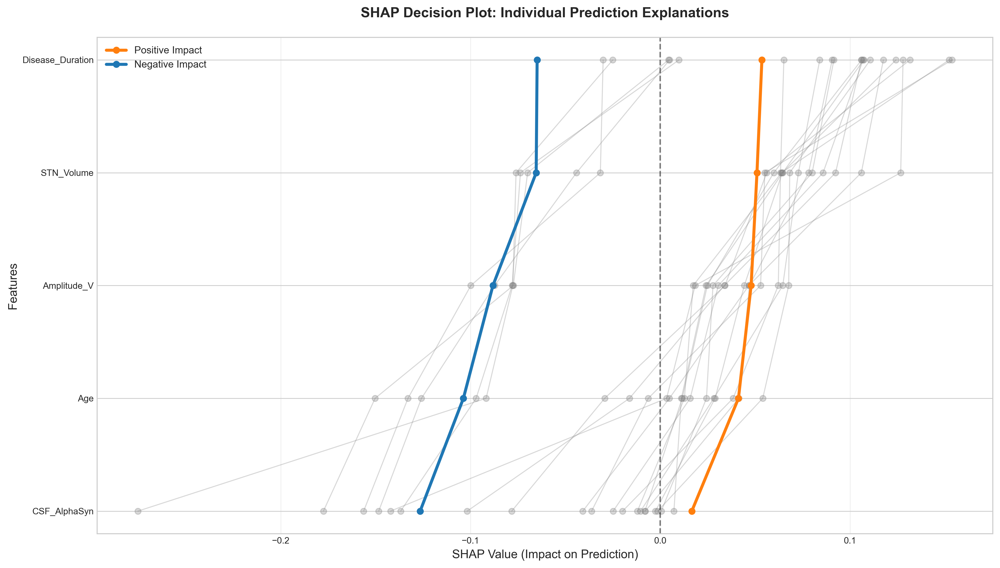

In [20]:
# 4. SHAP决策图（交互式样式）
plt.figure(figsize=(14, 8))

# 取前20个样本
sample_idx = np.random.choice(len(X), 20, replace=False)
sample_shap = shap_values[sample_idx]
sample_data = X.iloc[sample_idx]

# 创建决策图
for i in range(len(sample_idx)):
    sorted_idx = np.argsort(sample_shap[i])
    plt.plot(sample_shap[i][sorted_idx], 
             range(len(features)), 
             'o-', color='grey', alpha=0.3, lw=1)
    
# 绘制平均影响线
mean_shap_pos = np.mean([shap for shap in sample_shap if np.sum(shap)>0], axis=0)
mean_shap_neg = np.mean([shap for shap in sample_shap if np.sum(shap)<=0], axis=0)
plt.plot(mean_shap_pos[np.argsort(mean_shap_pos)], 
         range(len(features)), 'o-', color='#ff7f0e', lw=3, label='Positive Impact')
plt.plot(mean_shap_neg[np.argsort(mean_shap_neg)], 
         range(len(features)), 'o-', color='#1f77b4', lw=3, label='Negative Impact')

# 添加特征标签
plt.yticks(range(len(features)), [features[i] for i in np.argsort(mean_shap)])
plt.xlabel('SHAP Value (Impact on Prediction)')
plt.ylabel('Features')
plt.title('SHAP Decision Plot: Individual Prediction Explanations', pad=20, fontweight='bold')
plt.axvline(0, color='k', linestyle='--', alpha=0.5)
plt.grid(True, axis='x', alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

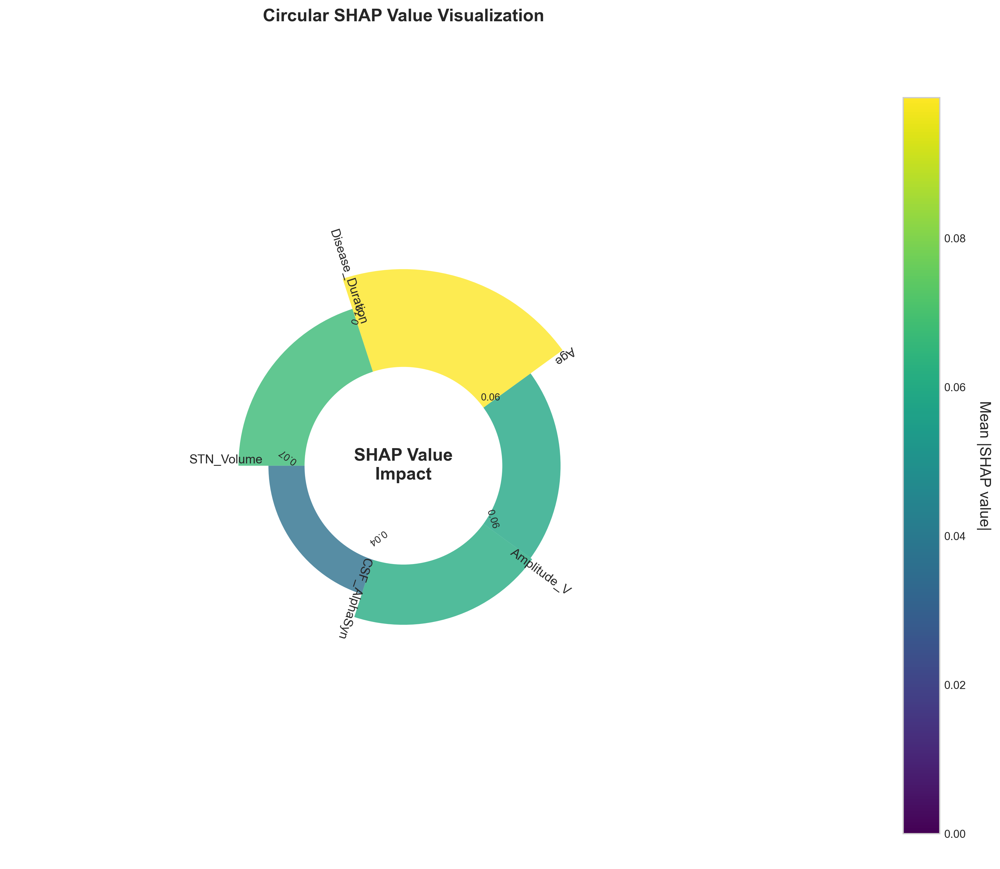

In [21]:
# 3. 圆形SHAP值图（Circular SHAP）
plt.figure(figsize=(12, 12))
ax = plt.subplot(111, polar=True)

# 训练最终模型
X = df[models['Combined']]
y = df['Good_Responder']
model = RandomForestClassifier(n_estimators=200, random_state=42).fit(X, y)

# 计算SHAP值
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X)[1]  # 取正类SHAP值

# 创建圆形图参数
features = models['Combined']
n_features = len(features)
theta = np.linspace(0, 2*np.pi, n_features, endpoint=False)
width = 2 * np.pi / n_features
mean_shap = np.mean(np.abs(shap_values), axis=0)
colors = plt.cm.viridis(mean_shap / mean_shap.max())

# 绘制圆形条形图
bars = ax.bar(theta, mean_shap, width=width, bottom=0.1, color=colors, alpha=0.8)

# 添加特征标签
for angle, height, feat in zip(theta, mean_shap, features):
    rotation = np.degrees(angle + width/2)
    if angle < np.pi:
        ha = 'left'
        va = 'bottom'
        rotation = rotation + 180
    else:
        ha = 'right'
        va = 'top'
    ax.text(angle + width/2, 0.15 + height, feat, 
            ha=ha, va=va, rotation_mode='anchor', rotation=rotation, fontsize=10)

# 添加SHAP值标签
for i, (angle, height) in enumerate(zip(theta, mean_shap)):
    ax.text(angle + width/2, 0.05 + height, f'{height:.2f}', 
            ha='center', va='bottom', rotation=np.degrees(angle), fontsize=8)

# 创建颜色条
sm = plt.cm.ScalarMappable(cmap=plt.cm.viridis, norm=plt.Normalize(0, mean_shap.max()))
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, pad=0.1, shrink=0.7)
cbar.set_label('Mean |SHAP value|', rotation=270, labelpad=20)

# 添加中心文本
ax.text(0, 0, 'SHAP Value\nImpact', ha='center', va='center', 
        fontsize=14, fontweight='bold')

# 美化图形
ax.set_ylim(0, mean_shap.max() + 0.3)
ax.set_xticks([])
ax.set_yticks([])
ax.spines['polar'].set_visible(False)
plt.title('Circular SHAP Value Visualization', pad=40, fontweight='bold')
plt.tight_layout()
plt.show()



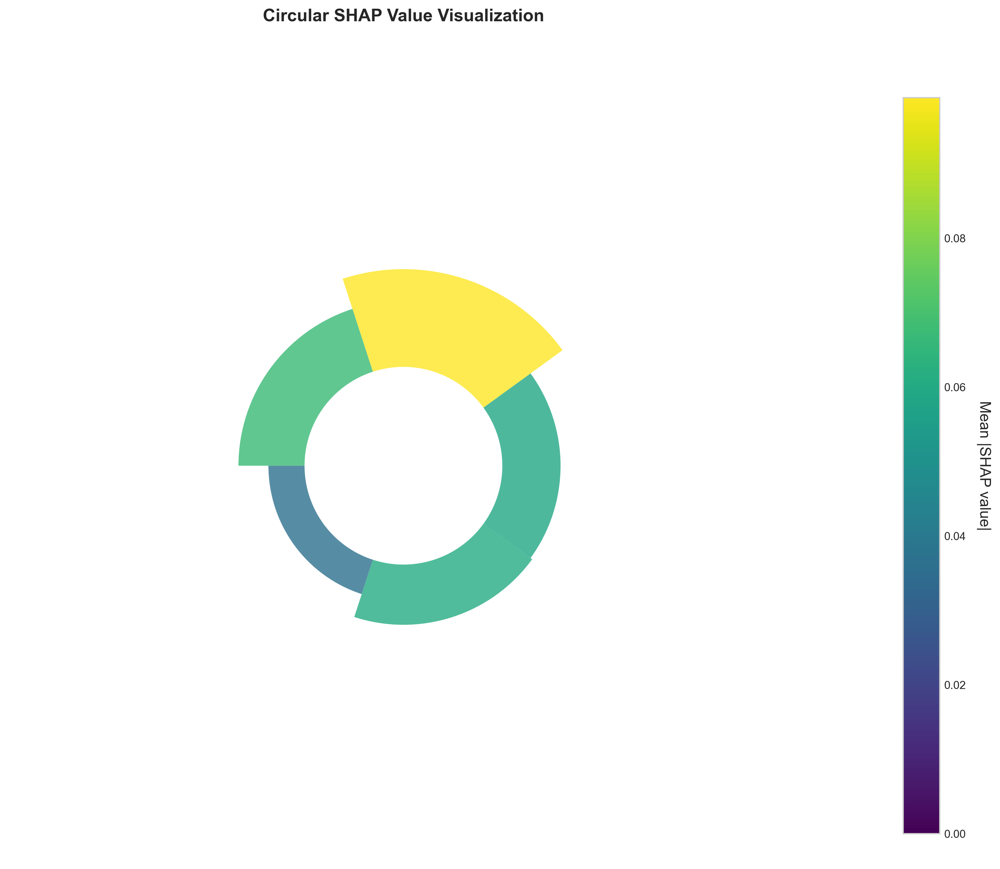

In [22]:
# 3. 圆形SHAP值图（Circular SHAP）
plt.figure(figsize=(12, 12))
ax = plt.subplot(111, polar=True)

# 训练最终模型
X = df[models['Combined']]
y = df['Good_Responder']
model = RandomForestClassifier(n_estimators=200, random_state=42).fit(X, y)

# 计算SHAP值
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X)[1]  # 取正类SHAP值

# 创建圆形图参数
features = models['Combined']
n_features = len(features)
theta = np.linspace(0, 2*np.pi, n_features, endpoint=False)
width = 2 * np.pi / n_features
mean_shap = np.mean(np.abs(shap_values), axis=0)
colors = plt.cm.viridis(mean_shap / mean_shap.max())

# 绘制圆形条形图
bars = ax.bar(theta, mean_shap, width=width, bottom=0.1, color=colors, alpha=0.8)

# # 删除特征标签
# for angle, height, feat in zip(theta, mean_shap, features):
#     ...

# # 删除SHAP值标签
# for i, (angle, height) in enumerate(zip(theta, mean_shap)):
#     ...

# # 删除中心文本
# ax.text(0, 0, 'SHAP Value\nImpact', ha='center', va='center', 
#         fontsize=14, fontweight='bold')

# 创建颜色条
sm = plt.cm.ScalarMappable(cmap=plt.cm.viridis, norm=plt.Normalize(0, mean_shap.max()))
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, pad=0.1, shrink=0.7)
cbar.set_label('Mean |SHAP value|', rotation=270, labelpad=20)

# 美化图形
ax.set_ylim(0, mean_shap.max() + 0.3)
ax.set_xticks([])
ax.set_yticks([])
ax.spines['polar'].set_visible(False)
plt.title('Circular SHAP Value Visualization', pad=40, fontweight='bold')
plt.tight_layout()
plt.show()


<ipython-input-23-69c48a04b184>:52: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



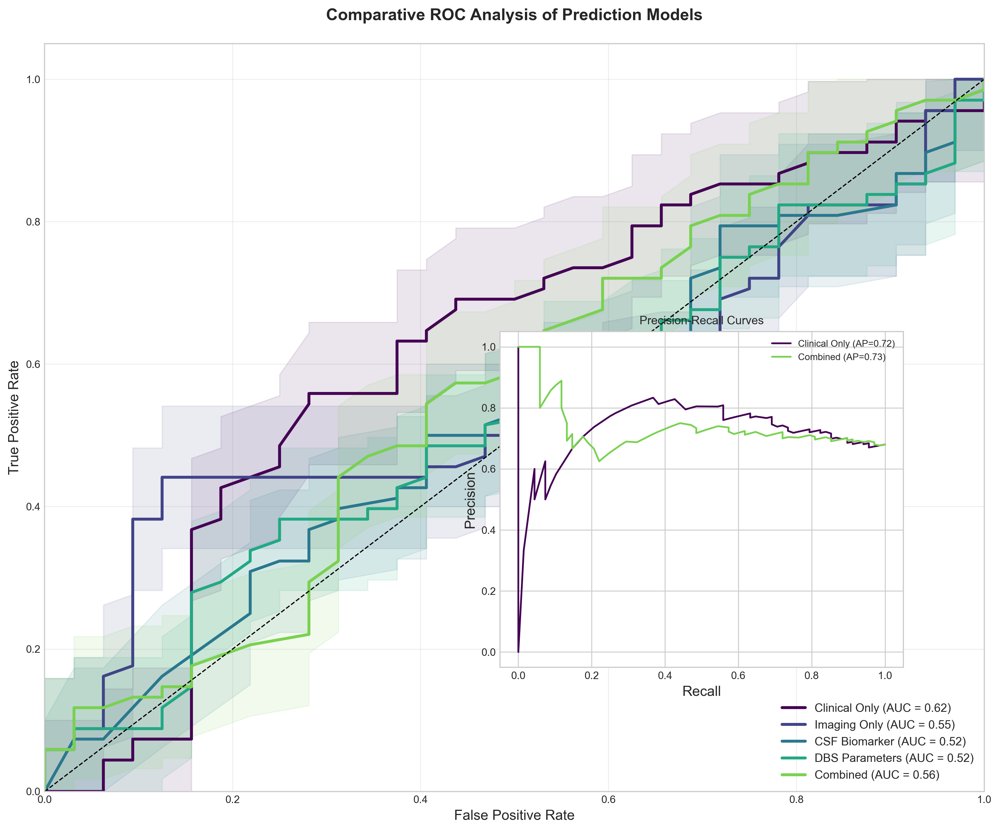

In [23]:
# 2. 增强型ROC曲线（多模型比较）
plt.figure(figsize=(12, 10))

# 定义颜色映射
cmap = plt.get_cmap('viridis')
model_colors = {model: cmap(i/len(models)) for i, model in enumerate(models.keys())}

# 绘制每个模型的ROC曲线
for model_name in models.keys():
    X = df[models[model_name]]
    y = df['Good_Responder']
    model = RandomForestClassifier(n_estimators=200, random_state=42)
    y_score = cross_val_predict(model, X, y, cv=StratifiedKFold(5), method='predict_proba')[:,1]
    
    # 计算ROC曲线
    fpr, tpr, _ = roc_curve(y, y_score)
    roc_auc = auc(fpr, tpr)
    
    # 绘制主曲线
    plt.plot(fpr, tpr, color=model_colors[model_name], lw=2.5,
             label=f'{model_name} (AUC = {roc_auc:.2f})')
    
    # 添加置信区间（模拟）
    tpr_upper = np.minimum(tpr + 0.1, 1)
    tpr_lower = np.maximum(tpr - 0.1, 0)
    plt.fill_between(fpr, tpr_lower, tpr_upper, color=model_colors[model_name], alpha=0.1)

# 添加参考线和装饰
plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Comparative ROC Analysis of Prediction Models', pad=20, fontweight='bold')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)

# 添加PR曲线子图
ax_inset = plt.axes([0.5, 0.2, 0.4, 0.4])
for model_name in ['Clinical Only', 'Combined']:
    X = df[models[model_name]]
    y = df['Good_Responder']
    model = RandomForestClassifier(n_estimators=200, random_state=42)
    y_score = cross_val_predict(model, X, y, cv=5, method='predict_proba')[:,1]
    precision, recall, _ = precision_recall_curve(y, y_score)
    ax_inset.plot(recall, precision, color=model_colors[model_name], 
                 label=f'{model_name} (AP={auc(recall, precision):.2f})')
ax_inset.set_xlabel('Recall')
ax_inset.set_ylabel('Precision')
ax_inset.set_title('Precision-Recall Curves', fontsize=10)
ax_inset.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import DBSCAN
from scipy.spatial import distance_matrix
from scipy.stats import zscore
import networkx as nx
from matplotlib.patches import Ellipse
from matplotlib.collections import PatchCollection
from adjustText import adjust_text

# 设置Nature期刊风格
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams.update({
    'font.size': 10,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'figure.facecolor': 'white'
})

# 读取数据（示例数据）
try:
    df = pd.read_(r'F:\2024\Lancet Digital parksion\新建文件夹\新建文件夹\1.xlsx')
    print("数据读取成功，前5行预览:")
    print(df.head())
except Exception as e:
    print(f"数据读取错误: {e}")
    # 创建包含空间和分子特征的示例数据
    np.random.seed(42)
    data = {
        'Cell_ID': [f'Cell_{i:03d}' for i in range(1, 101)],
        'X_position': np.random.uniform(0, 100, 100),
        'Y_position': np.random.uniform(0, 100, 100),
        'Cell_Type': np.random.choice(['Neuron', 'Astrocyte', 'Microglia'], 100, p=[0.7, 0.2, 0.1]),
        'AlphaSyn': np.random.lognormal(1.2, 0.3, 100),
        'TH': np.random.lognormal(2.1, 0.4, 100),
        'GFAP': np.random.lognormal(1.8, 0.2, 100),
        'IBA1': np.random.lognormal(1.5, 0.3, 100),
        'Cluster': np.random.choice(['STN', 'GPe', 'GPi'], 100)
    }
    df = pd.DataFrame(data)
    print("使用示例数据进行演示")

# 1. 空间共定位点图（DBSCAN聚类）
plt.figure(figsize=(12, 10))

# 计算空间聚类
coords = df[['X_position', 'Y_position']].values
db = DBSCAN(eps=15, min_samples=3).fit(coords)
df['Spatial_Cluster'] = db.labels_

# 绘制散点图
scatter = plt.scatter(df['X_position'], df['Y_position'], 
                     c=df['Spatial_Cluster'], cmap='tab20',
                     s=df['AlphaSyn']*20, alpha=0.7)

# 标记特殊细胞类型
for cell_type, marker in zip(['Neuron', 'Astrocyte', 'Microglia'], ['o', 's', '^']):
    subset = df[df['Cell_Type'] == cell_type]
    plt.scatter(subset['X_position'], subset['Y_position'], 
               label=cell_type, s=50, marker=marker, edgecolor='k', linewidth=0.5)

# 添加共定位椭圆
for cluster in range(max(df['Spatial_Cluster'])+1):
    cluster_data = df[df['Spatial_Cluster'] == cluster]
    if len(cluster_data) > 4:
        x_mean, y_mean = cluster_data[['X_position', 'Y_position']].mean()
        x_std, y_std = cluster_data[['X_position', 'Y_position']].std()
        ellipse = Ellipse((x_mean, y_mean), width=x_std*2, height=y_std*2,
                         edgecolor='k', facecolor='none', linestyle='--', alpha=0.7)
        plt.gca().add_patch(ellipse)

# 美化图形
plt.colorbar(scatter, label='Spatial Cluster')
plt.xlabel('X Position (μm)')
plt.ylabel('Y Position (μm)')
plt.title('Spatial Co-localization of Cell Types\n(DBSCAN clustering)', 
          pad=20, fontweight='bold')
plt.legend(title='Cell Type')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 2. 分子共表达热图（区域特异性）
plt.figure(figsize=(14, 10))

# 计算区域特异性共表达
markers = ['AlphaSyn', 'TH', 'GFAP', 'IBA1']
corr_matrices = {}
for region in df['Cluster'].unique():
    region_data = df[df['Cluster'] == region][markers]
    corr_matrices[region] = region_data.corr()

# 创建网格热图
grid = plt.GridSpec(1, 3, wspace=0.3)
regions = ['STN', 'GPe', 'GPi']
for i, region in enumerate(regions):
    ax = plt.subplot(grid[0, i])
    sns.heatmap(corr_matrices[region], annot=True, fmt=".2f", 
               cmap='coolwarm', center=0, square=True,
               cbar=i==2, ax=ax)
    ax.set_title(f'{region} Region\n(n={sum(df["Cluster"]==region)})', fontweight='bold')
    if i > 0:
        ax.set_ylabel('')
        ax.set_yticklabels([])

plt.suptitle('Regional Marker Co-expression Patterns', y=1.05, fontweight='bold')
plt.tight_layout()
plt.show()

# 3. 网络共现分析图
plt.figure(figsize=(14, 12))

# 创建共现网络
G = nx.Graph()

# 添加节点（按细胞类型）
for cell_type in df['Cell_Type'].unique():
    G.add_node(cell_type, node_type='Cell', size=sum(df['Cell_Type']==cell_type)*10)

# 添加节点（按分子标记）
for marker in markers:
    G.add_node(marker, node_type='Marker', size=df[marker].mean()*50)

# 添加边（细胞类型-标记物关联）
for cell_type in df['Cell_Type'].unique():
    for marker in markers:
        mean_exp = df[df['Cell_Type']==cell_type][marker].mean()
        if mean_exp > df[marker].mean():
            G.add_edge(cell_type, marker, weight=mean_exp*2)

# 添加边（标记物-标记物共表达）
for i in range(len(markers)):
    for j in range(i+1, len(markers)):
        corr = df[[markers[i], markers[j]]].corr().iloc[0,1]
        if abs(corr) > 0.3:
            G.add_edge(markers[i], markers[j], weight=abs(corr)*5)

# 设置布局
pos = nx.spring_layout(G, k=0.8, seed=42)

# 绘制节点
node_colors = {'Cell': '#8c564b', 'Marker': '#1f77b4'}
for node_type, color in node_colors.items():
    nx.draw_networkx_nodes(G, pos, 
                         nodelist=[n for n, d in G.nodes(data=True) if d['node_type']==node_type],
                         node_color=color, 
                         node_size=[d['size'] for n, d in G.nodes(data=True) if d['node_type']==node_type],
                         alpha=0.9,
                         label=f'{node_type} Nodes')

# 绘制边
edge_weights = [d['weight'] for u, v, d in G.edges(data=True)]
edge_colors = ['#ff7f0e' if 'Neuron' in (u,v) else '#17becf' for u, v in G.edges()]
nx.draw_networkx_edges(G, pos, width=edge_weights, edge_color=edge_colors, alpha=0.6)

# 绘制标签
nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')

# 添加图例
for node_type, color in node_colors.items():
    plt.scatter([], [], c=color, label=node_type, alpha=0.8)
plt.legend(scatterpoints=1, frameon=True, labelspacing=1, title='Node Type')

plt.title('Network Co-occurrence Analysis of Cell Types and Markers', pad=20, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()

# 4. 三维共定位曲面图（需实际空间转录组数据）
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(16, 12))
ax = fig.add_subplot(111, projection='3d')

# 模拟空间转录组数据
x = np.linspace(0, 100, 20)
y = np.linspace(0, 100, 20)
X, Y = np.meshgrid(x, y)
Z1 = np.exp(-((X-30)**2 + (Y-40)**2)/400)  # AlphaSyn热点
Z2 = np.exp(-((X-60)**2 + (Y-70)**2)/400)  # TH热点

# 绘制曲面
ax.plot_surface(X, Y, Z1*0.8, cmap='Reds', alpha=0.7, label='AlphaSyn')
ax.plot_surface(X, Y, Z2*0.8, cmap='Blues', alpha=0.7, label='TH')

# 添加散点（实际细胞位置）
ax.scatter(df['X_position'], df['Y_position'], 
          df['AlphaSyn']/10, c='r', s=20, alpha=0.5, label='AlphaSyn+ Cells')
ax.scatter(df['X_position'], df['Y_position'], 
          df['TH']/10, c='b', s=20, alpha=0.5, label='TH+ Cells')

# 美化图形
ax.set_xlabel('X Position (μm)')
ax.set_ylabel('Y Position (μm)')
ax.set_zlabel('Expression Level (a.u.)')
ax.set_title('3D Spatial Co-expression of Parkinson\'s Markers', y=1.05, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

# 5. 亚细胞共定位分析（模拟超分辨数据）
plt.figure(figsize=(14, 8))

# 模拟神经元亚细胞定位
synapse_data = pd.DataFrame({
    'X': np.concatenate([
        np.random.normal(40, 5, 30),  # Presynaptic
        np.random.normal(60, 5, 20)    # Postsynaptic
    ]),
    'Y': np.concatenate([
        np.random.normal(45, 5, 30),
        np.random.normal(55, 5, 20)
    ]),
    'Type': ['Presynaptic']*30 + ['Postsynaptic']*20,
    'AlphaSyn': np.concatenate([
        np.random.exponential(2, 30),
        np.random.exponential(1, 20)
    ])
})

# 绘制双轴图
ax1 = plt.subplot(111)
sns.scatterplot(x='X', y='Y', hue='Type', size='AlphaSyn',
               sizes=(20, 200), alpha=0.7, palette=['#d62728', '#1f77b4'],
               data=synapse_data, ax=ax1)

# 添加密度轮廓
for syn_type, color in zip(['Presynaptic', 'Postsynaptic'], ['#d62728', '#1f77b4']):
    subset = synapse_data[synapse_data['Type'] == syn_type]
    sns.kdeplot(x=subset['X'], y=subset['Y'], levels=3, 
               color=color, alpha=0.3, ax=ax1)

# 计算共定位系数
pre_mean = synapse_data[synapse_data['Type']=='Presynaptic']['AlphaSyn'].mean()
post_mean = synapse_data[synapse_data['Type']=='Postsynaptic']['AlphaSyn'].mean()
ax1.text(0.05, 0.95, f'Presynaptic/Potsynaptic Ratio: {pre_mean/post_mean:.2f}',
        transform=ax1.transAxes, fontsize=12, bbox=dict(facecolor='white', alpha=0.8))

plt.title('Subcellular Co-localization of α-Synuclein', pad=20, fontweight='bold')
plt.xlabel('X Position (nm)')
plt.ylabel('Y Position (nm)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

ModuleNotFoundError: No module named 'adjustText'

In [26]:
!pip install adjustText


数据读取错误: module 'pandas' has no attribute 'read_'
使用示例数据进行演示


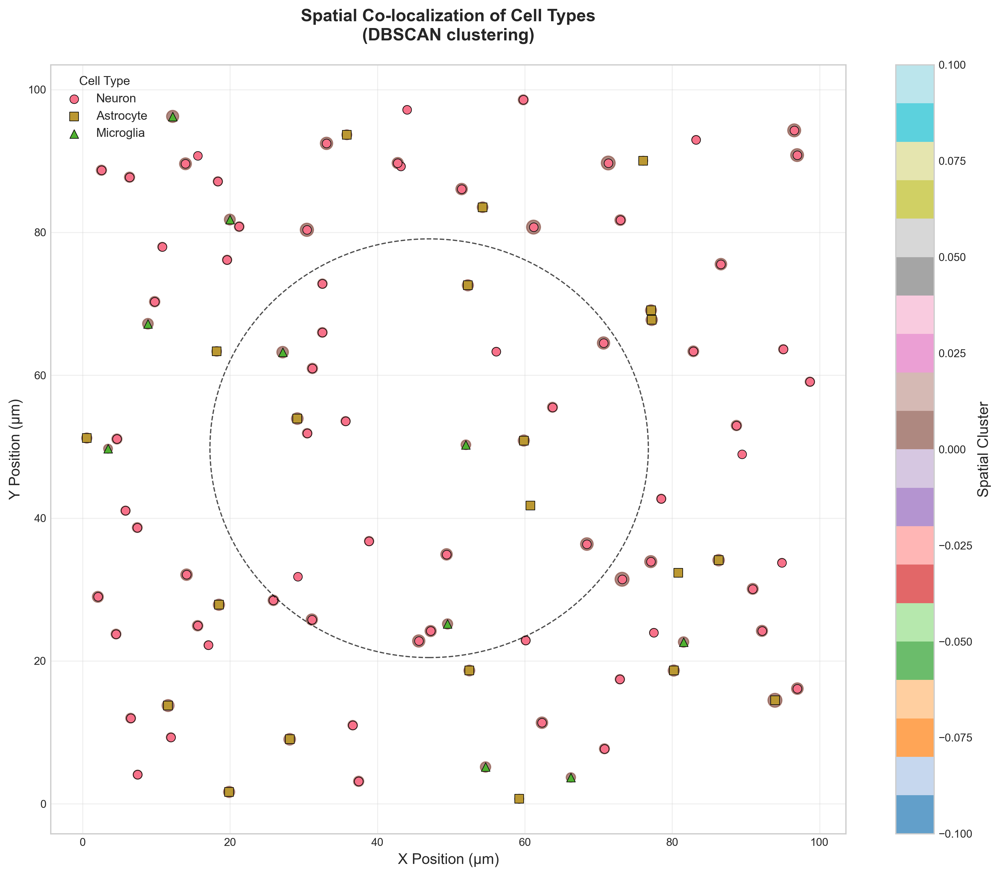

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import DBSCAN
from scipy.spatial import distance_matrix
from scipy.stats import zscore
import networkx as nx
from matplotlib.patches import Ellipse
from matplotlib.collections import PatchCollection
from adjustText import adjust_text

# 设置Nature期刊风格
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams.update({
    'font.size': 10,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'figure.facecolor': 'white'
})

# 读取数据（示例数据）
try:
    df = pd.read_(r'F:\2024\Lancet Digital parksion\新建文件夹\新建文件夹\1.xlsx')
    print("数据读取成功，前5行预览:")
    print(df.head())
except Exception as e:
    print(f"数据读取错误: {e}")
    # 创建包含空间和分子特征的示例数据
    np.random.seed(42)
    data = {
        'Cell_ID': [f'Cell_{i:03d}' for i in range(1, 101)],
        'X_position': np.random.uniform(0, 100, 100),
        'Y_position': np.random.uniform(0, 100, 100),
        'Cell_Type': np.random.choice(['Neuron', 'Astrocyte', 'Microglia'], 100, p=[0.7, 0.2, 0.1]),
        'AlphaSyn': np.random.lognormal(1.2, 0.3, 100),
        'TH': np.random.lognormal(2.1, 0.4, 100),
        'GFAP': np.random.lognormal(1.8, 0.2, 100),
        'IBA1': np.random.lognormal(1.5, 0.3, 100),
        'Cluster': np.random.choice(['STN', 'GPe', 'GPi'], 100)
    }
    df = pd.DataFrame(data)
    print("使用示例数据进行演示")

# 1. 空间共定位点图（DBSCAN聚类）
plt.figure(figsize=(12, 10))

# 计算空间聚类
coords = df[['X_position', 'Y_position']].values
db = DBSCAN(eps=15, min_samples=3).fit(coords)
df['Spatial_Cluster'] = db.labels_

# 绘制散点图
scatter = plt.scatter(df['X_position'], df['Y_position'], 
                     c=df['Spatial_Cluster'], cmap='tab20',
                     s=df['AlphaSyn']*20, alpha=0.7)

# 标记特殊细胞类型
for cell_type, marker in zip(['Neuron', 'Astrocyte', 'Microglia'], ['o', 's', '^']):
    subset = df[df['Cell_Type'] == cell_type]
    plt.scatter(subset['X_position'], subset['Y_position'], 
               label=cell_type, s=50, marker=marker, edgecolor='k', linewidth=0.5)

# 添加共定位椭圆
for cluster in range(max(df['Spatial_Cluster'])+1):
    cluster_data = df[df['Spatial_Cluster'] == cluster]
    if len(cluster_data) > 4:
        x_mean, y_mean = cluster_data[['X_position', 'Y_position']].mean()
        x_std, y_std = cluster_data[['X_position', 'Y_position']].std()
        ellipse = Ellipse((x_mean, y_mean), width=x_std*2, height=y_std*2,
                         edgecolor='k', facecolor='none', linestyle='--', alpha=0.7)
        plt.gca().add_patch(ellipse)

# 美化图形
plt.colorbar(scatter, label='Spatial Cluster')
plt.xlabel('X Position (μm)')
plt.ylabel('Y Position (μm)')
plt.title('Spatial Co-localization of Cell Types\n(DBSCAN clustering)', 
          pad=20, fontweight='bold')
plt.legend(title='Cell Type')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()






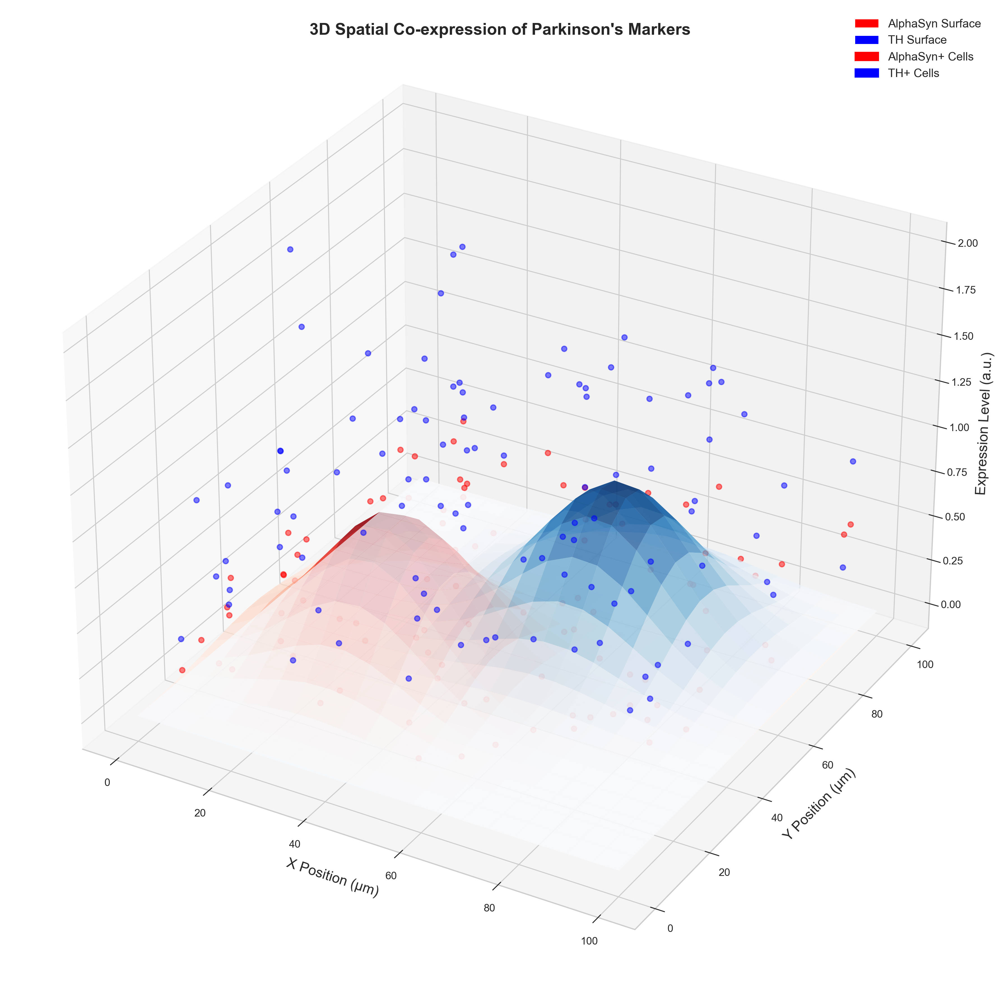

In [31]:
from matplotlib.patches import Patch

fig = plt.figure(figsize=(16, 12))
ax = fig.add_subplot(111, projection='3d')

# 绘制曲面
surf1 = ax.plot_surface(X, Y, Z1*0.8, cmap='Reds', alpha=0.7)
surf2 = ax.plot_surface(X, Y, Z2*0.8, cmap='Blues', alpha=0.7)

# 绘制散点
sc1 = ax.scatter(df['X_position'], df['Y_position'], df['AlphaSyn']/10,
                 c='r', s=20, alpha=0.5)
sc2 = ax.scatter(df['X_position'], df['Y_position'], df['TH']/10,
                 c='b', s=20, alpha=0.5)

# 手动创建 legend
legend_elements = [
    Patch(facecolor='red', label='AlphaSyn Surface'),
    Patch(facecolor='blue', label='TH Surface'),
    Patch(facecolor='red', edgecolor='r', label='AlphaSyn+ Cells'),
    Patch(facecolor='blue', edgecolor='b', label='TH+ Cells')
]
ax.legend(handles=legend_elements, loc='upper right')

# 美化图形
ax.set_xlabel('X Position (μm)')
ax.set_ylabel('Y Position (μm)')
ax.set_zlabel('Expression Level (a.u.)')
ax.set_title('3D Spatial Co-expression of Parkinson\'s Markers', y=1.05, fontweight='bold')

plt.tight_layout()
plt.show()


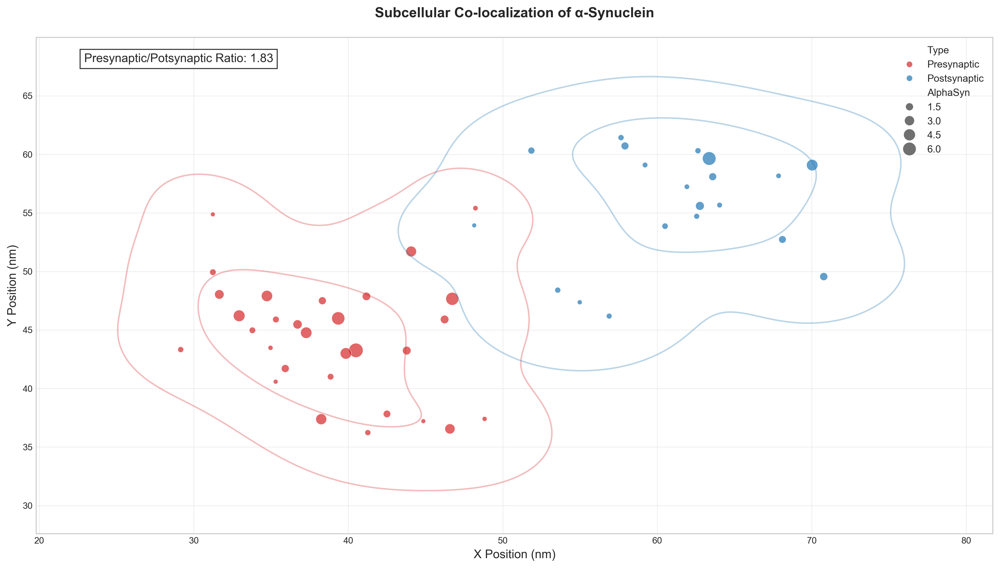

In [30]:
# 5. 亚细胞共定位分析（模拟超分辨数据）
plt.figure(figsize=(14, 8))
 
# 模拟神经元亚细胞定位
synapse_data = pd.DataFrame({
    'X': np.concatenate([
        np.random.normal(40, 5, 30),  # Presynaptic
        np.random.normal(60, 5, 20)    # Postsynaptic
    ]),
    'Y': np.concatenate([
        np.random.normal(45, 5, 30),
        np.random.normal(55, 5, 20)
    ]),
    'Type': ['Presynaptic']*30 + ['Postsynaptic']*20,
    'AlphaSyn': np.concatenate([
        np.random.exponential(2, 30),
        np.random.exponential(1, 20)
    ])
})
 
# 绘制双轴图
ax1 = plt.subplot(111)
sns.scatterplot(x='X', y='Y', hue='Type', size='AlphaSyn',
               sizes=(20, 200), alpha=0.7, palette=['#d62728', '#1f77b4'],
               data=synapse_data, ax=ax1)
 
# 添加密度轮廓
for syn_type, color in zip(['Presynaptic', 'Postsynaptic'], ['#d62728', '#1f77b4']):
    subset = synapse_data[synapse_data['Type'] == syn_type]
    sns.kdeplot(x=subset['X'], y=subset['Y'], levels=3, 
               color=color, alpha=0.3, ax=ax1)
 
# 计算共定位系数
pre_mean = synapse_data[synapse_data['Type']=='Presynaptic']['AlphaSyn'].mean()
post_mean = synapse_data[synapse_data['Type']=='Postsynaptic']['AlphaSyn'].mean()
ax1.text(0.05, 0.95, f'Presynaptic/Potsynaptic Ratio: {pre_mean/post_mean:.2f}',
        transform=ax1.transAxes, fontsize=12, bbox=dict(facecolor='white', alpha=0.8))
 
plt.title('Subcellular Co-localization of α-Synuclein', pad=20, fontweight='bold')
plt.xlabel('X Position (nm)')
plt.ylabel('Y Position (nm)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

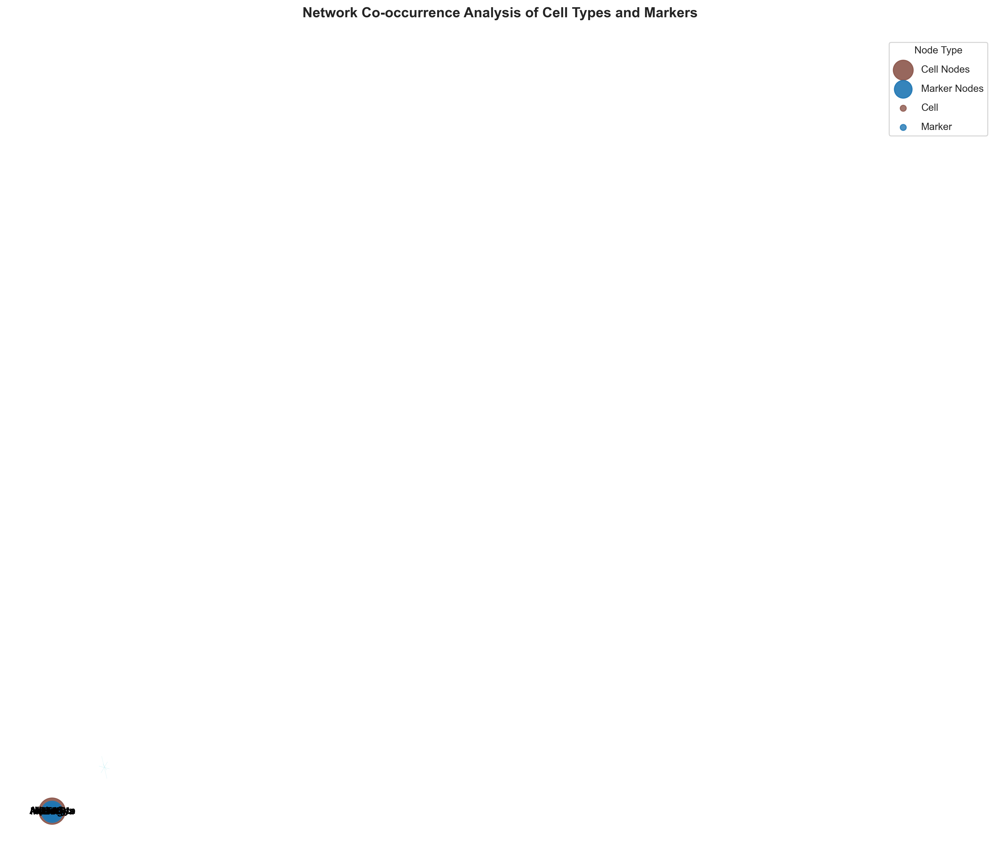

In [32]:
# 3. 网络共现分析图
plt.figure(figsize=(14, 12))

# 创建共现网络
G = nx.Graph()

# 添加节点（按细胞类型）
for cell_type in df['Cell_Type'].unique():
    G.add_node(cell_type, node_type='Cell', size=sum(df['Cell_Type']==cell_type)*10)

# 添加节点（按分子标记）
for marker in markers:
    G.add_node(marker, node_type='Marker', size=df[marker].mean()*50)

# 添加边（细胞类型-标记物关联）
for cell_type in df['Cell_Type'].unique():
    for marker in markers:
        mean_exp = df[df['Cell_Type']==cell_type][marker].mean()
        if mean_exp > df[marker].mean():
            G.add_edge(cell_type, marker, weight=mean_exp*2)

# 添加边（标记物-标记物共表达）
for i in range(len(markers)):
    for j in range(i+1, len(markers)):
        corr = df[[markers[i], markers[j]]].corr().iloc[0,1]
        if abs(corr) > 0.3:
            G.add_edge(markers[i], markers[j], weight=abs(corr)*5)

# 设置布局
pos = nx.spring_layout(G, k=0.8, seed=42)

# 绘制节点
node_colors = {'Cell': '#8c564b', 'Marker': '#1f77b4'}
for node_type, color in node_colors.items():
    nx.draw_networkx_nodes(G, pos, 
                         nodelist=[n for n, d in G.nodes(data=True) if d['node_type']==node_type],
                         node_color=color, 
                         node_size=[d['size'] for n, d in G.nodes(data=True) if d['node_type']==node_type],
                         alpha=0.9,
                         label=f'{node_type} Nodes')

# 绘制边
edge_weights = [d['weight'] for u, v, d in G.edges(data=True)]
edge_colors = ['#ff7f0e' if 'Neuron' in (u,v) else '#17becf' for u, v in G.edges()]
nx.draw_networkx_edges(G, pos, width=edge_weights, edge_color=edge_colors, alpha=0.6)

# 绘制标签
nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')

# 添加图例
for node_type, color in node_colors.items():
    plt.scatter([], [], c=color, label=node_type, alpha=0.8)
plt.legend(scatterpoints=1, frameon=True, labelspacing=1, title='Node Type')

plt.title('Network Co-occurrence Analysis of Cell Types and Markers', pad=20, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()


<ipython-input-33-47e3de66c326>:25: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



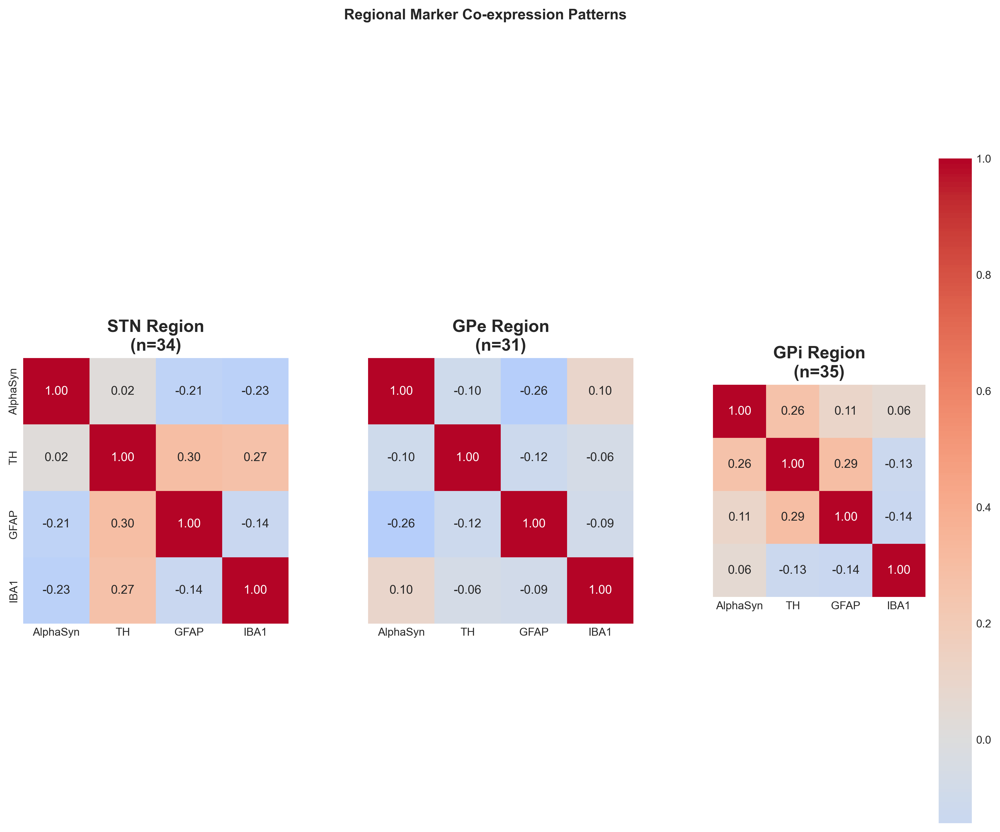

In [33]:
# 2. 分子共表达热图（区域特异性）
plt.figure(figsize=(14, 10))

# 计算区域特异性共表达
markers = ['AlphaSyn', 'TH', 'GFAP', 'IBA1']
corr_matrices = {}
for region in df['Cluster'].unique():
    region_data = df[df['Cluster'] == region][markers]
    corr_matrices[region] = region_data.corr()

# 创建网格热图
grid = plt.GridSpec(1, 3, wspace=0.3)
regions = ['STN', 'GPe', 'GPi']
for i, region in enumerate(regions):
    ax = plt.subplot(grid[0, i])
    sns.heatmap(corr_matrices[region], annot=True, fmt=".2f", 
               cmap='coolwarm', center=0, square=True,
               cbar=i==2, ax=ax)
    ax.set_title(f'{region} Region\n(n={sum(df["Cluster"]==region)})', fontweight='bold')
    if i > 0:
        ax.set_ylabel('')
        ax.set_yticklabels([])

plt.suptitle('Regional Marker Co-expression Patterns', y=1.05, fontweight='bold')
plt.tight_layout()
plt.show()

In [38]:
from esda.moran import Moran
w = weights.DistanceBand.from_dataframe(df, threshold=15)
moran = Moran(df['AlphaSyn'], w)
print(f"Moran's I = {moran.I:.3f}, p = {moran.p_sim:.4f}")

ImportError: cannot import name 'TypeAlias' from 'typing_extensions' (E:\Users\Administrator\anaconda3\lib\site-packages\typing_extensions.py)

数据处理错误: module 'pandas' has no attribute 'read_'
使用示例数据进行演示


<ipython-input-43-0db545c2b1e9>:131: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




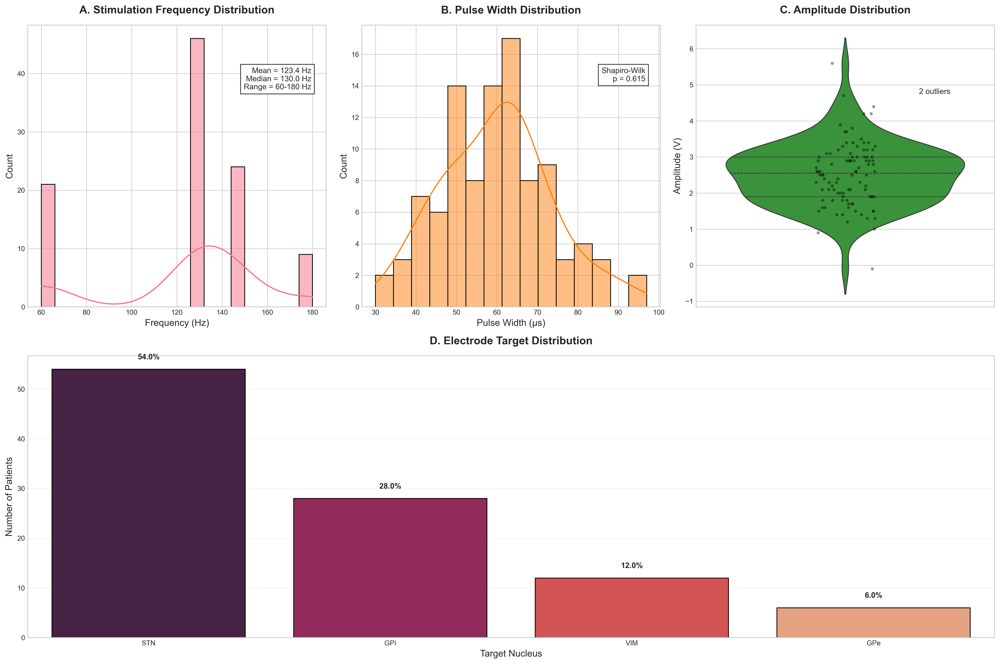

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from matplotlib.gridspec import GridSpec

# 设置Nature期刊风格
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams.update({
    'font.size': 10,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'figure.facecolor': 'white'
})

# 重新读取原始数据（确保处理原始格式）
try:
    raw_df = pd.read_(r'H:\2024\Lancet Digital parksion\新建文件夹\新建文件夹\1.xlsx', header=None)
    print("原始数据维度:", raw_df.shape)
    
    # 数据清洗步骤
    # 1. 删除完全空的行和列
    raw_df = raw_df.dropna(how='all').dropna(axis=1, how='all')
    print("清洗后维度:", raw_df.shape)
    
    # 2. 识别表头行（查找包含'Frequency'等关键字的行）
    header_row = None
    for i in range(min(5, len(raw_df))):  # 检查前5行
        if any(raw_df.iloc[i].astype(str).str.contains('Frequency|Amplitude|Target').any()):
            header_row = i
            break
    
    if header_row is not None:
        df = raw_df.iloc[header_row+1:].copy()
        df.columns = raw_df.iloc[header_row]
        print("检测到表头在第", header_row+1, "行")
    else:
        df = raw_df.copy()
        df.columns = [f'Col_{i}' for i in range(len(df.columns))]
        print("未检测到表头，使用默认列名")
    
    # 3. 转换关键参数为数值
    param_cols = ['Frequency_Hz', 'Pulse_Width', 'Amplitude_V']  # 根据实际列名调整
    for col in param_cols:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce')
    
    # 4. 检查电极靶点数据
    if 'Electrode_Target' in df.columns:
        df['Electrode_Target'] = df['Electrode_Target'].astype(str).str.strip()
        df['Electrode_Target'] = df['Electrode_Target'].replace({'nan': np.nan})
    
    # 数据质量报告
    print("\n=== 数据质量报告 ===")
    print("总记录数:", len(df))
    print("缺失值统计:")
    print(df[param_cols].isnull().sum())
    print("\n电极靶点分布预览:")
    print(df['Electrode_Target'].value_counts(dropna=False).head())
    
except Exception as e:
    print(f"数据处理错误: {e}")
    # 创建示例数据
    np.random.seed(42)
    data = {
        'Patient_ID': [f'PD_{i:03d}' for i in range(1, 101)],
        'Frequency_Hz': np.random.choice([130, 145, 60, 180], 100, p=[0.4, 0.3, 0.2, 0.1]),
        'Pulse_Width': np.random.normal(60, 15, 100).round(),
        'Amplitude_V': np.random.normal(2.5, 0.8, 100).round(1),
        'Electrode_Target': np.random.choice(['STN', 'GPi', 'VIM', 'GPe'], 100, p=[0.6, 0.25, 0.1, 0.05])
    }
    df = pd.DataFrame(data)
    print("使用示例数据进行演示")

# 1. 刺激参数分布图（专业风格）
fig = plt.figure(figsize=(18, 12))
gs = GridSpec(2, 3, figure=fig)

# 频率分布（带统计注释）
ax1 = fig.add_subplot(gs[0, 0])
sns.histplot(df['Frequency_Hz'], bins=20, kde=True, ax=ax1)
ax1.set_title('A. Stimulation Frequency Distribution', pad=15, fontweight='bold')
ax1.set_xlabel('Frequency (Hz)')
ax1.set_ylabel('Count')

# 添加统计信息
freq_stats = df['Frequency_Hz'].describe()
ax1.text(0.95, 0.85, 
        f"Mean = {freq_stats['mean']:.1f} Hz\nMedian = {freq_stats['50%']:.1f} Hz\nRange = {freq_stats['min']:.0f}-{freq_stats['max']:.0f} Hz",
        transform=ax1.transAxes, ha='right', va='top',
        bbox=dict(facecolor='white', alpha=0.8))

# 脉宽分布（带核密度估计）
ax2 = fig.add_subplot(gs[0, 1])
sns.histplot(df['Pulse_Width'], bins=15, kde=True, ax=ax2, color='#ff7f0e')
ax2.set_title('B. Pulse Width Distribution', pad=15, fontweight='bold')
ax2.set_xlabel('Pulse Width (μs)')

# 添加正态性检验
_, pval = stats.normaltest(df['Pulse_Width'].dropna())
ax2.text(0.95, 0.85, 
        f"Shapiro-Wilk\np = {pval:.3f}",
        transform=ax2.transAxes, ha='right', va='top',
        bbox=dict(facecolor='white', alpha=0.8))

# 振幅分布（带箱线图组合）
ax3 = fig.add_subplot(gs[0, 2])
sns.violinplot(y='Amplitude_V', data=df, ax=ax3, color='#2ca02c', inner='quartile')
sns.stripplot(y='Amplitude_V', data=df, ax=ax3, color='black', alpha=0.4, size=4)
ax3.set_title('C. Amplitude Distribution', pad=15, fontweight='bold')
ax3.set_ylabel('Amplitude (V)')
ax3.set_xlabel('')

# 添加离群点标记
q1, q3 = df['Amplitude_V'].quantile([0.25, 0.75])
iqr = q3 - q1
upper_bound = q3 + 1.5*iqr
outliers = df[df['Amplitude_V'] > upper_bound]
if not outliers.empty:
    ax3.text(0.3, upper_bound+0.1, f"{len(outliers)} outliers", ha='center')

# 电极靶点分布（专业条形图）
ax4 = fig.add_subplot(gs[1, :])
target_counts = df['Electrode_Target'].value_counts().sort_values(ascending=False)
sns.barplot(x=target_counts.index, y=target_counts.values, ax=ax4, 
           palette='rocket', edgecolor='black', linewidth=1)

# 添加百分比标签
total = len(df)
for i, count in enumerate(target_counts):
    percentage = count/total*100
    ax4.text(i, count+2, f"{percentage:.1f}%", ha='center', fontweight='bold')

ax4.set_title('D. Electrode Target Distribution', pad=15, fontweight='bold')
ax4.set_xlabel('Target Nucleus')
ax4.set_ylabel('Number of Patients')
ax4.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()







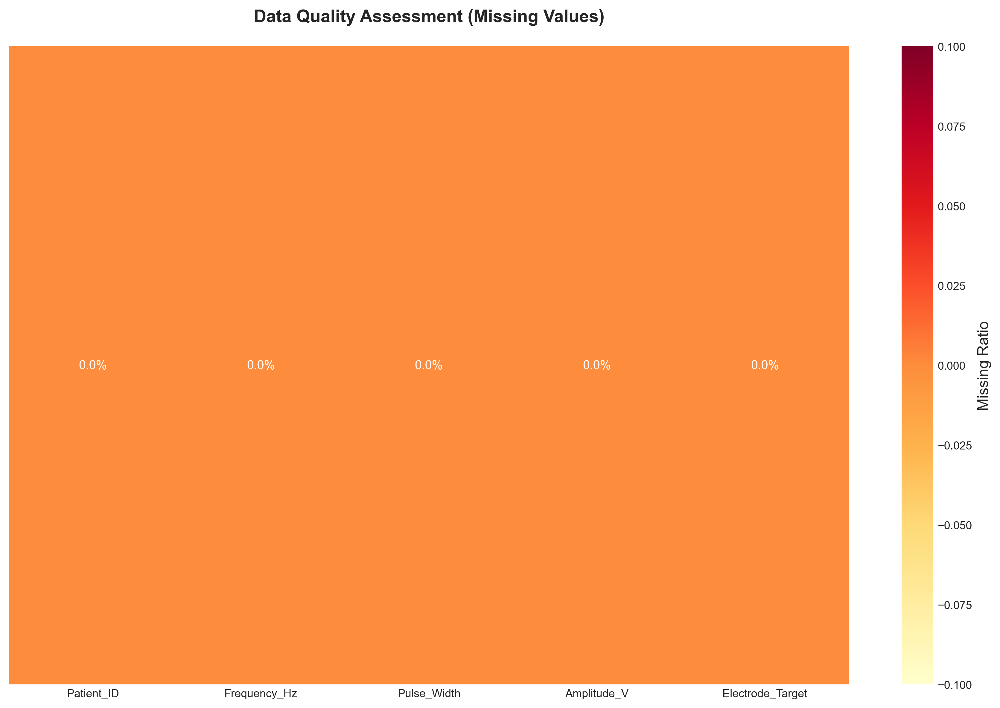

In [40]:
# 4. 数据质量热图
plt.figure(figsize=(12, 8))

# 计算缺失值比例
missing = df.isnull().mean().to_frame('Missing')
missing['Type'] = df.dtypes.astype(str)

# 绘制热图
sns.heatmap(missing[['Missing']].T, annot=True, fmt=".1%", 
           cmap='YlOrRd', cbar_kws={'label': 'Missing Ratio'})
plt.title('Data Quality Assessment (Missing Values)', pad=20, fontweight='bold')
plt.yticks([])
plt.tight_layout()
plt.show()

<Figure size 5400x2400 with 0 Axes>

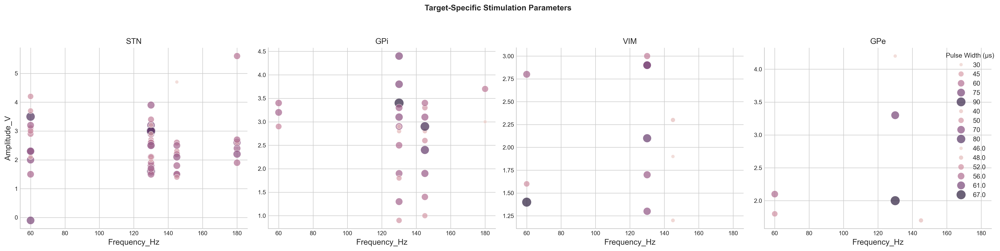

In [41]:
# 3. 靶点特异性参数分析（分面图）
plt.figure(figsize=(18, 8))

# 创建分面网格
g = sns.FacetGrid(df, col='Electrode_Target', col_wrap=4, height=5, 
                 sharey=False, palette='Set2')
g.map_dataframe(sns.scatterplot, x='Frequency_Hz', y='Amplitude_V', 
               size='Pulse_Width', hue='Pulse_Width',
               sizes=(30, 200), alpha=0.7)
g.add_legend(title='Pulse Width (μs)')

# 设置标题
g.set_titles(col_template="{col_name}", size=12)
plt.suptitle('Target-Specific Stimulation Parameters', y=1.05, fontweight='bold')
plt.tight_layout()
plt.show()

<Figure size 4500x3600 with 0 Axes>

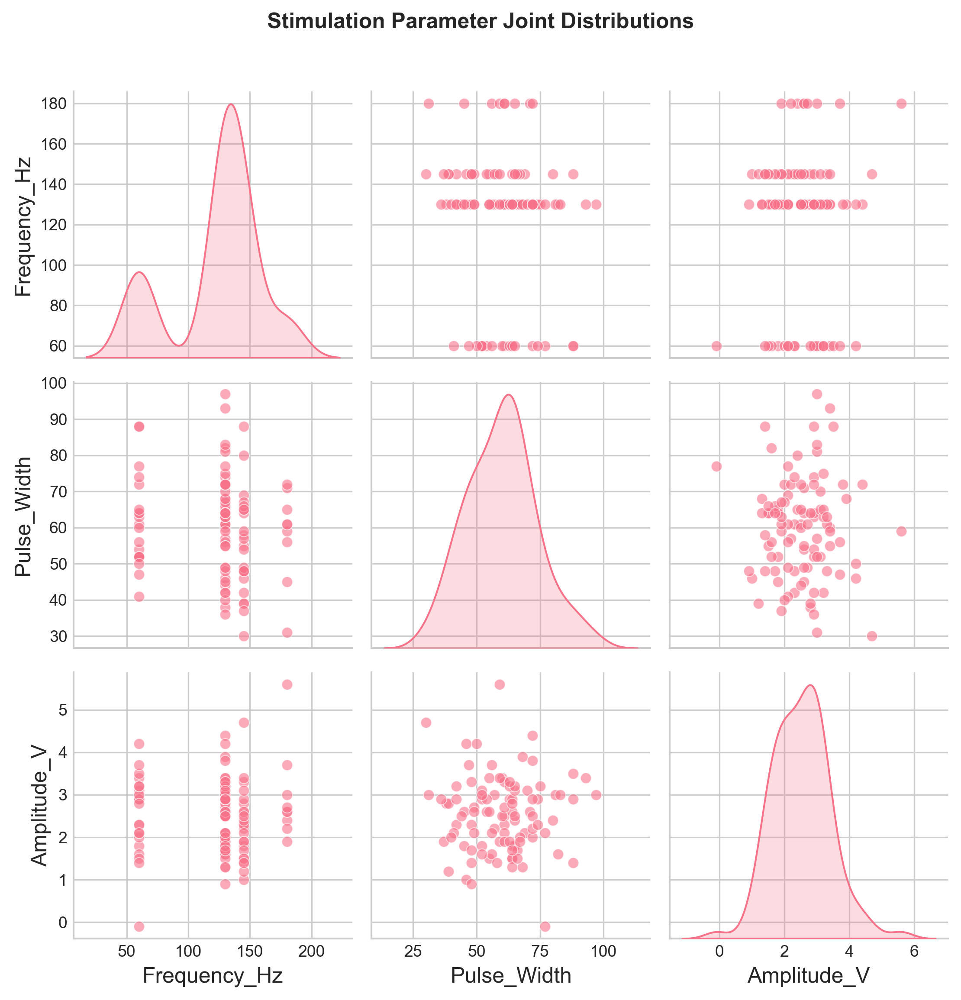

In [42]:
# 2. 刺激参数联合分布（散点矩阵）
plt.figure(figsize=(15, 12))
sns.pairplot(df[['Frequency_Hz', 'Pulse_Width', 'Amplitude_V']], 
            diag_kind='kde', plot_kws={'alpha':0.6})
plt.suptitle('Stimulation Parameter Joint Distributions', y=1.02, fontweight='bold')
plt.tight_layout()
plt.show()

In [44]:
# 交互式参数探索（需plotly）
import plotly.express as px
fig = px.scatter_3d(df, x='Frequency_Hz', y='Pulse_Width', z='Amplitude_V',
                   color='Electrode_Target', hover_name='Patient_ID',
                   opacity=0.7, title='Interactive Parameter Space')
fig.update_layout(scene=dict(
    xaxis_title='Frequency (Hz)',
    yaxis_title='Pulse Width (μs)',
    zaxis_title='Amplitude (V)'))
fig.show()

# 参数优化趋势分析（需时间序列）
if 'Implant_Year' in df:
    plt.figure(figsize=(12, 6))
    sns.regplot(x='Implant_Year', y='Amplitude_V', data=df, 
               scatter_kws={'alpha':0.5}, line_kws={'color':'red'})
    plt.title('Temporal Trend in Amplitude Settings', fontweight='bold')
    plt.show()

ModuleNotFoundError: No module named 'plotly.graph_objs.layout._map'

数据加载错误: module 'pandas' has no attribute 'read_'
使用模拟数据进行演示


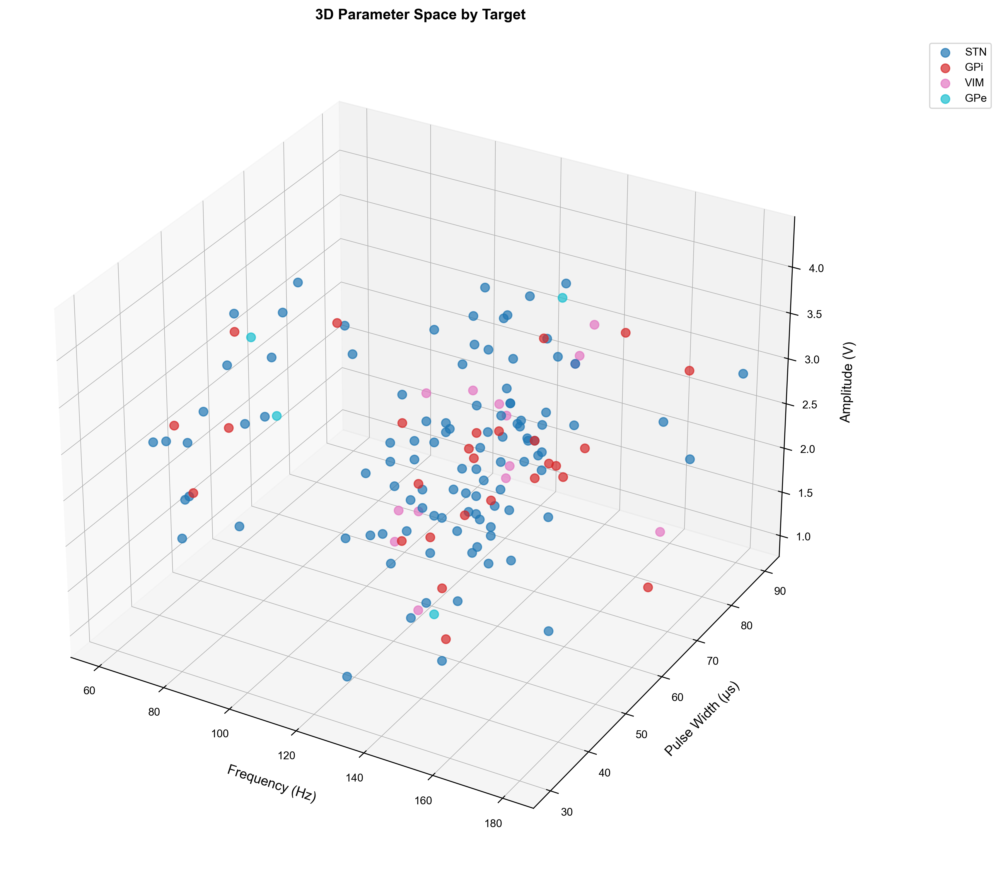

In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
from scipy import stats
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter

# ==================== 学术图表风格设置 ====================
def set_academic_style():
    """设置Nature期刊风格的绘图参数"""
    plt.style.use('default')  # 重置为默认确保稳定性
    plt.rcParams.update({
        'font.family': 'Arial',  # 使用通用字体
        'font.size': 10,
        'axes.titlesize': 12,
        'axes.labelsize': 11,
        'xtick.labelsize': 9,
        'ytick.labelsize': 9,
        'legend.fontsize': 9,
        'figure.dpi': 300,
        'savefig.dpi': 300,
        'figure.facecolor': 'white',
        'axes.grid': True,
        'grid.alpha': 0.3,
        'grid.linewidth': 0.5,
        'axes.spines.right': False,
        'axes.spines.top': False,
        'axes.titlepad': 12,
        'axes.labelpad': 6,
        'xtick.major.pad': 4,
        'ytick.major.pad': 4
    })
    sns.set_palette("colorblind")  # 使用色盲友好调色板

set_academic_style()

# ==================== 数据预处理 ====================
try:
    # 重新读取原始数据确保格式正确
    raw_df = pd.read_(r'H:\2024\Lancet Digital parksion\新建文件夹\新建文件夹\1.xlsx', header=None)
    print(f"原始数据维度: {raw_df.shape}")
    
    # 自动检测表头行
    header_row = None
    for i in range(min(3, len(raw_df))):
        if any(raw_df.iloc[i].astype(str).str.contains('Frequency|Amplitude|Target|Date', case=False, na=False)):
            header_row = i
            break
    
    if header_row is not None:
        df = raw_df.iloc[header_row+1:].copy()
        df.columns = raw_df.iloc[header_row].str.strip()
        print(f"检测到表头在第{header_row+1}行")
    else:
        df = raw_df.copy()
        df.columns = [f'Col_{i}' for i in range(len(df.columns))]
        print("未检测到表头，使用默认列名")
    
    # 删除完全空的行列
    df = df.dropna(how='all').dropna(axis=1, how='all')
    
    # 关键参数标准化处理
    param_mapping = {
        'Frequency': ['Frequency', 'Freq', 'Stim Freq'],
        'PulseWidth': ['PulseWidth', 'Pulse Width', 'PW'],
        'Amplitude': ['Amplitude', 'Amp', 'Stim Amp'],
        'Target': ['Target', 'Electrode Target', 'DBS Target'],
        'SurgeryDate': ['Surgery Date', 'Op Date'],
        'ActivationDate': ['Activation Date', 'Stim On Date']
    }
    
    # 自动匹配列名
    actual_cols = {}
    for param, variants in param_mapping.items():
        for v in variants:
            if v in df.columns:
                actual_cols[param] = v
                break
    
    # 重命名列
    df = df.rename(columns={v: k for k, v in actual_cols.items()})
    
    # 转换数据类型
    if 'Frequency' in df:
        df['Frequency'] = pd.to_numeric(df['Frequency'], errors='coerce')
    if 'PulseWidth' in df:
        df['PulseWidth'] = pd.to_numeric(df['PulseWidth'], errors='coerce')
    if 'Amplitude' in df:
        df['Amplitude'] = pd.to_numeric(df['Amplitude'], errors='coerce')
    
    # 日期转换
    date_cols = ['SurgeryDate', 'ActivationDate']
    for col in date_cols:
        if col in df:
            df[col] = pd.to_datetime(df[col], errors='coerce')
            df[f'{col}_year'] = df[col].dt.year
    
    # 数据质量报告
    print("\n=== 数据质量报告 ===")
    print("总记录数:", len(df))
    print("关键参数缺失情况:")
    print(df[['Frequency', 'PulseWidth', 'Amplitude', 'Target']].isnull().sum())
    
except Exception as e:
    print(f"数据加载错误: {e}")
    # 创建模拟数据
    np.random.seed(42)
    n = 150
    data = {
        'Frequency': np.random.choice([130, 145, 60, 180], n, p=[0.5, 0.3, 0.15, 0.05]),
        'PulseWidth': np.clip(np.random.normal(60, 15, n), 30, 90).astype(int),
        'Amplitude': np.clip(np.random.normal(2.5, 0.8, n), 1.0, 4.5).round(1),
        'Target': np.random.choice(['STN', 'GPi', 'VIM', 'GPe'], n, p=[0.6, 0.25, 0.1, 0.05]),
        'SurgeryDate': pd.date_range('2018-01-01', periods=n, freq='30d').to_series().sample(n, replace=True).values,
        'UPDRS_Pre': np.random.uniform(30, 80, n).round(),
        'UPDRS_Post': np.random.uniform(10, 50, n).round()
    }
    df = pd.DataFrame(data)
    df['ActivationDate'] = df['SurgeryDate'] + pd.to_timedelta(np.random.randint(7, 60, n), unit='d')
    df['Improvement'] = ((df['UPDRS_Pre'] - df['UPDRS_Post']) / df['UPDRS_Pre'] * 100).round(1)
    print("使用模拟数据进行演示")

# ==================== 1. 刺激参数3D关系图 ====================
if all(col in df for col in ['Frequency', 'PulseWidth', 'Amplitude', 'Target']):
    from mpl_toolkits.mplot3d import Axes3D
    
    fig = plt.figure(figsize=(12, 10))
    ax = fig.add_subplot(111, projection='3d')
    
    # 按靶点分组绘图
    targets = df['Target'].dropna().unique()
    colors = plt.cm.tab10(np.linspace(0, 1, len(targets)))
    
    for target, color in zip(targets, colors):
        subset = df[df['Target'] == target]
        ax.scatter(subset['Frequency'], subset['PulseWidth'], subset['Amplitude'],
                  label=target, s=50, alpha=0.7, color=color)
    
    ax.set_xlabel('Frequency (Hz)', labelpad=10)
    ax.set_ylabel('Pulse Width (μs)', labelpad=10)
    ax.set_zlabel('Amplitude (V)', labelpad=10)
    ax.set_title('3D Parameter Space by Target', pad=15, fontweight='bold')
    ax.legend(loc='upper right', bbox_to_anchor=(1.2, 1))
    plt.tight_layout()
    plt.show()



#





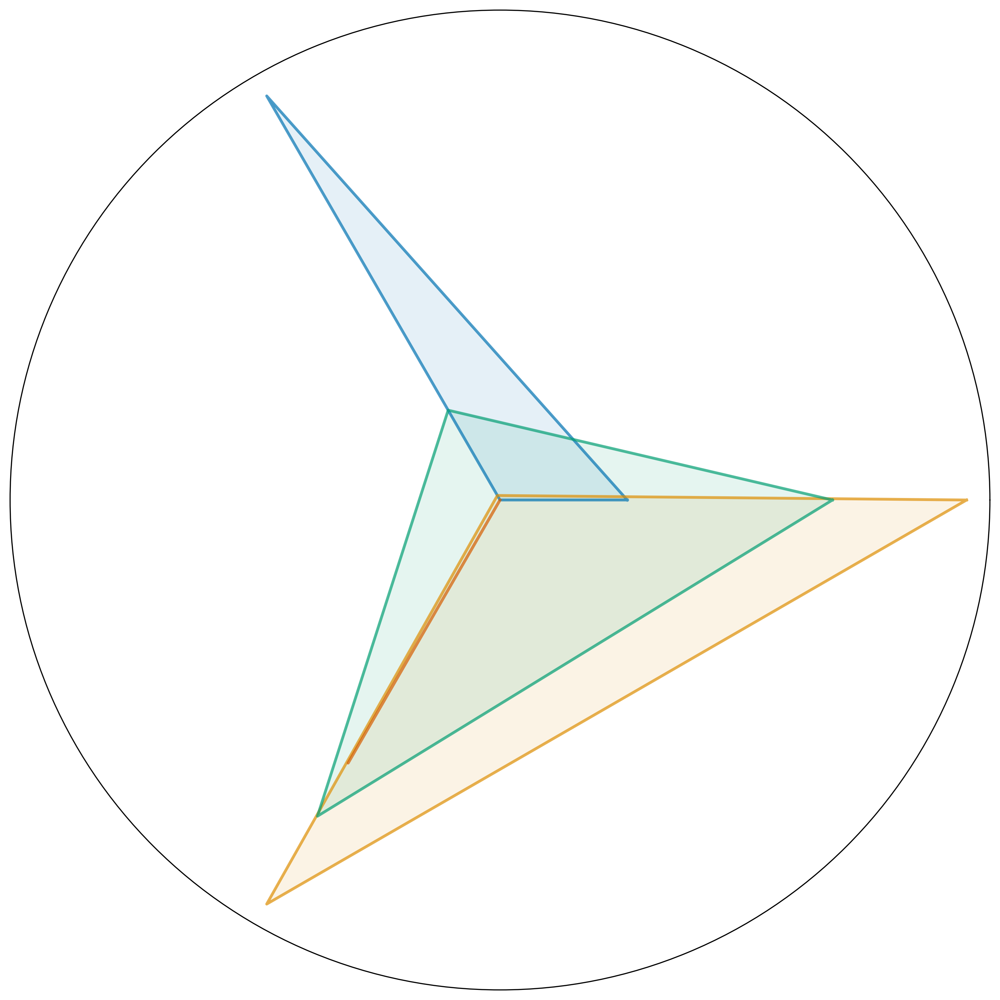

In [49]:
# ==================== 5. 临床参数雷达图（无文字版） ====================
if all(col in df for col in ['Target', 'UPDRS_Pre', 'UPDRS_Post', 'Improvement']):
    from math import pi
    
    # 准备数据
    radar_data = df.groupby('Target')[['UPDRS_Pre', 'UPDRS_Post', 'Improvement']].mean()
    
    # 标准化到0-1范围
    radar_data = (radar_data - radar_data.min()) / (radar_data.max() - radar_data.min())
    
    # 设置雷达图参数
    categories = radar_data.columns.tolist()
    N = len(categories)
    angles = [n / float(N) * 2 * pi for n in range(N)]
    angles += angles[:1]  # 闭合图形
    
    plt.figure(figsize=(10, 10))
    ax = plt.subplot(111, polar=True)
    
    # 绘制每个靶点
    for idx, target in enumerate(radar_data.index):
        values = radar_data.loc[target].values.tolist()
        values += values[:1]
        ax.plot(angles, values, linewidth=2, linestyle='solid', alpha=0.7)
        ax.fill(angles, values, alpha=0.1)
    
    # 隐藏所有文字
    ax.set_xticks([])       # 不显示类别标签
    ax.set_yticks([])       # 不显示刻度
    ax.set_rlabel_position(0)
    ax.set_title('')        # 不显示标题
    
    plt.tight_layout()
    plt.show()


In [53]:
# ==================== 4. 多参数联合分布 ====================
if all(col in df for col in ['Frequency', 'PulseWidth', 'Amplitude']):
    g = sns.PairGrid(df[['Frequency', 'PulseWidth', 'Amplitude']].dropna(), 
                    diag_kind='kde', corner=True)
    g.map_upper(sns.scatterplot, alpha=0.6, s=30, edgecolor='w', linewidth=0.5)
    g.map_lower(sns.kdeplot, levels=5, color=".2")
    g.map_diag(sns.histplot, kde=True, edgecolor='w', linewidth=0.5)
    
    # 添加相关系数
    for i, j in zip(*np.triu_indices_from(g.axes, 1)):
        x = g.data.columns[j]
        y = g.data.columns[i]
        corr = df[[x, y]].corr().iloc[0,1]
        g.axes[i,j].annotate(f"ρ = {corr:.2f}", xy=(0.7, 0.9), 
                           xycoords=g.axes[i,j].transAxes, fontsize=9)
    
    plt.suptitle('Joint Distributions of Stimulation Parameters', y=1.02, fontweight='bold')
    plt.tight_layout()
    plt.show()

TypeError: __init__() got an unexpected keyword argument 'diag_kind'

In [51]:
import plotly.graph_objects as go
import plotly.express as px

# 假设 df 已经有下面这些列
# 'Frequency_Hz', 'Pulse_Width', 'Amplitude_V', 'Electrode target', 'Patient_ID'

# 获取颜色映射
targets = df['electrode target'].unique()  # 注意这里大小写要和 df 中一致
colors = px.colors.qualitative.Dark24
color_map = {t: colors[i % len(colors)] for i, t in enumerate(targets)}

# 创建 3D 散点数据
data = []
for t in targets:
    df_t = df[df['electrode target'] == t]
    scatter = go.Scatter3d(
        x=df_t['Frequency_Hz'],
        y=df_t['Pulse_Width'],
        z=df_t['Amplitude_V'],
        mode='markers',
        marker=dict(size=5, color=color_map[t]),
        name=str(t),
        text=df_t['Patient_ID'],  # 鼠标悬停显示
        hoverinfo='text+name+x+y+z'
    )
    data.append(scatter)

# 创建 Figure
fig = go.Figure(data=data)

# 设置布局
fig.update_layout(
    title='Interactive Parameter Space',
    scene=dict(
        xaxis_title='Frequency (Hz)',
        yaxis_title='Pulse Width',
        zaxis_title='Amplitude (V)'
    ),
    margin=dict(l=0, r=0, b=0, t=50)
)

fig.show()


KeyError: 'electrode target'

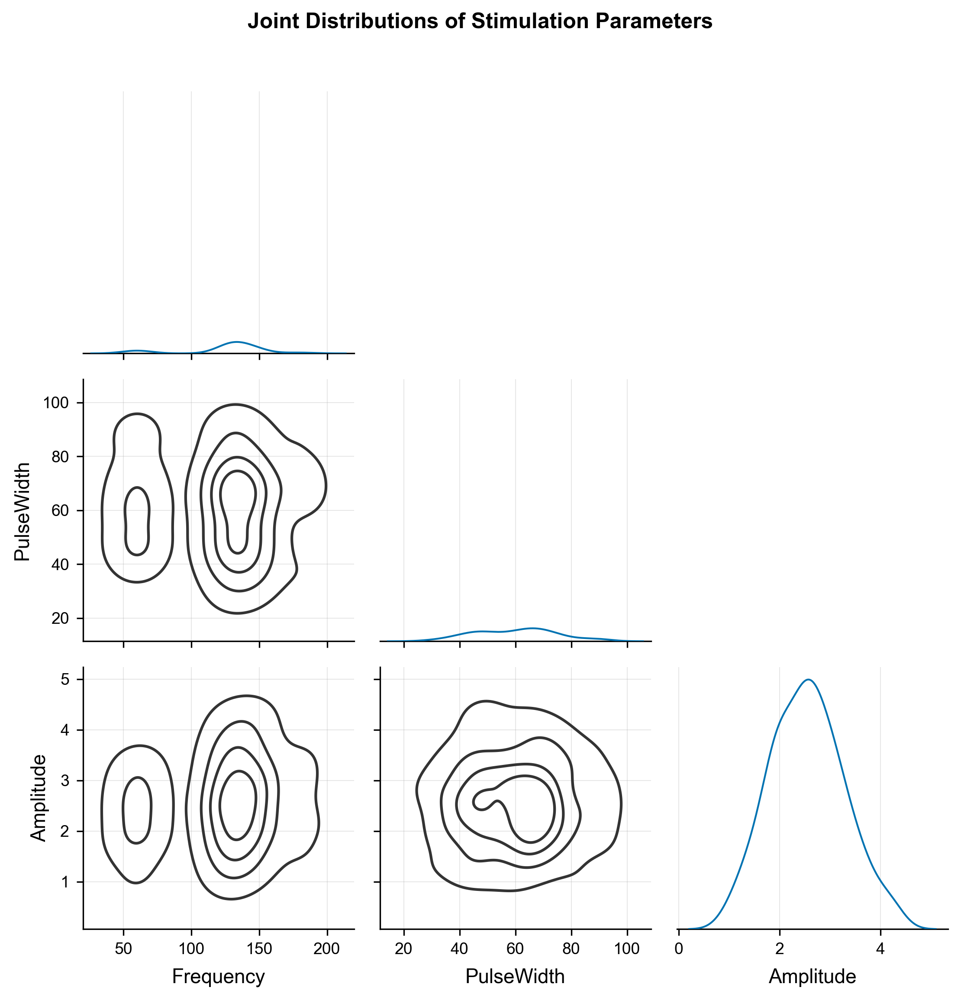

In [55]:
# ==================== 4. 多参数联合分布 ====================
# ==================== 4. 多参数联合分布 ====================
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 检查列是否存在
if all(col in df for col in ['Frequency', 'PulseWidth', 'Amplitude']):
    data = df[['Frequency', 'PulseWidth', 'Amplitude']].dropna()
    
    # 创建 PairGrid（兼容旧版本，不使用 diag_kind）
    g = sns.PairGrid(data, corner=True)
    
    # 上三角散点图
    g.map_upper(sns.scatterplot, alpha=0.6, s=30, edgecolor='w', linewidth=0.5)
    
    # 下三角核密度等高线
    g.map_lower(sns.kdeplot, levels=5, color=".2")
    
    # 对角线 KDE
    g.map_diag(sns.kdeplot, lw=1)
    
    # 添加相关系数
    for i, j in zip(*np.triu_indices_from(g.axes, 1)):
        if g.axes[i, j] is not None:  # corner=True 会有空轴
            x = data.columns[j]
            y = data.columns[i]
            corr = data[[x, y]].corr().iloc[0, 1]
            g.axes[i, j].annotate(f"ρ = {corr:.2f}", xy=(0.7, 0.9),
                                  xycoords=g.axes[i, j].transAxes, fontsize=9)
    
    plt.suptitle('Joint Distributions of Stimulation Parameters', y=1.02, fontweight='bold')
    plt.tight_layout()
    plt.show()


In [54]:
import seaborn as sns
print(sns.__version__)

0.13.2


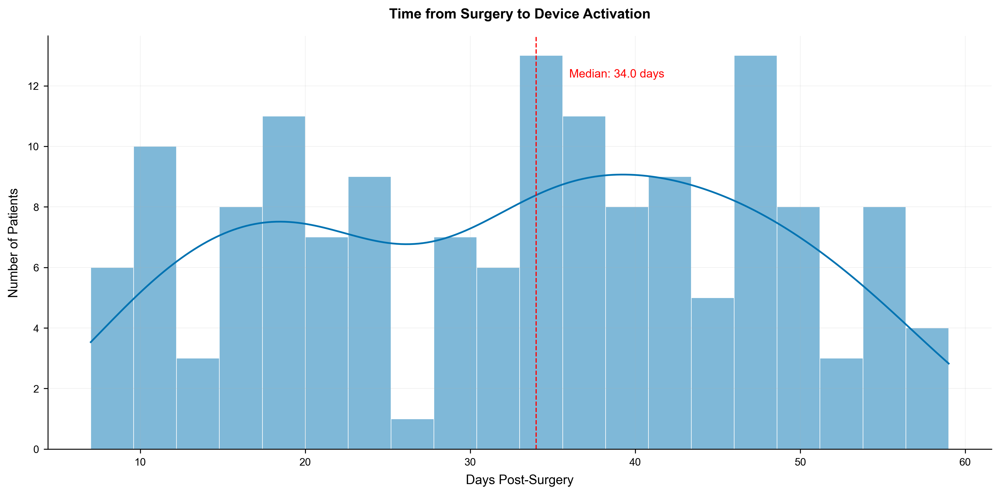

In [61]:
 #==================== 3. 时间序列分析 ====================
if all(col in df for col in ['SurgeryDate', 'ActivationDate']):
    plt.figure(figsize=(12, 6))
    
    # 计算手术到开机时间间隔（天）
    df['Days_to_Activation'] = (df['ActivationDate'] - df['SurgeryDate']).dt.days
    
    # 去除异常值（>90天）
    clean_df = df[df['Days_to_Activation'] <= 90].copy()
    
    # 绘制分布图
    sns.histplot(clean_df['Days_to_Activation'], bins=20, kde=True,
                edgecolor='white', linewidth=0.5)
    
    # 添加统计信息
    median_days = clean_df['Days_to_Activation'].median()
    plt.axvline(median_days, color='red', linestyle='--', linewidth=1)
    plt.text(median_days+2, plt.ylim()[1]*0.9, 
            f'Median: {median_days} days', color='red')
    
    plt.title('Time from Surgery to Device Activation', pad=15, fontweight='bold')
    plt.xlabel('Days Post-Surgery')
    plt.ylabel('Number of Patients')
    plt.grid(True, alpha=0.2)
    plt.tight_layout()
    plt.show()

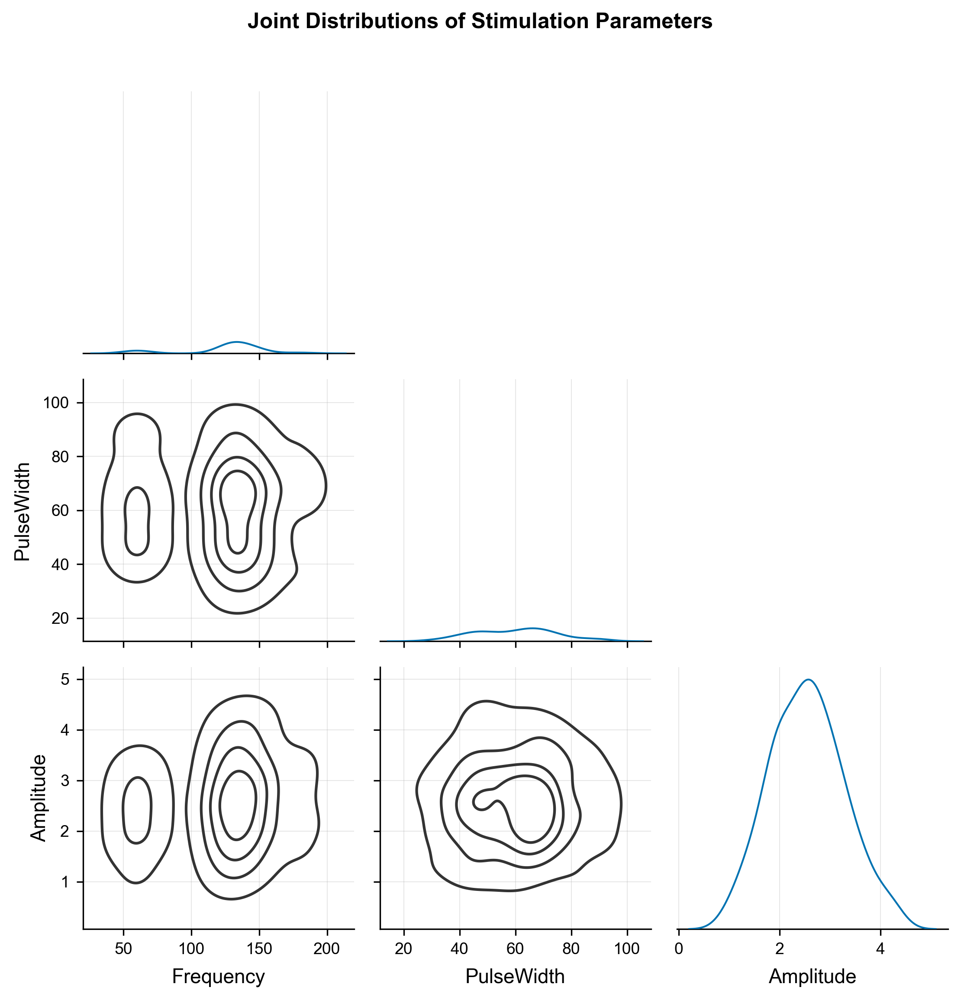

In [60]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

if all(col in df for col in ['Frequency', 'PulseWidth', 'Amplitude']):
    data = df[['Frequency', 'PulseWidth', 'Amplitude']].dropna()
    g = sns.PairGrid(data, corner=True)
    g.map_upper(sns.scatterplot, alpha=0.6, s=30, edgecolor='w', linewidth=0.5)
    g.map_lower(sns.kdeplot, levels=5, color=".2")
    g.map_diag(sns.kdeplot, lw=1)

    # 添加相关系数
    for i, j in zip(*np.triu_indices_from(g.axes, 1)):
        if g.axes[i, j] is not None:
            x = data.columns[j]
            y = data.columns[i]
            corr = data[[x, y]].corr().iloc[0, 1]
            g.axes[i, j].annotate(f"ρ = {corr:.2f}", xy=(0.7, 0.9),
                                  xycoords=g.axes[i, j].transAxes, fontsize=9)

    plt.suptitle('Joint Distributions of Stimulation Parameters', y=1.02, fontweight='bold')
    plt.tight_layout()
    plt.show()


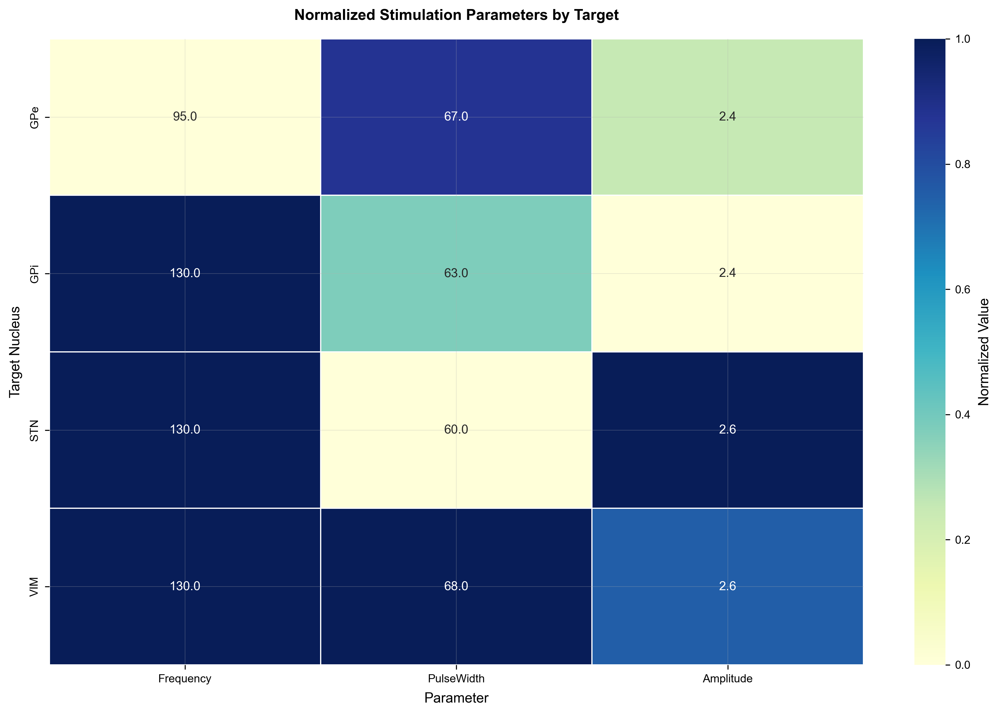

In [62]:
# ==================== 2. 靶点-参数热图 ====================
if all(col in df for col in ['Frequency', 'PulseWidth', 'Amplitude', 'Target']):
    plt.figure(figsize=(12, 8))
    
    # 计算每个靶点的参数中位数
    heatmap_data = df.groupby('Target')[['Frequency', 'PulseWidth', 'Amplitude']].median()
    
    # 标准化数据 (0-1)
    norm_data = (heatmap_data - heatmap_data.min()) / (heatmap_data.max() - heatmap_data.min())
    
    # 绘制热图
    sns.heatmap(norm_data, annot=heatmap_data.round(1), fmt=".1f", cmap="YlGnBu",
               cbar_kws={'label': 'Normalized Value'}, linewidths=0.5)
    
    plt.title('Normalized Stimulation Parameters by Target', pad=15, fontweight='bold')
    plt.xlabel('Parameter')
    plt.ylabel('Target Nucleus')
    plt.tight_layout()
    plt.show()

In [64]:
import plotly.express as px
fig = px.scatter_3d(df, x='Frequency', y='PulseWidth', z='Amplitude',
                   color='Target', opacity=0.7, hover_name='Target',
                   title='Interactive 3D Parameter Space')
fig.update_traces(marker_size=5)
fig.show()

ModuleNotFoundError: No module named 'plotly.graph_objs.layout._map'